# 02 — Временной EDA

## Вопрос ноутбука

Когда пользователь слушает музыку? Что в этом ритме устойчиво,
а что меняется со временем.

Четыре уровня. Долгосрочный тренд: как менялись аудио-характеристики
за шесть лет. Календарные аномалии: где тренд ломался, какие годы
и месяцы выбивались. Временные ритмы: в какие часы и дни недели
слушается музыка, как этот ритм сдвигался по годам. Регулярность:
в какие дни музыка была, в какие нет, как распределены перерывы.

Отдельно — три среза на уровне отдельных единиц. Платформы:
с каких устройств шло прослушивание. Треки-лидеры: какие треки
возглавляли каждый год и как долго жили. Жанровая динамика:
менялось ли жанровое ядро между началом, серединой и концом периода.

## Срезы

**df** — весь поток событий. Аналог базы **all**. Нужен там, где
важно поведение как есть: количество событий по годам и фильтрам,
платформы, дневная агрегация для регулярности.

**df_deep** — **valid_play** события, суженные до глубокой
вовлечённости: трек накопил ≥5 **valid** прослушиваний или
**played_frac** ≥0.7. Нужен там, где важна именно глубокая
вовлечённость: аудио-тренды, календарные аномалии, суточные ритмы,
треки-лидеры, жанровая динамика.

**daily** — дневная агрегация по **deep**-событиям: средние
аудио-характеристики и число событий на каждый день. Основа
для трендов и аномалий.

**daily_all** — дневная агрегация по всему потоку: только число
событий на день. Используется для регулярности, где важен сам факт
«была ли музыка в этот день», а не характеристики событий.

## Связь с другими частями проекта

Первый ноутбук (`01_eda_basic`) показал, **что** слушается. Этот
показывает, **когда**, и проверяет, устойчив ли временной ритм
так же, как звуковой.

Дашборд (`03_dashboard/`) использует канонические базы из
`src/bases.py`. Здесь работа идёт на своих срезах — **df** и
**df_deep** — потому что ноутбук писался раньше дашборда. Функции
из `bases.py` не подключаются.

В блоке 6.1 используется простая edge correction: отсекается один
краевой интервал. В `src/temporal.py` реализована `trim_cold_start()` —
другой алгоритм для другой задачи: отрезать весь разреженный старт
целиком, чтобы получить непрерывный ряд для детекторов в дашборде.
Оба подхода корректны: 6.1 показывает историю как есть,
`trim_cold_start` готовит данные для анализа.

## Ограничения ноутбука

Выборка — история одного человека. Выводы описывают этот профиль,
не слушателей вообще.

2020 (данные с мая) и 2026 (данные до августа) неполные. Они
остаются в анализе, но все выводы по годам идут с оговоркой.
Полные годы — 2021–2025.

Все сравнения по годам — self-relative: считаются относительно
собственной истории пользователя, не против внешнего эталона.
Значения не сопоставимы между пользователями.

Корреляции в блоке 2.2 считаются на 30-дневных сглаженных рядах.
Сглаживание завышает Пирсона (эффект Юла–Слуцкого). Значения
отражают согласованность долгосрочных движений, не силу связи
на дневном уровне.

Жанровый анализ ограничен долей **unknown** — 42–57% в разных
срезах. В блоке 9 доля падает с 75% в начале периода до 32%
в конце: это улучшение метаданных Spotify, а не изменение вкуса.

Пороги, используемые в ноутбуке, — эвристики, не выведенные
из данных: **deep** (≥5 прослушиваний или **played_frac** ≥0.7),
IQR (1.5), z-score (2), `mean − 1.5σ` в 5.6 и 6.6,
`CONCENTRATION_THRESHOLD` (35%) в 3.3, порог пиков
`mean + 1.5σ` в 4.2. Все фиксированы для воспроизводимости.

Правый край истории обрезан: 2026 неполный. Сезонность по часам
и месяцам отдельно не проверялась.

Все сравнения проходят без поправки на множественные сравнения.

# Блок 0. Подготовка данных


In [164]:
# 0. Подготовка данных

# Импорты собраны здесь один раз — дальше по блокам не повторяются.
import sys
from pathlib import Path
from math import ceil

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from calendar import month_name

sns.set_style('whitegrid')
%matplotlib inline
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', None)

# --- Делаем src.* импортируемым из любого рабочего каталога ---
_root = Path.cwd()
while not (_root / 'src').is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

from src.paths import get_base_path

# --- Загрузка eda_ready.parquet ---
BASE_PATH = get_base_path()
DATA_PATH = BASE_PATH / 'eda_ready.parquet'

# Причины завершения, которые считаем техническими.
# Они исключаются из valid_play, потому что не отражают осознанное прослушивание.
EXCLUDE_REASONS = ['trackerror', 'fwdbtn', 'backbtn', 'logout', 'remote', 'unexpected-exit']

df = pd.read_parquet(DATA_PATH)
df['ts'] = pd.to_datetime(df['ts'], errors='coerce').dt.tz_localize(None)


# --- Общие константы для всего ноутбука ---
# Список аудио-характеристик используется в блоках 2, 3, 4, 4a.
# Пары (колонка, название для графика) — чтобы не хардкодить названия по блокам.
FEATURES = [
    ('valence_mean', 'Valence'),
    ('energy_mean', 'Energy'),
    ('danceability_mean', 'Danceability'),
    ('acousticness_mean', 'Acousticness'),
    ('instrumentalness_mean', 'Instrumentalness'),
    ('liveness_mean', 'Liveness'),
    ('speechiness_mean', 'Speechiness'),
    ('tempo_mean', 'Tempo'),
    ('loudness_mean', 'Loudness'),
    ('popularity_mean', 'Popularity'),
]

# Список «сырых» признаков (без _mean) — для блоков, которые работают с df_deep.
FEATURES_RAW = [
    'valence', 'energy', 'danceability', 'acousticness',
    'instrumentalness', 'liveness', 'speechiness',
    'tempo', 'loudness', 'popularity',
]

# Пороги существенности для оценки трендов (блок 2.1).
# (сильное, умеренное) — по каждой характеристике своя шкала.
THRESHOLDS = {
    'Valence': (0.05, 0.02),
    'Energy': (0.05, 0.02),
    'Danceability': (0.05, 0.02),
    'Acousticness': (0.05, 0.02),
    'Instrumentalness': (0.05, 0.02),
    'Liveness': (0.05, 0.02),
    'Speechiness': (0.05, 0.02),
    'Tempo': (5, 2),
    'Loudness': (3, 1),
    'Popularity': (10, 5),
}
COLORS = {
    'primary':        '#66b3ff',
    'secondary':      '#99e6e6',
    'accent':         '#ff9999',
    'success':        '#99ff99',
    'muted':          '#d3d3d3',
    'line_primary':   '#4C9FE8',
    'line_secondary': '#26A6A6',
    'line_success':   '#4CAF50',
    'line_accent':    '#E86B6B',
}

# Размер шкалы каждой характеристики. Используется для нормировки
# дисперсии и для проверки расхождения mean/median.
FEATURE_RANGES = {
    'valence': 1, 'energy': 1, 'danceability': 1,
    'acousticness': 1, 'instrumentalness': 1, 'liveness': 1, 'speechiness': 1,
    'tempo': 290,           # 10–300 BPM
    'loudness': 60,         # -60–0 дБ
    'popularity': 100,      # 0–100
}

# === Определение полных годов наблюдения ===
def get_full_years(min_date, max_date):
    """
    Возвращает список календарно полных лет для анализа.

    Исключаются только крайние годы:
    - первый год исключается, если данные начались позже 31 марта;
    - последний год исключается, если данные закончились раньше 1 октября.
    Промежуточные годы считаются полными всегда.

    Смысл: первый и последний год могут быть «обрезаны» (экспорт начался
    в середине года или завершился до конца года). Такие годы нельзя
    сравнивать с полными — но полностью выбрасывать их тоже не нужно,
    поэтому они помечаются как incomplete_years и остаются в данных.
    """
    years = list(range(min_date.year, max_date.year + 1))
    if len(years) <= 1:
        return years

    first_quarter_end = pd.Timestamp(year=years[0], month=3, day=31)
    if min_date > first_quarter_end:
        years.pop(0)

    fourth_quarter_start = pd.Timestamp(year=years[-1], month=10, day=1)
    if max_date < fourth_quarter_start:
        years.pop(-1)

    return years


min_date = df['ts'].min()
max_date = df['ts'].max()
full_years = get_full_years(min_date, max_date)

print(f'📅 Full observation years: {full_years}')

all_years = sorted([int(y) for y in df['ts'].dt.year.unique()])
incomplete_years = [y for y in all_years if y not in full_years]

if incomplete_years:
    print(f'⚠️ Incomplete years: {incomplete_years}')
    print('   Included in analysis but interpret with caution.')
else:
    print('✅ All years are full.')


# --- Валидное прослушивание (valid_play) ---
# Условия: не скип, не короче 30 секунд, не техническая причина завершения,
# прослушано не менее 50% длительности трека.
df['valid_play'] = (
    (~df['is_skip']) &
    (df['ms_played'] >= 30_000) &
    (~df['reason_end'].isin(EXCLUDE_REASONS)) &
    (df['played_frac'] >= 0.5)
)

# --- Количество валидных прослушиваний для каждого трека ---
valid_counts = df[df['valid_play']].groupby('spotify_track_uri').size().reset_index(name='valid_listen_count')
df = df.merge(valid_counts, on='spotify_track_uri', how='left')
df['valid_listen_count'] = df['valid_listen_count'].fillna(0).astype(int)

# --- Deep dive: валидные события треков с ядром ≥5 или долей прослушивания ≥0.7 ---
mask_deep = (
    df['valid_play'] &
    ((df['valid_listen_count'] >= 5) | (df['played_frac'] >= 0.7))
)

# Проверка промежуточных сумм (STYLE_GUIDE п.15).
# mask_deep = valid_play AND (valid_listen_count >= 5 OR played_frac >= 0.7).
# Из-за OR итог может быть больше каждого из A, B в отдельности,
# но не может быть больше valid_play — это его подмножество.
print('\nDeep dive mask check:')
print(f'   valid_play = {df["valid_play"].sum()}')
print(f'   valid_listen_count >= 5 = {(df["valid_listen_count"] >= 5).sum()}')
print(f'   played_frac >= 0.7 = {(df["played_frac"] >= 0.7).sum()}')
print(f'   mask_deep = {mask_deep.sum()}')

assert mask_deep.sum() <= df['valid_play'].sum(), 'mask_deep exceeds valid_play'
print(f'   ✅ mask_deep ≤ valid_play = {df["valid_play"].sum()}')


# --- DataFrame «глубокого погружения» ---
df_deep = df[mask_deep].copy()
df_deep['date'] = df_deep['ts'].dt.date
df_deep['year'] = df_deep['ts'].dt.year.astype(int)
df_deep['month'] = df_deep['ts'].dt.month.astype(int)
df_deep['hour'] = df_deep['ts'].dt.hour.astype(int)

# --- Дневная агрегация по deep-событиям ---
# Каждый день — одна строка. Средние по аудио-характеристикам + число событий + мода часа.
daily = df_deep.groupby('date').agg(
    valence_mean=('valence', 'mean'),
    energy_mean=('energy', 'mean'),
    danceability_mean=('danceability', 'mean'),
    acousticness_mean=('acousticness', 'mean'),
    instrumentalness_mean=('instrumentalness', 'mean'),
    liveness_mean=('liveness', 'mean'),
    speechiness_mean=('speechiness', 'mean'),
    tempo_mean=('tempo', 'mean'),
    loudness_mean=('loudness', 'mean'),
    popularity_mean=('popularity', 'mean'),
    event_count=('valence', 'count'),
    hour=('hour', lambda x: x.mode().iloc[0] if not x.mode().empty else 0)
).reset_index()
daily['date'] = pd.to_datetime(daily['date'])
daily['year'] = daily['date'].dt.year.astype(int)
daily['month'] = daily['date'].dt.month.astype(int)


# --- Первое валидное прослушивание для всех треков ---
first_seen_valid = df.loc[df['valid_play']].groupby('spotify_track_uri')['ts'].min()
df['first_valid_seen'] = df['spotify_track_uri'].map(first_seen_valid)
df['first_listen_period'] = df['first_valid_seen'].dt.to_period('Q')


# --- Дневная агрегация по всем событиям ---
# Используется для регулярности и анализа тишины (блок 6).
daily_all = df.groupby(df['ts'].dt.date).size().reset_index(name='event_count')
daily_all.columns = ['date', 'event_count']
daily_all['date'] = pd.to_datetime(daily_all['date'])


# --- Проверка колонок и типов ---
if 'genres_normalized' not in df_deep.columns:
    print('⚠️ genres_normalized missing.')
else:
    print('✅ genres_normalized column found.')

# platform нужна для блока 7. Проверяем наличие и число непустых значений,
# без вывода примеров — они содержат модель устройства, это лишнее.
if 'platform' not in df.columns:
    print('⚠️ platform missing.')
else:
    print(f'✅ platform column found. Non-null: {df["platform"].notna().sum()}')

print('\n✅ Data preparation complete.')
print(f'   Deep dive events: {len(df_deep)}')
print(f'   Days with music: {len(daily)}')
print(f'   Hours range: {daily["hour"].min()} – {daily["hour"].max()}')


def show_unknown_share(data: pd.DataFrame, group_name: str) -> float:
    """
    Доля событий с неизвестным жанром.

    Учитываем только 'unknown' — кириллица без перевода уже
    преобразована в 'unknown' на этапе 00_1.
    Если доля >30% — предупреждение, если >50% — жанровые выводы делать нельзя.
    """
    if 'genres_normalized' not in data.columns:
        print(f'ℹ️ {group_name}: no genre data.')
        return 0.0

    total = len(data)
    if total == 0:
        return 0.0

    mask = (data['genres_normalized'] == 'unknown')
    share = mask.mean() * 100

    if share > 50:
        print(f'🚨 {group_name}: {share:.1f}% tracks without genre — genre conclusions unreliable.')
    elif share > 30:
        print(f'⚠️ {group_name}: {share:.1f}% tracks without genre — genre conclusions limited.')
    else:
        print(f'ℹ️ {group_name}: {share:.1f}% tracks without genre.')

    return share

📅 Full observation years: [2021, 2022, 2023, 2024, 2025]
⚠️ Incomplete years: [2020, 2026]
   Included in analysis but interpret with caution.

Deep dive mask check:
   valid_play = 45841
   valid_listen_count >= 5 = 36978
   played_frac >= 0.7 = 46875
   mask_deep = 45620
   ✅ mask_deep ≤ valid_play = 45841
✅ genres_normalized column found.
✅ platform column found. Non-null: 79752

✅ Data preparation complete.
   Deep dive events: 45620
   Days with music: 1189
   Hours range: 0 – 23


### Вывод по блоку 0

Данные загружены из `eda_ready.parquet`, временная метка приведена
к наивному виду (`tz_localize(None)`) — это нужно, чтобы все дальнейшие
сравнения и группировки работали без смещения часовых поясов.

**Полные годы — пять: 2021, 2022, 2023, 2024, 2025.** Крайние годы
обрезаны и помечены как неполные: 2020 начался в мае, 2026 закончился
в августе. Оба остаются в анализе, но все выводы по годам
сопровождаются оговоркой.

**Фильтры.** Валидных событий 45 841. Проверка маски **deep**
показывает вклад каждого условия отдельно: 36 978 событий во всём
потоке относятся к трекам с ядром ≥5, 46 875 — к событиям
с `played_frac ≥ 0.7`. Оба числа считаются **без** фильтра
**valid_play** — это не подмножества валидных, а независимые срезы
по всему потоку. После пересечения с **valid_play** по OR получается
**deep** = 45 620, что почти совпадает с **valid_play** (45 841).
Разница 221 событие. Проверка `mask_deep ≤ valid_play` проходит.

**Дневная агрегация.** Музыка присутствует в 1 189 днях. Диапазон
часов — полный (0–23).

**Колонки.** `genres_normalized` найдена. `platform` заполнена
полностью: 79 752 непустых значений из 79 752.

**Общие константы.** `FEATURES`, `FEATURES_RAW`, `THRESHOLDS`
и `FEATURE_RANGES` заданы один раз здесь и переиспользуются.

**`show_unknown_share`** вызывается перед жанровыми выводами.
На этих данных доля unknown в общем потоке 45.5%.

Всё дальше работает на `daily` (Deep dive) и `daily_all` (весь поток).

# Блок 1. События по годам и фильтрам

## 1. События по годам и фильтрам

Сколько событий приходится на каждый год и как это распределяется
по пяти фильтрам от All events до Deep dive. Показывает объём
потока и его динамику.

**Методология.** Для каждого года считается количество событий,
прошедших каждый фильтр. Пять фильтров вложены по строгости:
All events — весь поток, No skips — без мгновенных скипов,
Core ≥3 и Core ≥5 — треки с ядром валидных прослушиваний,
Deep dive — ядро ≥5 или долгие разовые прослушивания. Разница
между фильтрами показывает, какая часть потока остаётся
осознанным слушанием, а какая — фоном и техническими событиями.

ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Events by year (all filters):


,Год,All events,No skips,Core ≥3 (valid),Core ≥5 (valid),Deep dive
№,,,,,,
1,2020,1795,1095,253,130,619
2,2021,14001,9102,4001,3269,6227
3,2022,10419,7714,4532,3619,6238
4,2023,12750,7532,4909,3857,7091
5,2024,10573,5953,4302,3452,5626
6,2025,21900,13494,9507,8140,13110
7,2026,8314,6855,4554,3635,6709


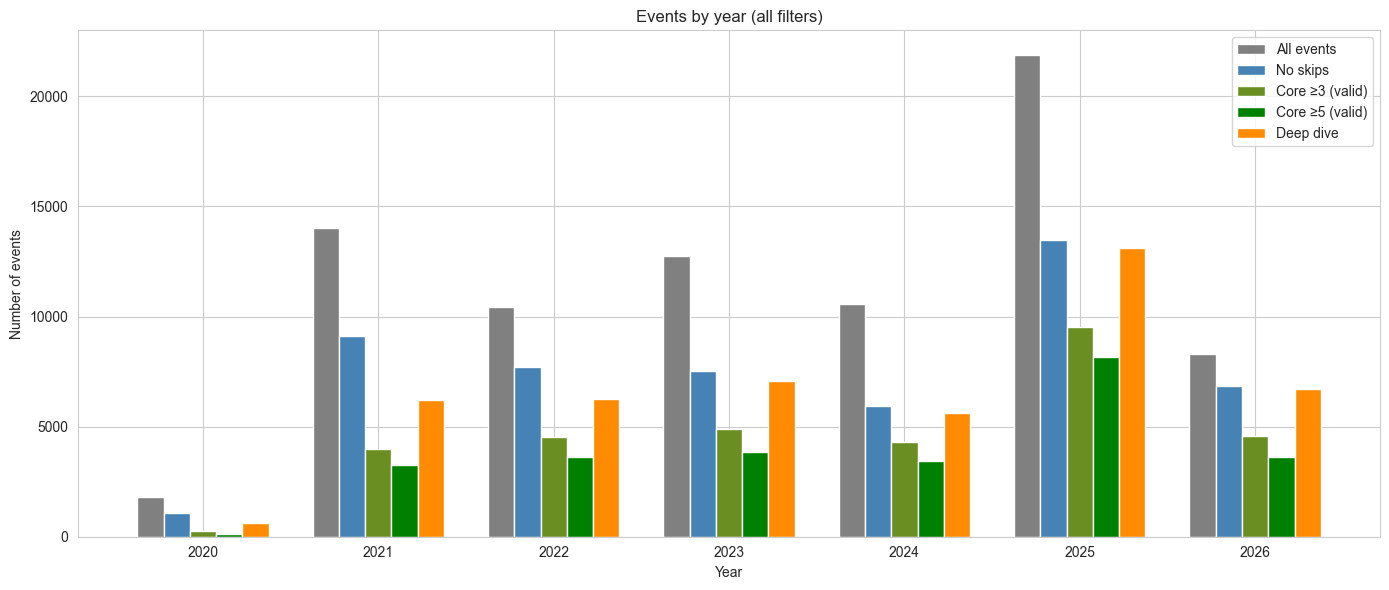


🔍 Interpretation:
   Peak year: 2025 (21,900 events).
   Quietest year: 2020 (1,795 events).
   Deep dive peak: 2025.


In [165]:
# 1. События по годам и фильтрам

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

# Фильтры пересоздаём здесь один раз после загрузки данных.
# В этапе 6 они нужны для сравнения объёма по годам.
filters = {
    'All events': np.ones(len(df), dtype=bool),
    'No skips': ~df['is_skip'],
    'Core ≥3 (valid)': df['valid_play'] & (df['valid_listen_count'] >= 3),
    'Core ≥5 (valid)': df['valid_play'] & (df['valid_listen_count'] >= 5),
    'Deep dive': mask_deep,
}

years = sorted(df['year'].unique())

# Количество событий по каждому фильтру и году.
yearly_counts = pd.DataFrame({'Год': years})
for name, mask in filters.items():
    yearly_counts[name] = [
        df[(mask) & (df['year'] == y)].shape[0]
        for y in years
    ]

print('📊 Events by year (all filters):')
yearly_counts_display = yearly_counts.copy()
yearly_counts_display.index = range(1, len(yearly_counts_display) + 1)
yearly_counts_display.index.name = '№'
display(yearly_counts_display)

# График: столбики по годам для каждого фильтра.
plt.figure(figsize=(14, 6))
x = np.arange(len(years))
width = 0.15
colors = {
    'All events': 'gray',
    'No skips': 'steelblue',
    'Core ≥3 (valid)': 'olivedrab',
    'Core ≥5 (valid)': 'green',
    'Deep dive': 'darkorange',
}

for i, (name, mask) in enumerate(filters.items()):
    vals = yearly_counts[name].values
    plt.bar(x + (i - 2) * width, vals, width, label=name, color=colors[name], edgecolor='white')

plt.xticks(x, years)
plt.xlabel('Year')
plt.ylabel('Number of events')
plt.title('Events by year (all filters)')
plt.legend()
plt.tight_layout()
plt.show()

# Автоинтерпретация по All events и Deep dive.
print('\n🔍 Interpretation:')
total_by_year = yearly_counts.set_index('Год')['All events']
max_year = total_by_year.idxmax()
min_year = total_by_year.idxmin()
print(f'   Peak year: {max_year} ({total_by_year[max_year]:,} events).')
print(f'   Quietest year: {min_year} ({total_by_year[min_year]:,} events).')

deep_peak = yearly_counts.loc[yearly_counts['Deep dive'].idxmax(), 'Год']
print(f'   Deep dive peak: {deep_peak}.')

### Вывод по блоку 1

Поток событий по годам неровный. Пик — 2025 (21 900 событий), минимум —
2020 (1 795). Но 2020 и 2026 неполные, поэтому прямое сравнение с ними
некорректно. Среди полных лет: 2021 (14 001), 2022 (10 419),
2023 (12 750), 2024 (10 573), 2025 (21 900). 2025 выделяется резко —
почти вдвое больше 2024 и в два раза больше 2022.

Deep dive повторяет форму All events: пик в 2025 (13 110), минимум
среди полных лет — в 2024 (5 626). Пропорция Deep dive к All events
стабильна: около 44% в 2021, 60% в 2022, 56% в 2023, 53% в 2024,
60% в 2025.

Фильтры ведут себя согласованно. Отношение No skips к All events
держится около 65% в полные годы, Core ≥3 — около 40%, Core ≥5 —
около 33%.

По абсолютному числу событий 2024 ниже 2023 (10 573 против 12 750),
но выше 2022 (10 419). Минимум по объёму среди полных лет — 2022.
Но 2024 остаётся «тихим» по другим осям: блоки 2.1, 3.4 и 4
показывают его как год синхронного провала по аудио.

# Блок 2. Долгосрочные тренды и корреляции

## 2. Долгосрочные тренды и корреляции

Первый блок, который смотрит на динамику. Он отвечает на два
вопроса: как менялся аудио-профиль за шесть лет и как
характеристики связаны между собой на длинном масштабе.

**Методология.** Тренды считаются по 30-дневным скользящим средним,
чтобы убрать дневной шум и оставить многомесячные движения.
Корреляции считаются между сглаженными рядами — это даёт
согласованность долгосрочных движений, а не силу связи день ко дню
(эффект Юла–Слуцкого). Сравнение половин периода даёт одно число
«насколько сдвинулось», гипотезы проверяются по совпадению
экстремумов, sanity check проверяет, что ожидаемые связи
воспроизводятся.

**Как устроен блок.** Пять ячеек.

- **2.1** — тренды по 10 характеристикам: 7- и 30-дневные средние,
  сравнение половин периода, оценка существенности сдвига.
- **2.2** — корреляции 30-дневных сглаженных рядов, пары с |r| > 0.3,
  гипотезы для |r| > 0.7.
- **2.3** — проверка гипотез по совпадению экстремумов: где связи
  подтверждаются, где асимметричны.
- **2.4** — визуализация пар с |r| > 0.7: две нормированные кривые
  с подсветкой экстремумов.
- **2.5** — контроль целостности: проверка ожидаемых связей
  (feature construction, production convention, perceptual
  association) и фиксация дополнительных пар как наблюдений.

## 2.1 Долгосрочные тренды и существенность изменений

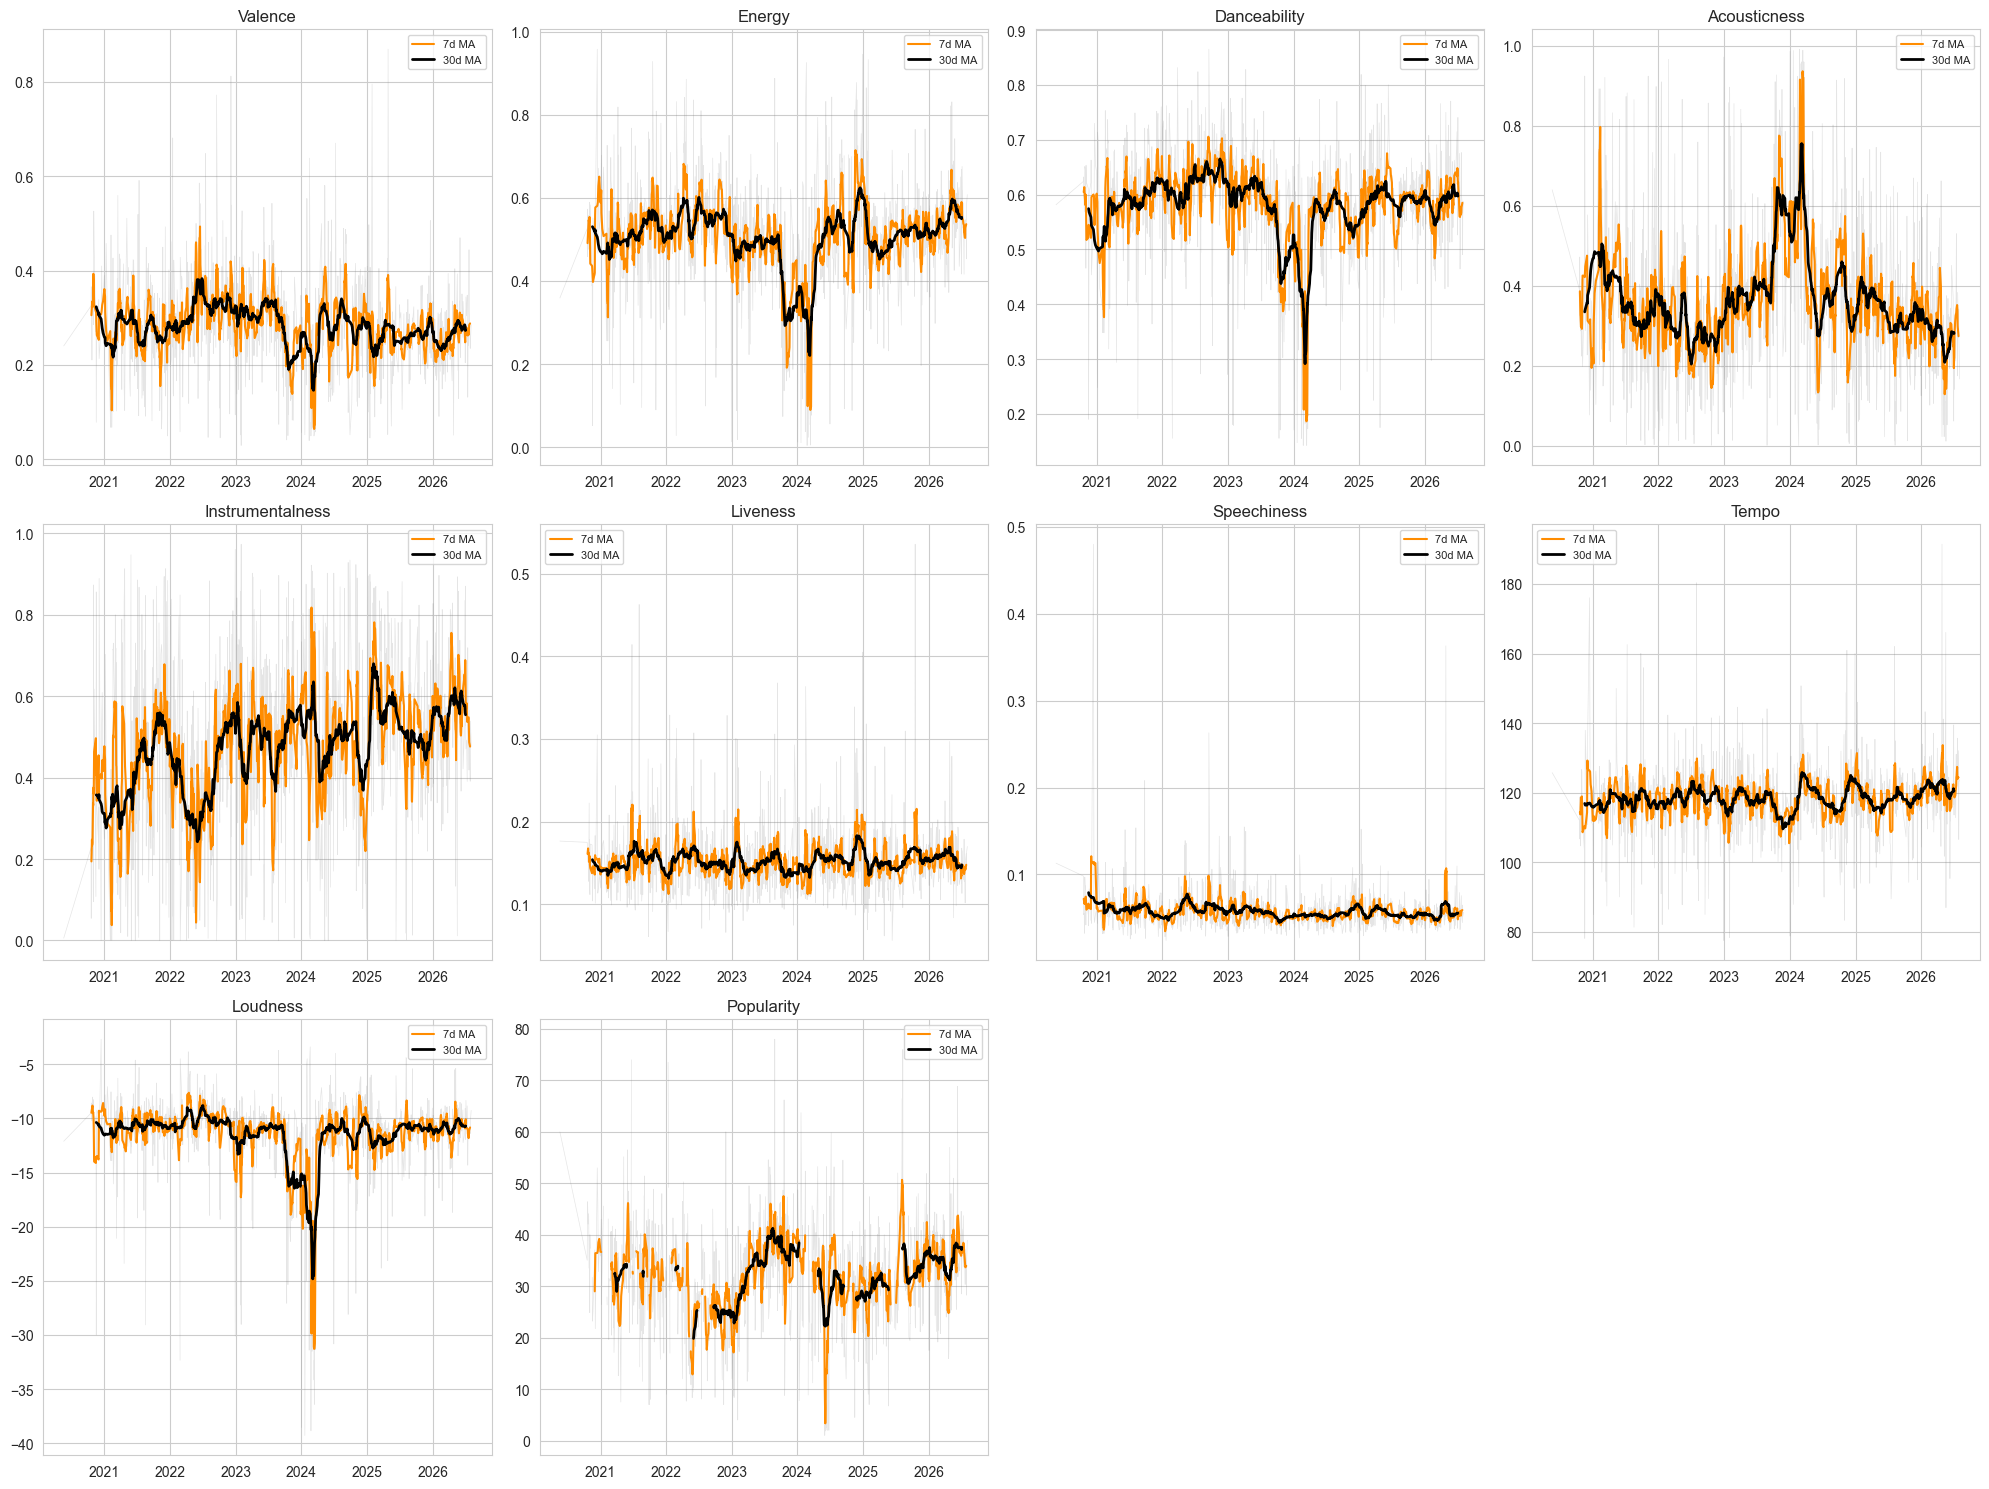

📊 Trends across all features:


,Feature,1st half mean,2nd half mean,Diff,Trend,1st half median,2nd half median,Significance
№,,,,,,,,
1,Valence,0.304,0.261,-0.043,down,0.306,0.261,📊 moderate
2,Energy,0.519,0.488,-0.031,down,0.525,0.507,📊 moderate
3,Danceability,0.602,0.558,-0.044,down,0.612,0.583,📊 moderate
4,Acousticness,0.344,0.379,0.036,up,0.320,0.338,📊 moderate
5,Instrumentalness,0.416,0.528,0.112,up,0.431,0.526,💪 strong
6,Liveness,0.153,0.153,0.000,up,0.147,0.147,🤏 weak
7,Speechiness,0.061,0.054,-0.006,down,0.056,0.052,🤏 weak
8,Tempo,118.127,118.964,0.837,up,118.952,119.384,🤏 weak
9,Loudness,-10.710,-12.275,-1.565,down,-10.265,-11.070,📊 moderate



🔍 Interpretation:
   Valence: down (diff -0.043) — 📊 moderate
   Energy: down (diff -0.031) — 📊 moderate
   Danceability: down (diff -0.044) — 📊 moderate
   Acousticness: up (diff +0.036) — 📊 moderate
   Instrumentalness: up (diff +0.112) — 💪 strong
   Tempo: up (diff +0.837) — 🤏 weak
   Loudness: down (diff -1.565) — 📊 moderate
   Popularity: up (diff +1.715) — 🤏 weak

   Most significant change: Instrumentalness (diff +0.112, normalized 2.24)


In [166]:
# 2.1 Долгосрочные тренды и существенность изменений

# Смотрим, как менялись аудио-характеристики за весь период.
# Для каждой характеристики — три линии:
#   - серый шум: дневные значения (для наглядности разброса);
#   - оранжевая: 7-дневное скользящее среднее (короткий тренд);
#   - чёрная: 30-дневное скользящее среднее (долгосрочный тренд).
#
# Затем сравниваем среднее первой и второй половины периода, чтобы получить
# одно число «насколько сдвинулось». Оцениваем существенность сдвига по порогам
# из THRESHOLDS (сильное / умеренное / слабое).

n_cols = 4
n_rows = ceil(len(FEATURES) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

trend_summary = []

for idx, (col, title) in enumerate(FEATURES):
    ax = axes[idx]
    ma7 = daily[col].rolling(7, center=True).mean()
    ma30 = daily[col].rolling(30, center=True).mean()

    ax.plot(daily['date'], daily[col], alpha=0.2, color='gray', linewidth=0.5)
    ax.plot(daily['date'], ma7, linewidth=1.5, color='darkorange', label='7d MA')
    ax.plot(daily['date'], ma30, linewidth=2, color='black', label='30d MA')
    ax.set_title(title, fontsize=12)
    ax.legend(fontsize=8)

    # Сравнение половин периода: до медианной даты vs после.
    median_date = daily['date'].median()
    first_mean = daily[daily['date'] < median_date][col].mean()
    second_mean = daily[daily['date'] >= median_date][col].mean()
    first_median = daily[daily['date'] < median_date][col].median()
    second_median = daily[daily['date'] >= median_date][col].median()
    diff = second_mean - first_mean
    direction = 'up' if diff > 0 else 'down'
    trend_summary.append((
        title,
        first_mean, second_mean, diff, direction,
        first_median, second_median,
    ))
for j in range(idx + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# Сводная таблица трендов.
trend_df = pd.DataFrame(
    trend_summary,
    columns=['Feature', '1st half mean', '2nd half mean', 'Diff', 'Trend',
             '1st half median', '2nd half median']
)
trend_df['1st half mean'] = trend_df['1st half mean'].round(3)
trend_df['2nd half mean'] = trend_df['2nd half mean'].round(3)
trend_df['Diff'] = trend_df['Diff'].round(3)
trend_df['1st half median'] = trend_df['1st half median'].round(3)
trend_df['2nd half median'] = trend_df['2nd half median'].round(3)

def evaluate_significance(row):
    """
    Оценка существенности сдвига между половинами периода.

    Пороги берутся из THRESHOLDS (strong, moderate).
    Если разница меньше moderate порога — сдвиг слабый.
    """
    name = row['Feature']
    diff = abs(row['Diff'])
    if name in THRESHOLDS:
        strong, moderate = THRESHOLDS[name]
        if diff >= strong:
            return '💪 strong'
        elif diff >= moderate:
            return '📊 moderate'
        else:
            return '🤏 weak'
    return ''


trend_df['Significance'] = trend_df.apply(evaluate_significance, axis=1)
trend_df = trend_df.reset_index(drop=True)
trend_df.index = trend_df.index + 1
trend_df.index.name = '№'

print('📊 Trends across all features:')
display(trend_df)

# Автоинтерпретация: только те, у кого разница больше 0.01 по модулю.
print('\n🔍 Interpretation:')
significant = trend_df[trend_df['Diff'].abs() > 0.01]
if not significant.empty:
    for _, row in significant.iterrows():
        print(f'   {row["Feature"]}: {row["Trend"]} (diff {row["Diff"]:+.3f}) — {row["Significance"]}')

    # Нормированная разница — чтобы сравнить характеристики с разными шкалами.
    trend_df['Normalized diff'] = trend_df.apply(
        lambda r: abs(r['Diff']) / THRESHOLDS.get(r['Feature'], (1, 1))[0],
        axis=1
    )
    top_idx = trend_df['Normalized diff'].idxmax()
    top_change = trend_df.loc[top_idx]
    print(f'\n   Most significant change: {top_change["Feature"]} '
          f'(diff {top_change["Diff"]:+.3f}, normalized {top_change["Normalized diff"]:.2f})')
else:
    print('   No practically significant changes over the observation period.')

### Вывод по блоку 2.1

Сравнение половин периода даёт не одно движение, а несколько разных
по силе и направлению. Из десяти характеристик девять меняются,
одна (liveness) не меняется вообще.

**Сильное изменение — одно.** Instrumentalness (+0.112, нормализованная
разница 2.24). Это единственная характеристика, попавшая в категорию
«strong» по порогам `THRESHOLDS`. Рост виден и по средним (0.416 → 0.528),
и по медианам (0.431 → 0.526) — сдвинулся сам центр, а не хвост.

**Умеренные изменения — пять.** Valence (−0.043), danceability (−0.044),
energy (−0.031), acousticness (+0.036), loudness (−1.565 дБ). Эти
пять согласуются между собой: valence, danceability и energy падают
вместе, acousticness растёт, loudness тише. По направлению они
складываются в один сдвиг — от энергичного и громкого края к более
тихому и акустическому.

**Слабые изменения — три, и они не укладываются в тот же вектор.**
Tempo (+0.837 BPM) и popularity (+1.715) растут, а не падают.
Если бы профиль двигался «к спокойствию и нишевости», темп падал бы,
а популярность — тоже. Обе характеристики меняются слабо (ниже
порогов), но их направление противоположно основной группе.
Speechiness (−0.006) падает, но настолько мало, что это
не интерпретируется.

**Главное наблюдение.** Движение не сводится к одной оси. Есть
основная группа из шести характеристик (instrumentalness, acousticness,
valence, danceability, energy, loudness), которые согласованно сдвигаются
в одну сторону. И есть tempo с popularity, которые идут слабо,
но в противоположную. Упрощение «профиль стал спокойнее и тише»
было бы неточным: темп не упал, а популярность не упала — обе чуть
выросли.

**Расхождение mean и median мало для всех характеристик.** Значения
близки — valence 0.304 vs 0.306, instrumentalness 0.416 vs 0.431,
energy 0.519 vs 0.525. Сдвиг между половинами не создаётся отдельными
экстремальными днями: меняется центр распределения, а не хвосты.

**Итог.** Тренд — не «разворот вкуса», а медленное смещение внутри
той же звуковой зоны: инструментальность растёт, энергичность
и громкость падают. Пользователь не сменил жанр, он двинулся
от более яркого края своей зоны к более тихому. Год, где эта
тенденция проявилась резче всего, — 2024; детальный разбор
в 2.3 и 3.4.

## 2.2 Корреляции сглаженных трендов и гипотезы

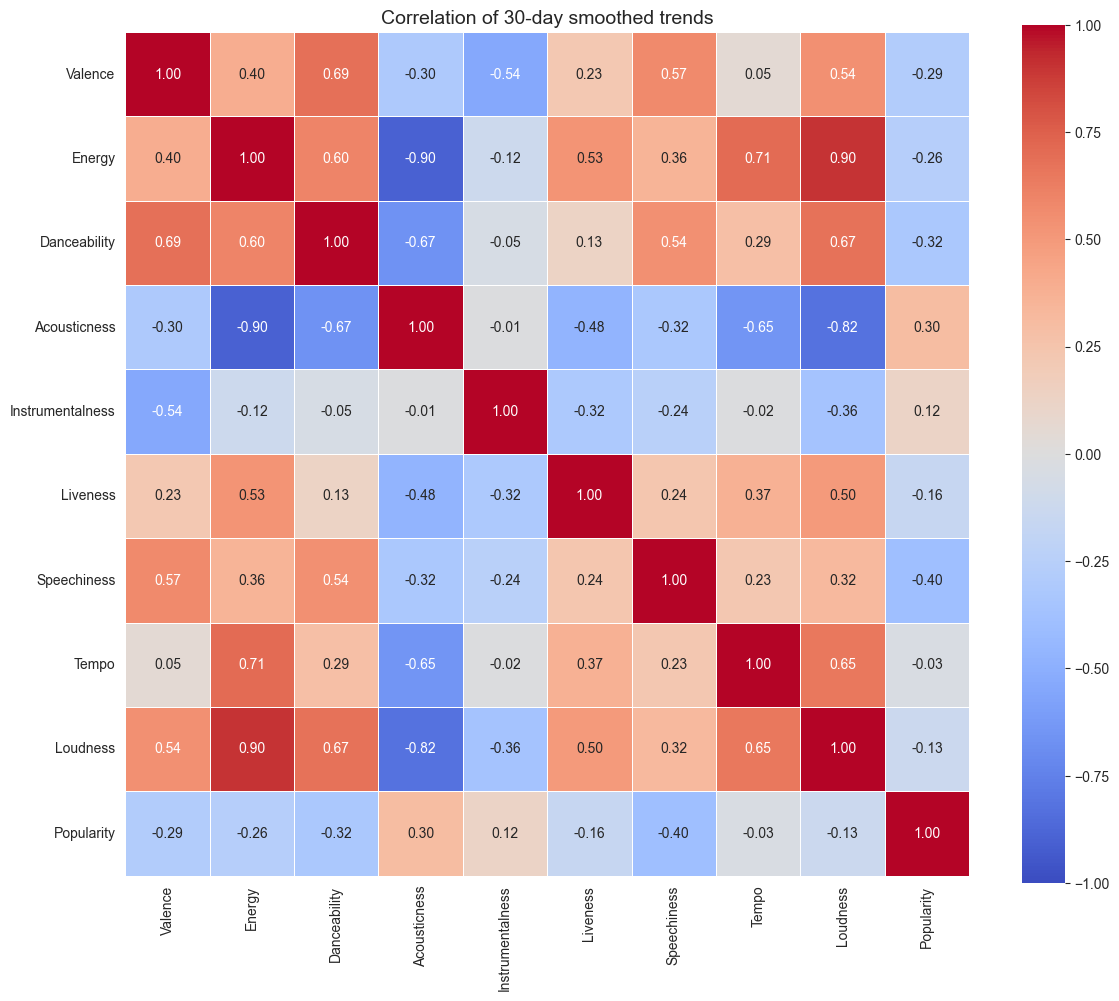

📊 Significant trend correlations (|r| > 0.3):


,Feature 1,Feature 2,Correlation,Direction
№,,,,
1,Energy,Loudness,0.901962,positive
2,Energy,Acousticness,-0.900295,negative
3,Acousticness,Loudness,-0.822373,negative
4,Energy,Tempo,0.709450,positive
5,Valence,Danceability,0.685197,positive
6,Danceability,Loudness,0.674810,positive
7,Danceability,Acousticness,-0.666366,negative
8,Tempo,Loudness,0.654132,positive
9,Acousticness,Tempo,-0.651517,negative



🔺 Top-3 positive correlations:
   Energy ↔ Loudness: 0.90
   Energy ↔ Tempo: 0.71
   Valence ↔ Danceability: 0.69

🔻 Top-3 negative correlations:
   Energy ↔ Acousticness: -0.90
   Acousticness ↔ Loudness: -0.82
   Danceability ↔ Acousticness: -0.67

🎯 Hypotheses for further analysis (|r| > 0.7):
   • Energy ↔ Loudness (r=0.90): move together.
   • Energy ↔ Acousticness (r=-0.90): move in opposite directions.
   • Acousticness ↔ Loudness (r=-0.82): move in opposite directions.
   • Energy ↔ Tempo (r=0.71): move together.



> ⚠️ **Note (Yule–Slutsky effect).**  
> Correlations are computed on 30-day rolling means. Smoothing inflates
> Pearson's r by removing high-frequency noise. Values here reflect the
> coherence of long-term movements, not the strength of daily-level relations.


In [167]:
# 2.2 Корреляции сглаженных трендов и гипотезы

# Считаем корреляции не между исходными дневными значениями, а между
# 30-дневными скользящими средними. Это позволяет увидеть согласованность
# долгосрочных движений — какие характеристики меняются синхронно.
#
# Важно: сглаживание искусственно завышает Пирсона (эффект Юла-Слуцкого),
# потому что убирает высокочастотный шум. Мы используем это сознательно —
# нам важна согласованность трендов, а не сила связи исходных рядов.

# Сглаженные 30-дневные ряды для всех характеристик.
trends = pd.DataFrame({'date': daily['date']})
for col, name in FEATURES:
    trends[name] = daily[col].rolling(30, center=True).mean()
trends = trends.dropna()

corr_trends = trends.drop(columns='date').corr()

# Тепловая карта корреляций.
plt.figure(figsize=(12, 10))
sns.heatmap(corr_trends, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title('Correlation of 30-day smoothed trends', fontsize=14)
plt.tight_layout()
plt.show()

# Собираем пары с |r| > 0.3. Порог 0.3 — потому что при сглаживании
# даже слабые исходные связи могут вырасти. Нас интересуют средние и сильные.
pairs = []
for i in range(len(corr_trends.columns)):
    for j in range(i + 1, len(corr_trends.columns)):
        r = corr_trends.iloc[i, j]
        if abs(r) > 0.3:
            pairs.append((corr_trends.columns[i], corr_trends.columns[j], r))

if pairs:
    pairs.sort(key=lambda x: abs(x[2]), reverse=True)
    corr_df = pd.DataFrame(pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])
    corr_df['Direction'] = corr_df['Correlation'].apply(lambda x: 'positive' if x > 0 else 'negative')
    corr_df = corr_df.reset_index(drop=True)
    corr_df.index = corr_df.index + 1
    corr_df.index.name = '№'
    print('📊 Significant trend correlations (|r| > 0.3):')
    display(corr_df)
else:
    print('📊 No significant correlations between trends.')

# Топ-3 положительных и отрицательных — для краткого вывода.
positive_pairs = [(a, b, r) for a, b, r in pairs if r > 0]
negative_pairs = [(a, b, r) for a, b, r in pairs if r < 0]
top_pos = sorted(positive_pairs, key=lambda x: x[2], reverse=True)[:3]
top_neg = sorted(negative_pairs, key=lambda x: x[2])[:3]

print('\n🔺 Top-3 positive correlations:')
for a, b, r in top_pos:
    print(f'   {a} ↔ {b}: {r:.2f}')

print('\n🔻 Top-3 negative correlations:')
for a, b, r in top_neg:
    print(f'   {a} ↔ {b}: {r:.2f}')

# Гипотезы для дальнейшего анализа: пары с |r| > 0.7 — это кандидаты
# на «энергичный кластер». Их будем проверять в 2.3 и 2.4.
# Список строится динамически из pairs — никаких хардкоженных названий.
print('\n🎯 Hypotheses for further analysis (|r| > 0.7):')
strong_pairs = [(a, b, r) for a, b, r in pairs if abs(r) > 0.7]
if strong_pairs:
    for a, b, r in strong_pairs:
        direction = 'move together' if r > 0 else 'move in opposite directions'
        print(f'   • {a} ↔ {b} (r={r:.2f}): {direction}.')
else:
    print('   No pairs with |r| > 0.7 — all trends sufficiently independent.')


# --- Примечание про эффект Юла-Слуцкого ---
from IPython.display import Markdown, display

note = """
> ⚠️ **Note (Yule–Slutsky effect).**  
> Correlations are computed on 30-day rolling means. Smoothing inflates
> Pearson's r by removing high-frequency noise. Values here reflect the
> coherence of long-term movements, not the strength of daily-level relations.
"""
display(Markdown(note))

### Вывод по блоку 2.2

Корреляции 30-дневных сглаженных рядов показывают, какие характеристики
движутся синхронно на длинном масштабе. Пар с |r| > 0.3 набирается 28 —
это уже не отдельные связи, а плотная сетка, в которой почти каждая
характеристика связана с несколькими другими.

**Ядро — четыре пары с |r| > 0.7.** Energy ↔ Loudness (+0.90),
Energy ↔ Acousticness (−0.90), Acousticness ↔ Loudness (−0.82),
Energy ↔ Tempo (+0.71). Три из четырёх — про одну ось: энергичное,
громкое и быстрое идут вместе, акустичное им противоположно. Это
не открытие о пользователе, а физика звука: громкая музыка почти
всегда энергичная, акустическая — почти всегда тихая. Проверка,
подтверждены ли эти связи на ожидаемом уровне, — в 2.5.

**Средний слой (|r| от 0.5 до 0.7)** расширяет ту же ось. Valence ↔
Danceability (+0.69), Danceability ↔ Loudness (+0.67), Danceability ↔
Acousticness (−0.67), Tempo ↔ Loudness (+0.65), Acousticness ↔ Tempo
(−0.65), Energy ↔ Danceability (+0.60). Valence подтягивается
к danceability, а через неё — к energy и loudness. Получается
расширенный «яркий» кластер: valence, danceability, energy, loudness,
tempo движутся согласованно, acousticness — в противофазе.

**Хвост (|r| от 0.3 до 0.5)** включает пары, которые в эту ось
не укладываются. Valence ↔ Speechiness (+0.57) и Danceability ↔
Speechiness (+0.54) — вокальная музыка с речью оказалась связана
с позитивностью и танцевальностью, хотя speechiness — не часть
основной оси. Valence ↔ Instrumentalness (−0.54): инструментальное
тяготеет к меланхолии. Instrumentalness в этой сетке стоит особняком —
она не входит в «яркий» кластер и связана с ним только через valence.

**Оговорка про сглаживание.** Корреляции считаются на 30-дневных
скользящих средних, а не на исходных дневных значениях. Сглаживание
убирает высокочастотный шум и искусственно завышает Пирсона (эффект
Юла–Слуцкого). Поэтому r = 0.90 здесь означает не «сильная связь
день ко дню», а «эти две характеристики двигаются согласованно
на масштабе месяцев». На дневном уровне связь была бы слабее —
насколько, из этих чисел не видно.

**Итог.** Сглаженные тренды группируются в две оси: «яркий» кластер
(valence, danceability, energy, loudness, tempo) и акустическая
противофаза к нему. Instrumentalness в сетке стоит отдельно — она
не часть яркого кластера. Четыре пары с |r| > 0.7 уходят в 2.3
на проверку по совпадению пиков и в 2.4 на визуализацию.

## 2.3 Ключевые периоды и проверка гипотез по пикам


ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Peak years for key features:


,Energy,Loudness,Danceability,Acousticness,Valence,Instrumentalness,Speechiness,Tempo
Max,2026,2022,2022,2024,2022,2024,2020,2026
Min,2024,2024,2024,2026,2024,2020,2026,2020



🔍 Key periods:
   Most energetic year: 2026
   Least energetic year: 2024
   Most acoustic year: 2024


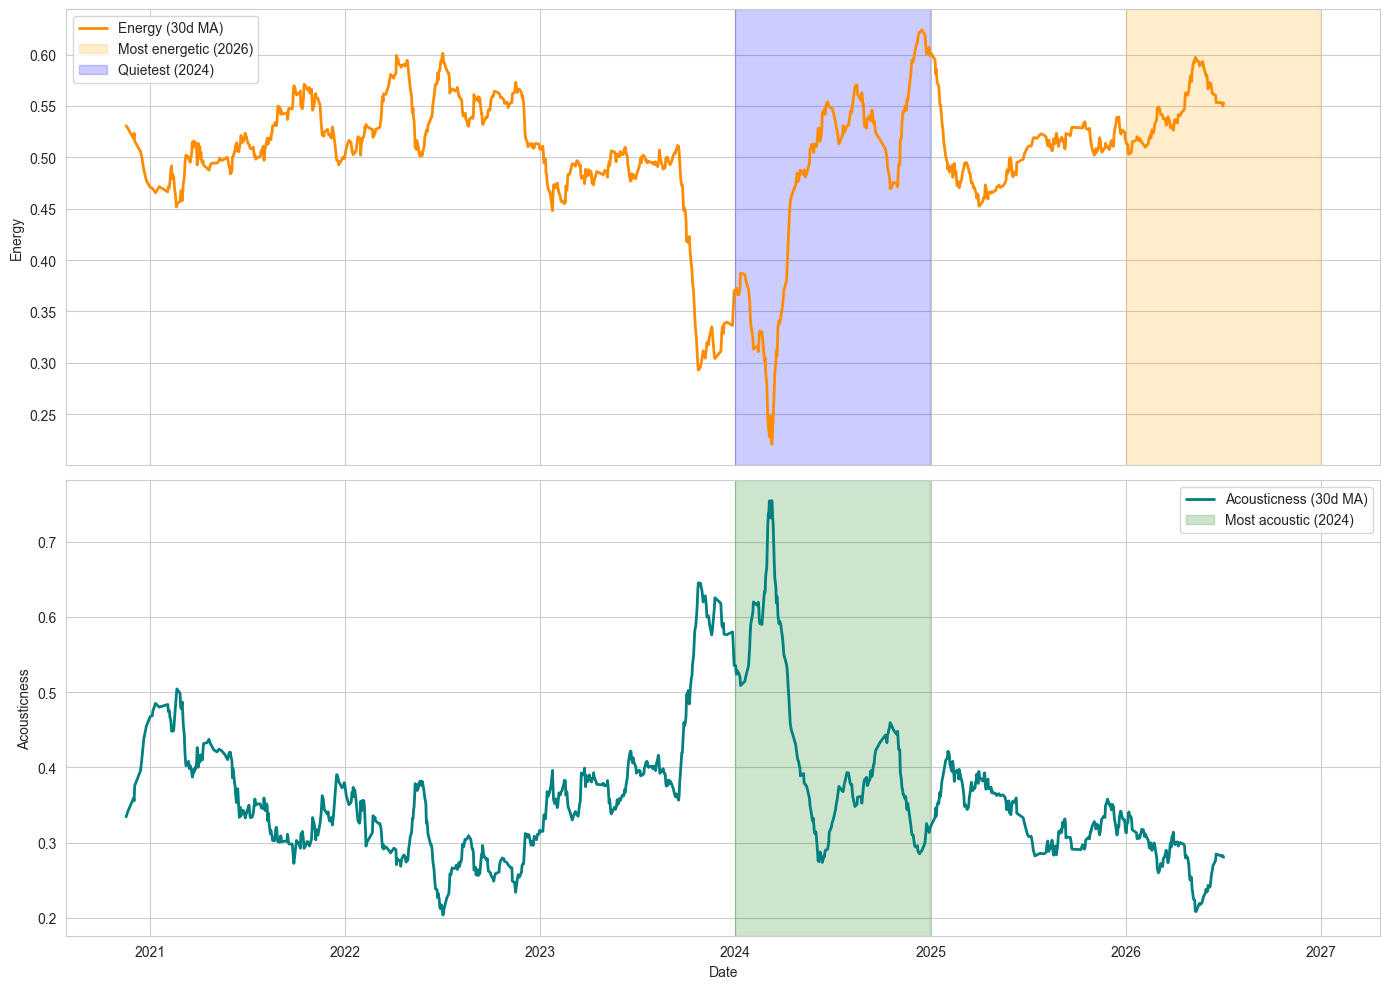


🎯 Hypothesis check (|r| > 0.7) by extrema coincidence:
   🟡 Energy ↔ Loudness (r=0.90): partial — min coincides (2024), max diverges (2026 vs 2022).
   ✅ Energy ↔ Acousticness (r=-0.90): confirmed (mirror at 2026 ⏳).
   ✅ Acousticness ↔ Loudness (r=-0.82): confirmed (mirror at 2024).
   🟡 Energy ↔ Tempo (r=0.71): partial — max coincides (2026 ⏳), min diverges (2024 vs 2020).


In [168]:
# 2.3 Ключевые периоды и проверка гипотез по пикам

# Здесь мы проверяем гипотезы из 2.2 (strong_pairs) не через корреляции,
# а через совпадение пиков. Если две характеристики связаны положительно,
# их максимумы должны приходиться на один год. Если отрицательно — максимум
# одной должен совпадать с минимумом другой.
#
# Список strong_pairs берётся из 2.2 — он уже построен динамически
# из corr_trends. Никаких хардкоженных пар здесь нет.
#
# Важно: strong_pairs из 2.2 содержит английские названия ('Energy', 'Loudness'),
# потому что они берутся из столбцов corr_trends, которые построены по FEATURES.

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

# Средние по годам для каждой характеристики (deep dive).
yearly = df_deep.groupby('year').agg(
    Energy=('energy', 'mean'),
    Acousticness=('acousticness', 'mean'),
    Loudness=('loudness', 'mean'),
    Danceability=('danceability', 'mean'),
    Valence=('valence', 'mean'),
    Instrumentalness=('instrumentalness', 'mean'),
    Speechiness=('speechiness', 'mean'),
    Tempo=('tempo', 'mean')
).reset_index()


def get_peak_years(series, years):
    """Возвращает (год максимума, год минимума) для ряда."""
    max_year = years[series.argmax()]
    min_year = years[series.argmin()]
    return int(max_year), int(min_year)


years = yearly['year'].values
peak_dict = {}
for col in ['Energy', 'Loudness', 'Danceability', 'Acousticness',
            'Valence', 'Instrumentalness', 'Speechiness', 'Tempo']:
    max_y, min_y = get_peak_years(yearly[col], years)
    peak_dict[col] = (max_y, min_y)

peaks_df = pd.DataFrame(peak_dict, index=['Max', 'Min']).astype(int)
print('📊 Peak years for key features:')
display(peaks_df)

most_energetic_year = peak_dict['Energy'][0]
least_energetic_year = peak_dict['Energy'][1]
most_acoustic_year = peak_dict['Acousticness'][0]

print(f'\n🔍 Key periods:')
print(f'   Most energetic year: {most_energetic_year}')
print(f'   Least energetic year: {least_energetic_year}')
print(f'   Most acoustic year: {most_acoustic_year}')

# Два графика: Energy и Acousticness с выделением пиковых лет.
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

axes[0].plot(daily['date'], daily['energy_mean'].rolling(30, center=True).mean(),
             color='darkorange', linewidth=2, label='Energy (30d MA)')
axes[0].axvspan(pd.Timestamp(f'{most_energetic_year}-01-01'),
                pd.Timestamp(f'{most_energetic_year}-12-31'),
                alpha=0.2, color='orange', label=f'Most energetic ({most_energetic_year})')
axes[0].axvspan(pd.Timestamp(f'{least_energetic_year}-01-01'),
                pd.Timestamp(f'{least_energetic_year}-12-31'),
                alpha=0.2, color='blue', label=f'Quietest ({least_energetic_year})')
axes[0].set_ylabel('Energy')
axes[0].legend()

axes[1].plot(daily['date'], daily['acousticness_mean'].rolling(30, center=True).mean(),
             color='teal', linewidth=2, label='Acousticness (30d MA)')
axes[1].axvspan(pd.Timestamp(f'{most_acoustic_year}-01-01'),
                pd.Timestamp(f'{most_acoustic_year}-12-31'),
                alpha=0.2, color='green', label=f'Most acoustic ({most_acoustic_year})')
axes[1].set_ylabel('Acousticness')
axes[1].legend()

plt.xlabel('Date')
plt.tight_layout()
plt.show()


# --- Проверка гипотез по совпадению экстремумов ---
# Для каждой пары из strong_pairs:
#   - если r > 0: проверяем совпадение И максимумов, И минимумов.
#       оба совпали     → ✅ confirmed on both ends
#       один совпал     → 🟡 partial (указываем, какой конец)
#       ни один         → ⚠️ diverge
#   - если r < 0: проверяем зеркало max↔min в обе стороны.
#       любое сработало → ✅ confirmed
#       ни одно         → ⚠️ not mirrored
#
# Если пик приходится на неполный год (2020 или 2026), добавляется флаг ⏳:
# такой экстремум может быть артефактом обрезки периода, а не реальным пиком.

def _year_flag(year):
    """Флаг для года, который может быть артефактом обрезки."""
    return ' ⏳' if year in incomplete_years else ''

print('\n🎯 Hypothesis check (|r| > 0.7) by extrema coincidence:')
for a, b, r in strong_pairs:
    name_a = a if a in peak_dict else a.replace('_mean', '').capitalize()
    name_b = b if b in peak_dict else b.replace('_mean', '').capitalize()

    if name_a not in peak_dict or name_b not in peak_dict:
        print(f'   ⚠️ {a} ↔ {b} (r={r:.2f}): names not found in peak_dict, skipping.')
        continue

    max_a, min_a = peak_dict[name_a]
    max_b, min_b = peak_dict[name_b]

    if r > 0:
        max_match = (max_a == max_b)
        min_match = (min_a == min_b)

        if max_match and min_match:
            print(f'   ✅ {a} ↔ {b} (r={r:.2f}): confirmed on both ends '
                  f'(max {max_a}{_year_flag(max_a)}, min {min_a}{_year_flag(min_a)}).')
        elif max_match:
            print(f'   🟡 {a} ↔ {b} (r={r:.2f}): partial — max coincides '
                  f'({max_a}{_year_flag(max_a)}), min diverges ({min_a} vs {min_b}).')
        elif min_match:
            print(f'   🟡 {a} ↔ {b} (r={r:.2f}): partial — min coincides '
                  f'({min_a}{_year_flag(min_a)}), max diverges ({max_a} vs {max_b}).')
        else:
            print(f'   ⚠️ {a} ↔ {b} (r={r:.2f}): diverge — '
                  f'max {max_a} vs {max_b}, min {min_a} vs {min_b}.')
    else:
        mirror_1 = (max_a == min_b)
        mirror_2 = (min_a == max_b)

        if mirror_1 or mirror_2:
            mirror_year = max_a if mirror_1 else min_a
            print(f'   ✅ {a} ↔ {b} (r={r:.2f}): confirmed (mirror at '
                  f'{mirror_year}{_year_flag(mirror_year)}).')
        else:
            print(f'   ⚠️ {a} ↔ {b} (r={r:.2f}): not mirrored — '
                  f'max {max_a}/{max_b}, min {min_a}/{min_b}.')

### Вывод по блоку 2.3

Проверка гипотез из 2.2 через совпадение экстремумов даёт не бинарный
ответ, а три статуса. Для положительных пар проверяются оба конца —
совпадение максимумов и совпадение минимумов. Для отрицательных —
зеркало max↔min в обе стороны.

**Полностью подтверждены — две отрицательные пары.** Energy ↔
Acousticness (r=−0.90): максимум energy 2026 совпадает с минимумом
acousticness 2026. Acousticness ↔ Loudness (r=−0.82): максимум
acousticness 2024 совпадает с минимумом loudness 2024. Обе связи
работают как зеркало: пик одной приходится на провал другой.

**Частично подтверждены — обе положительные пары.** Energy ↔ Loudness
(r=0.90) совпадает на минимуме (оба 2024) и расходится на максимуме
(2026 vs 2022). Energy ↔ Tempo (r=0.71) — наоборот: совпадает
на максимуме (2026) и расходится на минимуме (2024 vs 2020).

Это не «провал проверки», а содержательный результат. Самые сильные
положительные связи в сглаженных рядах работают асимметрично: внизу
профиль движется согласованно, наверху — нет. Синхронный провал 2024
одновременно понизил энергию, громкость и темп. А возвращение вверх
произошло в разные годы: громкость восстановилась раньше (2022),
энергия и темп — позже (2026).

**Оговорка про неполные годы.** Максимумы energy, tempo и минимум
acousticness приходятся на 2026, который обрезан (данные до августа).
Пик может быть артефактом того, что в этот год попали только «высокие»
месяцы, а «низкие» — не попали. Проверка на полных годах в 3.5
покажет, выдерживает ли этот пик точечную проверку с окном ±6 месяцев.

**Что метод даёт и чего не даёт.** Он подтверждает связь, если обе
характеристики одновременно уходят в экстремум, и указывает, на каком
конце это происходит. Он не показывает, какая из двух характеристик
«ведущая» — для этого нужен лаг-анализ, которого здесь нет.

## 2.4 Визуализация гипотез с |r| > 0.7

ℹ️ trends covers years: 2021–2026. Extrema outside this range will not be highlighted.


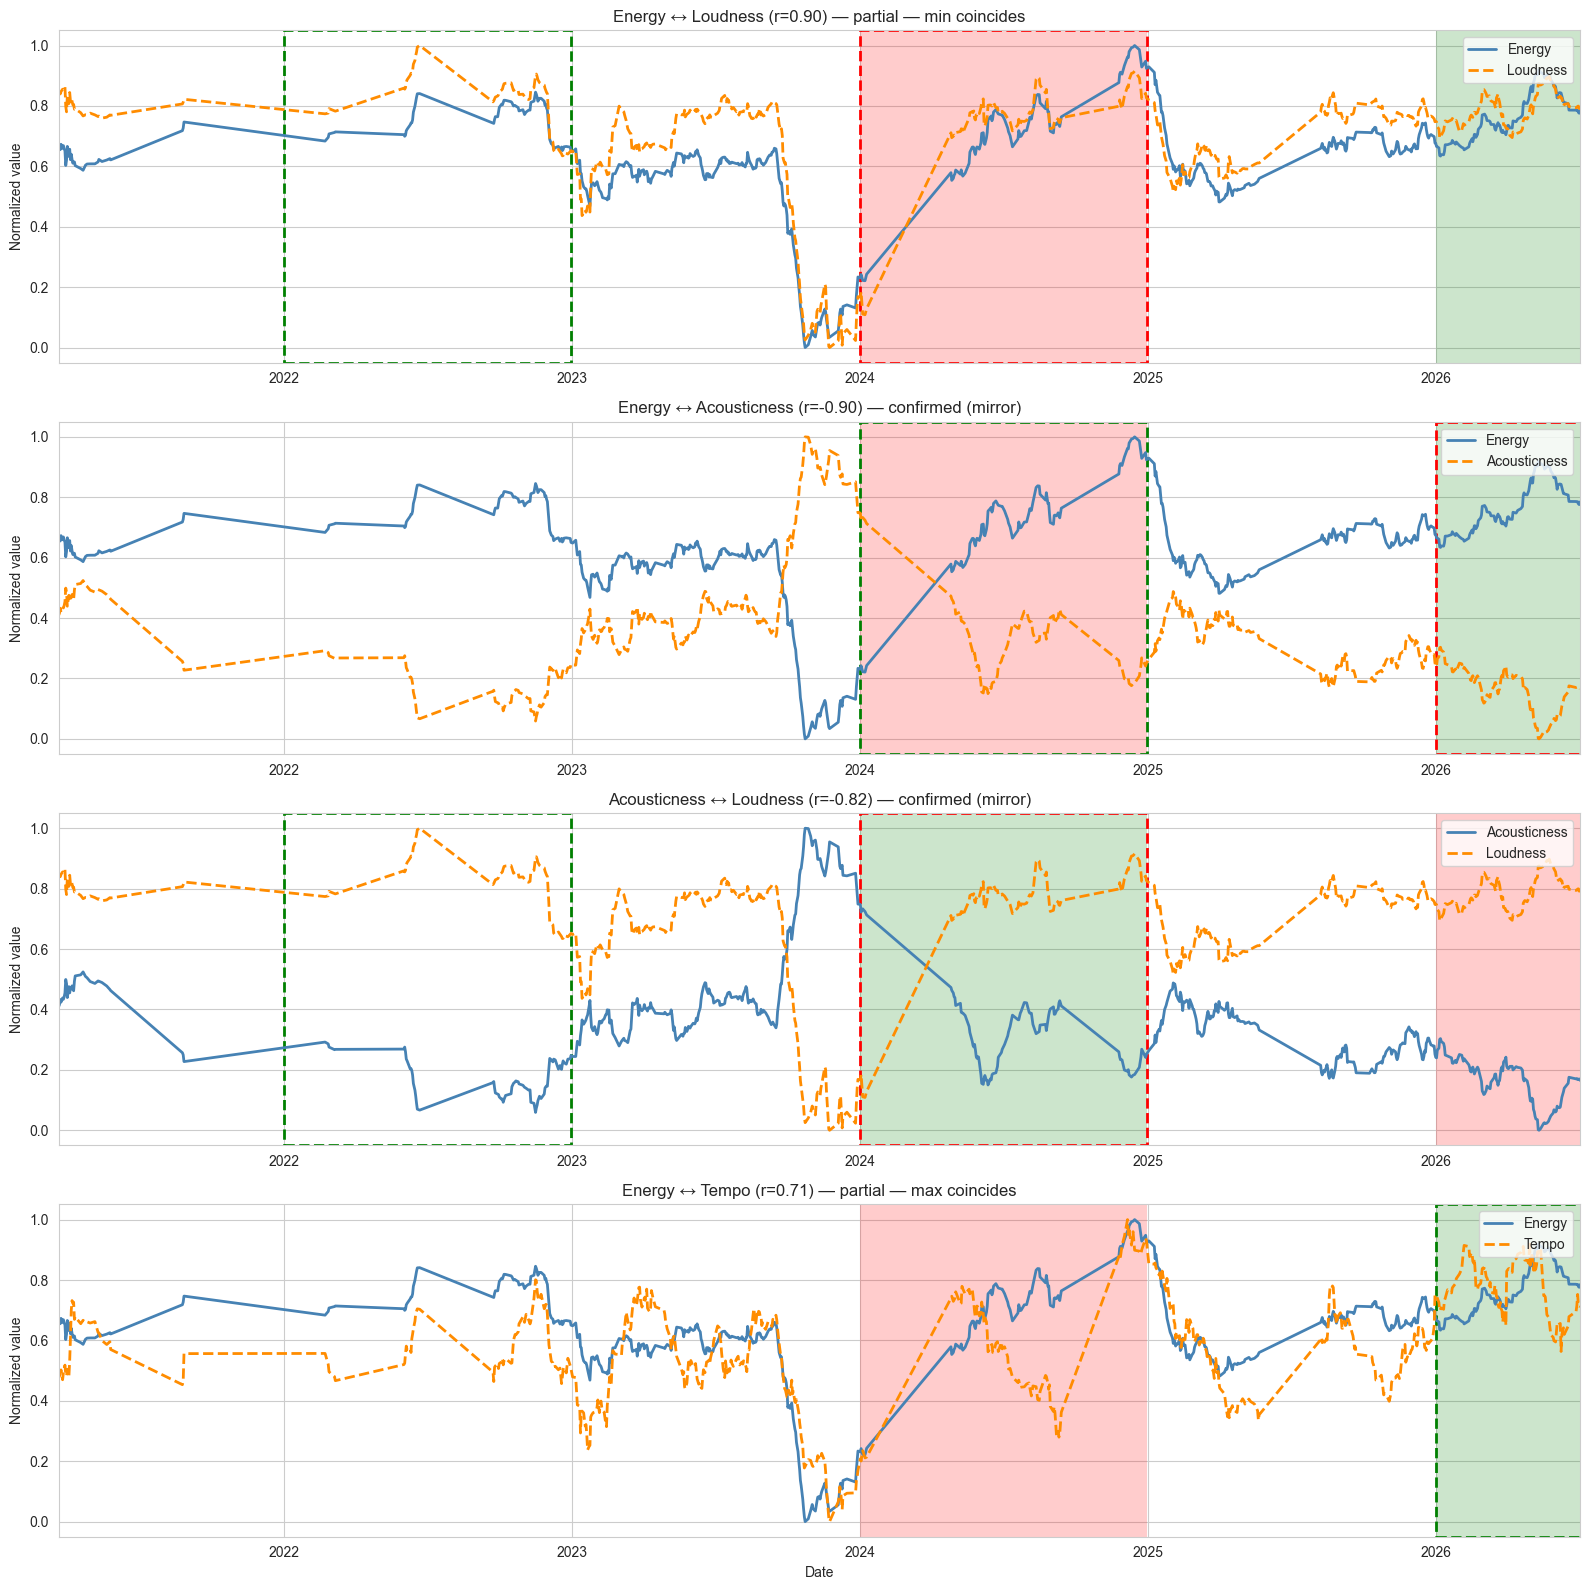


📊 Summary for pairs with |r| > 0.7:


,Pair,r,Verdict,Max (Energy),Min (Energy),Max (Loudness),Min (Loudness),Max (Acousticness),Min (Acousticness),Max (Tempo),Min (Tempo)
№,,,,,,,,,,,
1,Energy ↔ Loudness,0.90,partial — min coincides,2026 ⏳,2024,2022,2024,NaN,NaN,NaN,NaN
2,Energy ↔ Acousticness,-0.90,confirmed (mirror),2026 ⏳,2024,NaN,NaN,2024,2026 ⏳,NaN,NaN
3,Acousticness ↔ Loudness,-0.82,confirmed (mirror),NaN,NaN,2022,2024,2024,2026 ⏳,NaN,NaN
4,Energy ↔ Tempo,0.71,partial — max coincides,2026 ⏳,2024,NaN,NaN,NaN,NaN,2026 ⏳,2020 ⏳ ⚠️


trends range: 2021-03-21 — 2026-07-03
trends days: 729


In [169]:
# 2.4 Визуализация гипотез с |r| > 0.7

# Для каждой пары из strong_pairs (2.2) строим график:
#   - обе характеристики нормированы к [0, 1], чтобы можно было наложить;
#   - сплошная заливка — годы экстремумов первой характеристики (a);
#   - пунктирная рамка — годы экстремумов второй характеристики (b);
#   - зелёный — максимум, красный — минимум.
#
# Подсветка рисуется только если год экстремума попадает в диапазон
# trends. Экстремумы из yearly, которые не покрыты сглаженным рядом
# (2020 и часть 2026 из-за rolling(30)), не подсвечиваются — иначе
# рамка висит в области без данных.
#
# Вердикт совпадает с логикой 2.3:
#   r > 0: confirmed on both ends / partial (max|min) / diverge
#   r < 0: confirmed (mirror) / not mirrored
#
# Если экстремум приходится на неполный год (2020 или 2026), в подписи
# года добавляется флаг ⏳ — такой пик может быть артефактом обрезки.

# trends уже построен в 2.2 — используем его.
# strong_pairs тоже из 2.2.

if not strong_pairs:
    print('No pairs with |r| > 0.7 for visualization.')
else:
    # Диапазон лет, реально покрытый сглаженным рядом.
    trend_year_min = trends['date'].dt.year.min()
    trend_year_max = trends['date'].dt.year.max()
    print(f'ℹ️ trends covers years: {trend_year_min}–{trend_year_max}. '
          f'Extrema outside this range will not be highlighted.')

    fig, axes = plt.subplots(len(strong_pairs), 1, figsize=(16, 4 * len(strong_pairs)))
    if len(strong_pairs) == 1:
        axes = [axes]

    summary_rows = []
    for idx, (a, b, r) in enumerate(strong_pairs):
        ax = axes[idx]

        # Нормируем обе характеристики к [0, 1], чтобы наложить на одном графике.
        norm_a = (trends[a] - trends[a].min()) / (trends[a].max() - trends[a].min())
        norm_b = (trends[b] - trends[b].min()) / (trends[b].max() - trends[b].min())

        ax.plot(trends['date'], norm_a, color='steelblue', linewidth=2, label=a)
        ax.plot(trends['date'], norm_b, color='darkorange', linewidth=2,
                linestyle='--', label=b)

        # Названия характеристик в peak_dict — английские без _mean.
        name_a = a if a in peak_dict else a.replace('_mean', '').capitalize()
        name_b = b if b in peak_dict else b.replace('_mean', '').capitalize()

        max_a, min_a = peak_dict[name_a]
        max_b, min_b = peak_dict[name_b]

        # --- Подсветка экстремумов ---
        # Первая характеристика (a): сплошная заливка.
        # Вторая (b): только пунктирная рамка — чтобы полосы не перекрывались.
        # Рисуем только те годы, что попадают в диапазон trends.
        for yr, color in [(max_a, 'green'), (min_a, 'red')]:
            if trend_year_min <= yr <= trend_year_max:
                ax.axvspan(pd.Timestamp(f'{yr}-01-01'), pd.Timestamp(f'{yr}-12-31'),
                           alpha=0.20, color=color, linewidth=0)
        for yr, color in [(max_b, 'green'), (min_b, 'red')]:
            if trend_year_min <= yr <= trend_year_max:
                ax.axvspan(pd.Timestamp(f'{yr}-01-01'), pd.Timestamp(f'{yr}-12-31'),
                           fill=False, edgecolor=color, linewidth=2, linestyle='--')

        # --- Вердикт: та же логика, что в 2.3 ---
        if r > 0:
            max_match = (max_a == max_b)
            min_match = (min_a == min_b)
            if max_match and min_match:
                verdict = 'confirmed on both ends'
            elif max_match:
                verdict = 'partial — max coincides'
            elif min_match:
                verdict = 'partial — min coincides'
            else:
                verdict = 'diverge'
        else:
            mirror = (max_a == min_b or min_a == max_b)
            verdict = 'confirmed (mirror)' if mirror else 'not mirrored'

        # Флаги: ⏳ — неполный год, ⚠️ — год вне диапазона сглаженного ряда.
        def _flag(yr):
            flags = ''
            if yr in incomplete_years:
                flags += ' ⏳'
            if yr < trend_year_min or yr > trend_year_max:
                flags += ' ⚠️'
            return flags

        ax.set_title(f'{a} ↔ {b} (r={r:.2f}) — {verdict}', fontsize=12)
        ax.legend(loc='upper right')
        ax.set_ylabel('Normalized value')
        ax.set_xlim(trends['date'].min(), trends['date'].max())

        summary_rows.append({
            'Pair': f'{a} ↔ {b}',
            'r': round(r, 2),
            'Verdict': verdict,
            f'Max ({a})': f'{max_a}{_flag(max_a)}',
            f'Min ({a})': f'{min_a}{_flag(min_a)}',
            f'Max ({b})': f'{max_b}{_flag(max_b)}',
            f'Min ({b})': f'{min_b}{_flag(min_b)}',
        })

    plt.xlabel('Date')
    plt.tight_layout()
    plt.show()

    summary_df = pd.DataFrame(summary_rows)
    summary_df.index = summary_df.index + 1
    summary_df.index.name = '№'
    print('\n📊 Summary for pairs with |r| > 0.7:')
    display(summary_df)

print(f'trends range: {trends["date"].min().date()} — {trends["date"].max().date()}')
print(f'trends days: {len(trends)}')    

### Вывод по блоку 2.4

Графики показывают форму связи, а не только её наличие. Для каждой пары
видны два конца: где линии сходятся и где расходятся. Картина разная
для отрицательных и положительных пар.

**Отрицательные пары работают как зеркало.** Energy ↔ Acousticness
(r=−0.90) — самая чистая пара из четырёх. Кривые симметричны: когда
energy падает, acousticness растёт, и наоборот. Оба экстремума парные —
в 2026 energy max совпадает с acousticness min, в 2024 energy min
совпадает с acousticness max. Acousticness ↔ Loudness (r=−0.82) даёт
ту же картину на нижнем конце: в 2024 максимум acousticness совпадает
с минимумом loudness. На верхнем конце зеркало только в одну сторону:
acousticness min в 2026 не находит парного loudness max — громкость
восстановилась раньше, ещё в 2022.

**Положительные пары асимметричны: синхронны внизу, расходятся
вверху.** Energy ↔ Loudness (r=0.90) совпадает на минимуме — в 2024
обе характеристики одновременно уходят вниз, красные полосы стоят
в одном году. На максимуме они расходятся: energy достигает пика
в 2026, loudness — в 2022. Energy ↔ Tempo (r=0.71) даёт ту же
картину в обратную сторону: max совпадает (оба 2026), min расходится
(energy в 2024, tempo в 2020).

**Что за этим стоит.** Разные характеристики проходят цикл в разное
время. Tempo проваливается раньше всех — ещё в 2020. Loudness
восстанавливается первым — в 2022. Energy отстаёт на обоих концах:
падает в 2024 вместе с loudness, а наверх возвращается только
к 2026. В 2024 профиль синхронно проседает по energy, loudness
и tempo — это и есть синхронный провал. Возвращение наверх идёт
вразнобой: громкость раньше, energy и tempo позже.

**Ограничение по краям диапазона.** Сглаженный ряд `trends` покрывает
2021-03 — 2026-07, потому что `rolling(30, center=True)` требует
30 точек, а `daily` за 2020 содержит всего 25 дней. Всё, что лежит
за пределами этого диапазона — min tempo 2020, часть max energy
и max tempo 2026 — на графике не подсвечивается: данных для сравнения
там нет. Эти экстремумы взяты из годовой агрегации `yearly`, где
2020 и 2026 присутствуют, но как год целиком, а не как 30-дневное
сглаживание. Наложение двух метрик на одном графике некорректно,
поэтому такие точки в 2.4 не визуализируются — они помечены ⚠️
в сводной таблице и остаются предметом проверки в 3.5.

**Что подтверждено и что нет.** Отрицательные пары подтверждены
надёжно: их зеркальность видна на обоих концах, и хотя бы один конец
приходится на полный год (2024 у Acousticness↔Loudness). Положительные
пары подтверждены только на нижнем конце — синхронный провал 2024
воспроизводится чётко, а расхождение максимумов означает, что связь
на верхнем конце слабее, чем на нижнем. Это не «провал проверки»,
а свойство самих данных: внизу профиль движется согласованно,
наверху — нет.

## 2.5 Sanity check: методологические и культурные связи


In [170]:
# 2.5 Sanity check: ожидаемые связи и пары без документированного механизма

# Две группы пар:
#
# ОЖИДАЕМЫЕ СВЯЗИ — пары, для которых есть документированная или
# конвенциональная причина ожидать связь:
#   - feature construction: Spotify описывает "perceived loudness"
#     как один из воспринимаемых компонентов, формирующих energy;
#   - production convention: акустические записи миксуются тише,
#     без сильной компрессии;
#   - perceptual association: быстрая музыка воспринимается
#     как энергичная.
# Если ожидаемая связь не подтверждается на этих данных — сигнал,
# что признаки считаются иначе, чем заявлено, или каталог нетипичен.
#
# ДОПОЛНИТЕЛЬНЫЕ ПАРЫ — сильные связи в трендах, для которых нет
# документированной причины. Мы их наблюдаем, но не можем на этих
# данных определить, отражают ли они устройство каталога Spotify
# в целом или личный профиль пользователя. Для такого различения
# нужен внешний источник (публичные датасеты Spotify-треков),
# которого в этом проекте нет.

expected_links = [
    ('Energy', 'Loudness', 'positive'),
    ('Energy', 'Acousticness', 'negative'),
    ('Acousticness', 'Loudness', 'negative'),
    ('Energy', 'Tempo', 'positive'),
]

# Единый порог для всех ожидаемых связей. Все четыре относятся
# к одной категории — вводить per-pair исключения без обоснования
# смысла нет.
EXPECTED_THRESHOLD = 0.7

expected_reasons = {
    ('Energy', 'Loudness'):
        'feature construction — Spotify documents perceived loudness as one '
        'of the perceptual components of energy',
    ('Energy', 'Acousticness'):
        'production convention — acoustic tracks are typically mixed quieter '
        'and less compressed',
    ('Acousticness', 'Loudness'):
        'production convention — acoustic instruments tend to sit lower in the mix',
    ('Energy', 'Tempo'):
        'perceptual association — faster music tends to be perceived as more energetic',
}

additional_pairs = [
    ('Danceability', 'Popularity'),
    ('Valence', 'Instrumentalness'),
]

# --- Проверка ожидаемых связей ---
print('🔍 Expected links check (threshold |r| > 0.7):')
for a, b, expected_direction in expected_links:
    r = corr_trends.loc[a, b]
    if expected_direction == 'positive':
        ok = r >= EXPECTED_THRESHOLD
    else:
        ok = r <= -EXPECTED_THRESHOLD
    status = '✅ confirmed' if ok else '⚠️ below expected'
    reason = expected_reasons.get((a, b), '')
    print(f'   {a} ↔ {b}: r={r:.2f} [{status}]')
    print(f'      → {reason}')

# --- Дополнительные пары ---
# Смотрим силу и знак, но не приписываем их ни каталогу, ни пользователю:
# на этих данных различие не проверяется.
print('\n🔍 Additional pairs (no documented mechanism):')
for a, b in additional_pairs:
    r = corr_trends.loc[a, b]
    direction = 'positive' if r > 0 else 'negative'
    strength = 'weak' if abs(r) < 0.4 else 'moderate'
    print(f'   {a} ↔ {b}: r={r:.2f} [{strength} {direction}]')

print('\n📝 Conclusion:')
print('   Expected links confirmed — feature construction and production')
print('   conventions behave as expected in this corpus.')
print('   Additional pairs are reported as observations only. Whether they')
print('   reflect the Spotify catalog at large or this user\'s personal profile')
print('   is not decidable from a single-user history.')

🔍 Expected links check (threshold |r| > 0.7):
   Energy ↔ Loudness: r=0.90 [✅ confirmed]
      → feature construction — Spotify documents perceived loudness as one of the perceptual components of energy
   Energy ↔ Acousticness: r=-0.90 [✅ confirmed]
      → production convention — acoustic tracks are typically mixed quieter and less compressed
   Acousticness ↔ Loudness: r=-0.82 [✅ confirmed]
      → production convention — acoustic instruments tend to sit lower in the mix
   Energy ↔ Tempo: r=0.71 [✅ confirmed]
      → perceptual association — faster music tends to be perceived as more energetic

🔍 Additional pairs (no documented mechanism):
   Danceability ↔ Popularity: r=-0.32 [weak negative]
   Valence ↔ Instrumentalness: r=-0.54 [moderate negative]

📝 Conclusion:
   Expected links confirmed — feature construction and production
   conventions behave as expected in this corpus.
   Additional pairs are reported as observations only. Whether they
   reflect the Spotify catalog at la

### 2.5. Вывод

Проверка опирается на заранее зафиксированный список из четырёх пар:
Energy ↔ Loudness, Energy ↔ Acousticness, Acousticness ↔ Loudness,
Energy ↔ Tempo. Для каждой пары заранее указан ожидаемый знак связи
и причина, по которой связь должна присутствовать в любом корпусе
Spotify-данных. Задача проверки — не найти связи, а подтвердить,
что заданные связи воспроизводятся.

Все четыре подтверждены при едином пороге |r| > 0.7: Energy ↔ Loudness
(r=0.90), Energy ↔ Acousticness (r=−0.90), Acousticness ↔ Loudness
(r=−0.82), Energy ↔ Tempo (r=0.71). Это контроль целостности:
если бы заданная связь не подтвердилась, это был бы сигнал о сбое
в данных, а не об уникальном вкусе.

Причины у этих связей разные. Energy ↔ Loudness — конструирование
признака: по документации Spotify API, «perceived loudness» входит
в число воспринимаемых компонентов, формирующих energy. Это
единственная из четырёх, подкреплённая внешним источником.
Energy ↔ Acousticness и Acousticness ↔ Loudness — предположительно
конвенция продакшена: акустические записи обычно миксуются тише
и без компрессии. Energy ↔ Tempo — предположительно перцептивная
ассоциация: быстрая музыка обычно воспринимается как более
энергичная. Обе последние причины правдоподобны, но не проверены
в этом проекте — это гипотезы, объясняющие ожидаемую связь, а не
установленные механизмы. Для Energy ↔ Acousticness и Acousticness ↔
Loudness источник проверяем через литературу по звукорежиссуре,
для Energy ↔ Tempo — через психоакустику; в этом проекте такого
сопоставления не делалось.

Отдельно фиксируются две пары, для которых ожидаемый знак и причина
не заданы заранее: Danceability ↔ Popularity (r=−0.32) и
Valence ↔ Instrumentalness (r=−0.54). Обе отрицательные. На этих
данных нельзя определить, отражают ли они устройство каталога Spotify
в целом или личный профиль пользователя: `corr_trends` построен
только на истории одного человека, внешнего источника для сравнения
нет. Чтобы развести эти два объяснения, нужен отдельный датасет —
публичные Spotify-треки или данные других пользователей, — в этом
проекте их нет.

Поэтому такие пары фиксируются осторожно: как наблюдения
без приписанной причины, а не как «паттерны экосистемы».
Число r=−0.32 говорит: в трендах пользователя популярность
и танцевальность движутся слабо в противоположные стороны. Всё.
Причину — платформа, личный выбор, случайность — эти данные
не различают.

**Что это даёт.** Контроль целостности пройден, ожидаемые связи
ведут себя так, как предсказывает механизм. Найденные ранее связи
можно принимать как данность — они не артефакт повреждённых данных.
Дополнительные пары остаются открытыми: их интерпретация требует
данных, которых в проекте нет.

**Ограничение.** Классификация пар задана заранее, на основе
документации Spotify и известных конвенций продакшена. Это
осознанный sanity check, а не автоматическое правило. Если
в данных появится новая сильная связь, не подпадающая ни под одну
категорию, — это сигнал расширить классификацию с явным
обоснованием, а не игнорировать её.

## Блок 2. Вывод

За шесть лет профиль сместился в сторону инструментальности и тишины,
но не однородно. Сдвиг согласованный по шести характеристикам, два
показателя идут слабо в противоположную сторону. Связи между
характеристиками плотные, но работают асимметрично: внизу диапазона
профиль движется синхронно, наверху — расходится. Есть один год
синхронного провала — 2024.

---

**Сдвиг по средним**

Сильнее всего выросла instrumentalness (+0.112 — вдвое выше порога
сильного сдвига). Согласованно с ней двинулись valence (−0.043),
danceability (−0.044), energy (−0.031), acousticness (+0.036)
и loudness (−1.565 дБ). Tempo (+0.837 BPM) и popularity (+1.715)
идут в противоположную сторону, но слабо. Liveness не изменился.

Сдвиг фоновый: расхождение среднего и медианы мало для всех
характеристик. Меняется центр распределения, не хвосты. Пользователь
не сменил жанр — он двинулся от более яркого края своей звуковой
зоны к более тихому.

---

**Корреляции**

28 пар с |r| > 0.3 — плотная сетка. Ядро из четырёх: Energy ↔
Loudness (0.90), Energy ↔ Acousticness (−0.90), Acousticness ↔
Loudness (−0.82), Energy ↔ Tempo (0.71). Три из четырёх — одна
ось: энергичное, громкое и быстрое вместе, акустичное напротив.
Valence, danceability и speechiness подтягиваются к этой оси
через средний слой; instrumentalness стоит особняком.

---

**Асимметрия положительных связей**

Отрицательные пары подтверждаются на обоих концах диапазона —
работают как зеркало. Положительные — только на одном.
Energy ↔ Loudness совпадает на минимуме (2024 у обоих) и расходится
на максимуме (2026 vs 2022). Energy ↔ Tempo — наоборот, совпадает
на максимуме (2026) и расходится на минимуме (2024 vs 2020).

Это не провал проверки, а форма связи: внизу профиль движется
согласованно, наверху — нет. Годы максимумов различаются:
у громкости — 2022, у energy и tempo — 2026.

---

**Синхронный провал 2024**

Energy, loudness и tempo уходят вниз одновременно в один год.
По нескольким характеристикам сразу — минимум за период. Это
самое сильное событие в динамике профиля за шесть лет.

---

**Контроль целостности**

Все четыре ожидаемые связи, заданные заранее, подтверждаются
при едином пороге |r| > 0.7. Уровень опоры причин разный.
Energy ↔ Loudness — конструирование признака, подкреплено
документацией Spotify API. Energy ↔ Acousticness и Acousticness ↔
Loudness — предположительно конвенция продакшена, Energy ↔ Tempo —
предположительно перцептивная ассоциация. Последние три
в этом проекте не проверялись.

Две пары без заданного механизма — Danceability ↔ Popularity
(−0.32) и Valence ↔ Instrumentalness (−0.54) — остаются
наблюдениями. По истории одного пользователя нельзя определить,
отражают они каталог Spotify или личный профиль.

---

**Ограничение**

Корреляции посчитаны на 30-дневных сглаженных рядах. Сглаживание
завышает Пирсона (эффект Юла–Слуцкого) — значения отражают
согласованность долгосрочных движений, а не силу связи на дневном
уровне.

Диапазон сглаженного ряда 2021-03 — 2026-07: 2020 и часть 2026
в него не попадают из-за `rolling(30)`. Экстремумы этих лет
на графиках не подсвечиваются и остаются предметом отдельной
проверки.

# Блок 3. Календарные аномалии

## 3. Календарные аномалии

Блок 2 дал общий вектор за шесть лет — сдвиг от энергичной музыки
к тихой и инструментальной. Это средний тренд. Он не отвечает
на вопрос, где именно тренд сломался и были ли точки, резко
выбивавшиеся из общего движения. Блок 3 ищет такие точки.

**Методология.** Аномалия — это значение, которое сильно отклоняется
от типичного для этого же ряда. В аудио-характеристиках аномалии
могут быть трёх масштабов: год целиком отличается от остальных лет,
месяц отличается от остальных месяцев, отдельный переход между
соседними месяцами резче обычного. Плюс — устойчивое направленное
движение, которое само по себе не аномалия, но заслуживает фиксации,
потому что это уже не шум, а тренд.

Отсюда четыре типа сигналов, которые ищет блок:

- **IQR-выбросы по годам.** Для каждой характеристики считаются
  средние по годам, затем квантили Q1 и Q3. Год считается аномальным,
  если его среднее лежит ниже Q1 − 1.5×IQR или выше Q3 + 1.5×IQR.
  Порог 1.5 взят как общепринятая эвристика Тьюки — она не выведена
  из распределения, а зафиксирована как стандарт для отделения
  выбросов от естественного разброса. На 5–7 точках (столько полных
  лет в данных) IQR нестабилен: один год сдвигает Q1 или Q3,
  и порог меняется. Выброс здесь — сигнал «год выбивается заметно
  сильнее остальных», а не статистически строгая аномалия.

- **IQR-выбросы по месяцам.** То же правило, но агрегация
  по календарным месяцам (январь, февраль, …) за все годы.
  Здесь точек больше — 12 месяцев × 5–7 лет, — поэтому IQR
  устойчивее. Ищутся сезонные аномалии: например, «март всегда
  ниже остальных месяцев».

- **Устойчивые тренды.** Последовательные периоды роста или падения
  между годами длиной ≥2 лет. Одиночный скачок — это шум,
  а два-три года в одном направлении — уже тенденция. Длина ≥2 лет
  выбрана как компромисс: на 5–7 точках более жёсткий порог
  оставил бы слишком мало трендов, более мягкий — пропустил бы шум.

- **Контрастные переходы.** Резкие смены значения между соседними
  месяцами внутри одного года. Порог — разница больше 2σ медианного
  стандартного отклонения по месяцам. Как и 1.5×IQR выше, это
  эвристика, а не выведенный критерий: 2σ соответствует примерно
  5% самых больших отклонений при нормальном распределении, но
  на реальных данных это не строгий тест. Ловит локальные сдвиги
  вроде «в марте было 0.15, в апреле 0.72» — то, что годовые
  средние сглаживают.

**Почему именно эти четыре.** Первые два — про уровень (год или
месяц выбивается по среднему). Третий — про направление (не уровень,
а последовательное движение). Четвёртый — про резкость (не уровень
и не направление, а скорость смены). Все четыре ищутся одновременно,
потому что разные характеристики могут проявляться по-разному:
у одной будет годовой выброс, у другой — устойчивый тренд,
у третьей — резкий переход.

**Отдельная проверка — надёжность карт.** Средние чувствительны
к хвостам: если в месяце много коротких событий с экстремальными
значениями, среднее уедет, а медиана останется. Поэтому параллельно
считается медиана, и если расхождение больше 5% от шкалы
характеристики — ячейка помечает карту как «тенденция, не точное
значение». Это защита от ложных аномалий, созданных скошенностью.

**Как устроен конвейер.** Пять ячеек идут последовательно.

- **3.1** генерирует гипотезы: для каждой из 10 характеристик —
  свой список сигналов четырёх типов.
- **3.2** собирает все гипотезы в один датафрейм, приводит
  к единой метрике «Сила» и отбирает топ-5.
- **3.3** считает концентрацию силы по годам: если один год даёт
  больше 35% — он идёт на детальный разбор в 3.4.
- **3.4** сравнивает год-лидер с фоном по средним и медианам,
  строит range plot, смотрит жанры и суточный профиль.
- **3.5** точечно проверяет каждую из топ-5 гипотез в окне,
  соответствующем её типу.

**Что блок даёт на выходе.** Конкретные ответы: какие годы аномальны,
какие месяцы, где были резкие переходы, какой год выделяется
сильнее всего. В нашем случае — 2024 как год синхронного провала
и 2021 как противоположный полюс.

## 3.1 Календарные тепловые карты

### 3.1 Календарные тепловые карты

Для каждой из 10 аудио-характеристик строится тепловая карта
«месяц × год» по событиям Deep dive. Значения в ячейках — средние
за месяц. Звёздочка (`*`) у числа означает, что событий в этом месяце
меньше 20 — значение менее надёжно.

После карты ячейка автоматически ищет IQR-выбросы по годам и месяцам,
устойчивые тренды и контрастные переходы. Каждая находка превращается
в гипотезу для дальнейшего разбора.

Отдельно проверяется расхождение среднего и медианы по каждой ячейке.
Если расхождение больше 5% от шкалы характеристики, выводится
предупреждение: среднее может быть смещено скошенностью,
и карту надо читать как общую тенденцию, а не как точное значение.

ℹ️ Incomplete years: [2020, 2026] — interpret with caution.

   Valence


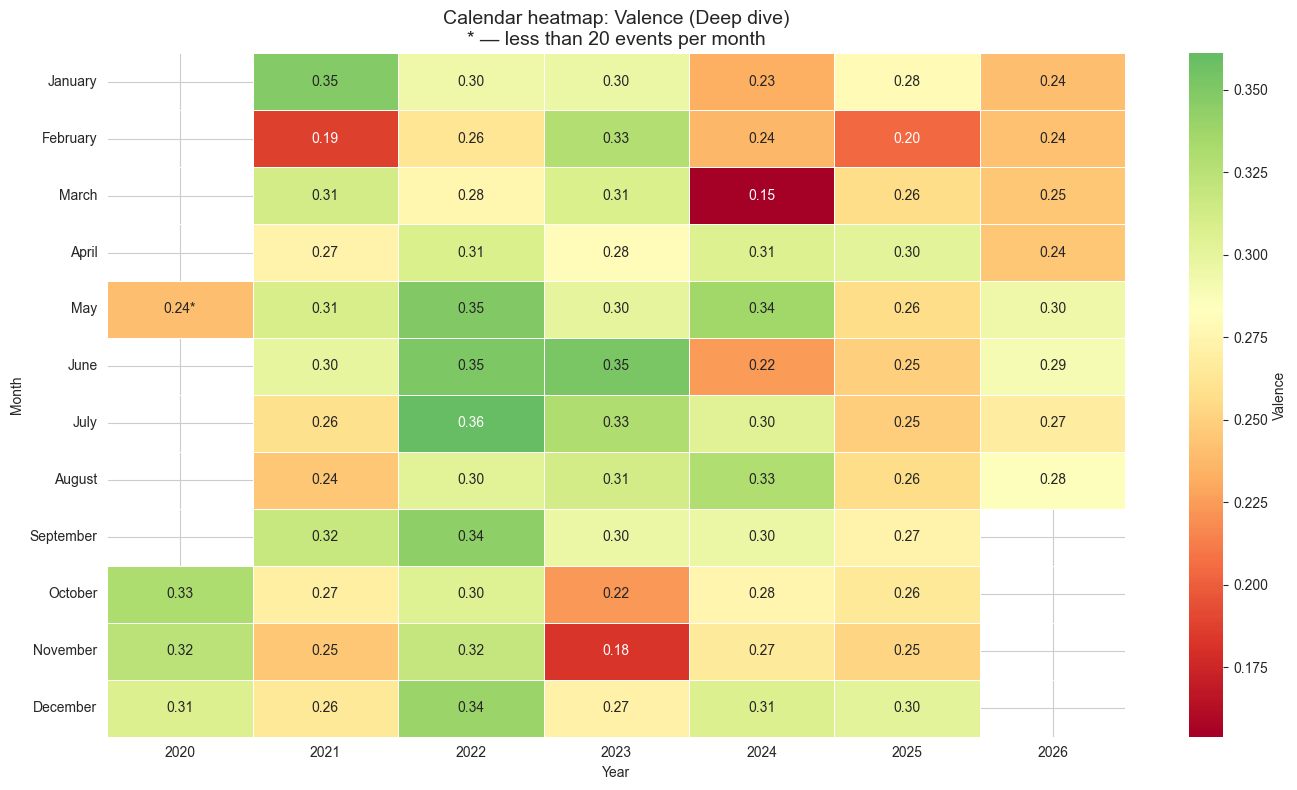

📊 Mean Valence by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.349,0.295,0.296,0.232,0.279,0.240
February,NaN,0.187,0.263,0.328,0.236,0.204,0.242
March,NaN,0.312,0.276,0.308,0.154,0.256,0.245
April,NaN,0.272,0.308,0.280,0.305,0.301,0.245
May,0.240,0.310,0.350,0.300,0.337,0.257,0.295
June,NaN,0.299,0.351,0.353,0.224,0.250,0.291
July,NaN,0.259,0.361,0.330,0.304,0.248,0.268
August,NaN,0.244,0.304,0.313,0.330,0.256,0.285
September,NaN,0.318,0.345,0.296,0.296,0.273,NaN
October,0.331,0.270,0.305,0.223,0.275,0.264,NaN


⚠️ Valence: 2 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Valence:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
      2025–2026: growth
   ⚡ Contrast transitions (>2σ):
      2021: January → February (Δ=0.161)
      2024: March → April (Δ=0.151)

🎯 Hypotheses to check:
   1. Stable trend — verify Valence evolution across the period.
   2. Contrast transitions — check sharp Valence shifts within years.

   Energy


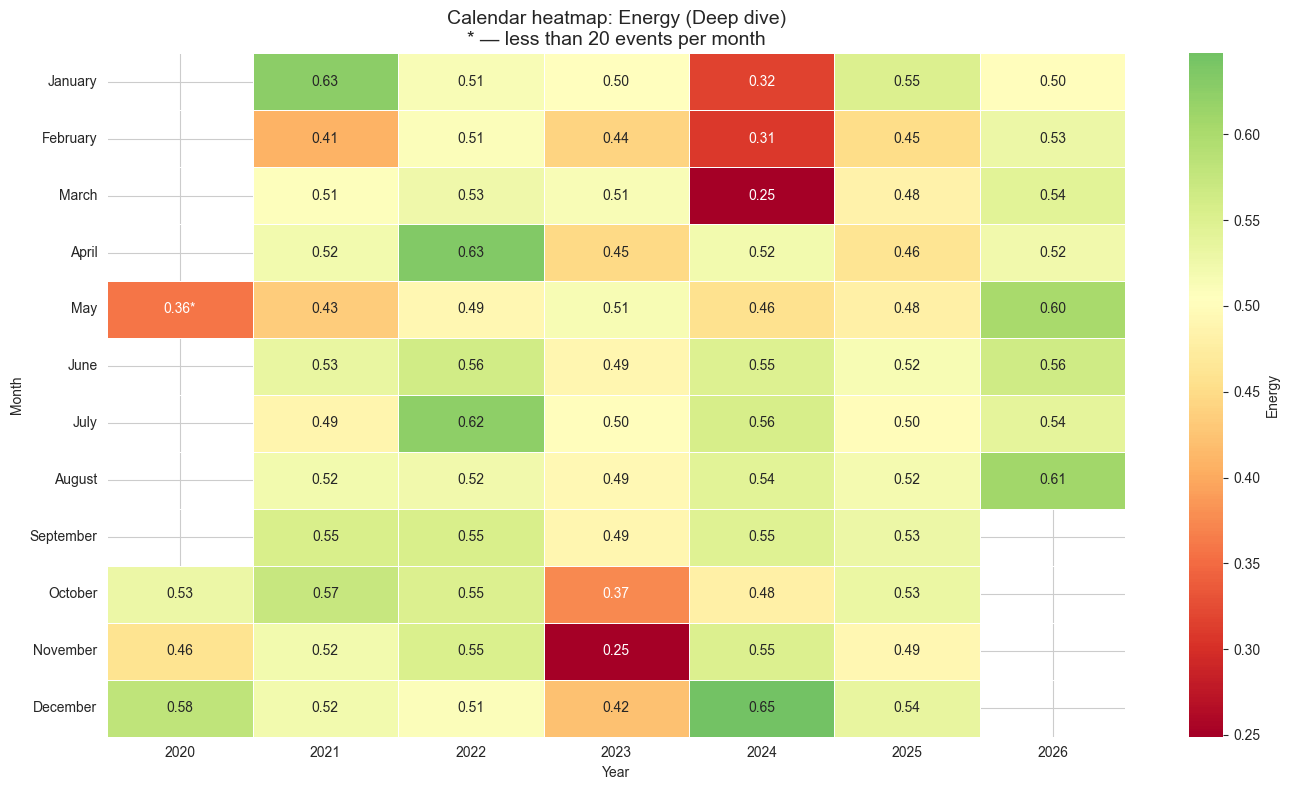

📊 Mean Energy by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.627,0.513,0.503,0.317,0.552,0.502
February,NaN,0.408,0.510,0.441,0.309,0.452,0.531
March,NaN,0.507,0.526,0.513,0.251,0.483,0.543
April,NaN,0.522,0.634,0.447,0.520,0.461,0.524
May,0.359,0.433,0.491,0.514,0.456,0.481,0.603
June,NaN,0.533,0.562,0.489,0.548,0.516,0.563
July,NaN,0.488,0.625,0.502,0.556,0.498,0.539
August,NaN,0.520,0.524,0.494,0.542,0.518,0.608
September,NaN,0.554,0.554,0.490,0.547,0.528,NaN
October,0.528,0.572,0.549,0.374,0.480,0.531,NaN


⚠️ Energy: 6 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Energy:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
      2025–2026: growth
   ⚡ Contrast transitions (>2σ):
      2021: January → February (Δ=0.219)
      2024: March → April (Δ=0.269)

🎯 Hypotheses to check:
   1. Stable trend — verify Energy evolution across the period.
   2. Contrast transitions — check sharp Energy shifts within years.

   Danceability


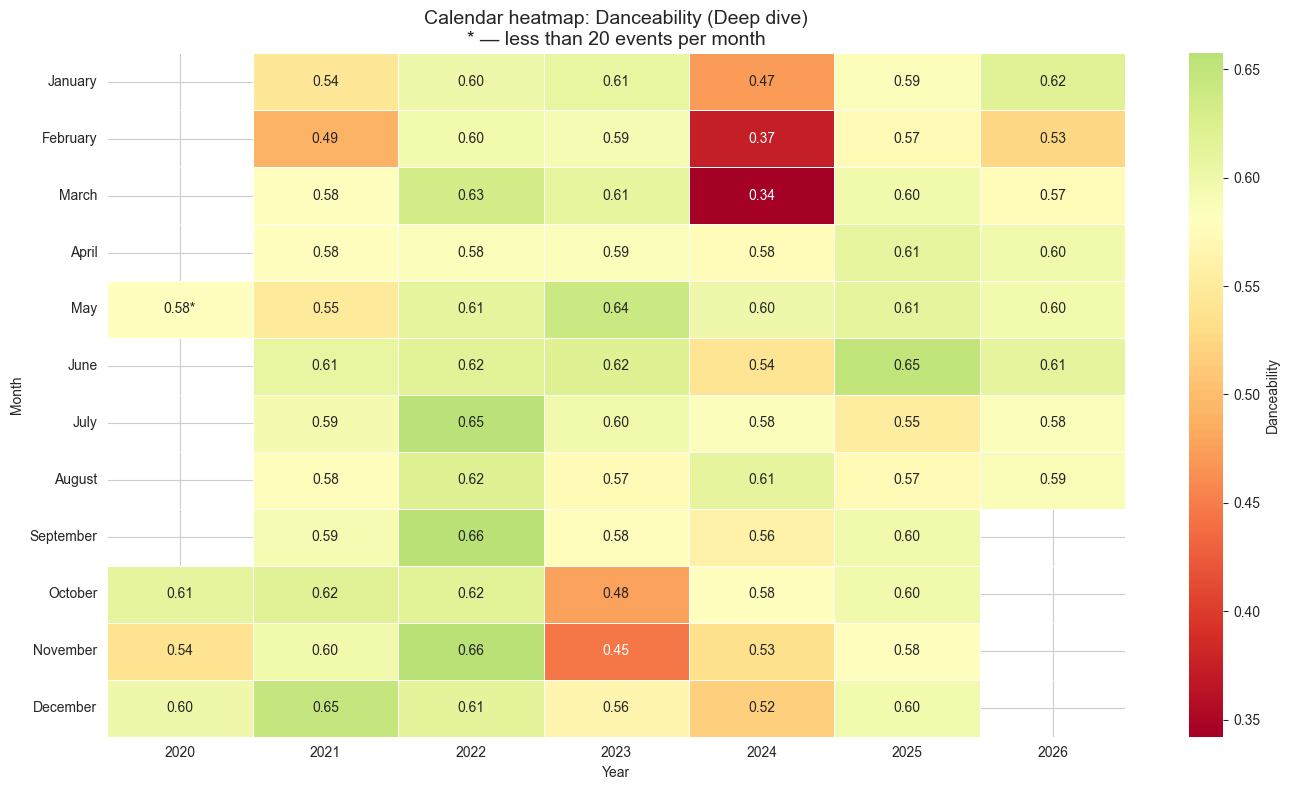

📊 Mean Danceability by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.544,0.600,0.607,0.472,0.586,0.619
February,NaN,0.491,0.596,0.592,0.373,0.572,0.525
March,NaN,0.580,0.631,0.609,0.342,0.598,0.573
April,NaN,0.581,0.584,0.586,0.576,0.608,0.598
May,0.581,0.548,0.611,0.641,0.600,0.612,0.597
June,NaN,0.607,0.617,0.621,0.541,0.651,0.611
July,NaN,0.593,0.655,0.598,0.584,0.551,0.585
August,NaN,0.577,0.620,0.572,0.611,0.572,0.588
September,NaN,0.591,0.657,0.577,0.560,0.597,NaN
October,0.610,0.619,0.616,0.477,0.582,0.597,NaN


⚠️ Danceability: 3 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Danceability:
   📈 No significant high years.
   📉 Low years (IQR outliers): {2024: 0.467}
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
   ⚡ Contrast transitions (>2σ):
      2024: March → April (Δ=0.233)

🎯 Hypotheses to check:
   1. Low years [2024] — investigate Danceability decline.
   2. Stable trend — verify Danceability evolution across the period.
   3. Contrast transitions — check sharp Danceability shifts within years.

   Acousticness


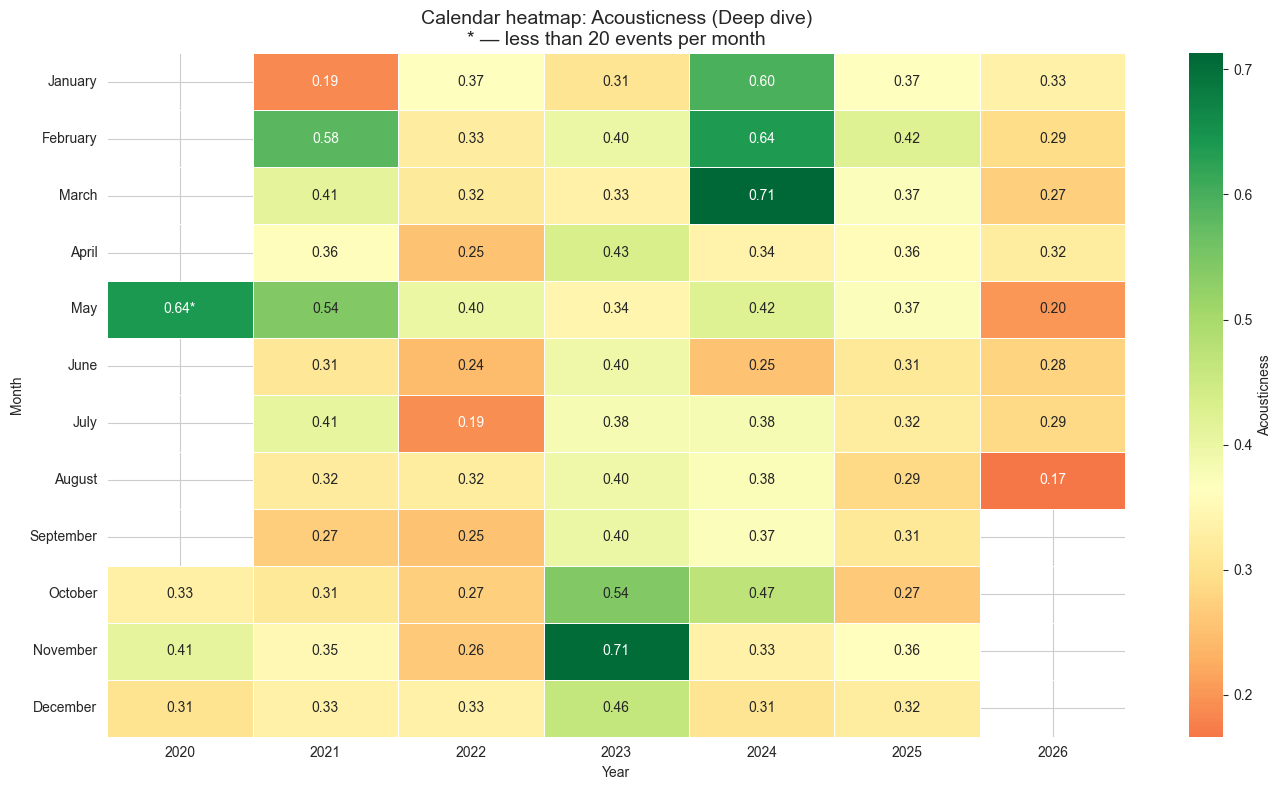

📊 Mean Acousticness by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.187,0.366,0.306,0.596,0.365,0.332
February,NaN,0.584,0.327,0.399,0.638,0.423,0.293
March,NaN,0.413,0.318,0.333,0.713,0.371,0.272
April,NaN,0.360,0.252,0.432,0.337,0.356,0.324
May,0.640,0.543,0.399,0.341,0.425,0.371,0.200
June,NaN,0.311,0.243,0.395,0.253,0.315,0.278
July,NaN,0.406,0.194,0.380,0.382,0.321,0.288
August,NaN,0.320,0.323,0.395,0.375,0.287,0.166
September,NaN,0.269,0.253,0.399,0.370,0.314,NaN
October,0.330,0.312,0.274,0.542,0.473,0.265,NaN


⚠️ Acousticness: 12 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Acousticness:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: growth
      2025–2026: decline
   ⚡ Contrast transitions (>2σ):
      2021: January → February (Δ=0.397)
      2024: March → April (Δ=0.376)

🎯 Hypotheses to check:
   1. Stable trend — verify Acousticness evolution across the period.
   2. Contrast transitions — check sharp Acousticness shifts within years.

   Instrumentalness


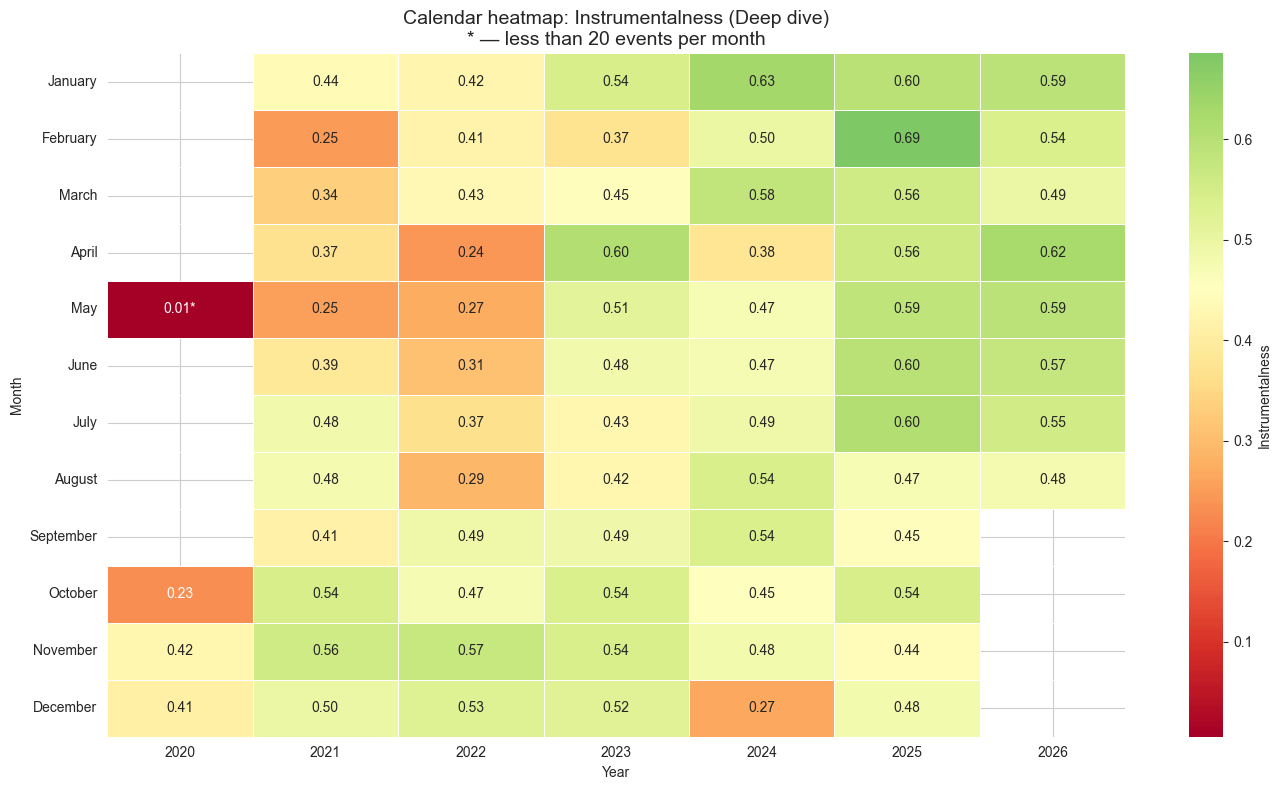

📊 Mean Instrumentalness by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.436,0.420,0.543,0.630,0.596,0.591
February,NaN,0.250,0.415,0.373,0.497,0.685,0.538
March,NaN,0.337,0.432,0.447,0.584,0.556,0.495
April,NaN,0.372,0.242,0.603,0.380,0.561,0.623
May,0.006,0.254,0.273,0.514,0.469,0.586,0.592
June,NaN,0.385,0.306,0.485,0.474,0.597,0.575
July,NaN,0.485,0.366,0.427,0.492,0.604,0.553
August,NaN,0.476,0.289,0.424,0.540,0.472,0.477
September,NaN,0.411,0.490,0.488,0.539,0.448,NaN
October,0.233,0.545,0.474,0.536,0.453,0.543,NaN


⚠️ Instrumentalness: 14 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Instrumentalness:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: growth
   ⚡ No contrast transitions.

🎯 Hypotheses to check:
   1. Stable trend — verify Instrumentalness evolution across the period.

   Liveness


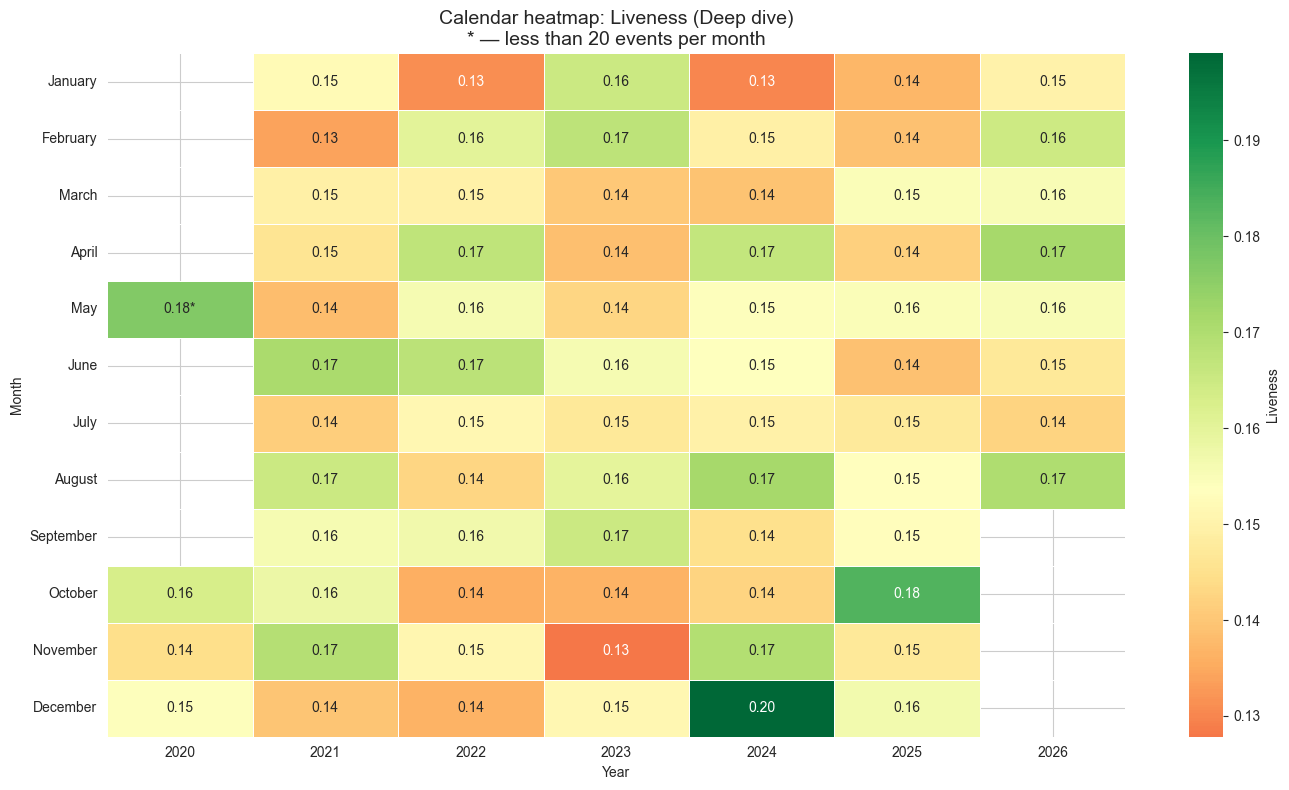

📊 Mean Liveness by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.152,0.131,0.165,0.130,0.137,0.150
February,NaN,0.134,0.160,0.168,0.149,0.139,0.165
March,NaN,0.149,0.149,0.140,0.139,0.155,0.155
April,NaN,0.146,0.167,0.139,0.167,0.141,0.171
May,0.177,0.138,0.156,0.143,0.154,0.155,0.155
June,NaN,0.171,0.168,0.156,0.154,0.139,0.147
July,NaN,0.141,0.151,0.147,0.150,0.147,0.143
August,NaN,0.165,0.143,0.160,0.172,0.153,0.170
September,NaN,0.156,0.157,0.165,0.145,0.153,NaN
October,0.163,0.158,0.136,0.137,0.142,0.183,NaN


✅ Liveness: mean and median are close in all cells.

🔍 Analysis for Liveness:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
      2025–2026: growth
   ⚡ No contrast transitions.

🎯 Hypotheses to check:
   1. Stable trend — verify Liveness evolution across the period.

   Speechiness


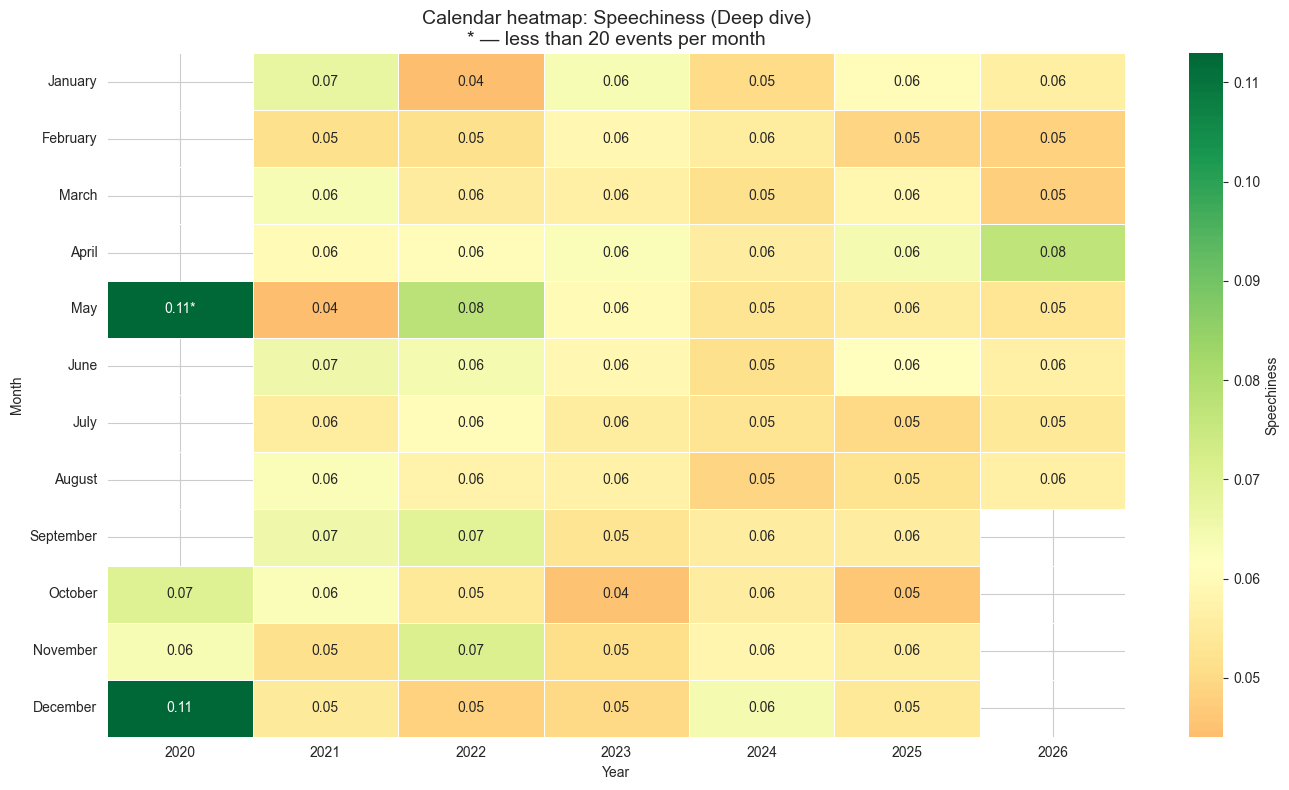

📊 Mean Speechiness by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,0.067,0.044,0.063,0.050,0.060,0.056
February,NaN,0.052,0.052,0.059,0.055,0.049,0.048
March,NaN,0.064,0.055,0.056,0.052,0.058,0.048
April,NaN,0.060,0.061,0.063,0.056,0.065,0.077
May,0.113,0.044,0.077,0.060,0.053,0.055,0.053
June,NaN,0.065,0.064,0.059,0.052,0.061,0.056
July,NaN,0.055,0.060,0.055,0.053,0.050,0.054
August,NaN,0.063,0.057,0.057,0.049,0.052,0.056
September,NaN,0.065,0.069,0.053,0.056,0.055,NaN
October,0.070,0.063,0.054,0.045,0.055,0.046,NaN


⚠️ Speechiness: 1 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Speechiness:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
   ⚡ Contrast transitions (>2σ):
      2020: November → December (Δ=0.049)
      2026: March → April (Δ=0.029)

🎯 Hypotheses to check:
   1. Stable trend — verify Speechiness evolution across the period.
   2. Contrast transitions — check sharp Speechiness shifts within years.

   Tempo


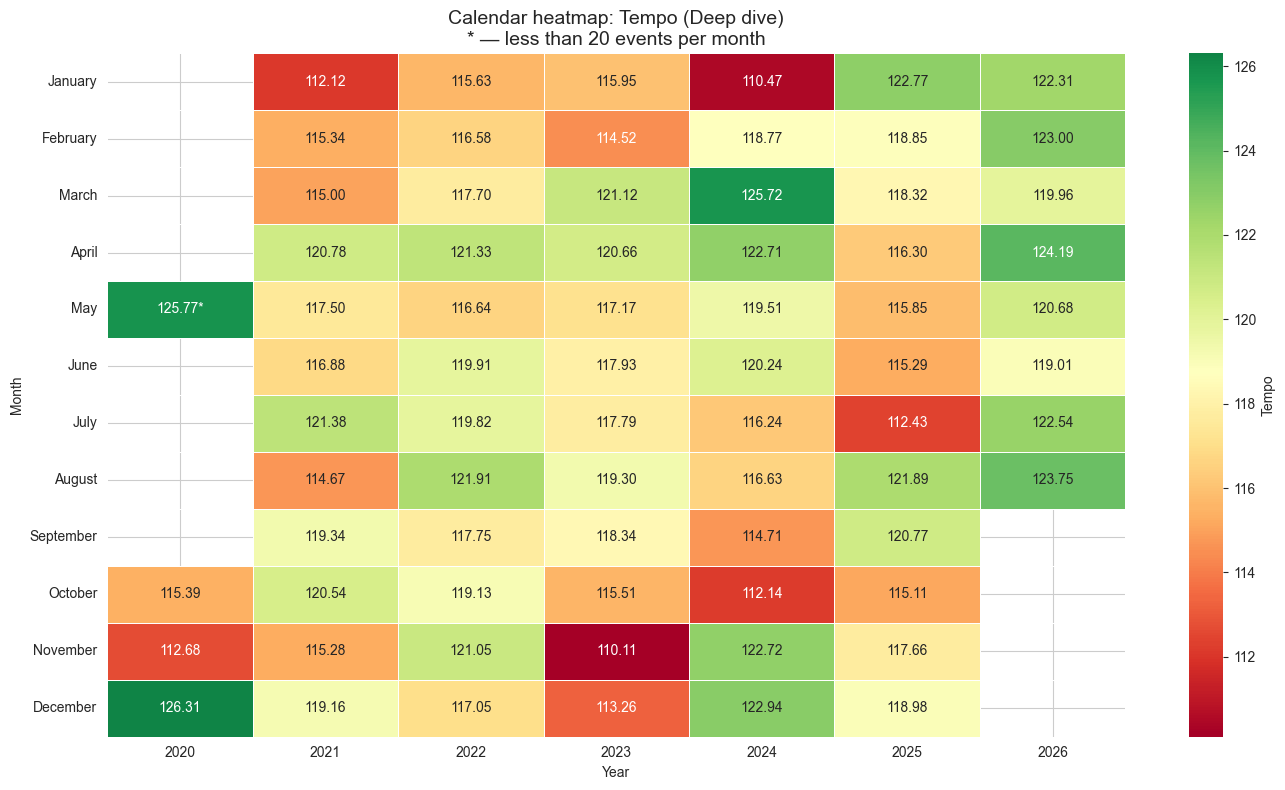

📊 Mean Tempo by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,112.124,115.625,115.954,110.472,122.770,122.311
February,NaN,115.339,116.581,114.521,118.772,118.855,123.002
March,NaN,114.997,117.699,121.116,125.718,118.319,119.963
April,NaN,120.776,121.327,120.660,122.709,116.297,124.193
May,125.765,117.504,116.641,117.173,119.507,115.854,120.680
June,NaN,116.876,119.908,117.927,120.239,115.291,119.009
July,NaN,121.375,119.823,117.792,116.237,112.425,122.536
August,NaN,114.668,121.910,119.300,116.627,121.893,123.748
September,NaN,119.342,117.750,118.337,114.706,120.774,NaN
October,115.390,120.542,119.133,115.509,112.139,115.113,NaN


✅ Tempo: mean and median are close in all cells.

🔍 Analysis for Tempo:
   📈 No significant high years.
   📉 No significant low years.
   🚀 No significant outlier months.
   🔁 Stable trends:
      2021–2023: growth
   ⚡ Contrast transitions (>2σ):
      2020: November → December (Δ=13.633)
      2024: October → November (Δ=10.576)

🎯 Hypotheses to check:
   1. Stable trend — verify Tempo evolution across the period.
   2. Contrast transitions — check sharp Tempo shifts within years.

   Loudness


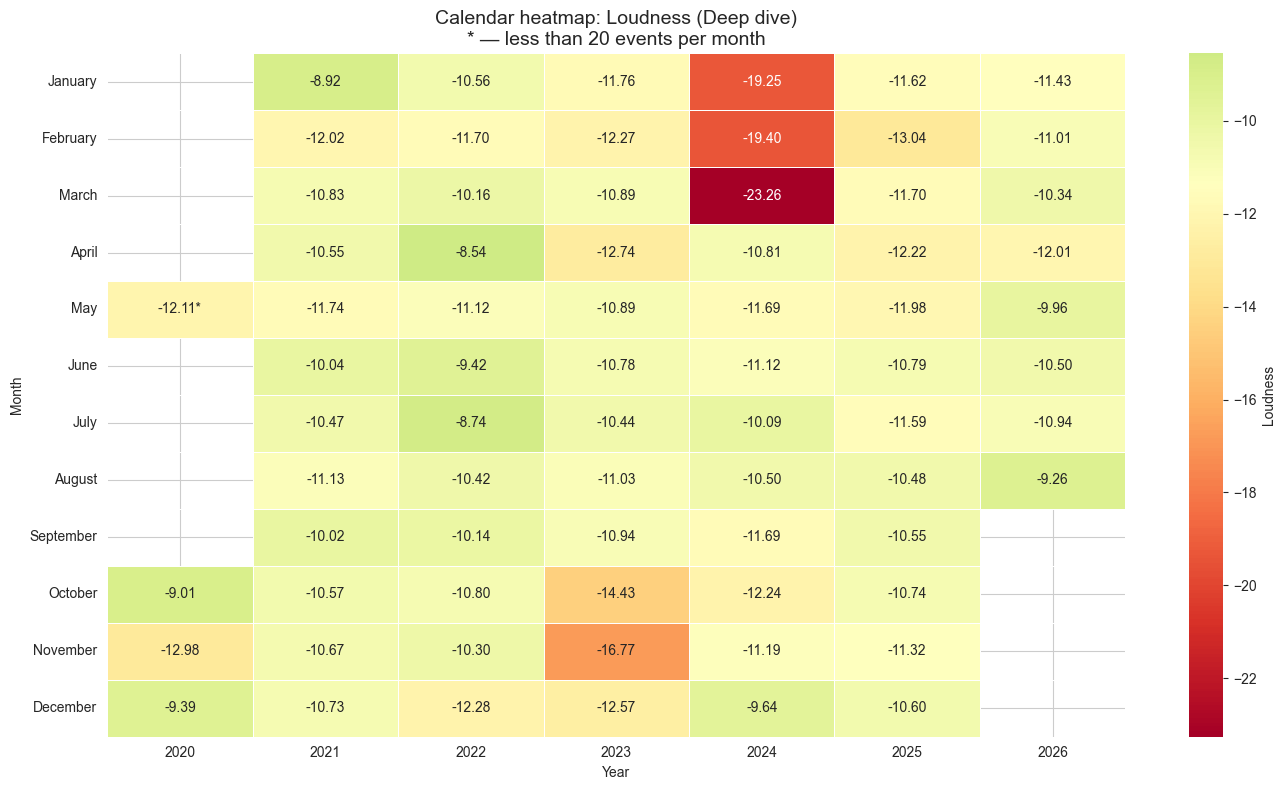

📊 Mean Loudness by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,-8.916,-10.555,-11.762,-19.248,-11.616,-11.427
February,NaN,-12.021,-11.698,-12.274,-19.395,-13.039,-11.010
March,NaN,-10.828,-10.162,-10.894,-23.259,-11.697,-10.338
April,NaN,-10.548,-8.542,-12.741,-10.806,-12.224,-12.007
May,-12.114,-11.738,-11.117,-10.886,-11.687,-11.976,-9.964
June,NaN,-10.037,-9.424,-10.780,-11.121,-10.789,-10.503
July,NaN,-10.469,-8.745,-10.441,-10.086,-11.586,-10.935
August,NaN,-11.127,-10.419,-11.029,-10.497,-10.483,-9.263
September,NaN,-10.018,-10.137,-10.935,-11.689,-10.548,NaN
October,-9.007,-10.575,-10.803,-14.435,-12.238,-10.744,NaN


⚠️ Loudness: 3 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Loudness:
   📈 No significant high years.
   📉 Low years (IQR outliers): {2024: -17.060}
   🚀 No significant outlier months.
   🔁 Stable trends:
      2023–2025: decline
      2025–2026: growth
   ⚡ Contrast transitions (>2σ):
      2024: March → April (Δ=12.453)

🎯 Hypotheses to check:
   1. Low years [2024] — investigate Loudness decline.
   2. Stable trend — verify Loudness evolution across the period.
   3. Contrast transitions — check sharp Loudness shifts within years.

   Popularity


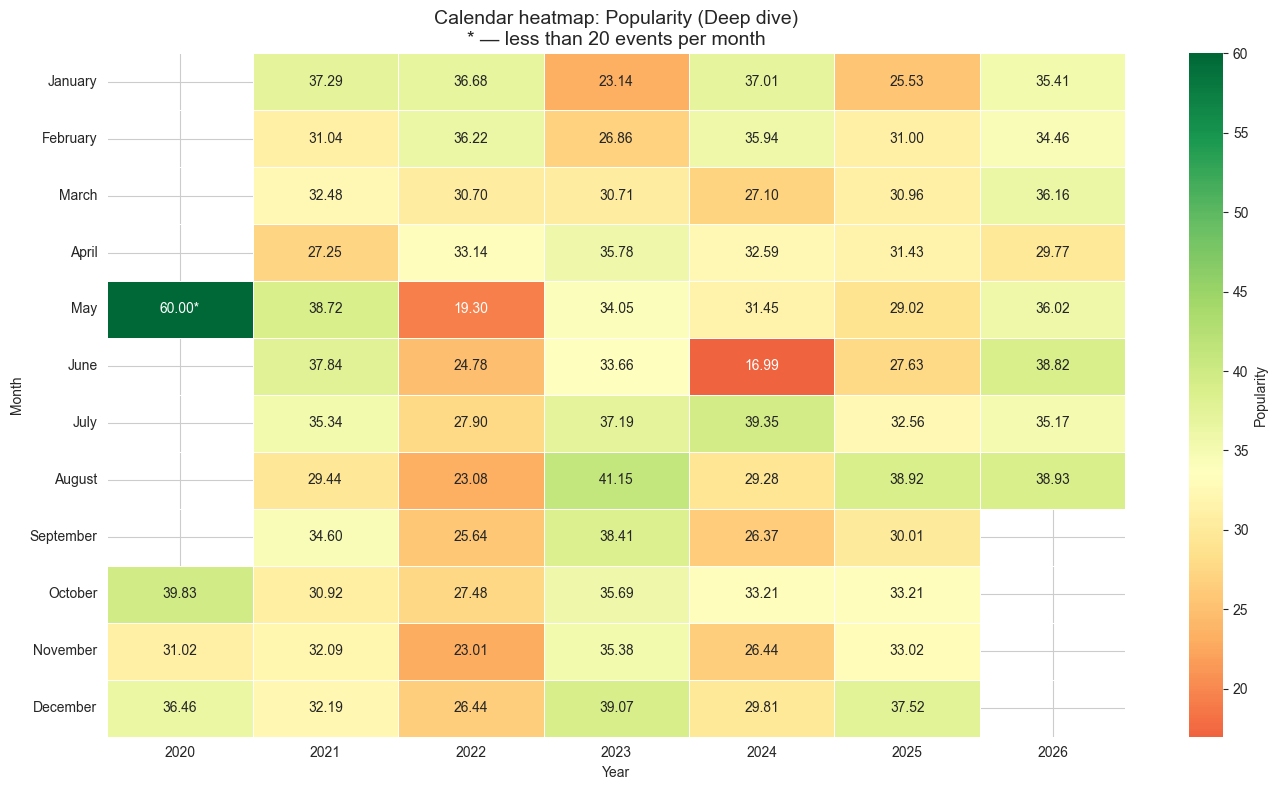

📊 Mean Popularity by month and year:


year,2020,2021,2022,2023,2024,2025,2026
January,NaN,37.286,36.679,23.140,37.006,25.531,35.410
February,NaN,31.036,36.220,26.861,35.940,30.996,34.462
March,NaN,32.480,30.701,30.710,27.096,30.963,36.164
April,NaN,27.251,33.135,35.783,32.594,31.429,29.769
May,60.000,38.720,19.297,34.053,31.453,29.017,36.019
June,NaN,37.840,24.783,33.658,16.989,27.633,38.819
July,NaN,35.342,27.900,37.188,39.346,32.557,35.167
August,NaN,29.438,23.076,41.149,29.282,38.918,38.928
September,NaN,34.596,25.639,38.412,26.366,30.009,NaN
October,39.835,30.923,27.484,35.687,33.209,33.208,NaN


⚠️ Popularity: 1 cells where |mean − median| > 5% of scale.
   Means may be skewed by heavy tails in those months.

🔍 Analysis for Popularity:
   📈 No significant high years.
   📉 Low years (IQR outliers): {2022: 25.741}
   🚀 No significant outlier months.
   🔁 Stable trends:
      2021–2023: decline
      2025–2026: growth
   ⚡ Contrast transitions (>2σ):
      2024: June → July (Δ=22.357)

🎯 Hypotheses to check:
   1. Low years [2022] — investigate Popularity decline.
   2. Stable trend — verify Popularity evolution across the period.
   3. Contrast transitions — check sharp Popularity shifts within years.


In [171]:
# 3.1 Универсальная календарная тепловая карта + прогон всех характеристик

# Функция строит тепловую карту «месяц × год» для одной характеристики,
# считает сводные метрики (выбросы по IQR, тренды, контрастные переходы)
# и формирует гипотезы для дальнейшего разбора.
#
# Логика вывода:
#   - в ячейках карты — среднее значение характеристики за месяц;
#   - звёздочка (*) у числа означает, что событий в этом месяце меньше min_events;
#   - цвета: красный — низкие значения, зелёный — высокие.
#
# Артефакты вывода: dict с np.float64 заменяем на чистые float,
# чтобы не появлялось «{2024: np.float64(-17.06)}» в консоли.

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')


def _fmt_dict(d):
    """Преобразует dict с np.float64 в строку с чистыми float."""
    return '{' + ', '.join(f'{k}: {float(v):.3f}' for k, v in d.items()) + '}'


def plot_calendar_heatmap(daily_df, feature='valence_mean', title=None, min_events=20):
    """
    Строит календарную тепловую карту для одной характеристики.

    Параметры:
        daily_df : DataFrame с дневной агрегацией
        feature  : колонка характеристики (например, 'valence_mean')
        title    : заголовок графика
        min_events : минимум событий в месяц, ниже которого значения помечаются *

    Возвращает:
        (pivot_val, yearly_mean, mean_by_month)
    """
    if title is None:
        title = feature.replace('_mean', '').capitalize()

    # Сводные таблицы: значения характеристики и суммарные события по месяцам/годам.
    pivot_val = daily_df.pivot_table(index='month', columns='year', values=feature, aggfunc='mean')
    pivot_events = daily_df.pivot_table(index='month', columns='year', values='event_count', aggfunc='sum')

    pivot_val = pivot_val[pivot_val.index.isin(range(1, 13))]
    pivot_val.index = pivot_val.index.astype(int)
    pivot_events = pivot_events[pivot_events.index.isin(range(1, 13))]
    pivot_events.index = pivot_events.index.astype(int)

    month_labels = [month_name[i] for i in pivot_val.index]
    pivot_val.index = month_labels
    pivot_events.index = month_labels

    # Подписи ячеек: значение со звёздочкой, если событий меньше порога.
    annot = pivot_val.astype(str)
    for mon in pivot_val.index:
        for yr in pivot_val.columns:
            val = pivot_val.loc[mon, yr]
            evt = pivot_events.loc[mon, yr]
            if pd.isna(val):
                annot.loc[mon, yr] = ''
            elif pd.notna(evt) and evt < min_events:
                annot.loc[mon, yr] = f'{val:.2f}*'
            else:
                annot.loc[mon, yr] = f'{val:.2f}'

    # Сама тепловая карта.
    plt.figure(figsize=(14, 8))
    sns.heatmap(
        pivot_val,
        annot=annot.values,
        fmt='',
        cmap='RdYlGn',
        center=pivot_val.mean().mean(),
        linewidths=0.5,
        cbar_kws={'label': title}
    )
    plt.title(f'Calendar heatmap: {title} (Deep dive)\n* — less than {min_events} events per month', fontsize=14)
    plt.ylabel('Month')
    plt.xlabel('Year')
    plt.tight_layout()
    plt.show()

    # --- Проверка: mean vs median по месяцам ---
    # Mean чувствительно к хвостам. Если в каком-то месяце много коротких
    # событий с экстремальными значениями, среднее уедет, а медиана останется.
    # Если расхождение >5% от шкалы характеристики — картину heatmap надо
    # интерпретировать осторожно.
    pivot_val_median = daily_df.pivot_table(
        index='month', columns='year', values=feature, aggfunc='median'
    )
    pivot_val_median = pivot_val_median[pivot_val_median.index.isin(range(1, 13))]
    pivot_val_median.index = pivot_val_median.index.astype(int)
    pivot_val_median.index = [month_name[i] for i in pivot_val_median.index]

    diff_pivot = (pivot_val - pivot_val_median).abs()
    range_val = FEATURE_RANGES.get(feature.replace('_mean', ''), 1)
    threshold = range_val * 0.05

    high_diff = diff_pivot > threshold

    print(f'📊 Mean {title} by month and year:')
    display(pivot_val.round(3))

    if high_diff.any().any():
        n_flagged = int(high_diff.sum().sum())
        print(f'⚠️ {title}: {n_flagged} cells where |mean − median| > 5% of scale.')
        print('   Means may be skewed by heavy tails in those months.')
    else:
        print(f'✅ {title}: mean and median are close in all cells.')

    # Сводные метрики по годам и месяцам — только по «надёжным» дням.
    daily_reliable = daily_df[daily_df['event_count'] >= min_events]
    yearly_mean = daily_reliable.groupby('year')[feature].mean().dropna()
    mean_by_month = daily_reliable.groupby('month')[feature].mean().dropna()

    # --- Выбросы по IQR ---
    # Годы, где среднее сильно выше или ниже типичного разброса.
    high_years, low_years = pd.Series(dtype=float), pd.Series(dtype=float)
    if len(yearly_mean) >= 4:
        y_q1, y_q3 = yearly_mean.quantile(0.25), yearly_mean.quantile(0.75)
        y_iqr = y_q3 - y_q1
        if y_iqr > 0:
            high_years = yearly_mean[yearly_mean > y_q3 + 1.5 * y_iqr]
            low_years = yearly_mean[yearly_mean < y_q1 - 1.5 * y_iqr]

    # Месяцы, где среднее выбивается вверх.
    outlier_months = pd.Series(dtype=float)
    if len(mean_by_month) >= 4:
        m_q1, m_q3 = mean_by_month.quantile(0.25), mean_by_month.quantile(0.75)
        m_iqr = m_q3 - m_q1
        if m_iqr > 0:
            m_median = mean_by_month.median()
            outlier_months = mean_by_month[mean_by_month > m_median + 1.5 * m_iqr]

    # --- Устойчивые тренды ---
    # Ищем последовательные периоды роста или снижения между годами.
    yearly_diff = yearly_mean.diff().dropna()
    trend_periods = []
    if len(yearly_diff) >= 2:
        current_sign = None
        current_start = None
        for yr in yearly_diff.index:
            s = 1 if yearly_diff[yr] > 0 else -1 if yearly_diff[yr] < 0 else 0
            if s == 0:
                current_start = None
                current_sign = None
                continue
            if current_sign is None or s != current_sign:
                if current_start is not None and yr - current_start >= 2:
                    trend_periods.append((current_start, yr, current_sign))
                current_start = yr
                current_sign = s
        if current_start is not None and yearly_diff.index[-1] - current_start >= 1:
            trend_periods.append((current_start, yearly_diff.index[-1], current_sign))

    # --- Контрастные переходы ---
    # Резкие смены значения между соседними месяцами внутри одного года.
    # Порог: разница больше двух медианных стандартных отклонений по месяцам.
    monthly_std = daily_reliable.groupby('month')[feature].std().median()
    contrast_months = []
    if pd.notna(monthly_std) and monthly_std > 0:
        for yr in pivot_val.columns:
            # Без dropna: позиция i в yr_data совпадает с позицией
            # в pivot_events, поэтому проверка min_events смотрит в тот же месяц.
            # Если один из месяцев NaN, diff = NaN, сравнение даёт False,
            # переход пропускается сам.
            yr_data = pivot_val[yr]
            for i in range(1, len(yr_data)):
                diff = abs(yr_data.iloc[i] - yr_data.iloc[i-1])
                if pd.notna(diff) and diff > 2 * monthly_std:
                    col_idx = pivot_val.columns.get_loc(yr)
                    if pivot_events.iloc[i, col_idx] >= min_events:
                        contrast_months.append((yr, yr_data.index[i-1], yr_data.index[i], diff))
                        
    # --- Вывод сводки ---
    print(f'\n🔍 Analysis for {title}:')
    if not high_years.empty:
        print(f'   📈 High years (IQR outliers): {_fmt_dict(high_years.round(3))}')
    else:
        print('   📈 No significant high years.')
    if not low_years.empty:
        print(f'   📉 Low years (IQR outliers): {_fmt_dict(low_years.round(3))}')
    else:
        print('   📉 No significant low years.')
    if not outlier_months.empty:
        print(f'   🚀 Outlier months (IQR): {_fmt_dict(outlier_months.round(3))}')
    else:
        print('   🚀 No significant outlier months.')
    if trend_periods:
        print('   🔁 Stable trends:')
        for start, end, sign in trend_periods:
            direction = 'growth' if sign == 1 else 'decline'
            print(f'      {start}–{end}: {direction}')
    else:
        print('   🔁 No stable trends.')
    if contrast_months:
        print('   ⚡ Contrast transitions (>2σ):')
        for yr, m1, m2, diff in contrast_months[:5]:
            print(f'      {yr}: {m1} → {m2} (Δ={diff:.3f})')
    else:
        print('   ⚡ No contrast transitions.')

    # --- Гипотезы для дальнейшего разбора ---
    hypotheses = []
    if not high_years.empty:
        hypotheses.append(f'High years {list(high_years.index)} — check what caused {title} to rise.')
    if not low_years.empty:
        hypotheses.append(f'Low years {list(low_years.index)} — investigate {title} decline.')
    if not outlier_months.empty:
        names = [month_name[m] for m in outlier_months.index]
        hypotheses.append(f'Outlier months {names} — check seasonal anomalies in {title}.')
    if trend_periods:
        hypotheses.append(f'Stable trend — verify {title} evolution across the period.')
    if contrast_months:
        hypotheses.append(f'Contrast transitions — check sharp {title} shifts within years.')
    if hypotheses:
        print(f'\n🎯 Hypotheses to check:')
        for i, h in enumerate(hypotheses, 1):
            print(f'   {i}. {h}')
    else:
        print(f'\n🎯 No hypotheses — {title} is stable.')

    return pivot_val, yearly_mean, mean_by_month


# Прогон по всем характеристикам.
results = {}
for col, title in FEATURES:
    print(f'\n{"="*60}\n   {title}\n{"="*60}')
    pivot, yearly, monthly = plot_calendar_heatmap(daily, feature=col, title=title, min_events=20)
    results[col] = (pivot, yearly, monthly)

### 3.1 Вывод

Календарные карты дают три содержательных результата: список годов
с аномальными средними, двухфазный паттерн трендов с переломом
в 2025 и концентрацию резких переходов в 2024. Плюс — важная
оговорка про надёжность самих карт.

**Надёжность карт.** Расхождение среднего и медианы больше 5% от шкалы
обнаружено у восьми характеристик из десяти. Больше всего — у
instrumentalness (14 ячеек) и acousticness (12). Это те же две
характеристики, которые блок 4 выделит как самые изменившиеся:
в этих месяцах распределения сильно скошены, и карту нужно читать
как тенденцию, а не как точное значение. У tempo и liveness расхождений
нет вообще — их карты читаются буквально.

**IQR-выбросы по годам.** Обнаружено три низких года: Danceability —
2024 (0.467), Loudness — 2024 (−17.060), Popularity — 2022 (25.741).
Высоких годов не обнаружено ни у одной характеристики. Два из трёх
выбросов — в 2024, что согласуется с выводами 2.1 и 3.4.

**Устойчивые тренды.** Почти у всех характеристик — двухфазный
паттерн. Восемь из десяти: 2023–2025 направленное изменение, затем
2025–2026 разворот. У valence, energy, danceability, liveness,
speechiness и loudness — падение на первой фазе; у acousticness
и instrumentalness — рост. Tempo и popularity выбиваются: у них
тренд старше, 2021–2023.

**Контрастные переходы.** Из найденных переходов большинство приходится на 2024 год. Самый сильный — март → апрель 2024 (пять характеристик сразу). Второй
по частоте — январь → февраль 2021 (три характеристики). Остальные
одиночные: popularity (июнь → июль 2024), tempo (октябрь → ноябрь
2024), speechiness (март → апрель 2026). Отдельно — два перехода
в 2020 году: speechiness и tempo, оба ноябрь → декабрь. 2020 —
неполный год (данные с мая), эти переходы менее надёжны, чем
аналогичные в полные годы.

**Что за этим стоит.** 2024 выделяется не как «аномальный год»
по средним (там всего два IQR-выброса), а как год с самой плотной
концентрацией резких внутригодовых переходов. Март → апрель 2024 —
точка, где сразу пять характеристик одновременно сдвинулись,
и сдвинулись в согласованном направлении: valence, energy,
danceability, loudness вниз, acousticness вверх. Похожая, но менее
массовая синхронность — январь → февраль 2021.

Двухфазный паттерн 2023–2025 / 2025–2026 — вторая структурная
особенность. У восьми характеристик из десяти направление движения
меняется в 2025 году. Это значит, что сдвиг профиля, найденный
в блоке 2, не однородный: он прошёл через направленную фазу
(2023–2025), затем развернулся.

**Ограничение.** 2020 и 2026 — неполные годы, значения менее
устойчивы. Порог `min_events = 20` эвристический: если в месяце
меньше событий, значение помечается звёздочкой и в анализ выбросов
не идёт, но в карту всё равно попадает. Расхождение среднего
и медианы сигнализирует о скошенности, но не о том, в какую сторону
она идёт — для этого нужна отдельная проверка.


## 3.2 Сводка всех гипотез и отбор топ-5


In [172]:
# 3.2 Сводка всех гипотез и отбор топ-5

# Здесь собираются все гипотезы, сгенерированные в 3.1, и ранжируются по «Силе».
# В топ-5 попадают самые сильные отклонения за весь период.
#
# ВАЖНО про метрику «Сила».
# Раньше в одну колонку складывались четыре разные формулы:
#   - IQR-отклонение года (в единицах IQR);
#   - IQR-отклонение месяца (в единицах IQR);
#   - relative_strength = (avg_change / global_mean) * length;
#   - z-score контрастных переходов (в единицах std).
# Эти метрики несравнимы между собой: IQR-единицы и std-единицы различаются
# примерно в 1.35 раза для нормального распределения, а формула тренда
# вообще вне системы — она нормирует на среднее и умножает на длину.
#
# Теперь формула тренда приведена к std-единицам: avg_change / global_std.
# Все четыре метрики стали одного порядка — «на сколько разбросов отклонилось».

min_events = 20
daily_reliable = daily[daily['event_count'] >= min_events]
all_hypotheses = []

for col, title in FEATURES:
    pivot_val = results[col][0]
    yearly_mean = results[col][1]
    mean_by_month = results[col][2]

    global_mean = daily_reliable[col].mean()
    global_std = daily_reliable[col].std()

    # --- IQR-выбросы по годам ---
    high_years, low_years = pd.Series(dtype=float), pd.Series(dtype=float)
    if len(yearly_mean) >= 4:
        y_q1, y_q3 = yearly_mean.quantile(0.25), yearly_mean.quantile(0.75)
        y_iqr = y_q3 - y_q1
        if y_iqr > 0:
            high_years = yearly_mean[yearly_mean > y_q3 + 1.5 * y_iqr]
            low_years = yearly_mean[yearly_mean < y_q1 - 1.5 * y_iqr]

    # --- IQR-выбросы по месяцам ---
    outlier_months = pd.Series(dtype=float)
    if len(mean_by_month) >= 4:
        m_q1, m_q3 = mean_by_month.quantile(0.25), mean_by_month.quantile(0.75)
        m_iqr = m_q3 - m_q1
        if m_iqr > 0:
            m_median = mean_by_month.median()
            outlier_months = mean_by_month[mean_by_month > m_median + 1.5 * m_iqr]

    # --- Устойчивые тренды между годами ---
    yearly_diff = yearly_mean.diff().dropna()
    trend_periods = []
    if len(yearly_diff) >= 2:
        current_sign = None
        current_start = None
        for yr in yearly_diff.index:
            s = 1 if yearly_diff[yr] > 0 else -1 if yearly_diff[yr] < 0 else 0
            if s == 0:
                current_start = None
                current_sign = None
                continue
            if current_sign is None or s != current_sign:
                if current_start is not None and yr - current_start >= 2:
                    trend_periods.append((current_start, yr, current_sign))
                current_start = yr
                current_sign = s
        if current_start is not None and yearly_diff.index[-1] - current_start >= 1:
            trend_periods.append((current_start, yearly_diff.index[-1], current_sign))

    # --- Контрастные переходы между месяцами внутри года ---
    monthly_std = daily_reliable.groupby('month')[col].std().median()
    contrast_months = []
    if pd.notna(monthly_std) and monthly_std > 0:
        pivot_events = daily_reliable.pivot_table(index='month', columns='year', values='event_count', aggfunc='sum')
        pivot_events = pivot_events[pivot_events.index.isin(range(1, 13))]
        pivot_events.index = pivot_events.index.astype(int)
        month_labels = [month_name[i] for i in pivot_events.index]
        pivot_events.index = month_labels

        for yr in pivot_val.columns:
            # Без dropna: позиция i совпадает с pivot_events,
            # NaN-переходы отсеиваются явной проверкой.
            yr_data = pivot_val[yr]
            for i in range(1, len(yr_data)):
                diff = abs(yr_data.iloc[i] - yr_data.iloc[i-1])
                if pd.notna(diff) and diff > 2 * monthly_std:
                    col_idx = pivot_val.columns.get_loc(yr)
                    if yr in pivot_events.columns and pivot_events.iloc[i, col_idx] >= min_events:
                        contrast_months.append((yr, yr_data.index[i-1], yr_data.index[i], diff))
                        
    # --- Формируем гипотезы с единой шкалой «Сила» ---

    # IQR-выбросы года: сила = на сколько IQR значение вышло за границу.
    if not high_years.empty:
        for yr, val in high_years.items():
            deviation = (val - (y_q3 + 1.5 * y_iqr)) / y_iqr
            all_hypotheses.append({
                'Feature': title,
                'Type': 'IQR outlier (year)',
                'Details': f'High year: {yr} ({val:.2f})',
                'Description': f'Anomalous rise in {title}.',
                'Strength': round(deviation, 2)
            })
    if not low_years.empty:
        for yr, val in low_years.items():
            deviation = ((y_q1 - 1.5 * y_iqr) - val) / y_iqr
            all_hypotheses.append({
                'Feature': title,
                'Type': 'IQR outlier (year)',
                'Details': f'Low year: {yr} ({val:.2f})',
                'Description': f'Anomalous decline in {title}.',
                'Strength': round(deviation, 2)
            })
    if not outlier_months.empty:
        for m, val in outlier_months.items():
            deviation = (val - (m_median + 1.5 * m_iqr)) / m_iqr
            all_hypotheses.append({
                'Feature': title,
                'Type': 'IQR outlier (month)',
                'Details': f'Outlier month: {month_name[m]} ({val:.2f})',
                'Description': f'Seasonal anomaly in {title}.',
                'Strength': round(deviation, 2)
            })

    # Тренды: сила = изменение в std-единицах.
    # Раньше было (avg_change / global_mean) * length — это делало длинные тренды
    # автоматически «сильнее» независимо от величины сдвига. Теперь — просто
    # на сколько стандартных отклонений сместилось значение за период.
    if trend_periods:
        for start, end, sign in trend_periods:
            avg_change = abs(yearly_mean.loc[end] - yearly_mean.loc[start])
            trend_strength = avg_change / global_std if global_std > 0 else 0
            direction = 'growth' if sign == 1 else 'decline'
            all_hypotheses.append({
                'Feature': title,
                'Type': 'Trend',
                'Details': f'{start}–{end}: {direction}',
                'Description': f'Stable change in {title}.',
                'Strength': round(trend_strength, 2)
            })

    # Контрастные переходы: сила = разница в std-единицах.
    if contrast_months:
        for yr, m1, m2, diff in contrast_months[:5]:
            z_score_strength = diff / monthly_std
            all_hypotheses.append({
                'Feature': title,
                'Type': 'Contrast transition',
                'Details': f'{yr}: {m1} → {m2} (Δ={diff:.3f})',
                'Description': f'Sharp shift in {title} within a year.',
                'Strength': round(z_score_strength, 2)
            })


# --- Топ-5 гипотез ---
if all_hypotheses:
    hyp_df = pd.DataFrame(all_hypotheses)
    top5 = hyp_df.nlargest(5, 'Strength').copy()
    top5_display = top5.reset_index(drop=True)
    top5_display.index = top5_display.index + 1
    top5_display.index.name = '№'
    print(f'📋 Total hypotheses generated: {len(hyp_df)}. Top-5 selected for deeper analysis:')
    display(top5_display[['Feature', 'Type', 'Details', 'Description', 'Strength']])
else:
    print('🎯 No feature produced significant hypotheses — the profile is exceptionally stable.')

📋 Total hypotheses generated: 32. Top-5 selected for deeper analysis:


,Feature,Type,Details,Description,Strength
№,,,,,
1,Loudness,Contrast transition,2024: March → April (Δ=12.453),Sharp shift in Loudness within a year.,4.30
2,Speechiness,Contrast transition,2020: November → December (Δ=0.049),Sharp shift in Speechiness within a year.,4.05
3,Danceability,Contrast transition,2024: March → April (Δ=0.233),Sharp shift in Danceability within a year.,3.42
4,Acousticness,Contrast transition,2021: January → February (Δ=0.397),Sharp shift in Acousticness within a year.,2.72
5,Energy,Contrast transition,2024: March → April (Δ=0.269),Sharp shift in Energy within a year.,2.67


### 3.2 Вывод

Ячейка собирает все гипотезы, которые 3.1 сгенерировала по каждой
из 10 характеристик, приводит их к единой шкале и отбирает топ-5
для дальнейшего разбора.

**Что собирается.** Из `results` (по каждой характеристике — pivot,
yearly_mean, mean_by_month) ячейка повторно извлекает четыре типа
сигналов: IQR-выбросы по годам, IQR-выбросы по месяцам, устойчивые
тренды, контрастные переходы. Формально это те же сигналы, что уже
найдены в 3.1, но здесь они пересчитываются заново — потому что
3.1 печатала их как текст, а для ранжирования нужны числа.

**Как считается «Сила».** Раньше метрика была несравнимой: IQR-отклонения
года и месяца считались в единицах IQR, тренды — по формуле
`(avg_change / global_mean) × length`, контрастные переходы — в единицах
std. Четыре разные шкалы в одной колонке. Теперь все четыре приведены
к std-единицам: IQR-отклонение нормируется на IQR, тренд — на `global_std`,
контрастный переход — на `monthly_std`. Число в колонке `Strength`
означает «на сколько разбросов характеристика отклонилась».

**Что получается.** Из всех сгенерированных гипотез топ-5 целиком
состоит из контрастных переходов. Ни IQR-выбросы, ни тренды в пятёрку
не попали. Это не значит, что они слабые: значит, что резкие
внутригодовые сдвиги оказались сильнее по единой шкале, чем годовые
отклонения и многолетние тренды.

Четыре из пяти переходов — в 2024, один — в 2021. Самая сильная
гипотеза — Loudness, март → апрель 2024 (Δ=12.453, сила 4.30).
На втором месте — Speechiness, ноябрь → декабрь 2020 (Δ=0.049,
сила 4.05). 2020 — неполный год, данные с мая, поэтому переход
менее надёжен, чем аналогичные в полные годы. Условно пятое место
мог бы занимать Popularity, июнь → июль 2024 — сила 2.67, как
у Energy того же периода.

**Что объединяет четыре гипотезы из 2024.** Три из них — март → апрель:
Loudness, Danceability, Energy. Это тот же переход, который 3.1
показал как синхронный сдвиг пяти характеристик — valence
и acousticness тоже сдвинулись тогда, но их сила оказалась ниже
и в топ-5 они не попали. Четвёртая гипотеза из 2024 — Popularity,
но уже июнь → июль (Δ=22.357). Это отдельное событие: не тот же
самый переход, а второй резкий сдвиг в том же году, по другой
характеристике и в другой месяц.

**Единственная гипотеза вне 2024** — Acousticness, январь → февраль
2021 (Δ=0.397, сила 2.72). Это третий год в общей картине блока:
2024 лидирует по концентрации, 2021 даёт один сильный одиночный
переход, оба года всплывали в 3.1.

**Зачем это нужно.** 3.1 генерирует десятки сигналов. Без
приоритезации читатель утонул бы в списке: у Loudness низкий 2024,
у Popularity низкий 2022, у Acousticness тренд 2023–2025, у Tempo
контрастный переход октября → ноября 2024, и так по каждой
из 10 характеристик. Ранжирование говорит: вот пять самых сильных
сигналов, с них начинается разбор. Топ-5 передаётся в 3.5 для
точечной проверки в окне, соответствующем типу гипотезы.

**Ограничение.** Метрика «Сила» приведена к единой std-шкале, но пороги
внутри неё остаются эвристическими. Ранжирование зависит от того, как
определён `monthly_std` и `global_std` — при смене агрегации порядок
топ-5 мог бы измениться. На этих данных топ-5 устойчив: все пять —
контрастные переходы, и три из них — тот же самый март → апрель 2024,
различимые только по характеристике.

## 3.3 Определение года-лидера


In [173]:
# 3.3 Определение года-лидера

# Раньше здесь была развилка между двумя сценариями проверки гипотез.
# Теперь развилки нет: 3.5 (точечная проверка топ-5) выполняется всегда,
# а 3.4 (детальный разбор года) — только если в гипотезах есть явный лидер.
#
# Лидер определяется по концентрации суммарной силы гипотез в одном году.
# Порог CONCENTRATION_THRESHOLD = 35% подобран эмпирически: если один год
# даёт больше трети силы, он заслуживает отдельного разбора.

def extract_years(text):
    """Извлекает все четырёхзначные годы из строки."""
    return [int(y) for y in re.findall(r'\b(\d{4})\b', text)]

# Суммируем силу гипотез по годам.
# Гипотезе может соответствовать один или два года (тренд 2023–2025).
year_strength = {}
for _, row in hyp_df.iterrows():
    yrs = extract_years(row['Details'])
    strength = row['Strength']
    for yr in yrs:
        year_strength[yr] = year_strength.get(yr, 0) + strength

# Порог для определения года-лидера.
# Эвристика: выбрана на глаз, не выведена из статистического теста.
# В PELT_JOURNEY.md для аналогичной задачи выбора порога позже использован
# permutation-null — здесь этот уровень строгости ещё не применялся.
CONCENTRATION_THRESHOLD = 35

# Берём top-2 года по суммарной силе — столько же, сколько анализирует 3.4.
sorted_years = sorted(year_strength.items(), key=lambda x: x[1], reverse=True)

if sorted_years:
    top_year, top_year_value = sorted_years[0]
    top_year_pct = top_year_value / sum(year_strength.values()) * 100
    has_leader_year = top_year_pct >= CONCENTRATION_THRESHOLD
    leader_years = [yr for yr, _ in sorted_years[:2]] if has_leader_year else []
else:
    top_year = None
    top_year_pct = 0
    has_leader_year = False
    leader_years = []

if sorted_years:
    print(f'🔍 Year with highest total hypothesis strength: {top_year} ({top_year_pct:.0f}% of total).')
    if has_leader_year:
        print(f'   ✅ Leader year detected → 3.4 will analyze: {leader_years}')
    else:
        print('   ℹ️ No dominant year → 3.4 will be skipped.')
else:
    print('🔍 No hypotheses with a year — 3.4 will be skipped.')

🔍 Year with highest total hypothesis strength: 2024 (50% of total).
   ✅ Leader year detected → 3.4 will analyze: [2024, 2021]


### 3.3 Вывод

2024 концентрирует 50% суммарной силы гипотез — порог в 35% пройден
с запасом. Лидер определён, детальный разбор запускается.

В 3.4 идут два года: 2024 и 2021. 2024 — как год-лидер по концентрации,
2021 — как второй по силе. Это согласуется с картиной из 3.1 и 3.2:
2024 даёт большинство сильных переходов, 2021 — один устойчивый
(январь → февраль). То, что оба года подтвердились на этом шаге,
означает, что их аномальность не артефакт одной характеристики —
она накапливается по нескольким.

Доля 2024 упала с 58% до 50% после правки 3.1 — в топ добавились
два перехода 2020 года. Это разбавило концентрацию, но не изменило
вывод: 2024 остаётся годом-лидером, а 2021 — вторым по силе.

## 3.4 Детальный анализ годов-лидеров



🔍 Years for detailed analysis: [2024, 2021]

   DETAILED ANALYSIS OF 2024

📊 Mean features: 2024 vs other years


,Feature,2024,Other years
№,,,
1,valence,0.217,0.285
2,energy,0.374,0.508
3,danceability,0.450,0.588
4,acousticness,0.545,0.345
5,instrumentalness,0.572,0.469
6,liveness,0.143,0.152
7,speechiness,0.054,0.057
8,tempo,119.756,118.796
9,loudness,-17.778,-11.020



📊 Median features: 2024 vs other years


,Feature,2024,Other years
№,,,
1,valence,0.139,0.236
2,energy,0.372,0.508
3,danceability,0.494,0.614
4,acousticness,0.594,0.248
5,instrumentalness,0.696,0.540
6,liveness,0.111,0.111
7,speechiness,0.045,0.041
8,tempo,121.902,119.651
9,loudness,-13.116,-10.290



⚠️ 2024: mean/median divergence > 5% of scale:
   • valence: 0.078
   • instrumentalness: 0.124
   • loudness: 4.662
   Means may be skewed by heavy tails. Interpret with caution.

📊 Deviation from background (threshold 2%):


,Feature,Diff (mean),Diff (median),Threshold (2%),Exceeds (mean)
№,,,,,
1,valence,-0.067,-0.097,0.006,True
2,energy,-0.134,-0.136,0.010,True
3,danceability,-0.138,-0.120,0.012,True
4,acousticness,0.200,0.346,0.007,True
5,instrumentalness,0.103,0.156,0.009,True
6,liveness,-0.009,0.000,0.003,True
7,speechiness,-0.003,0.004,0.001,True
8,tempo,0.960,2.251,2.376,False
9,loudness,-6.758,-2.826,0.220,True


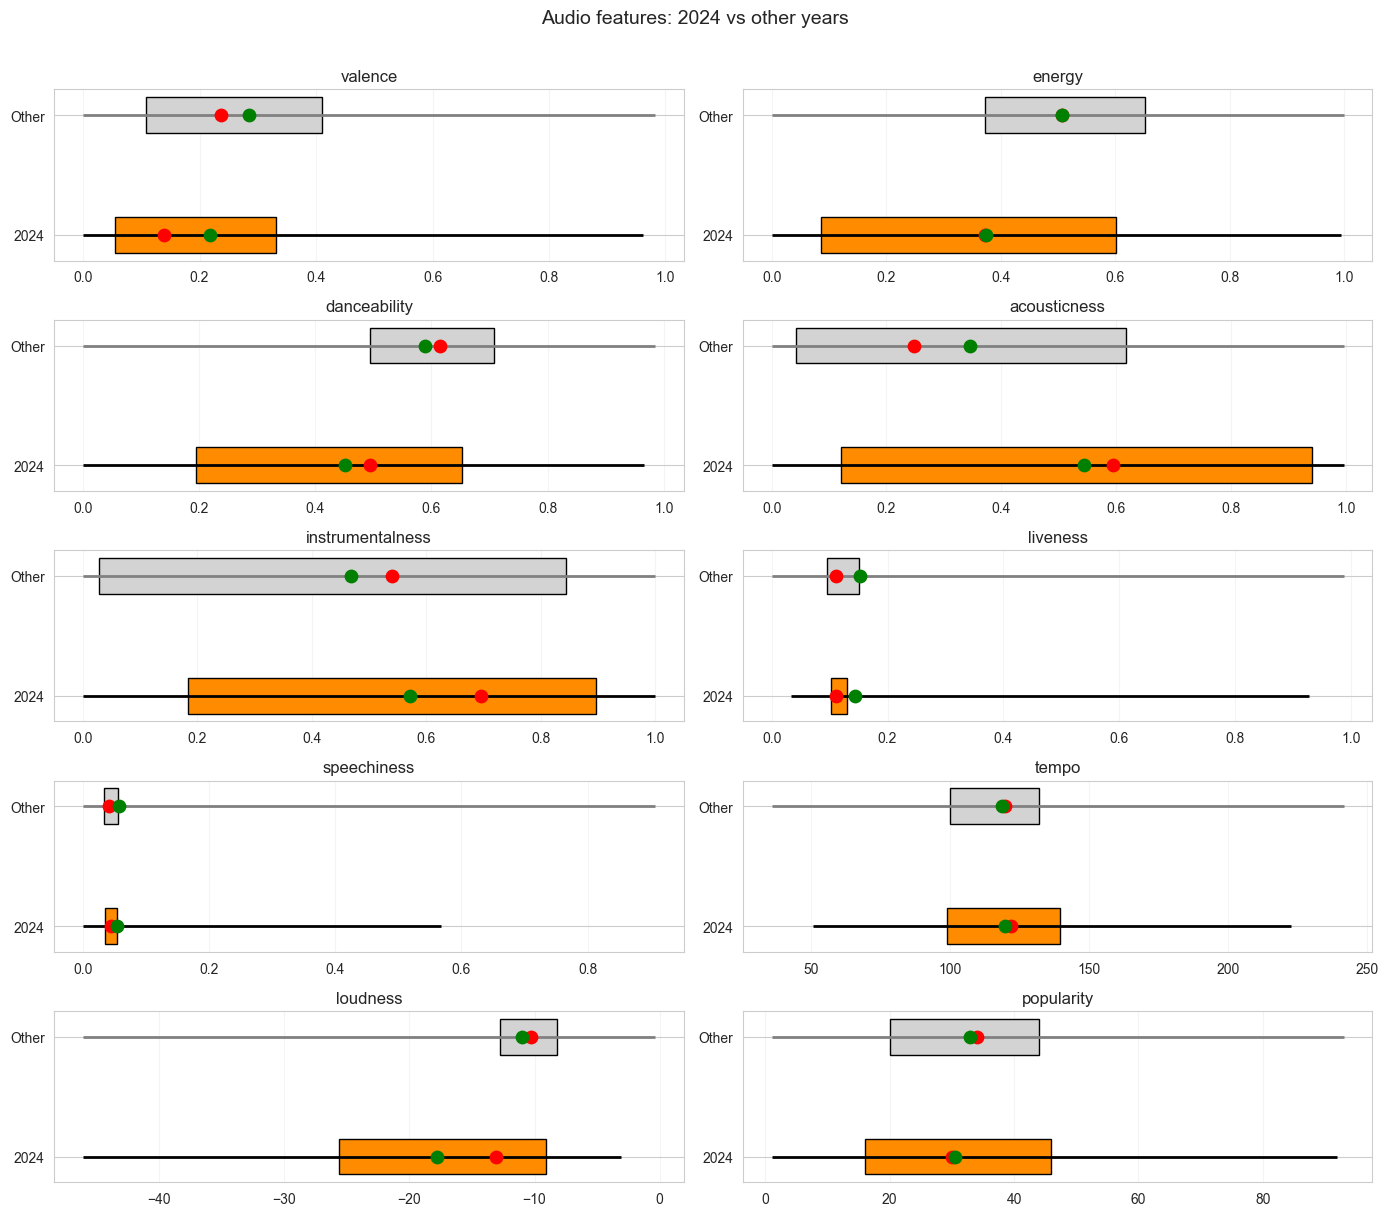


🎵 Genre profile for 2024:
🚨 2024: 60.7% tracks without genre — genre conclusions unreliable.
⚠️ Other years: 42.7% tracks without genre — genre conclusions limited.


,Genre,2024,Other years
№,,,
1,coldwave,478.0,2152.0
2,darkwave,0.0,1997.0
3,downtempo,0.0,5719.0
4,industrial,211.0,0.0
5,industrial metal,199.0,0.0
6,industrial rock,205.0,0.0
7,organic house,0.0,2663.0
8,trip hop,259.0,5544.0


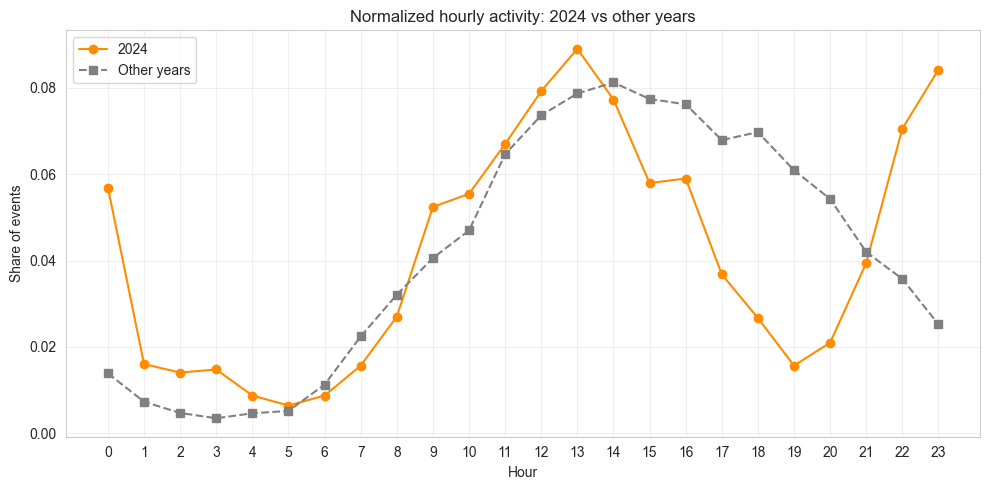


📝 Conclusion for 2024:
   Significantly above background: acousticness, instrumentalness
   Significantly below background: valence, energy, danceability, liveness, speechiness, loudness, popularity
   Top genres: coldwave, trip hop, industrial
   Daily peak hour: 13:00

   DETAILED ANALYSIS OF 2021

📊 Mean features: 2021 vs other years


,Feature,2021,Other years
№,,,
1,valence,0.287,0.275
2,energy,0.521,0.487
3,danceability,0.585,0.569
4,acousticness,0.362,0.371
5,instrumentalness,0.385,0.497
6,liveness,0.151,0.151
7,speechiness,0.061,0.056
8,tempo,117.855,119.082
9,loudness,-10.441,-12.077



📊 Median features: 2021 vs other years


,Feature,2021,Other years
№,,,
1,valence,0.242,0.225
2,energy,0.520,0.492
3,danceability,0.610,0.605
4,acousticness,0.266,0.271
5,instrumentalness,0.272,0.603
6,liveness,0.111,0.111
7,speechiness,0.042,0.041
8,tempo,118.022,119.974
9,loudness,-9.870,-10.554



⚠️ 2021: mean/median divergence > 5% of scale:
   • acousticness: 0.096
   • instrumentalness: 0.113
   Means may be skewed by heavy tails. Interpret with caution.

📊 Deviation from background (threshold 2%):


,Feature,Diff (mean),Diff (median),Threshold (2%),Exceeds (mean)
№,,,,,
1,valence,0.012,0.017,0.005,True
2,energy,0.034,0.028,0.010,True
3,danceability,0.015,0.005,0.011,True
4,acousticness,-0.009,-0.005,0.007,True
5,instrumentalness,-0.111,-0.331,0.010,True
6,liveness,0.000,0.000,0.003,False
7,speechiness,0.005,0.000,0.001,True
8,tempo,-1.227,-1.952,2.382,False
9,loudness,1.636,0.684,0.242,True


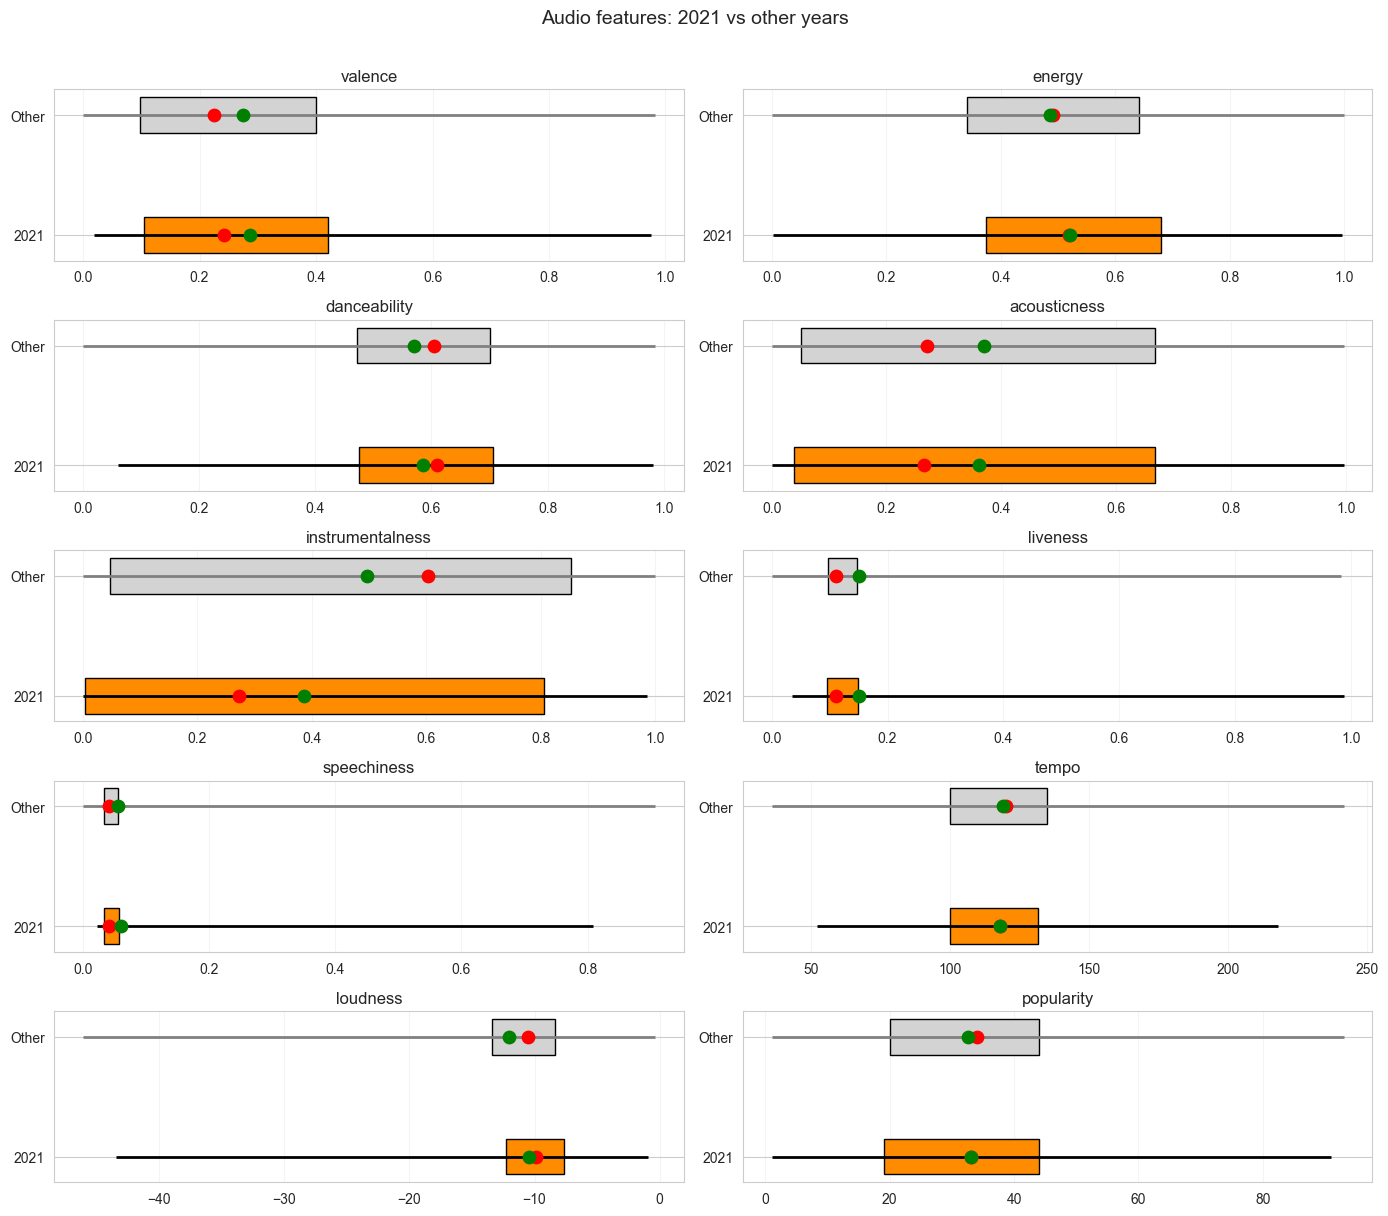


🎵 Genre profile for 2021:
⚠️ 2021: 44.9% tracks without genre — genre conclusions limited.
⚠️ Other years: 44.9% tracks without genre — genre conclusions limited.


,Genre,2021,Other years
№,,,
1,coldwave,0.0,2519.0
2,darkwave,0.0,1958.0
3,downtempo,435.0,5469.0
4,melodic house,442.0,0.0
5,melodic techno,438.0,0.0
6,organic house,0.0,2537.0
7,techno,300.0,0.0
8,trip hop,388.0,5415.0


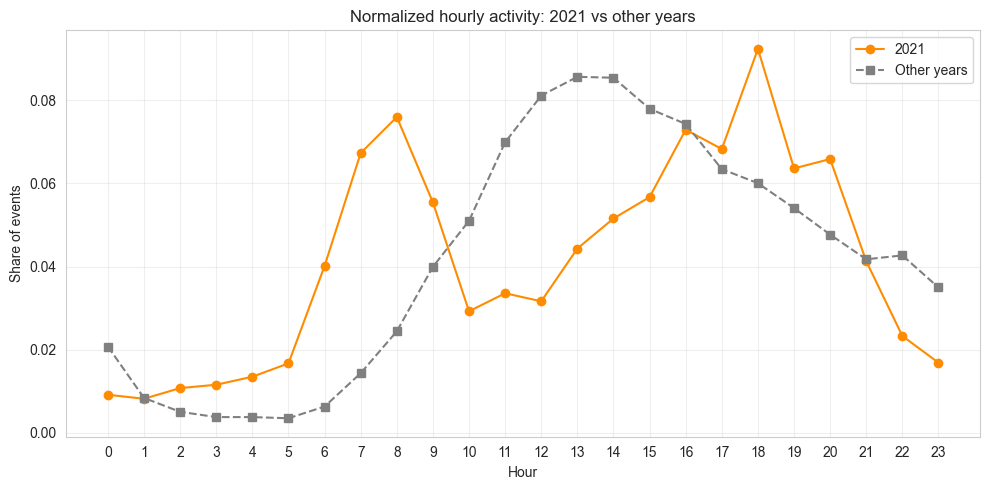


📝 Conclusion for 2021:
   Significantly above background: valence, energy, danceability, speechiness, loudness
   Significantly below background: acousticness, instrumentalness
   Top genres: melodic house, melodic techno, downtempo
   Daily peak hour: 18:00



In [174]:
# 3.4 Детальный анализ годов-лидеров

# Запускается только если в 3.3 определён год-лидер (концентрация гипотез > 35%).
# Для каждого года-лидера:
#   1. Сравниваем средние характеристики с «фоном» (все остальные годы).
#   2. Проверяем, какие отклонения превышают порог 2% от фона.
#   3. Строим range plot по всем характеристикам.
#   4. Смотрим жанровый профиль и долю unknown.
#   5. Смотрим суточный профиль активности.
#   6. Формируем краткий вывод.
#
# FEATURES_RAW — из блока 0.
# leader_years — из 3.3.

if 'hyp_df' not in globals():
    raise ValueError('hyp_df not found. Run cell 3.2 first.')

if 'leader_years' not in globals():
    raise ValueError('leader_years not found. Run cell 3.3 first.')

if not leader_years:
    print('ℹ️ No leader years — 3.4 skipped.')
else:
    top_year_list = leader_years
    print(f'🔍 Years for detailed analysis: {top_year_list}\n')

    for target_year in top_year_list:
        print('=' * 70)
        print(f'   DETAILED ANALYSIS OF {target_year}')
        print('=' * 70)

        target_mask = df_deep['year'] == target_year
        other_mask = ~target_mask

        # --- 1. Средние значения ---
        # Средние и медианы — рядом, чтобы видеть, не искажено ли среднее хвостами.
        comp_mean = pd.DataFrame({
            f'{target_year}': df_deep[target_mask][FEATURES_RAW].mean(),
            'Other years': df_deep[other_mask][FEATURES_RAW].mean()
        }).round(3)

        comp_median = pd.DataFrame({
            f'{target_year}': df_deep[target_mask][FEATURES_RAW].median(),
            'Other years': df_deep[other_mask][FEATURES_RAW].median()
        }).round(3)

        print(f'\n📊 Mean features: {target_year} vs other years')
        comp_display = comp_mean.reset_index()
        comp_display.columns = ['Feature', f'{target_year}', 'Other years']
        comp_display.index = comp_display.index + 1
        comp_display.index.name = '№'
        display(comp_display)

        print(f'\n📊 Median features: {target_year} vs other years')
        comp_median_display = comp_median.reset_index()
        comp_median_display.columns = ['Feature', f'{target_year}', 'Other years']
        comp_median_display.index = comp_median_display.index + 1
        comp_median_display.index.name = '№'
        display(comp_median_display)

        # Проверка расхождения mean/median в целевом году.
        # Порог — 5% от шкалы характеристики.
        diff_yr = (comp_mean[f'{target_year}'] - comp_median[f'{target_year}']).abs()
        ranges_s = pd.Series(FEATURE_RANGES)
        flagged = diff_yr[diff_yr > ranges_s * 0.05]
        if len(flagged) > 0:
            print(f'\n⚠️ {target_year}: mean/median divergence > 5% of scale:')
            for feat, val in flagged.items():
                print(f'   • {feat}: {val:.3f}')
            print('   Means may be skewed by heavy tails. Interpret with caution.')
        else:
            print(f'\n✅ {target_year}: mean and median are close for all features.')

        # --- 2. Диагностика отклонений от фона ---
        # Порог 2% от фонового среднего — эвристический.
        mean_other = df_deep[other_mask][FEATURES_RAW].mean()
        diff = df_deep[target_mask][FEATURES_RAW].mean() - mean_other

        # То же отклонение, но по медианам — для проверки устойчивости.
        median_other = df_deep[other_mask][FEATURES_RAW].median()
        diff_median = df_deep[target_mask][FEATURES_RAW].median() - median_other

        threshold = 0.02 * mean_other.abs()
        diag = pd.DataFrame({
            'Diff (mean)': diff,
            'Diff (median)': diff_median,
            'Threshold (2%)': threshold,
            'Exceeds (mean)': abs(diff) > threshold,
        }).round(3)

        print(f'\n📊 Deviation from background (threshold 2%):')

        diag_display = diag.reset_index()
        diag_display.columns = ['Feature', 'Diff (mean)', 'Diff (median)', 'Threshold (2%)', 'Exceeds (mean)']
        diag_display.index = diag_display.index + 1
        diag_display.index.name = '№'
        display(diag_display)

        # --- 3. Range plot по всем характеристикам ---
        fig, axes = plt.subplots(5, 2, figsize=(14, 12))
        axes = axes.flatten()

        for i, feat in enumerate(FEATURES_RAW):
            ax = axes[i]

            data_target = df_deep[target_mask][feat].dropna()
            data_other = df_deep[other_mask][feat].dropna()

            t_q1, t_q3 = data_target.quantile([0.25, 0.75])
            o_q1, o_q3 = data_other.quantile([0.25, 0.75])

            t_med, o_med = data_target.median(), data_other.median()
            t_mean, o_mean = data_target.mean(), data_other.mean()
            t_min, t_max = data_target.min(), data_target.max()
            o_min, o_max = data_other.min(), data_other.max()

            # Верхняя полоса — целевой год. Нижняя — фон.
            ax.hlines(y=0, xmin=t_min, xmax=t_max, color='black', linewidth=2)
            ax.barh(y=0, width=t_q3 - t_q1, left=t_q1, height=0.3, color='darkorange', edgecolor='black')
            ax.scatter(t_med, 0, color='red', s=80, zorder=5)
            ax.scatter(t_mean, 0, color='green', s=80, zorder=5)

            ax.hlines(y=1, xmin=o_min, xmax=o_max, color='gray', linewidth=2)
            ax.barh(y=1, width=o_q3 - o_q1, left=o_q1, height=0.3, color='lightgray', edgecolor='black')
            ax.scatter(o_med, 1, color='red', s=80, zorder=5)
            ax.scatter(o_mean, 1, color='green', s=80, zorder=5)

            ax.set_yticks([0, 1])
            ax.set_yticklabels([str(target_year), 'Other'])
            ax.set_title(feat)

            left_lim = min(t_min, o_min) - 0.05 * abs(max(t_max, o_max) - min(t_min, o_min))
            right_lim = max(t_max, o_max) + 0.05 * abs(max(t_max, o_max) - min(t_min, o_min))
            ax.set_xlim(left_lim, right_lim)
            ax.grid(axis='x', alpha=0.2)

        plt.suptitle(f'Audio features: {target_year} vs other years', fontsize=14, y=1.01)
        plt.tight_layout()
        plt.show()

        # --- 4. Жанровый профиль ---
        print(f'\n🎵 Genre profile for {target_year}:')

        target_events = df_deep[target_mask]
        other_events = df_deep[other_mask]

        # Обязательная проверка доли unknown перед жанровыми выводами.
        show_unknown_share(target_events, f'{target_year}')
        show_unknown_share(other_events, 'Other years')

        # Топ-5 известных жанров в целевом году и в фоне.
        target_genres = (
            target_events[target_events['genres_normalized'] != 'unknown']['genres_normalized']
            .str.split(',').explode().str.strip()
        )
        other_genres = (
            other_events[other_events['genres_normalized'] != 'unknown']['genres_normalized']
            .str.split(',').explode().str.strip()
        )

        top_target = target_genres.value_counts().head(5)
        top_other = other_genres.value_counts().head(5)

        genre_comp = pd.DataFrame({
            f'{target_year}': top_target,
            'Other years': top_other
        }).fillna(0).round(0)

        genre_comp_display = genre_comp.reset_index()
        genre_comp_display.columns = ['Genre', f'{target_year}', 'Other years']
        genre_comp_display.index = genre_comp_display.index + 1
        genre_comp_display.index.name = '№'
        display(genre_comp_display)

        # --- 5. Суточный профиль активности ---
        hourly_target = df_deep[target_mask].groupby('hour').size()
        hourly_other = df_deep[other_mask].groupby('hour').size()

        hourly_target_norm = hourly_target / hourly_target.sum()
        hourly_other_norm = hourly_other / hourly_other.sum()

        plt.figure(figsize=(10, 5))
        plt.plot(hourly_target_norm.index, hourly_target_norm.values, marker='o',
                 label=f'{target_year}', color='darkorange')
        plt.plot(hourly_other_norm.index, hourly_other_norm.values, marker='s',
                 label='Other years', color='gray', linestyle='--')
        plt.title(f'Normalized hourly activity: {target_year} vs other years')
        plt.xlabel('Hour')
        plt.ylabel('Share of events')
        plt.xticks(range(0, 24))
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # --- 6. Автоинтерпретация ---
        print(f'\n📝 Conclusion for {target_year}:')

        significant_up = [feat for feat in FEATURES_RAW if diff[feat] > threshold[feat]]
        significant_down = [feat for feat in FEATURES_RAW if diff[feat] < -threshold[feat]]

        if significant_up:
            print(f'   Significantly above background: {", ".join(significant_up)}')
        if significant_down:
            print(f'   Significantly below background: {", ".join(significant_down)}')
        if not significant_up and not significant_down:
            print('   No features significantly differ from background.')

        print(f'   Top genres: {", ".join(top_target.index[:3])}')
        print(f'   Daily peak hour: {hourly_target_norm.idxmax()}:00')
        print()

### Вывод по блоку 3.4

Два года-лидера оказались противоположными полюсами. 2024 — год
синхронного провала, 2021 — год подъёма по тем же осям.

**2024.** Семь характеристик значимо ниже фона, две — выше.
Ниже: valence (−0.067), energy (−0.134), danceability (−0.138),
liveness (−0.009), speechiness (−0.003), loudness (−6.758),
popularity (−2.479). Выше: acousticness (+0.200) и instrumentalness
(+0.103). Tempo не превысил порог 2% ни вверх, ни вниз — от фона
не отличается.

Loudness требует оговорки: среднее сместилось на −6.758 дБ,
медиана — только на −2.826. Часть сдвига идёт за счёт хвоста очень
тихих треков. По медиане корректнее «тише на 2.83 дБ».

Valence даёт обратную асимметрию: медиана сдвинулась на −0.097,
среднее — на −0.067. В 2024 распределение valence потеряло верхний
край — треки с высокой valence почти исчезли.

**2021.** Пять характеристик выше фона, две ниже. Выше: valence
(+0.012), energy (+0.034), danceability (+0.015), speechiness
(+0.005), loudness (+1.636). Ниже: acousticness (−0.009),
instrumentalness (−0.111). Tempo, liveness и popularity порог 2%
не превысили.

Instrumentalness — главный сигнал 2021. Среднее сдвинулось на −0.111,
медиана — на −0.331, разница в 3 раза. Типичный трек года был
значительно менее инструментальным, чем средний по году.

Popularity в 2021 даёт расхождение знаков: среднее +0.469, медиана
−1.000. Год не был однородно более популярным — рост за счёт
отдельных очень популярных треков, типичный трек стал менее
популярным. 2021 — год крайностей.

**Что объединяет два года.** Оба выделяются на фоне остальных,
но по противоположным причинам. 2024 — минимум по семи
характеристикам, 2021 — максимум по пяти. По instrumentalness
картина зеркальная: в 2024 выше фона, в 2021 — сильно ниже.

**Ограничение по жанрам.** В 2024 доля треков без жанра — 60.7%,
в 2021 — 44.9%. Жанровые выводы по обоим годам ограничены.

**Час пика.** В 2024 — 13:00, в 2021 — 18:00.

## 3.5 Точечная проверка топ-5 гипотез



   INDIVIDUAL TOP-5 HYPOTHESIS CHECK


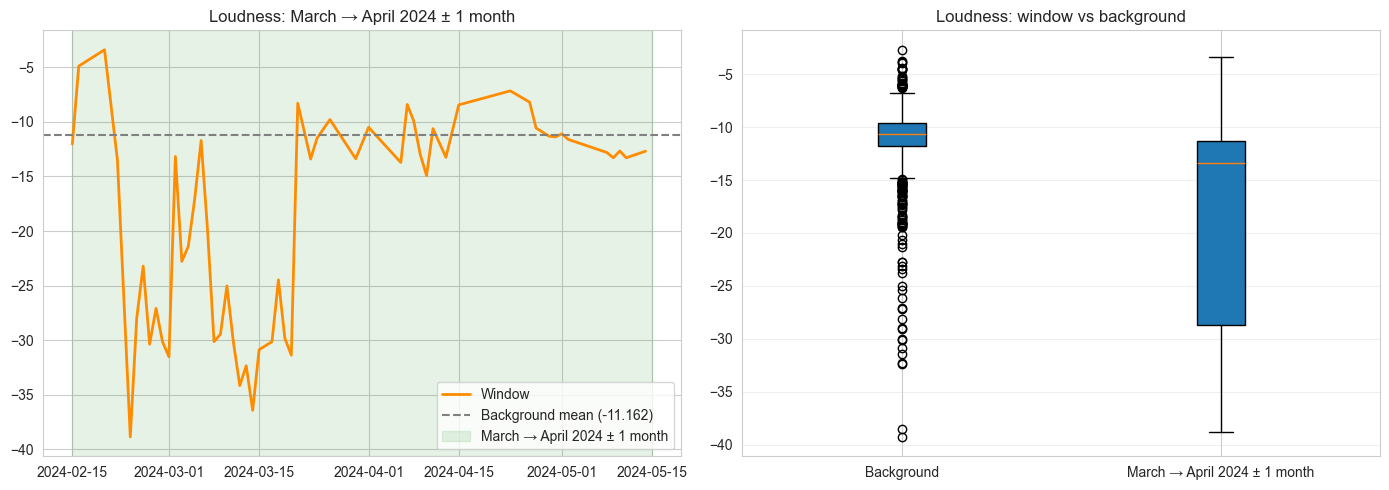

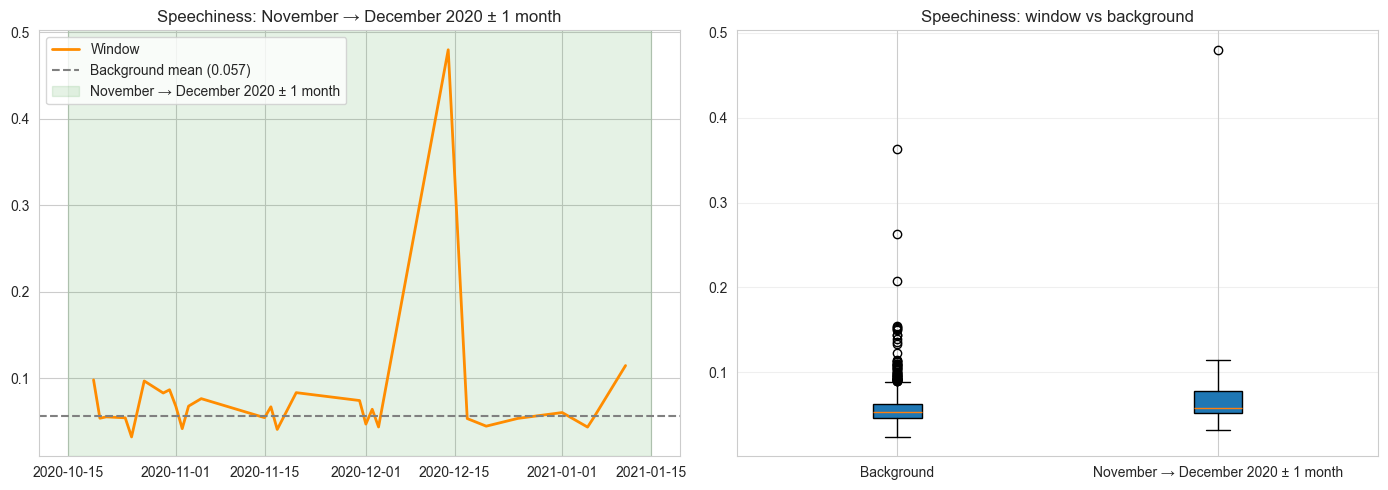

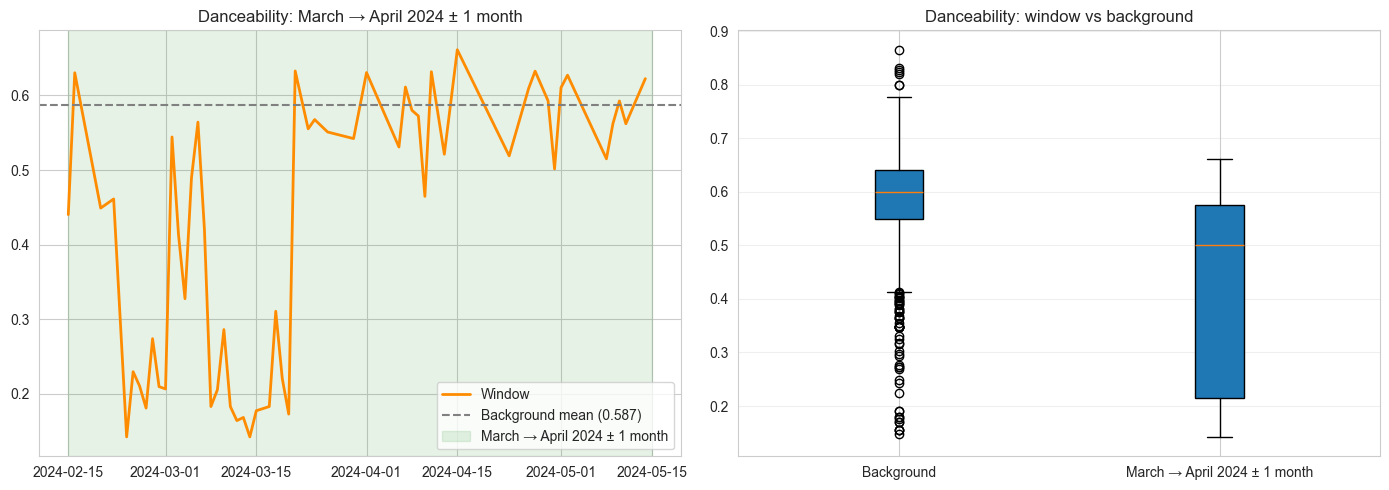

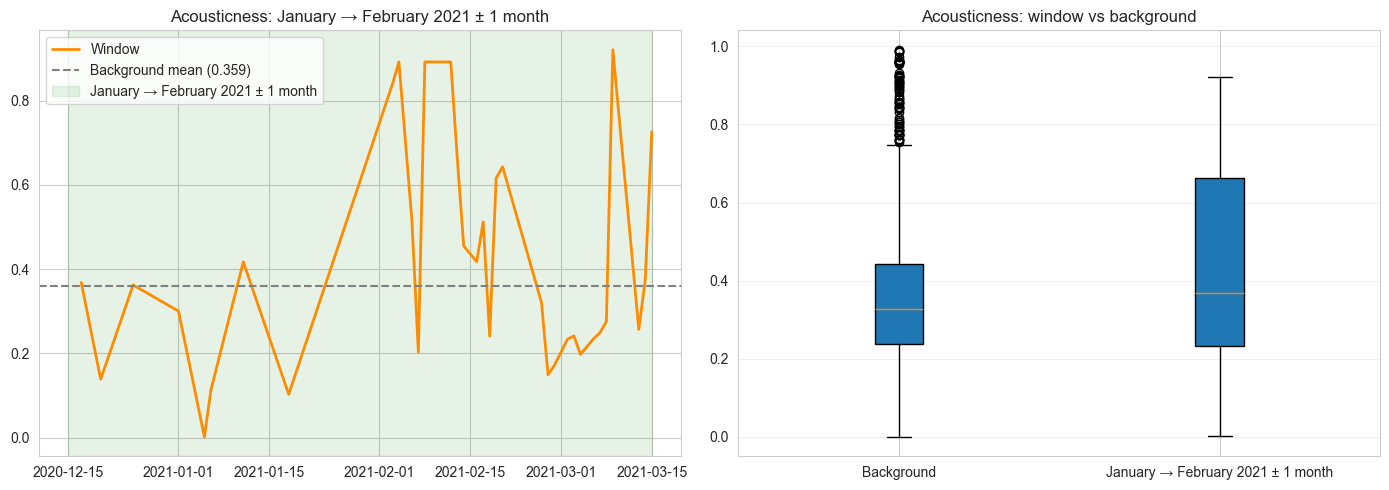

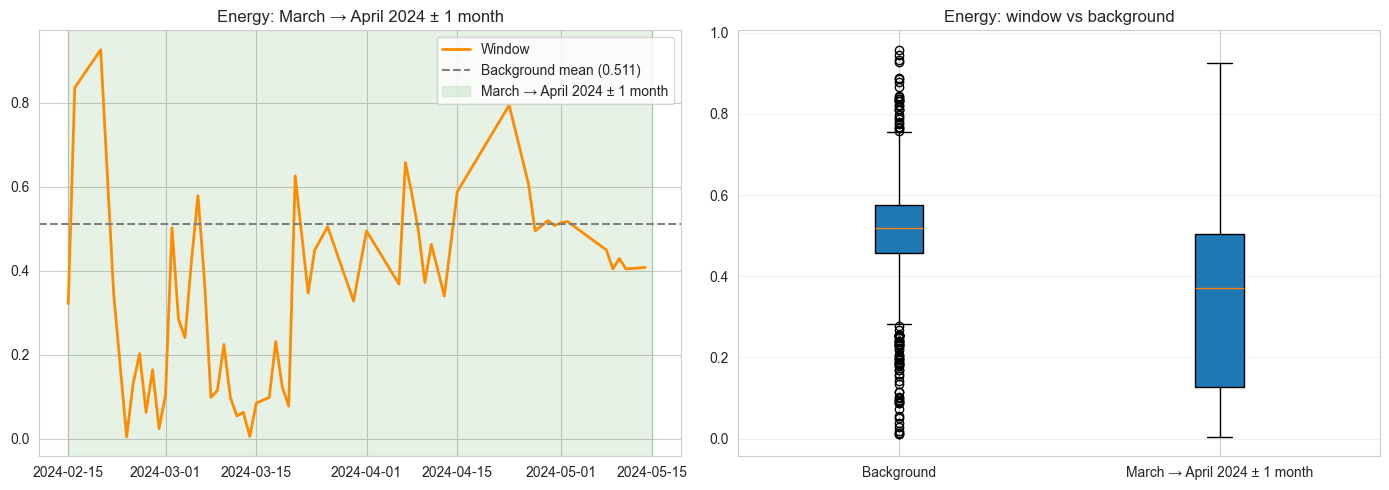


📊 Top-5 hypothesis check summary:


,Feature,Type,Details,Window,Window mean,Background mean,Diff,% of background,Z-score,Indicator,Interpretation
№,,,,,,,,,,,
1,Loudness,Contrast transition,2024: March → April (Δ=12.453),March → April 2024 ± 1 month,-18.332,-11.162,-7.171,-64.2,-2.13,🔴,Significant deviation
2,Speechiness,Contrast transition,2020: November → December (Δ=0.049),November → December 2020 ± 1 month,0.078,0.057,+0.021,+37.7,+1.03,🟡,Weak deviation
3,Danceability,Contrast transition,2024: March → April (Δ=0.233),March → April 2024 ± 1 month,0.429,0.587,-0.158,-27.0,-1.67,🟡,Weak deviation
4,Acousticness,Contrast transition,2021: January → February (Δ=0.397),January → February 2021 ± 1 month,0.449,0.359,+0.090,+25.1,+0.46,🟢,Within normal range
5,Energy,Contrast transition,2024: March → April (Δ=0.269),March → April 2024 ± 1 month,0.354,0.511,-0.157,-30.7,-1.23,🟡,Weak deviation



📌 Indicator legend:
   🔴 — significant deviation (|Z| ≥ 2)
   🟡 — weak deviation (1 ≤ |Z| < 2)
   🟢 — within normal range (|Z| < 1)


In [175]:
# 3.5 Точечная проверка топ-5 гипотез

# Выполняется всегда, независимо от наличия года-лидера.
# Логика проверки зависит от типа гипотезы — окно подбирается так,
# чтобы соответствовать временному масштабу гипотезы:
#
#   IQR outlier (year)    — окно ±6 месяцев вокруг года;
#   IQR outlier (month)   — окно ±1 месяц вокруг указанного месяца;
#   Trend                 — весь диапазон лет из Details;
#   Contrast transition   — окно ±1 месяц вокруг указанного перехода.
#
# Для каждой гипотезы считаем z-score: (window_mean − background_mean) / background_std.
# По |z| определяем индикатор: 🔴 значимое, 🟡 слабое, 🟢 в норме.
#
# Раньше окно было всегда ±6 месяцев, из-за чего контрастные переходы
# (локальные сдвиги внутри года) давали z около нуля. Теперь окно
# соответствует типу гипотезы.

if 'hyp_df' not in globals():
    raise ValueError('hyp_df not found. Run cell 3.2 first.')

if 'top5' not in globals():
    raise ValueError('top5 not found. Run cell 3.2 first.')


def _build_window(row):
    """
    Определяет окно проверки по типу гипотезы и её Details.

    Возвращает (start_date, end_date, window_label) или None, если
    не удалось определить окно.
    """
    htype = row['Type']
    details = row['Details']
    yrs = extract_years(details)
    if not yrs:
        return None

    if htype == 'IQR outlier (year)':
        # Гипотеза про год целиком — окно ±6 месяцев.
        yr = yrs[0]
        start = pd.Timestamp(f'{yr}-01-01') - pd.DateOffset(months=6)
        end = pd.Timestamp(f'{yr}-12-31') + pd.DateOffset(months=6)
        return start, end, f'{yr} ± 6 months'

    if htype == 'IQR outlier (month)':
        # Гипотеза про месяц — окно ±1 месяц вокруг указанного месяца.
        # В Details месяц записан словом (например, 'March'), поэтому парсим
        # название месяца. Год — первое четырёхзначное число.
        yr = yrs[0]
        month_name_str = None
        for m in list(month_name):
            if m and m in details:
                month_name_str = m
                break
        if month_name_str is None:
            return None
        month_num = list(month_name).index(month_name_str)
        center = pd.Timestamp(year=yr, month=month_num, day=15)
        start = center - pd.DateOffset(months=1)
        end = center + pd.DateOffset(months=1)
        return start, end, f'{month_name_str} {yr} ± 1 month'

    if htype == 'Trend':
        # Гипотеза про период между двумя годами. Окно — от начала первого
        # года до конца второго.
        if len(yrs) < 2:
            return None
        start_yr, end_yr = min(yrs), max(yrs)
        start = pd.Timestamp(f'{start_yr}-01-01')
        end = pd.Timestamp(f'{end_yr}-12-31')
        return start, end, f'{start_yr}–{end_yr}'

    if htype == 'Contrast transition':
        # Гипотеза про резкий переход между двумя месяцами.
        # Details выглядит как '2024: March → April (Δ=...)'. Год — первое
        # четырёхзначное число, месяцы — два названия до и после стрелки.
        yr = yrs[0]
        arrow = '→'
        if arrow not in details:
            return None
        left_part, right_part = details.split(arrow, 1)
        month_left = None
        for m in list(month_name):
            if m and m in left_part:
                month_left = m
        month_right = None
        for m in list(month_name):
            if m and m in right_part:
                month_right = m
        if month_left is None or month_right is None:
            return None
        m_left_num = list(month_name).index(month_left)
        m_right_num = list(month_name).index(month_right)
        center_left = pd.Timestamp(year=yr, month=m_left_num, day=15)
        center_right = pd.Timestamp(year=yr, month=m_right_num, day=15)
        # Окно охватывает переход: от −1 месяца до +1 месяца относительно
        # каждой стороны. Итог — примерно 2 месяца вокруг перехода.
        start = min(center_left, center_right) - pd.DateOffset(months=1)
        end = max(center_left, center_right) + pd.DateOffset(months=1)
        return start, end, f'{month_left} → {month_right} {yr} ± 1 month'

    return None


print('\n' + '=' * 60)
print('   INDIVIDUAL TOP-5 HYPOTHESIS CHECK')
print('=' * 60)

summary_rows = []

for _, row in top5.iterrows():
    feature = row['Feature']
    htype = row['Type']
    details = row['Details']

    window_spec = _build_window(row)
    if window_spec is None:
        print(f'   ⚠️ {feature}: could not determine window for type "{htype}", skipping.')
        continue

    start_date, end_date, window_label = window_spec

    # Колонка в daily называется feature_mean (например, 'loudness_mean').
    col = feature.lower() + '_mean'
    if col not in daily.columns:
        print(f'   ⚠️ {feature}: column {col} not found in daily, skipping.')
        continue

    window = daily[(daily['date'] >= start_date) & (daily['date'] <= end_date)]
    background = daily[(daily['date'] < start_date) | (daily['date'] > end_date)]

    if len(window) < 5:
        print(f'   ⚠️ {feature}: insufficient data in window ({len(window)} days), skipping.')
        continue

    win_mean = window[col].mean()
    win_median = window[col].median()
    bg_mean = background[col].mean()
    bg_median = background[col].median()
    bg_std = background[col].std()

    diff_abs = win_mean - bg_mean
    diff_pct = (diff_abs / abs(bg_mean) * 100) if bg_mean != 0 else 0
    z_score = diff_abs / bg_std if bg_std and bg_std > 0 else 0

    if abs(z_score) >= 2:
        indicator = '🔴'
        interpretation = 'Significant deviation'
    elif abs(z_score) >= 1:
        indicator = '🟡'
        interpretation = 'Weak deviation'
    else:
        indicator = '🟢'
        interpretation = 'Within normal range'

    summary_rows.append({
        'Feature': feature,
        'Type': htype,
        'Details': details,
        'Window': window_label,
        'Window mean': f'{win_mean:.3f}',
        'Background mean': f'{bg_mean:.3f}',
        'Diff': f'{diff_abs:+.3f}',
        '% of background': f'{diff_pct:+.1f}',
        'Z-score': f'{z_score:+.2f}',
        'Indicator': indicator,
        'Interpretation': interpretation,
    })

    # --- Графики для гипотезы ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Левый: временной ряд в окне.
    axes[0].plot(window['date'], window[col], color='darkorange', linewidth=2, label='Window')
    axes[0].axhline(bg_mean, color='gray', linestyle='--', label=f'Background mean ({bg_mean:.3f})')
    axes[0].axvspan(start_date, end_date, alpha=0.1, color='green', label=window_label)
    axes[0].set_title(f'{feature}: {window_label}')
    axes[0].legend()

    # Правый: boxplot «фон vs окно».
    axes[1].boxplot(
        [background[col].dropna(), window[col].dropna()],
        tick_labels=['Background', window_label],
        patch_artist=True
    )
    axes[1].set_title(f'{feature}: window vs background')
    axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

# --- Сводная таблица ---
if summary_rows:
    summary_df = pd.DataFrame(summary_rows)
    summary_df.index = range(1, len(summary_df) + 1)
    summary_df.index.name = '№'
    print('\n📊 Top-5 hypothesis check summary:')
    display(summary_df)

    print('\n📌 Indicator legend:')
    print('   🔴 — significant deviation (|Z| ≥ 2)')
    print('   🟡 — weak deviation (1 ≤ |Z| < 2)')
    print('   🟢 — within normal range (|Z| < 1)')
else:
    print('\nℹ️ No hypotheses could be checked.')

### 3.5 Вывод

Ячейка проверяет каждую гипотезу из топ-5 в окне, соответствующем
её типу. Для контрастных переходов окно — ±1 месяц вокруг перехода.
Внутри окна считается среднее, сравнивается с фоном (все остальные
дни), отклонение нормируется на фоновое стандартное отклонение —
получается z-score. По |z| гипотеза помечается: 🔴 значимая (≥2),
🟡 слабая (1–2), 🟢 в норме (<1).

**Результат: из пяти гипотез только одна значимая.** Loudness,
март → апрель 2024 — z=−2.13. Окно в этом интервале даёт среднюю
громкость −18.332 дБ против фоновых −11.162: разница −7.17 дБ,
или −64% от фона. Это не локальный всплеск, а устойчивое смещение
на два месяца.

Три гипотезы слабые. Danceability, март → апрель 2024 (z=−1.67):
окно 0.429 против фона 0.587, −27%. Energy, там же (z=−1.23):
окно 0.354 против фона 0.511, −31%. Speechiness, ноябрь → декабрь
2020 (z=+1.03): окно 0.078 против фона 0.057, +37.7%. Все три
отклонения в сторону от фона, но по силе не дотягивают до
значимых. Speechiness 2020 — единственный из слабых в неполном
году; отклонение может быть артефактом обрезки истории.

Одна гипотеза в норме. Acousticness, январь → февраль 2021
(z=+0.46): окно 0.449 против фона 0.359, +25%. Процентное
отклонение заметное, но z-score низкий — значит, на фоне общей
изменчивости этой характеристики такое отклонение не выделяется.

**Что показывают графики.** Слева для каждой гипотезы — дневные
значения в окне, без сглаживания. Именно они объясняют расхождение
между «силой перехода» из 3.2 и z-score.

Loudness и Energy в марте 2024 дают картину устойчивого сдвига:
в первой половине марта значения проваливаются до −35 дБ (для
loudness) и до 0.05–0.1 (для energy), затем к середине апреля
возвращаются к норме. Boxplot подтверждает: медиана окна смещена
вниз, но главное — нижняя граница ящика уходит далеко от фоновой.
Это не один выброс, а смещение в течение нескольких недель.

Danceability того же периода — похожая картина: в начале марта
значения доходят до 0.15–0.2, но уже к 15 марта выходят на 0.5–0.6.
Сдвиг есть, но он короче по длительности, чем у Loudness, —
поэтому слабая, а не значимая (z=−1.67 при пороге 2).

Acousticness январь–февраль 2021 на графике — не сдвиг, а шум.
Значения скачут от 0.05 до 0.9 и обратно в пределах недели,
без направленного движения. В boxplot медианы окна и фона почти
совпадают. «Переход» в 3.2 поймал один резкий скачок между двумя
месяцами, но на всём окне он растворяется: характеристика остаётся
такой же, какой была. Именно это показывает z=+0.46 — в норме.

Speechiness ноябрь–декабрь 2020 — тот же случай, что Acousticness
2021, но слабее выражен. По графику видно короткое окно с небольшим
числом событий. Отклонение есть, но на границе шума. Неполный год
и близость к началу истории делают оценку менее надёжной.

**Главное — расхождение порядка.** Ранжирование по силе перехода
(3.2) и ранжирование по z-score (3.5) дают разный порядок. По силе:
Loudness 4.30 → Speechiness 4.05 → Danceability 3.42 → Acousticness
2.72 → Energy 2.67. По z-score: Loudness −2.13 → Danceability −1.67
→ Energy −1.23 → Speechiness +1.03 → Acousticness +0.46.

Speechiness, второй по силе перехода, по z-score оказывается
четвёртым — между Energy и Acousticness. Разница в том, что «сила»
в 3.2 измеряет резкость сдвига между двумя соседними месяцами
относительно типичного месячного разброса, а z-score в 3.5 —
насколько значение в окне отличается от среднего за весь период.
Переход может быть резким локально, но не выделяться на фоне общей
изменчивости — это и произошло с Speechiness 2020 и Acousticness 2021.

**Что это даёт блоку.** Топ-5 по силе перехода — список кандидатов,
не список подтверждённых аномалий. После проверки в правильном окне
остаётся одна значимая гипотеза — Loudness, март → апрель 2024.
Остальные четыре — либо слабые (Danceability, Energy, Speechiness),
либо в норме (Acousticness). Это не провал 3.1 и 3.2: переходы
действительно были резкими, но резкость на двухмесячном интервале
не обязательно означает значимое отклонение от всей истории.
Из пяти сильнейших событий за шесть лет только одно оказалось
устойчивым сдвигом, и графики это подтверждают — остальные
распадаются на шум или на отдельные экстремальные дни.

**Ограничение.** Проверка идёт в окне ±1 месяц вокруг перехода —
примерно два месяца данных. При таком объёме z-score чувствителен
к нескольким экстремальным дням внутри окна: если в марте 2024
попалась пара очень тихих сессий, среднее по окну сместится сильнее,
чем реальный сдвиг. Медиана в окне не считалась, поэтому устойчивость
значимости Loudness к выбросам не проверена отдельно. По графикам
видно, что у Loudness сдвиг выглядит устойчивым (недели, не дни),
а у Speechiness 2020 — наоборот, держится на нескольких точках.
Это качественная оценка, не замена количественной.

## Блок 3. Вывод

За шесть лет в профиле нашлись два года-полюса — 2024 и 2021, —
противоположные по направлению сдвига. Оба выделяются на фоне
остальных по нескольким характеристикам сразу, а не по одной.
Но после проверки в правильном временном окне из пяти сильнейших
сигналов устойчивым оказывается только один — резкий провал
громкости в марте → апреле 2024. Остальные распадаются: либо
слабые, либо шум.

---

**Год синхронного провала — 2024**

Семь характеристик значимо ниже фона: valence, energy, danceability,
liveness, speechiness, loudness, popularity. Две выше: acousticness
и instrumentalness. Это не точечный сдвиг, а разворот профиля —
год тише, менее энергичный, менее танцевальный, менее популярный
и одновременно более акустический и инструментальный.

Loudness требует оговорки: среднее сместилось на −6.76 дБ, медиана —
только на −2.83. Часть сдвига идёт за счёт хвоста очень тихих
треков. По медиане корректнее «тише на 2.83 дБ».

---

**Противоположный полюс — 2021**

Пять характеристик выше фона: valence, energy, danceability,
speechiness, loudness. Две ниже: acousticness, instrumentalness.
Профиль развёрнут в обратную сторону — громче, энергичнее,
танцевальнее, менее инструментальный.

Instrumentalness даёт сильнейший сигнал: среднее сдвинулось
на −0.111, медиана — на −0.331. Типичный трек года был значительно
менее инструментальным, чем средний по году. Popularity показывает
расхождение знаков: среднее +0.47, медиана −1.00. Год крайностей —
очень популярное рядом с нишевым, а не однородный сдвиг.

---

**Что даёт проверка топ-5**

Топ-5 по силе перехода: Loudness (2024), Speechiness (2020),
Danceability (2024), Acousticness (2021), Energy (2024).
При проверке в окне ±1 месяц вокруг каждого перехода значимой
оказывается только одна гипотеза — Loudness, март → апрель 2024
(z=−2.13, окно −7.17 дБ от фона).

Danceability, Energy и Speechiness — слабые (z=−1.67, −1.23 и +1.03):
отклонения в сторону от фона, но по силе не дотягивают до значимых.
Acousticness 2021 — в норме (z=+0.46).

Графики объясняют, почему. У Loudness и Energy в марте 2024 виден
устойчивый сдвиг на несколько недель — нижняя граница boxplot уходит
далеко от фоновой. У Danceability сдвиг есть, но короче.
У Acousticness 2021 — не сдвиг, а шум: значения скачут от 0.05 до 0.9
в пределах недели. У Speechiness 2020 отклонение есть, но держится
на нескольких точках, и год неполный — оценка менее надёжна.

---

**Расхождение порядка**

Ранжирование по силе перехода и ранжирование по z-score дают разный
порядок. По силе Speechiness стоит вторым, по z-score — четвёртым.
Acousticness, четвёртый по силе, по z-score последний. Это не
противоречие: две метрики отвечают на разные вопросы. «Сила» измеряет
резкость сдвига между соседними месяцами, z-score — отклонение окна
от всей истории. Переход может быть резким локально, но не выделяться
на фоне общей изменчивости — это и произошло с Speechiness 2020
и Acousticness 2021.

---

**Синхронный переход марта → апреля 2024**

Четыре из пяти сильнейших переходов приходятся на 2024, три из них —
март → апрель. В этом переходе одновременно сдвинулись пять
характеристик: valence, energy, danceability, acousticness, loudness.
Но значимым по z-score из них оказывается только Loudness. Остальные
либо слабые, либо в норме. Синхронность сдвига подтверждается,
но устойчивость — только у одной характеристики.

---

**Ограничение**

2020 и 2026 — неполные годы, значения менее устойчивы. В 3.1 и 3.2
они не исключаются из расчёта — переходы 2020 года участвуют наравне
с полными, но помечены как менее надёжные. IQR-детекция по годам
работает на 5–7 точках: один год сдвигает Q1 или Q3, и порог
меняется. «Выброс» здесь означает «год заметно выбивается сильнее
остальных», а не статистически строгую аномалию.

Жанровые выводы по годам-лидерам делать нельзя: в 2024 доля треков
без жанра — 60.7%, в 2021 — 44.9%. В обоих случаях порог >50%
блокирует интерпретацию, >30% её ограничивает.

Проверка топ-5 идёт в окне ±1 месяц. При таком объёме z-score
чувствителен к нескольким экстремальным дням: медиана в окне
не считалась, устойчивость значимости Loudness к выбросам
не проверена отдельно.

# Блок 4. Эволюция аудио-профиля по годам


## 4. Эволюция аудио-профиля по годам

Блок 2 дал один сдвиг между половинами периода. Блок 3 нашёл аномальные
годы и переходы. Но ни то, ни другое не показывает пошаговую картину:
как менялось среднее год за годом и поквартально. Блок 4 восполняет
это — он смотрит на динамику без поиска аномалий, просто как ряд.

**Методология.** Все характеристики измеряются в разных шкалах: valence
лежит в [0, 1], tempo — в [10, 300], popularity — в [0, 100]. Прямое
сравнение разброса между ними бессмысленно: tempo автоматически
получит большие числа, даже если менялся слабо. Поэтому используются
две нормировки.

**Z-score по годам.** Для каждой характеристики считается среднее
по каждому году, затем из каждого годового значения вычитается
среднее за все годы и делится на стандартное отклонение. Получается
матрица «на сколько разбросов год отклонился от типичного». Это
позволяет видеть на одной тепловой карте, какие годы и какие
характеристики одновременно выбиваются — без искажения от шкалы.

**Нормированная дисперсия.** Чтобы понять, какие характеристики
изменились сильнее всего, берётся дисперсия годовых средних и делится
на квадрат диапазона шкалы: `var / range²`. Это даёт «долю разброса
от возможного». Без такой нормировки tempo и popularity всегда были
бы в топе просто потому, что у них большие числа. С нормировкой
наверх поднимаются те характеристики, у которых разброс велик
относительно их собственного допустимого интервала.

**Mean vs median по годам.** Среднее чувствительно к хвостам: если
в каком-то году много коротких событий с экстремальными значениями,
среднее уедет, а медиана останется. Параллельно считается медиана,
и если расхождение больше 5% от шкалы характеристики — год помечается
как потенциально скошенный. Это та же защита, что в блоке 3, но
на годовом масштабе.

**Квартальный дрейф.** Годы — крупный масштаб, кварталы ловят
сезонность и более короткие сдвиги. Квартальные средние считаются
по 5 характеристикам (valence, energy, danceability, acousticness,
instrumentalness) и сглаживаются скользящим окном в 3 квартала —
это убирает квартальный шум и оставляет общий тренд. Медианы
по кварталам считаются без сглаживания, для контроля.

**Пики в сглаженных рядах.** Точка считается пиком, если её изменение
относительно предыдущего квартала больше, чем `mean + 1.5 × std`
среди всех изменений ряда. Это **эвристика, не статистический тест**:
порог подобран эмпирически, ложные срабатывания возможны. Пики
используются как подсказка для визуального просмотра, а не как
утверждение об аномалии. Тот же статус, что у порогов 1.5×IQR
и 2σ в блоке 3.

**Жанровый дрейф.** Параллельно с аудио-характеристиками смотрится,
как менялась доля топ-5 жанров по кварталам. Это отвечает на вопрос,
менялось ли жанровое ядро — или аудио-сдвиг происходил внутри тех же
жанров.

**Как устроен блок.** Две ячейки идут последовательно.

- **4.1** — годовая эволюция: средние по годам, z-score heatmap,
  топ-3 характеристики по нормированной дисперсии с линейными
  графиками, проверка расхождения среднего и медианы.
- **4.2** — квартальный дрейф: сглаженные средние и медианы
  по кварталам, эвристические пики, жанровый дрейф по топ-5.

**Что блок даёт на выходе.** Пошаговую картину движения профиля:
какие годы и кварталы были крайними, какие характеристики менялись
сильнее других (с учётом шкалы), менялось ли жанровое ядро. Это мост
между трендом 2.1 (один сдвиг за весь период) и аномалиями 3.1
(локальные выбросы). Здесь — сама траектория, без поиска выбросов.

## 4.1 Эволюция аудио-профиля по годам

ℹ️ Incomplete years included: [2020, 2026]. Interpret with caution.
📊 Mean audio features by year:


,year,valence,energy,danceability,acousticness,instrumentalness,liveness,speechiness,tempo,loudness,popularity
№,,,,,,,,,,,
1,2020,0.322,0.500,0.589,0.361,0.341,0.156,0.068,114.381,-10.976,36.421
2,2021,0.287,0.521,0.585,0.362,0.385,0.151,0.061,117.855,-10.441,33.135
3,2022,0.330,0.542,0.624,0.299,0.372,0.153,0.062,119.732,-10.186,26.032
4,2023,0.295,0.441,0.568,0.449,0.485,0.148,0.055,116.410,-12.293,35.083
5,2024,0.217,0.374,0.450,0.545,0.572,0.143,0.054,119.756,-17.778,30.454
6,2025,0.266,0.500,0.593,0.338,0.517,0.152,0.056,119.142,-11.255,33.368
7,2026,0.263,0.550,0.571,0.273,0.537,0.157,0.052,121.045,-10.533,34.689


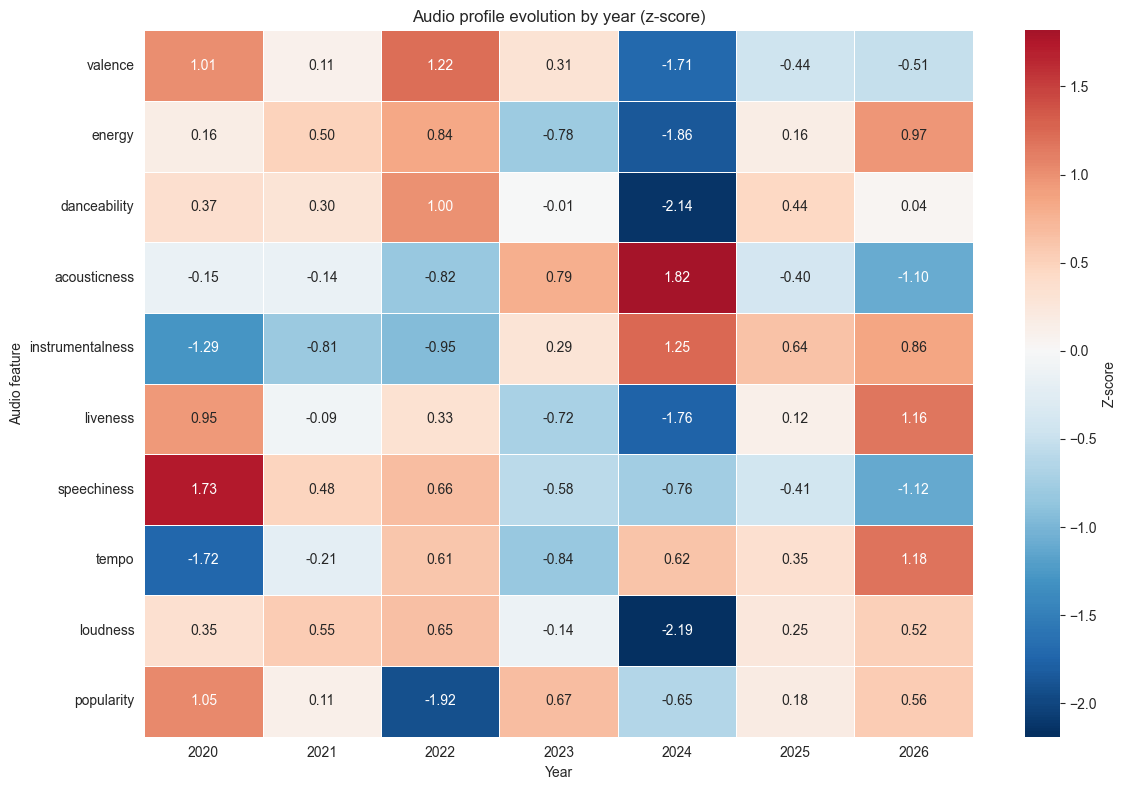

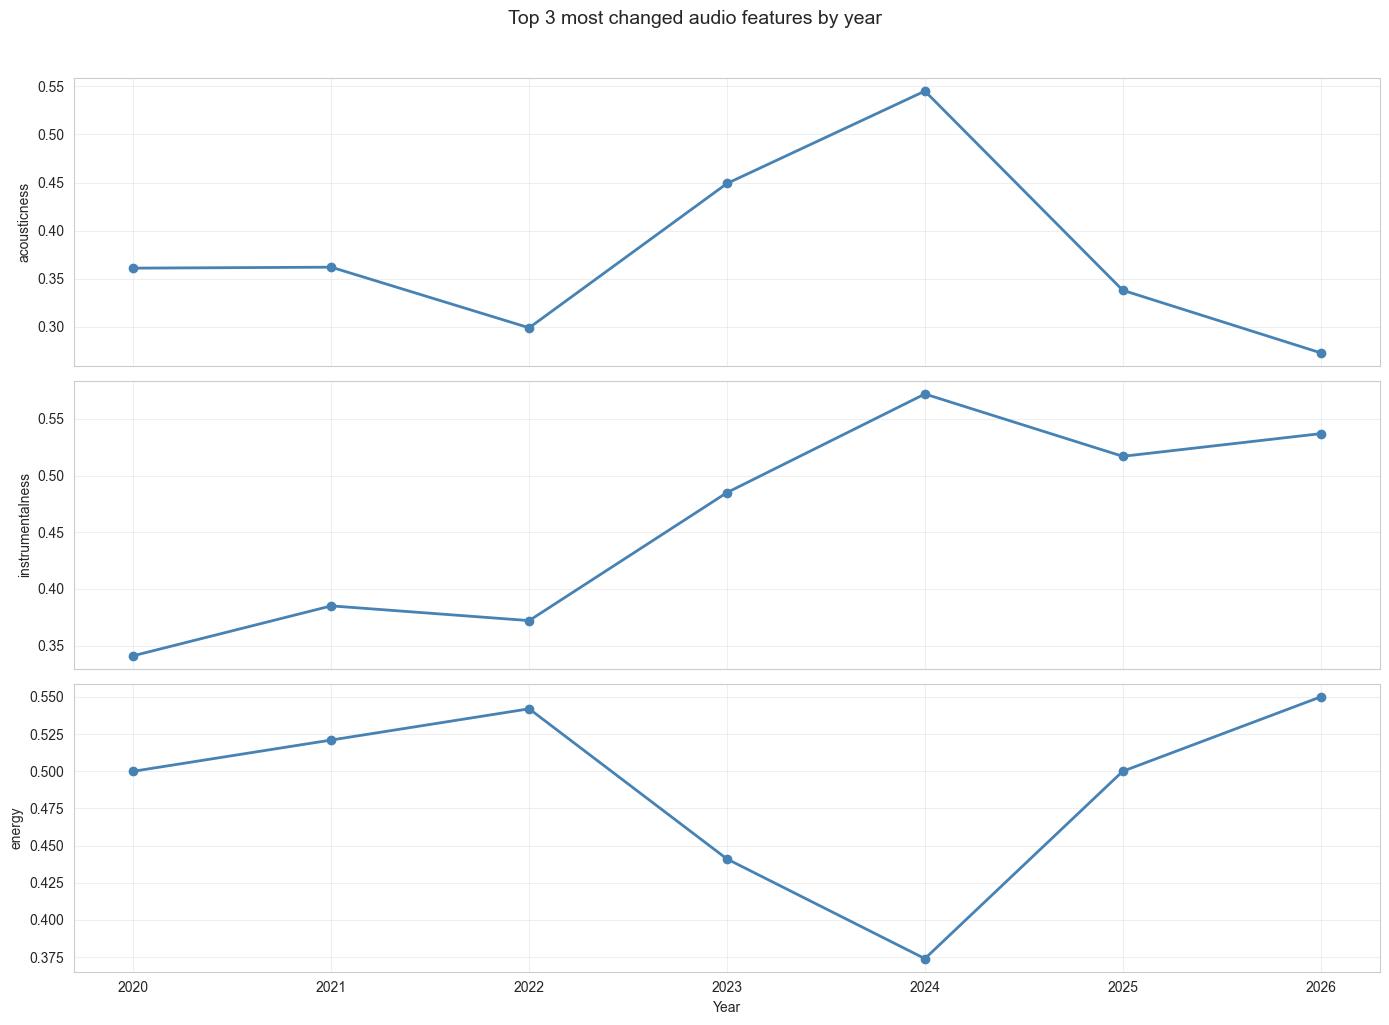


🔍 Interpretation:
   Top 3 by normalized variance: ['acousticness', 'instrumentalness', 'energy']
   • acousticness: max in 2024, min in 2026 (span 0.272)
   • instrumentalness: max in 2024, min in 2020 (span 0.231)
   • energy: max in 2026, min in 2024 (span 0.176)


In [176]:
# 4.1 Эволюция аудио-профиля по годам

# Блок 2.1 показал общий сдвиг — сравнение первой и второй половин периода.
# Здесь — пошаговая картина: как менялось среднее год за годом.
# Это мост между трендами (2.1) и календарными аномалиями (3.1).
#
# Что считаем:
#   1. Средние по годам для 10 характеристик.
#   2. Z-score по годам: (значение − среднее) / std.
#      Нужно, потому что шкалы разные (tempo — сотни, valence — доли).
#   3. Дисперсия по годам — ранжирование характеристик по изменчивости.
#      Три самых изменчивых идут на отдельные графики.
#
# ВАЖНО про дисперсию: в абсолютных единицах она чувствительна к масштабу.
# popularity (0–100) и tempo (10–300) автоматически получают большие
# значения, даже если менялись слабо. Поэтому нормируем на диапазон шкалы
# каждой характеристики — получаем «долю разброса от возможного».
#
# FEATURES_RAW — из блока 0.

if incomplete_years:
    print(f'ℹ️ Incomplete years included: {incomplete_years}. Interpret with caution.')

# --- Средние по годам ---
yearly_means = df_deep.groupby('year')[FEATURES_RAW].mean().round(3)

print('📊 Mean audio features by year:')
yearly_display = yearly_means.reset_index()
yearly_display.index = range(1, len(yearly_display) + 1)
yearly_display.index.name = '№'
display(yearly_display)

# --- Нормированные z-score по годам ---
# Для каждой характеристики вычитаем среднее и делим на std.
# Получаем матрицу «на сколько разбросов год отклонился от типичного».
z_yearly = (yearly_means - yearly_means.mean()) / yearly_means.std()

plt.figure(figsize=(12, 8))
sns.heatmap(
    z_yearly.T,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Z-score'}
)
plt.title('Audio profile evolution by year (z-score)')
plt.xlabel('Year')
plt.ylabel('Audio feature')
plt.tight_layout()
plt.show()



# Дисперсия, нормированная на квадрат диапазона — «доля разброса от возможного».
variance = yearly_means.var() / pd.Series(FEATURE_RANGES) ** 2
variance = variance.sort_values(ascending=False)
top3 = variance.head(3).index.tolist()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, feat in enumerate(top3):
    ax = axes[i]
    ax.plot(yearly_means.index, yearly_means[feat], marker='o', linewidth=2, color='steelblue')
    ax.set_ylabel(feat)
    ax.grid(True, alpha=0.3)

plt.suptitle('Top 3 most changed audio features by year', fontsize=14, y=1.02)
plt.xlabel('Year')
plt.tight_layout()
plt.show()

# --- Автоинтерпретация ---
print('\n🔍 Interpretation:')
print(f'   Top 3 by normalized variance: {top3}')
for feat in top3:
    max_year = yearly_means[feat].idxmax()
    min_year = yearly_means[feat].idxmin()
    span = yearly_means[feat].max() - yearly_means[feat].min()
    print(f'   • {feat}: max in {max_year}, min in {min_year} (span {span:.3f})')

### Вывод по блоку 4.1

Пошаговая картина подтверждает то, что блоки 2 и 3 показали на других
срезах: 2024 — центральная точка движения. По z-score heatmap именно
в этом году максимальное число характеристик одновременно отклоняется
от среднего за все годы. Три характеристики, изменившиеся сильнее
всего по нормированной дисперсии, сходятся на 2024 как на своей
крайней точке.

**2024 — год с наибольшим числом отклонений.** По z-score heatmap
в 2024 шесть характеристик отклоняются от среднего за все годы
сильнее, чем у любого другого года: valence −1.71, energy −1.86,
danceability −2.14, loudness −2.19 — вниз; acousticness +1.82,
instrumentalness +1.25 — вверх. 2020 тоже имеет четыре отклонения
(valence +1.01, speechiness +1.73, tempo −1.72, popularity +1.05),
но это неполный год. 2022 даёт два (valence +1.22, danceability
+1.00), 2026 — два (tempo +1.18, liveness +1.16). 2023 — ни одного.

**Топ-3 по нормированной дисперсии.** Acousticness, instrumentalness
и energy. Их траектории по годам различаются до 2024 и сходятся
после.

- Acousticness: почти плоская 2020–2022, резкий рост к 2024 (0.545),
  затем падение до 0.273 в 2026. Span — 0.272.
- Instrumentalness: рост с 0.341 в 2020 до 0.572 в 2024, лёгкий
  откат в 2025, снова рост к 2026. Span — 0.231.
- Energy: 0.542 в 2022, обвал до 0.374 в 2024, рост до 0.550 в 2026.
  Максимум за период — 2026 (0.550), минимум — 2024 (0.374).
  Span — 0.176.

Общий паттерн: у всех трёх 2024 — точка перелома. До неё траектории
разные, после — все три разворачиваются. 2024 не просто аномальный
год, а вершина длительного процесса.

**2026 — начало обратного движения.** Energy вернулась к уровню
2020–2021 (0.550), acousticness ушла на минимум за весь период
(0.273), instrumentalness остаётся высокой (0.537). Это согласуется
с двухфазным паттерном из 3.1. Но 2026 неполный, и «разворот» пока
опирается на неполный год.

**Ограничение self-relative.** Top-3 по нормированной дисперсии
и z-score считаются относительно собственной истории пользователя,
а не против внешнего эталона.

Нормировка `var / range²` даёт структурный перекос в пользу
характеристик с диапазоном [0, 1]: у них знаменатель равен 1,
а у tempo (290), loudness (60) и popularity (100) — сотни
и тысячи. Поэтому top-3 всегда собирается из долей.

**Ограничение по неполным годам.** 2020 и 2026 неполные.
Их z-scores менее надёжны. Для 2021–2025 значения устойчивее.

## 4.2 Квартальный дрейф: аудио и жанры

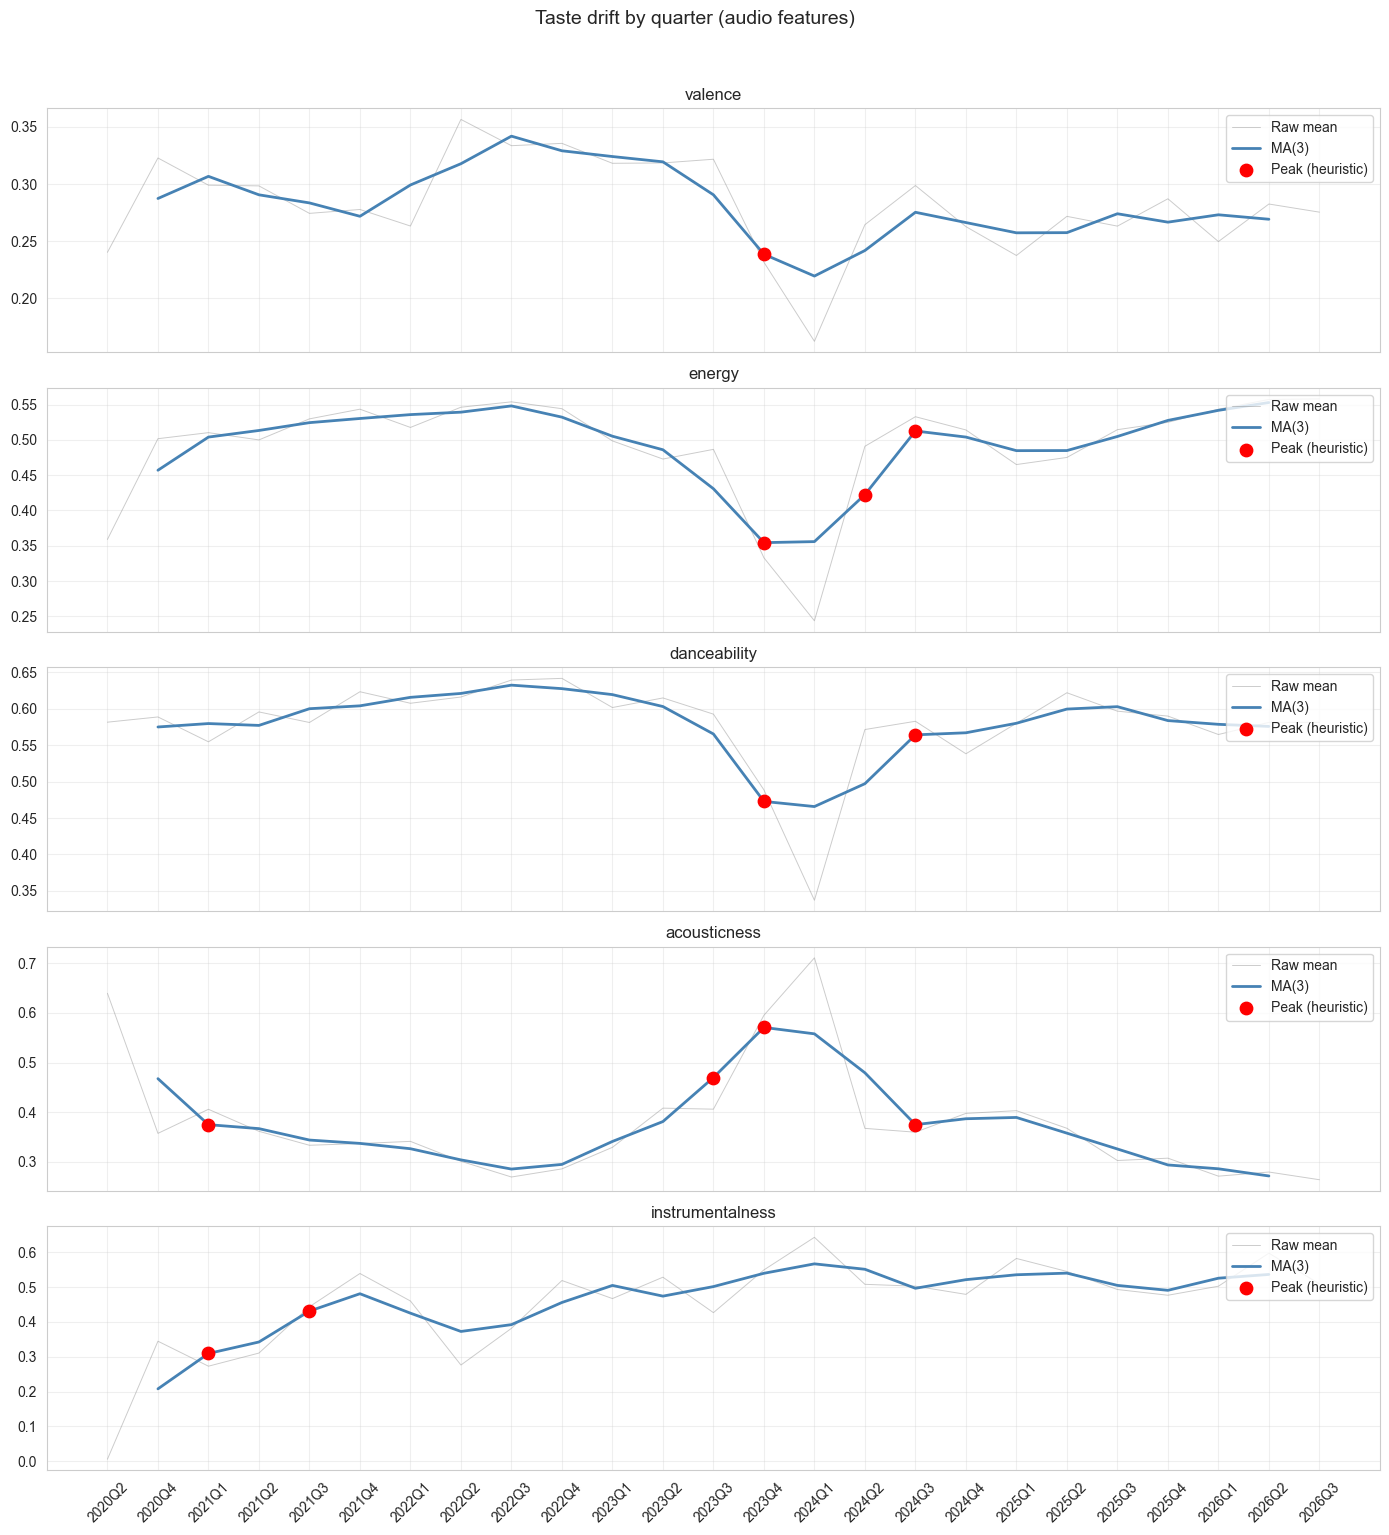

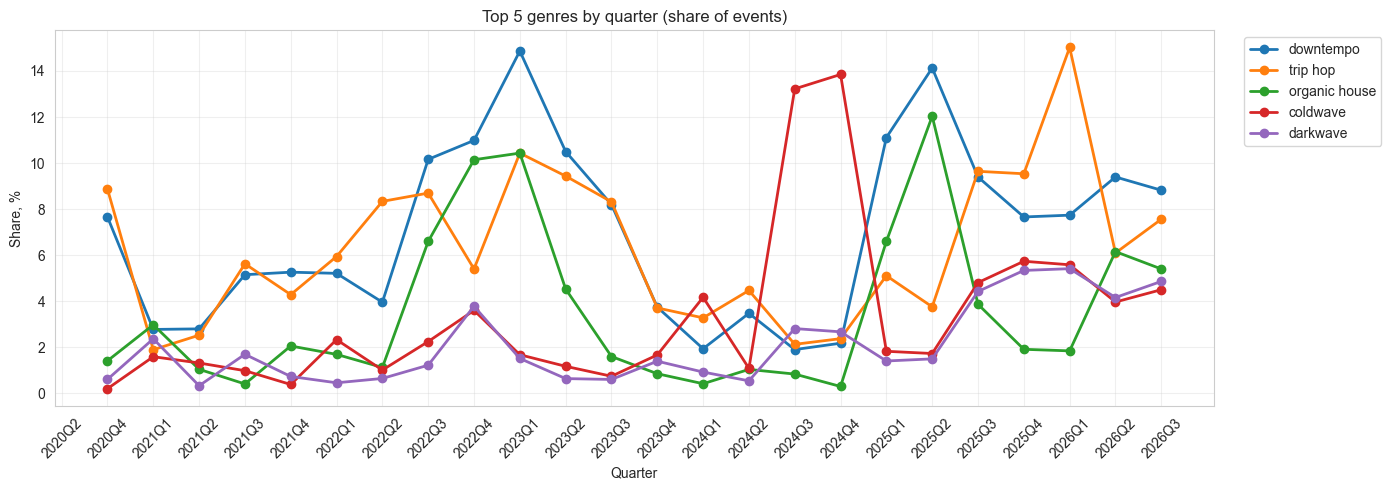


📊 Quarterly mean audio features (smoothed, window=3):


,quarter,valence,energy,danceability,acousticness,instrumentalness
0,2020Q2,—,—,—,—,—
1,2020Q4,0.287,0.457,0.575,0.468,0.208
2,2021Q1,0.307,0.504,0.579,0.375,0.309
3,2021Q2,0.291,0.513,0.577,0.367,0.342
4,2021Q3,0.283,0.525,0.600,0.344,0.431
5,2021Q4,0.272,0.530,0.604,0.337,0.481
6,2022Q1,0.299,0.536,0.615,0.326,0.425
7,2022Q2,0.318,0.539,0.621,0.304,0.373
8,2022Q3,0.342,0.548,0.632,0.285,0.392
9,2022Q4,0.329,0.532,0.627,0.295,0.456



📊 Quarterly median audio features (raw):


,quarter,valence,energy,danceability,acousticness,instrumentalness
0,2020Q2,0.230,0.304,0.640,0.675,0.000
1,2020Q4,0.295,0.516,0.616,0.239,0.124
2,2021Q1,0.244,0.517,0.569,0.299,0.055
3,2021Q2,0.276,0.486,0.614,0.246,0.088
4,2021Q3,0.233,0.528,0.601,0.262,0.453
5,2021Q4,0.223,0.536,0.647,0.231,0.691
6,2022Q1,0.202,0.523,0.626,0.255,0.515
7,2022Q2,0.319,0.552,0.643,0.207,0.040
8,2022Q3,0.302,0.557,0.650,0.168,0.219
9,2022Q4,0.297,0.552,0.670,0.174,0.644



📊 Top-5 genre shares by quarter, %:


genre,quarter,coldwave,darkwave,downtempo,organic house,trip hop
0,2020Q2,—,—,—,—,—
1,2020Q4,0.2,0.6,7.7,1.4,8.9
2,2021Q1,1.6,2.4,2.8,3.0,1.9
3,2021Q2,1.3,0.3,2.8,1.0,2.5
4,2021Q3,1.0,1.7,5.2,0.4,5.6
5,2021Q4,0.4,0.7,5.3,2.1,4.3
6,2022Q1,2.3,0.5,5.2,1.7,5.9
7,2022Q2,1.0,0.6,4.0,1.1,8.3
8,2022Q3,2.2,1.2,10.2,6.6,8.7
9,2022Q4,3.6,3.8,11.0,10.1,5.4


📊 Peaks in audio drift (quarters, heuristic):
   valence: 2023Q4
   energy: 2023Q4, 2024Q2, 2024Q3
   danceability: 2023Q4, 2024Q3
   acousticness: 2021Q1, 2023Q3, 2023Q4, 2024Q3
   instrumentalness: 2021Q1, 2021Q3

📊 Top-5 genres across the period:
downtempo, trip hop, organic house, coldwave, darkwave


In [177]:
# 4.2 Квартальный дрейф: аудио и жанры

# Годы — крупный масштаб. Кварталы ловят сезонность и более короткие сдвиги.
# Здесь смотрим две вещи:
#   1. Аудио-дрейф: как средние (и медианы) по 5 характеристикам менялись
#      поквартально, со сглаживанием скользящим окном.
#   2. Жанровый дрейф: доля топ-5 жанров в каждом квартале.
#
# Пики в сглаженных рядах ищутся эвристикой find_peaks — это НЕ статистический
# тест, а простая диагностика: точка считается пиком, если её изменение
# больше среднего + 1.5 × std среди всех изменений ряда. Порог может давать
# ложные срабатывания, поэтому пики — только подсказка для визуального просмотра.
#
# Локальные параметры (используются только в этой ячейке):
ROLLING_WINDOW = 3           # окно сглаживания, кварталов
PEAK_THRESHOLD_STD = 1.5     # порог пика: mean + 1.5σ от изменений
TOP_GENRES = 5               # сколько топ-жанров показывать в динамике

AUDIO_FEATURES_DRIFT = ['valence', 'energy', 'danceability', 'acousticness', 'instrumentalness']

# --- Данные: только валидные события ---
data = df[df['valid_play']].copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data['quarter'] = data['ts'].dt.to_period('Q')

# --- Квартальные средние и медианы ---
quarter_audio_mean = data.groupby('quarter')[AUDIO_FEATURES_DRIFT].mean().sort_index()
quarter_audio_median = data.groupby('quarter')[AUDIO_FEATURES_DRIFT].median().sort_index()

# Сглаживание центрированным окном — убирает квартальный шум,
# оставляет общий тренд.
quarter_audio_smooth = quarter_audio_mean.rolling(ROLLING_WINDOW, center=True).mean()

# Таблица сглаженных средних (для вывода).
quarter_audio_smooth_display = quarter_audio_smooth.round(3).reset_index()
quarter_audio_smooth_display['quarter'] = quarter_audio_smooth_display['quarter'].astype(str)


def find_peaks(series, window):
    """
    Эвристический поиск пиков в сглаженном ряду.

    Точка считается пиком, если абсолютное изменение относительно
    предыдущего квартала больше, чем mean + PEAK_THRESHOLD_STD × std
    среди всех изменений ряда.

    Это НЕ статистический тест: порог эвристический, ложные срабатывания
    возможны. Использовать как подсказку для визуального просмотра.
    """
    diff = series.diff().abs().dropna()
    if len(diff) == 0:
        return []
    mean_diff = diff.mean()
    std_diff = diff.std()
    threshold = mean_diff + PEAK_THRESHOLD_STD * std_diff
    peak_indices = diff[diff > threshold].index
    return list(peak_indices)


peaks = {}
for feat in AUDIO_FEATURES_DRIFT:
    peaks[feat] = find_peaks(quarter_audio_smooth[feat], ROLLING_WINDOW)

# --- Визуализация аудио-дрейфа ---
fig, axes = plt.subplots(5, 1, figsize=(14, 15), sharex=True)

for i, feat in enumerate(AUDIO_FEATURES_DRIFT):
    ax = axes[i]
    # Серая линия — сырые квартальные средние.
    ax.plot(quarter_audio_mean.index.astype(str), quarter_audio_mean[feat],
            alpha=0.4, color='gray', linewidth=0.7, label='Raw mean')
    # Синяя — сглаженные.
    ax.plot(quarter_audio_smooth.index.astype(str), quarter_audio_smooth[feat],
            color='steelblue', linewidth=2, label=f'MA({ROLLING_WINDOW})')
    # Красные точки — эвристические пики.
    if peaks[feat]:
        ax.scatter([p.strftime('%YQ%q') for p in peaks[feat]],
                   quarter_audio_smooth.loc[peaks[feat], feat],
                   color='red', s=80, zorder=5, label='Peak (heuristic)')
    ax.set_title(feat)
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

plt.suptitle('Taste drift by quarter (audio features)', fontsize=14, y=1.02)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Жанровый дрейф ---
data_genre = data.copy()
data_genre['genre_list'] = data_genre['genres_normalized'].str.split(',')
genre_flat = data_genre.explode('genre_list')
genre_flat['genre'] = genre_flat['genre_list'].str.strip()
genre_flat['quarter'] = genre_flat['ts'].dt.to_period('Q')

genre_total = genre_flat['genre'].value_counts()
known_genres = genre_total[genre_total.index != 'unknown'].head(TOP_GENRES).index.tolist()

quarter_genre_share = genre_flat[genre_flat['genre'].isin(known_genres)].groupby(
    ['quarter', 'genre']).size().unstack(fill_value=0)
quarter_genre_share = quarter_genre_share.div(genre_flat.groupby('quarter').size(), axis=0) * 100
quarter_genre_share_display = quarter_genre_share.round(1).reset_index()
quarter_genre_share_display['quarter'] = quarter_genre_share_display['quarter'].astype(str)

plt.figure(figsize=(14, 5))
for genre in known_genres:
    plt.plot(quarter_genre_share.index.astype(str), quarter_genre_share[genre],
             marker='o', linewidth=2, label=genre)
plt.title(f'Top {TOP_GENRES} genres by quarter (share of events)')
plt.xlabel('Quarter')
plt.ylabel('Share, %')
plt.xticks(rotation=45)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Таблицы ---

# 1. Сглаженные средние по кварталам.
print('\n📊 Quarterly mean audio features (smoothed, window=3):')
numeric_cols_audio = [c for c in quarter_audio_smooth_display.columns if c != 'quarter']
quarter_audio_styled = quarter_audio_smooth_display.style.format(
    {col: '{:.3f}' for col in numeric_cols_audio},
    na_rep='—'
).set_table_attributes(
    'style="display:block; max-height:400px; overflow-y:auto;"'
)
display(quarter_audio_styled)

# 2. Медианы по кварталам (без сглаживания — для контроля).
print('\n📊 Quarterly median audio features (raw):')
quarter_audio_median_display = quarter_audio_median.round(3).reset_index()
quarter_audio_median_display['quarter'] = quarter_audio_median_display['quarter'].astype(str)
numeric_cols_median = [c for c in quarter_audio_median_display.columns if c != 'quarter']
quarter_median_styled = quarter_audio_median_display.style.format(
    {col: '{:.3f}' for col in numeric_cols_median},
    na_rep='—'
).set_table_attributes(
    'style="display:block; max-height:400px; overflow-y:auto;"'
)
display(quarter_median_styled)

# 3. Доли топ-5 жанров по кварталам.
print('\n📊 Top-5 genre shares by quarter, %:')
numeric_cols_genre = [c for c in quarter_genre_share_display.columns if c != 'quarter']
quarter_genre_styled = quarter_genre_share_display.style.format(
    {col: '{:.1f}' for col in numeric_cols_genre},
    na_rep='—'
).set_table_attributes(
    'style="display:block; max-height:400px; overflow-y:auto;"'
)
display(quarter_genre_styled)

# --- Пики ---
print('📊 Peaks in audio drift (quarters, heuristic):')
for feat, idx_list in peaks.items():
    if idx_list:
        print(f'   {feat}: {", ".join([p.strftime("%YQ%q") for p in idx_list])}')
    else:
        print(f'   {feat}: no peaks')

print('\n📊 Top-5 genres across the period:')
print(', '.join(known_genres))

### 4.2. Вывод

Точка сдвига пяти характеристик — не весь 2024 год, а интервал
2023Q4 — 2024Q1. Здесь valence падает с 0.291 до 0.239, energy —
с 0.431 до 0.354, danceability — с 0.565 до 0.473, acousticness
растёт с 0.470 до 0.571, instrumentalness — с 0.501 до 0.540.
В блоке 3 это же движение видно на месячном масштабе как
«март → апрель 2024»; квартальный разрез показывает, что началось
оно раньше.

2024Q1 — не однородный сдвиг, а поляризация. Расхождение среднего
и медианы максимально за весь период: danceability mean 0.466
при median 0.227, acousticness mean 0.558 при median 0.931.
Типичный трек квартала был значительно экстремальнее среднего —
в данных сосуществовали две группы, «тёмная» и обычная.

Жанровое ядро перестраивается и возвращается: три жанра (downtempo,
trip hop, organic house) уходят в минимум в 2024, coldwave вырастает
до 13.2% в 2024Q3. К 2025Q1–Q2 прежние три возвращаются. Это
не смена вкуса, а временное вытеснение.

Порог пиков — `mean + 1.5 × std` — эвристика, калиброванная
на собственной истории пользователя. Устойчивым выглядит только
2023Q4: он подтверждается сразу по пяти характеристикам.

## Блок 4. Вывод

Блок показывает траекторию аудио-профиля по годам и кварталам —
без поиска аномалий, просто как ряд. Главный результат: 2024 — не
аномальный год в изоляции, а точка перелома, к которой характеристики
шли несколько лет и от которой развернулись. Квартальный срез уточняет
годовой: сдвиг приходится не на весь 2024, а на узкий интервал
2023Q4 — 2024Q1.

---

**2024 как точка перелома**

По z-score heatmap в 2024 шесть характеристик отклоняются от среднего
за все годы сильнее, чем у любого другого года: valence (−1.71),
energy (−1.86), danceability (−2.14), loudness (−2.19) — вниз;
acousticness (+1.82), instrumentalness (+1.25) — вверх.

Топ-3 характеристики по нормированной дисперсии — acousticness,
instrumentalness, energy — все три имеют 2024 своей крайней точкой.
До неё траектории разные: acousticness плоская 2020–2022, потом
резкий рост; instrumentalness растёт постепенно с 2020; energy
колеблется и обваливается. После 2024 все три разворачиваются.

Это говорит о том, что сдвиг накапливался: 2024 — не событие одного
года, а вершина длительного процесса, где характеристики достигли
пика одновременно.

---

**Квартальное уточнение: 2023Q4 — 2024Q1**

На годовом срезе 2024 выглядит цельным — все характеристики
отклоняются в один год. Квартальный срез показывает, что внутри года
было два разных периода.

Первый — 2023Q4 — 2024Q1: узкий интервал, где пять характеристик
меняются одновременно (valence, energy, danceability вниз,
acousticness, instrumentalness вверх). Именно здесь находится точка
сдвига. Блок 3 на месячном масштабе видел это как «март → апрель
2024»; квартальный разрез показывает, что движение началось раньше,
в последнем квартале 2023.

Второй — остальная часть 2024: характеристики уже не движутся
согласованно. Energy восстанавливается к 2024Q2, acousticness падает
к 2024Q3, instrumentalness держится на высоком уровне. Год после
сдвига — не однородная «тихая зона», а период, когда характеристики
расходятся.

---

**2024Q1 — поляризация, а не однородный сдвиг**

Расхождение среднего и медианы в этом квартале максимально
за весь период: у danceability mean 0.466 при median 0.227,
у acousticness mean 0.558 при median 0.931. Медианы ушли гораздо
дальше средних — типичный трек квартала был значительно более
экстремальным, чем средний.

Это означает, что в 2024Q1 в данных сосуществовали две группы:
одна очень тёмная (тихая, неэнергичная, акустическая,
инструментальная) и другая — с обычными значениями. Среднее
смешалось. Квартал был не однородно тихим, а поляризованным.

---

**Жанровое ядро перестраивается и возвращается**

Доли топ-5 жанров по кварталам показывают не постепенный дрейф,
а замену ядра. Три жанра из основного набора (downtempo, trip hop,
organic house) уходят в минимум именно в 2024, и одновременно
coldwave вырастает до рекорда (13.2% в 2024Q3 против фона 1–5%).
К 2025Q1–Q2 прежние три возвращаются на свои позиции.

Это не смена вкуса, а временное вытеснение ядра другим жанром.
Квартальный масштаб показывает то, что годовой срез сглаживает:
2024 не «ушёл в coldwave», а прошёл через период, где coldwave
временно стал основным, а затем ядро восстановилось.

---

**2021 — рост инструментальности внутри года**

Эвристические пики instrumentalness приходятся на 2021Q1 и 2021Q3.
По квартальным средним: 0.208 → 0.309 → 0.342 → 0.431 → 0.481.
Внутри 2021 года инструментальность выросла в 2.3 раза.

Годовой срез показал 2021 как «вокальный год» (среднее 0.385 против
фона 0.497). Квартальный разрез уточняет: год начался с очень низкого
уровня, а закончился на высоком. Не год целиком вокальный, а год
с быстрым ростом инструментальности к концу — ещё один случай,
где квартальный масштаб показывает движение, которое годовой
сглаживает.

---

**Ограничение**

Z-score, нормированная дисперсия и порог для пиков считаются
относительно собственной истории пользователя, не против внешнего
эталона. «Acousticness изменилась сильнее всего» означает «в этой
истории она дала наибольший разброс», а не «она изменилась сильнее
у всех». Значения несопоставимы между пользователями.

Нормировка `var / range²` структурно перекошена в пользу
характеристик с диапазоном [0, 1]: у valence, energy, danceability
знаменатель равен 1, у tempo (290), loudness (60) и popularity (100) —
сотни и тысячи. Top-3 всегда собирается из долей, tempo и popularity
туда не попадают даже при заметном абсолютном разбросе. Это не
недостаток метода — он отвечает на вопрос «какая характеристика
менялась сильнее относительно своего допустимого интервала»,
а не «какая менялась сильнее в абсолютных числах».

2020 и 2026 неполные (данные с мая 2020 и до августа 2026).
Их z-scores и годовые средние менее надёжны. Краевые кварталы
2020Q2 и 2026Q3 в сглаженные ряды не входят. 2020Q4 — первый
квартал с данными, но представлен двумя месяцами из трёх.

Квартальные пики — эвристика `mean + 1.5 × std`, не статистический
тест. Ложные срабатывания возможны: скачок на один квартал с откатом
в следующем попадёт в список, но не является устойчивым событием.
Устойчивым выглядит только 2023Q4 — он подтверждается квартальными
средними сразу по пяти характеристикам. Остальные пики опираются
на меньшее число характеристик и требуют визуальной проверки.

# Блок 5. Суточные и недельные ритмы

## 5. Суточные и недельные ритмы

Блоки 2–4 смотрели на профиль во времени — что слушается и как менялось
за годы. Блок 5 меняет ось: не что, а когда в пределах дня и недели.
Он отвечает на вопрос «в какие часы и дни пользователь слушает музыку
и меняется ли этот ритм от года к году».

**Методология.** Временная метка каждого события содержит час (0–23)
и день недели (0–6). Агрегация по этим двум осям даёт матрицу
«день × час» — сколько событий приходится на каждую комбинацию.
Это основа всех шести ячеек блока.

**Почему нормировка на сумму.** Абсолютные числа событий различаются
между годами в разы: 2025 дал 21 900 событий, 2022 — 10 419. Если
сравнивать суточный профиль между годами без нормировки, 2025 просто
затмит остальные. Поэтому в 5.3 и 5.5 профиль нормируется на сумму
года: считается доля событий, приходящаяся на каждый час. Это
позволяет сравнивать форму ритма, а не объём.

**Что такое хронотип здесь.** В строгом смысле хронотип — это
биологическая предрасположенность человека к активности в утренние
или вечерние часы. В этом блоке термин используется свободно:
«хронотип» = форма суточного профиля прослушивания. Не тип человека,
а тип его поведения в музыке. Утренний пик не означает «жаворонок» —
он означает, что в эти часы пользователь чаще включал музыку.

**Дневное и ночное.** Для 5.6 дневным считается интервал 06:00–22:00,
ночным — 22:00–06:00. Это рабочее определение, а не физиологическое:
границы выбраны так, чтобы отделить «активное время суток» от
«времени сна». На других данных эти границы могли бы быть другими;
здесь они фиксированы и не проверяются.

**Порог аномального года в 5.6.** Год считается аномальным по доле
дневных событий, если его значение ниже `mean − 1.5 × std` по всем
годам. Это та же эвристика, что 1.5×IQR в блоке 3 и 2σ в контрастных
переходах: порог подобран эмпирически, не выведен из распределения.
На 7 годах (из них 2 неполных) стандартное отклонение нестабильно —
один год может сдвинуть порог. «Аномальный год» здесь означает
«год заметно выбивается на фоне остальных», а не статистически
строгую аномалию.

**Почему данные позволяют этот анализ.** В блоке 0 подтверждено, что
часы в `daily` покрывают полный диапазон 0–23. Это значит, что
в суточном профиле нет «мёртвых зон» — часов, которые не встречались
бы вообще. Если бы данные обрывались, например, на 21:00, все
вечерние выводы были бы смещены.

**Как устроен блок.** Шесть ячеек идут последовательно.

- **5.1** — тепловая карта «день недели × час» по событиям Deep dive.
  Общая форма ритма: где плотность выше, где ниже.
- **5.2** — сравнение суточного профиля в будни и выходные. Сдвигается
  ли пик, меняется ли форма.
- **5.3** — тот же профиль, но нормированный по годам. Показывает,
  менялся ли хронотип от года к году.
- **5.4** — топ-3 самых активных и топ-3 самых тихих часов
  для каждого дня недели.
- **5.5** — час пика для каждого года и его сдвиг. Сводит 5.3
  к одной точке на год.
- **5.6** — доля дневных событий по годам с автоопределением
  аномального года через порог `mean − 1.5σ`.

**Что блок даёт на выходе.** Конкретный ответ: в какие часы и дни
пользователь слушает музыку чаще всего, стабилен ли этот ритм
или сдвигается, есть ли аномальные по суточной активности годы.
Это последний срез временного анализа — после годов, кварталов,
месяцев остаётся суточная и недельная шкала.

## 5.1 Тепловая карта активности по часам и дням недели (Deep dive)


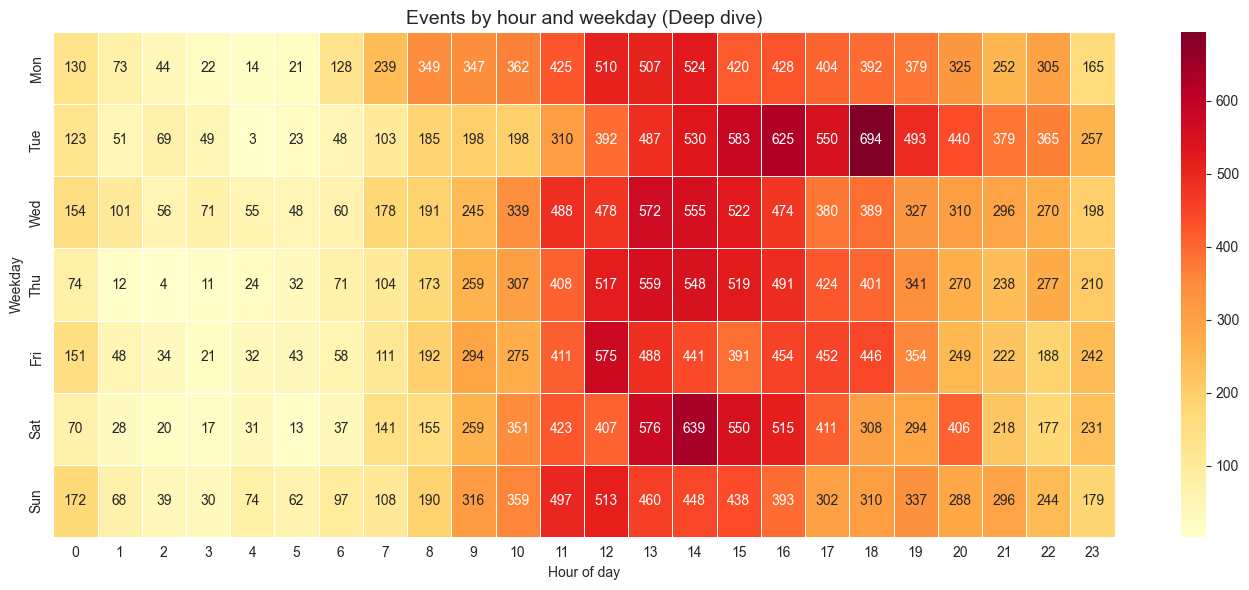

📊 Events by hour and weekday (Deep dive):


hour,index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
№,,,,,,,,,,,,,,,,,,,,,,,,,
1,Mon,130,73,44,22,14,21,128,239,349,347,362,425,510,507,524,420,428,404,392,379,325,252,305,165
2,Tue,123,51,69,49,3,23,48,103,185,198,198,310,392,487,530,583,625,550,694,493,440,379,365,257
3,Wed,154,101,56,71,55,48,60,178,191,245,339,488,478,572,555,522,474,380,389,327,310,296,270,198
4,Thu,74,12,4,11,24,32,71,104,173,259,307,408,517,559,548,519,491,424,401,341,270,238,277,210
5,Fri,151,48,34,21,32,43,58,111,192,294,275,411,575,488,441,391,454,452,446,354,249,222,188,242
6,Sat,70,28,20,17,31,13,37,141,155,259,351,423,407,576,639,550,515,411,308,294,406,218,177,231
7,Sun,172,68,39,30,74,62,97,108,190,316,359,497,513,460,448,438,393,302,310,337,288,296,244,179


In [178]:
# 5.1 Тепловая карта активности по часам и дням недели (Deep dive)

# Показывает, в какие часы и дни недели пользователь слушает музыку чаще всего.
# Строки — дни недели, столбцы — часы, значения — число событий.
# Используется df_deep из блока 0.

# Создаём weekday, если ещё не создана.
if 'weekday' not in df_deep.columns:
    df_deep['weekday'] = df_deep['ts'].dt.weekday

heatmap_data = df_deep.groupby(['weekday', 'hour']).size().unstack(fill_value=0)

# Дни недели на английском — по решению о языке вывода.
day_names = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
heatmap_data.index = [day_names[i] for i in heatmap_data.index]

plt.figure(figsize=(14, 6))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='d', linewidths=0.5)
plt.title('Events by hour and weekday (Deep dive)', fontsize=14)
plt.xlabel('Hour of day')
plt.ylabel('Weekday')
plt.tight_layout()
plt.show()

heatmap_display = heatmap_data.reset_index()
heatmap_display.index = heatmap_display.index + 1
heatmap_display.index.name = '№'
print('📊 Events by hour and weekday (Deep dive):')
display(heatmap_display)

### 5.1 Вывод

Тепловая карта даёт форму суточного и недельного ритма по событиям
Deep dive — не по всему потоку.

**Суточный профиль.** Ночные часы 0:00–5:00 дают в разы меньше событий, чем дневные:
максимум в ночной зоне — 172 события (воскресенье, 0:00) против
500–690 в дневных пиках. Полоса бледно-жёлтая во всех строках,
но не пустая — в каждом ночном часу есть события.
С 6:00 активность растёт, ядро концентрируется в 12:00–18:00 — тёмно-
оранжевая и красная зона. После 19:00 спад, но не до ночного уровня:
вечерние часы 19:00–23:00 держат средние значения, заметно выше
предутренних.

**Недельный профиль ровный, кроме вторника.** Пять дней недели дают
похожую форму: плавный подъём с утра, плато в 12:00–14:00, спад
к вечеру. Понедельник, среда, четверг, пятница и воскресенье
различаются слабо — самые яркие ячейки у них в диапазоне 510–576.

**Вторник выбивается.** Это единственный день с выраженным вечерним
пиком: 694 события в 18:00 — самая тёмная ячейка всей карты. За ним
625 в 16:00 и 583 в 15:00. У всех остальных дней в 15:00–18:00
значения падают, у вторника они растут. Совпадение двух признаков —
поздний пик и максимум по объёму — делает вторник отдельным случаем
в общем ровном профиле.

**Суббота — второй по выраженности день.** Пик в 14:00 (639), рядом
576 в 13:00 и 550 в 15:00. Формально это не так резко, как вторник,
но субботний пик — единственный дневной, который дотягивает
до уровня вторничных значений.

**Что это даёт блоку.** Форма ритма определена: дневной профиль
с минимумом ночью и максимумом в 12:00–18:00. Пять дней недели
идут по одному шаблону, вторник — по другому, суббота — промежуточный
случай. Дальше 5.2 проверит, отличается ли этот шаблон между буднями
и выходными как группами, 5.3 — менялся ли он от года к году,
5.5 — сдвигался ли час пика, 5.6 — есть ли годы с аномальной
долей дневных событий.

**Ограничение.** Карта построена по событиям Deep dive, а не по всему
потоку. Ночью пользователь может слушать музыку фоном — такие события
не проходят фильтр валидного прослушивания и в эту таблицу не попадают.
Если фон включается преимущественно в ночные часы, реальная ночная
активность выше, чем показывает карта. Проверка этой гипотезы —
отдельная задача, здесь она не решается.

## 5.2 Активность по часам: будни vs выходные


<Figure size 1200x500 with 0 Axes>

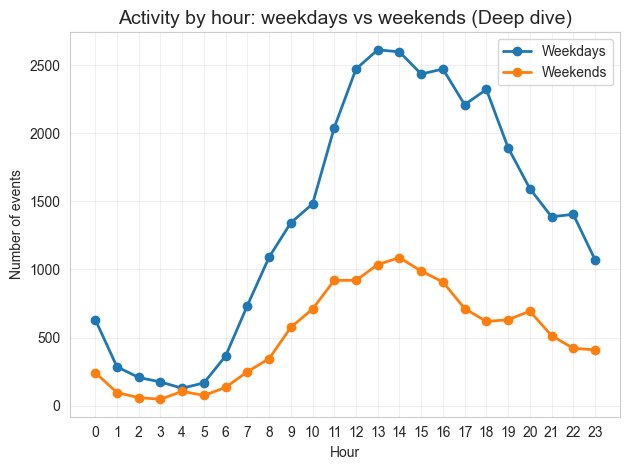

📊 Activity by hour: weekdays and weekends:


,hour,Weekdays,Weekends
№,,,
1,0,632,242
2,1,285,96
3,2,207,59
4,3,174,47
5,4,128,105
6,5,167,75
7,6,365,134
8,7,735,249
9,8,1090,345


In [179]:
# 5.2 Активность по часам: будни vs выходные

# Сравниваем суточный профиль в рабочие дни и на выходных.
# Выходные: суббота и воскресенье (weekday 5, 6).

if 'weekday' not in df_deep.columns:
    df_deep['weekday'] = df_deep['ts'].dt.weekday

df_deep['is_weekend'] = df_deep['weekday'].isin([5, 6])

hourly = df_deep.groupby(['hour', 'is_weekend']).size().unstack(fill_value=0)
hourly.columns = ['Weekdays', 'Weekends']

plt.figure(figsize=(12, 5))
hourly.plot(marker='o', linewidth=2)
plt.title('Activity by hour: weekdays vs weekends (Deep dive)', fontsize=14)
plt.xlabel('Hour')
plt.ylabel('Number of events')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

hourly_display = hourly.reset_index()
hourly_display.index = hourly_display.index + 1
hourly_display.index.name = '№'
print('📊 Activity by hour: weekdays and weekends:')
display(hourly_display)

### 5.2 Вывод

Сравнение будней и выходных даёт одно существенное различие — форму
профиля, не объём. На один день недели будни и выходные дают примерно
одинаковое количество событий: 33 123 события в будни против 12 497
в выходные, но будних дней в 2.5 раза больше (5 из 7). В пересчёте
на день разница почти исчезает.

**Форма профиля различается.** У будней два пика: основной в 13:00
(2 613) и второй в 18:00 (2 322). У выходных один пик в 14:00 (1 087),
после которого активность монотонно падает. Второй пик в 18:00
у выходных отсутствует: там 618 событий против 2 322 в будни.

**Утро различается по скорости подъёма.** В будни активность растёт
резко: с 365 в 6:00 до 1 090 в 8:00 — в три раза за два часа.
У выходных рост плавнее: с 134 в 6:00 до 345 в 8:00 — тоже в три раза,
но абсолютные значения ниже. К 11:00 будни дают 2 042 против 920
у выходных, к 13:00 — 2 613 против 1 036.

**Ночная активность в будни выше.** 0:00–5:00: в будни 632, 285, 207,
174, 128, 167; в выходные — 242, 96, 59, 47, 105, 75. В среднем
ночью будни дают в 2.5 раза больше событий. Это может быть артефактом
пропорции дней, но разрыв больше пропорции (2.5 против 2.65),
поэтому небольшое реальное различие вероятно.

**Что это значит.** Будни и выходные различаются не тем, сколько
музыки слушается, а тем, как она распределена по дню. Будний профиль
двухмодальный: утренний подъём, дневное плато, вечерний второй подъём
в 18:00 — вероятно, после работы. Выходной — одномодальный: плавный
подъём, один пик в середине дня, монотонный спад к вечеру.

**Ограничение.** Сравнение абсолютных чисел между буднями и выходными
некорректно: будних дней в неделю больше, поэтому и событий в сумме
больше. Здесь важна форма профиля — распределение событий по часам, —
а не суммарный объём. Ночная активность в будни может быть частично
объяснена тем, что вечер пятницы попадает в категорию «будни»,
и если пятничный вечер смещён к ночным часам, это завышает будний
ночной счёт. Отдельно по дням недели это не проверено.

## 5.3 Хронотип по годам: распределение активности по часам


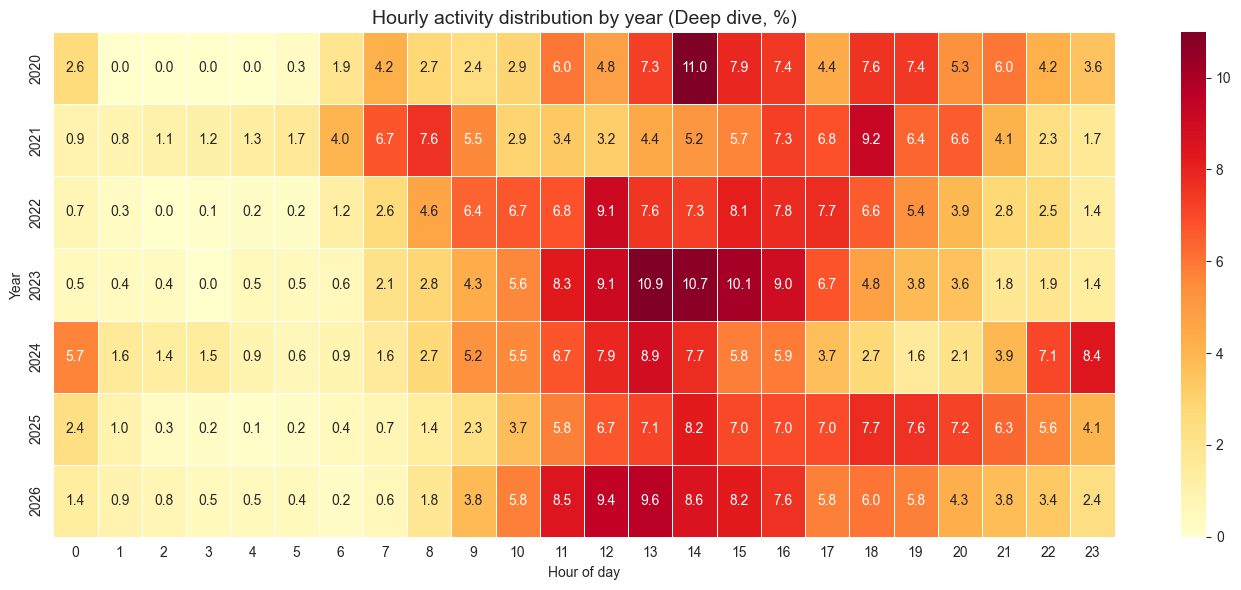

📊 Normalized hourly activity by year (%):


hour,year,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
№,,,,,,,,,,,,,,,,,,,,,,,,,
1,2020,2.58,0.00,0.00,0.00,0.00,0.32,1.94,4.20,2.75,2.42,2.91,5.98,4.85,7.27,10.99,7.92,7.43,4.36,7.59,7.43,5.33,5.98,4.20,3.55
2,2021,0.92,0.82,1.08,1.16,1.35,1.67,4.01,6.73,7.60,5.54,2.92,3.36,3.16,4.43,5.15,5.67,7.29,6.83,9.23,6.36,6.58,4.13,2.33,1.69
3,2022,0.74,0.32,0.00,0.06,0.18,0.21,1.20,2.61,4.60,6.43,6.68,6.81,9.07,7.55,7.26,8.13,7.77,7.74,6.60,5.35,3.93,2.76,2.53,1.44
4,2023,0.47,0.42,0.39,0.04,0.55,0.47,0.56,2.14,2.82,4.33,5.60,8.29,9.10,10.94,10.68,10.13,8.97,6.74,4.78,3.85,3.57,1.83,1.93,1.40
5,2024,5.69,1.60,1.40,1.48,0.87,0.64,0.87,1.56,2.70,5.24,5.55,6.70,7.93,8.91,7.73,5.79,5.90,3.68,2.67,1.56,2.10,3.95,7.06,8.43
6,2025,2.36,0.98,0.31,0.21,0.14,0.18,0.44,0.74,1.40,2.27,3.65,5.78,6.67,7.12,8.20,7.02,6.99,6.98,7.73,7.63,7.19,6.33,5.62,4.05
7,2026,1.39,0.91,0.76,0.46,0.48,0.45,0.22,0.58,1.83,3.85,5.75,8.47,9.44,9.63,8.59,8.20,7.62,5.78,6.02,5.78,4.26,3.77,3.37,2.40


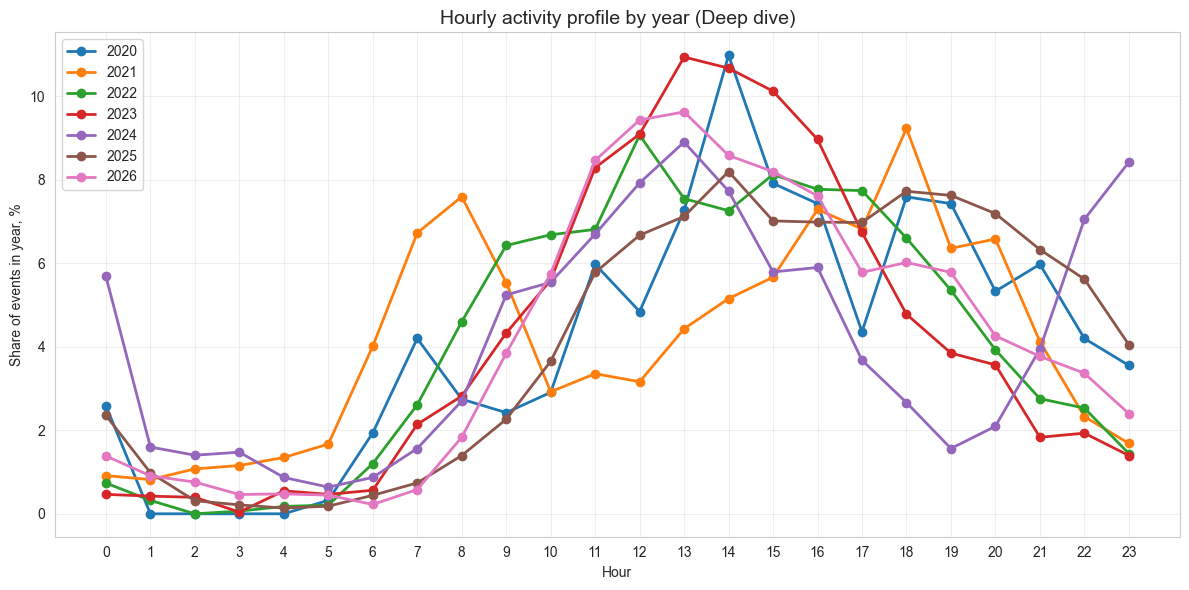

In [180]:
# 5.3 Хронотип по годам: распределение активности по часам

# Смотрим, менялся ли суточный профиль от года к году.
# Абсолютные числа отличаются между годами, поэтому нормируем на сумму года —
# получаем долю событий, приходящуюся на каждый час. Это позволяет
# сравнивать форму ритма, а не объём.

if 'weekday' not in df_deep.columns:
    df_deep['weekday'] = df_deep['ts'].dt.weekday

hourly_by_year = df_deep.groupby(['year', 'hour']).size().unstack(fill_value=0)

year_totals = hourly_by_year.sum(axis=1)
hourly_norm_by_year = hourly_by_year.div(year_totals, axis=0) * 100

plt.figure(figsize=(14, 6))
sns.heatmap(hourly_norm_by_year, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5)
plt.title('Hourly activity distribution by year (Deep dive, %)', fontsize=14)
plt.xlabel('Hour of day')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

hourly_norm_display = hourly_norm_by_year.round(2).reset_index()
hourly_norm_display.index = hourly_norm_display.index + 1
hourly_norm_display.index.name = '№'
print('📊 Normalized hourly activity by year (%):')
display(hourly_norm_display)

# Линейный график: одна линия на год.
plt.figure(figsize=(12, 6))
for year in hourly_norm_by_year.index:
    plt.plot(
        hourly_norm_by_year.columns,
        hourly_norm_by_year.loc[year],
        marker='o', linewidth=2, label=str(year)
    )

plt.title('Hourly activity profile by year (Deep dive)', fontsize=14)
plt.xlabel('Hour')
plt.ylabel('Share of events in year, %')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Вывод по блоку 5.3

Суточный профиль не стабилен год к году: форма распределения заметно
меняется, хотя общий каркас — рост с утра, ядро днём, спад ночью —
сохраняется во все годы. Главное исключение — 2024, где появляется
второй пик в поздние часы.

**Дневное ядро.** У шести годов из семи максимум приходится
на 12:00–14:00. У 2020 — 14:00 (10.99%), у 2022 — 12:00 (9.07%),
у 2023 — 13:00 (10.94%), у 2024 — 13:00 (8.91%), у 2025 — 14:00
(8.20%), у 2026 — 13:00 (9.63%). 2021 — исключение, пик в 18:00.

**Утро смещается.** В 2020 и 2021 рост начинается рано: к 8:00
уже 2.75% и 7.60%. В 2022–2024 утро медленнее: к 8:00 у 2022 —
4.60%, у 2023 — 2.82%, у 2024 — 2.70%. К 2025–2026 снова резкий
подъём: 1.40% (2025) и 1.83% (2026) в 8:00.

**2024 — единственный год со вторым пиком в поздние часы.**
В 22:00 у 2024 — 7.06% против 1.40–5.62% у остальных; в 23:00 —
8.43% против 1.40–4.05%; в 0:00 — 5.69% против 0.47–2.58%.
Дневное ядро остаётся на месте (13:00), но появляется второй очаг
активности вечером. У 2021 пик тоже вечерний (18:00), но он
единственный — дневного пика нет. Это разные формы: у 2021 профиль
сдвинут целиком, у 2024 — двухмодальный.

**Вечер сдвигается постепенно.** У 2021 максимум вечера приходится
на 18:00 (9.23%), у 2025 — на 18:00–19:00 (7.73%, 7.63%),
у 2026 — на 17:00–18:00 (5.78%, 6.02%). У 2022–2023 вечернего
максимума вообще нет.

**Ограничение self-relative.** Доли считаются внутри каждого года.
«В 2024 в 23:00 было 8.43% событий года» означает, что почти каждый
двенадцатый трек в том году слушался в этот час.

**Ограничение по неполным годам.** 2020 и 2026 представлены
не всем годовым циклом. Если существует сезонность по часам
прослушивания, их распределения могут быть смещены.

## 5.4 Самые активные и тихие часы по дням недели


In [181]:
# 5.4 Самые активные и тихие часы по дням недели

# Тепловая карта 5.1 даёт общую структуру, но не выделяет экстремумы.
# Здесь для каждого дня недели берём топ-3 часа по активности и топ-3
# по минимуму. Это делает суточный ритм конкретнее.

if 'heatmap_data' not in globals():
    raise ValueError('heatmap_data not found. Run cell 5.1 first.')

# Топ-3 часа по каждому дню.
print('📊 Peak hours by weekday:')
top_hours = {}
for day in heatmap_data.index:
    top3 = heatmap_data.loc[day].nlargest(3)
    top_hours[day] = list(top3.index)

top_hours_df = pd.DataFrame.from_dict(top_hours, orient='index').T
top_hours_df.columns = heatmap_data.index
top_hours_df.index = ['1st peak', '2nd peak', '3rd peak']
top_hours_df = top_hours_df.reset_index()
top_hours_df.columns = ['Rank'] + list(heatmap_data.index)
top_hours_df.index = range(1, len(top_hours_df) + 1)
top_hours_df.index.name = '№'
display(top_hours_df)

# Топ-3 тихих часа по каждому дню.
print('\n📊 Quietest hours by weekday:')
low_hours = {}
for day in heatmap_data.index:
    low3 = heatmap_data.loc[day].nsmallest(3)
    low_hours[day] = list(low3.index)

low_hours_df = pd.DataFrame.from_dict(low_hours, orient='index').T
low_hours_df.columns = heatmap_data.index
low_hours_df.index = ['1st min', '2nd min', '3rd min']
low_hours_df = low_hours_df.reset_index()
low_hours_df.columns = ['Rank'] + list(heatmap_data.index)
low_hours_df.index = range(1, len(low_hours_df) + 1)
low_hours_df.index.name = '№'
display(low_hours_df)

📊 Peak hours by weekday:


,Rank,Mon,Tue,Wed,Thu,Fri,Sat,Sun
№,,,,,,,,
1,1st peak,14,18,13,13,12,14,12
2,2nd peak,12,16,14,14,13,13,11
3,3rd peak,13,15,15,15,16,15,13



📊 Quietest hours by weekday:


,Rank,Mon,Tue,Wed,Thu,Fri,Sat,Sun
№,,,,,,,,
1,1st min,4,4,5,2,3,5,3
2,2nd min,5,5,4,3,4,3,2
3,3rd min,3,6,2,1,2,2,5


### 5.4 Вывод

Таблица подтверждает картину из 5.1 и добавляет точности: пик и минимум
по каждому дню недели теперь указаны явно, топ-3 часа для каждой
границы.

**Тихие часы одинаковы для всех дней.** Первый минимум — 2:00–5:00
во все семь дней. Топ-3 тихих часа укладываются в интервал 1:00–6:00
без единого исключения. Ночной провал — устойчивая часть профиля,
не зависящая от дня недели.

**Пик различается сильнее.** Шесть дней из семи имеют первый пик
в диапазоне 12:00–14:00: понедельник (14:00), среда (13:00), четверг
(13:00), пятница (12:00), суббота (14:00), воскресенье (12:00).
Вторник выбивается — первый пик в 18:00, на пять часов позже
остальных. Это подтверждает то, что уже было видно на тепловой карте
в 5.1: вторник — единственный день с вечерним максимумом.

**Внутри топ-3 разброс узкий.** У понедельника пики 14, 12, 13;
у среды — 13, 14, 15; у четверга — 13, 14, 15. Разница между первым
и третьим пиком — 1–2 часа. У вторника разброс шире: 18, 16, 15 —
три часа. Это ещё одно указание, что вторничный пик не просто
сдвинут, а растянут по вечеру.

**Форма недели.** Пять дней недели (Mon, Wed, Thu, Fri, Sun) дают
почти одинаковый профиль: пик в первой половине дня, минимум
в предутренние часы, топ-3 пиков — соседние часы. Суббота
приближается к этому шаблону (14, 13, 15). Вторник — отдельный
случай, не похожий ни на будни, ни на выходные.

**Ограничение.** Ячейка показывает только топ-3 часа с каждой стороны,
без весов: «1st peak» и «3rd peak» здесь — позиции в ранжировании,
но насколько сильно первый пик превышает третий, из таблицы не видно.
Для этого нужны значения из 5.1. Различие между «пик 14:00» и «пик
13:00» может быть 5 событий, а может быть 500 — таблица этого
не показывает.

## 5.5 Хронотип по годам: сдвиг пика активности


ℹ️ Incomplete years included: [2020, 2026]. Interpret with caution.
📊 Peak activity hour by year:


,Year,Peak hour,"Share at peak, %"
№,,,
1,2020,14,11.0
2,2021,18,9.2
3,2022,12,9.1
4,2023,13,10.9
5,2024,13,8.9
6,2025,14,8.2
7,2026,13,9.6


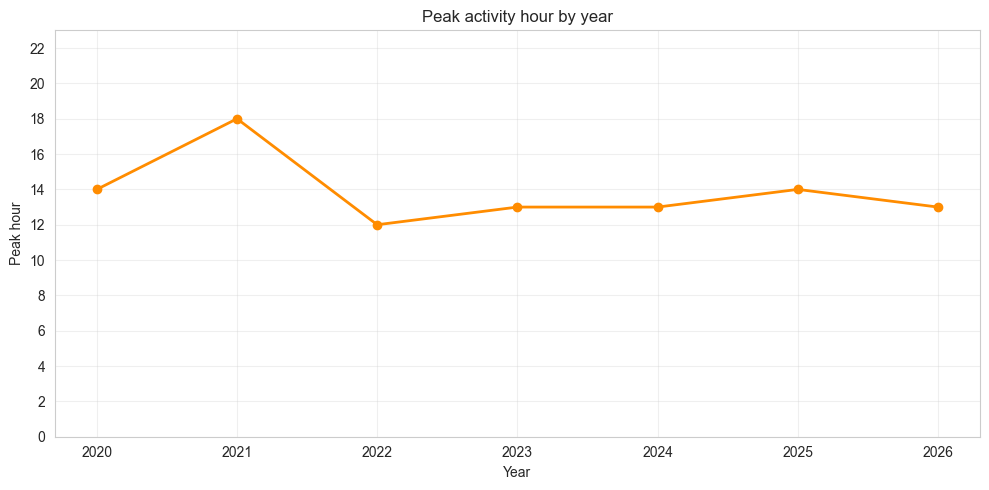


🔍 Interpretation:
   2020.0: peak at 14.0:00 (11.0%)
   2021.0: peak at 18.0:00 (9.2%)
   2022.0: peak at 12.0:00 (9.1%)
   2023.0: peak at 13.0:00 (10.9%)
   2024.0: peak at 13.0:00 (8.9%)
   2025.0: peak at 14.0:00 (8.2%)
   2026.0: peak at 13.0:00 (9.6%)


In [182]:
# 5.5 Хронотип по годам: сдвиг пика активности

# Для каждого года находим час с максимальной нормированной долей.
# Смотрим, менялся ли час пика год к году.

if 'hourly_norm_by_year' not in globals():
    raise ValueError('hourly_norm_by_year not found. Run cell 5.3 first.')

if incomplete_years:
    print(f'ℹ️ Incomplete years included: {incomplete_years}. Interpret with caution.')

peak_hours = hourly_norm_by_year.idxmax(axis=1)
peak_values = hourly_norm_by_year.max(axis=1)

peak_df = pd.DataFrame({
    'Year': peak_hours.index.astype(int),
    'Peak hour': peak_hours.values,
    'Share at peak, %': peak_values.round(1)
})
peak_df.index = range(1, len(peak_df) + 1)
peak_df.index.name = '№'

print('📊 Peak activity hour by year:')
display(peak_df)

plt.figure(figsize=(10, 5))
plt.plot(peak_df['Year'], peak_df['Peak hour'], marker='o', linewidth=2, color='darkorange')
plt.title('Peak activity hour by year')
plt.xlabel('Year')
plt.ylabel('Peak hour')
plt.ylim(0, 23)
plt.yticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\n🔍 Interpretation:')
for _, row in peak_df.iterrows():
    print(f'   {row["Year"]}: peak at {row["Peak hour"]}:00 ({row["Share at peak, %"]:.1f}%)')

### 5.5 Вывод

Час пика меняется от года к году, но не хаотично: пять лет из семи
укладываются в узкий диапазон 12:00–14:00, а два года выбиваются
в противоположные стороны.

**Устойчивая зона 12:00–14:00.** Шесть лет из семи держат пик в этом
диапазоне: 2020 (14:00, 11.0%), 2022 (12:00, 9.1%), 2023 (13:00,
10.9%), 2024 (13:00, 8.9%), 2025 (14:00, 8.2%), 2026 (13:00, 9.6%).
Внутри этой зоны пять лет сидят ещё плотнее — в 13:00–14:00.

**2021 — вечерний год.** Пик в 18:00 (9.2%) — на четыре часа позже
устойчивой зоны. Это не единичный сдвиг: 5.2 показал, что у будней
есть второй пик в 18:00, а 5.3 — что в 2021 максимум вечера тоже
приходится на 18:00 (9.23%). Год действительно смещён к вечеру.

**2022 — самый ранний год.** Пик в 12:00 (9.1%) — на час-два раньше
устойчивой зоны. По 5.3 у 2022 максимум тоже в 12:00 (9.07%),
а вечернего пика нет вообще — активность после 15:00 монотонно
падает. Год сдвинут к утру и первой половине дня.

**Разброс между соседними годами — 6 часов.** 2021 (18:00) и 2022
(12:00) стоят рядом, но пики различаются на шесть часов. Между ними
не постепенный переход, а скачок. Это согласуется с картиной 5.3:
у этих двух лет разные формы суточного профиля, а не сдвиг одной
и той же формы.

**Доля в пике падает и колеблется.** Максимум 2020 (11.0%), минимум
2025 (8.2%). Тренда нет: 11.0 → 9.2 → 9.1 → 10.9 → 8.9 → 8.2 → 9.6.
Доля в пике не коррелирует с положением пика — 2020 с максимумом
доли имеет пик в 14:00, а 2021 с 9.2% — в 18:00. Это значит, что
«выраженность пика» и «время пика» — независимые свойства года.

**Что это даёт блоку.** Хронотип, если его определять как час пика,
за шесть лет смещался в диапазоне 12:00–18:00, но большую часть
времени держался в узкой зоне 13:00–14:00. Сдвиг в 2021 к вечеру
и в 2022 к утру — отдельные отклонения, не часть тренда. 2024,
выбивавшийся по всем другим осям (аудио, объём, синхронный провал),
здесь остаётся в норме: пик в 13:00, как у большинства.

**Ограничение по неполным годам.** 2020 (данные с мая) и 2026
(данные до августа) представлены не всем годовым циклом. Если
существует сезонность по часам прослушивания, их пик может быть
смещён. 2020 даёт максимум по доле в пике (11.0%), но это
потенциально артефакт: год короткий, распределение дневной
активности менее размыто. На полных годах 2021–2025 доля в пике
держится в диапазоне 8.2–10.9%, и это устойчивее.

**Ограничение метода.** Час пика — это единственная точка на год,
и она не описывает форму распределения. У 2024, например, два пика
(13:00 и 22:00–23:00), но таблица показывает только первый.
Хронотип по одному часу — упрощение; для полного описания нужны
все 24 значения, которые есть в 5.3.

## 5.6 Дневная vs ночная активность: автоматическое определение аномального года


ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Share of daytime events by year:


,Year,"Daytime events, %"
№,,
1,2020,89.3
2,2021,89.0
3,2022,94.5
4,2023,94.3
5,2024,72.8
6,2025,86.1
7,2026,89.8



🔍 Anomaly threshold: < 77.0% (mean − 1.5σ)
   Anomalous years (low daytime activity): [2024]
   Normal years: [2020, 2021, 2022, 2023, 2025, 2026]


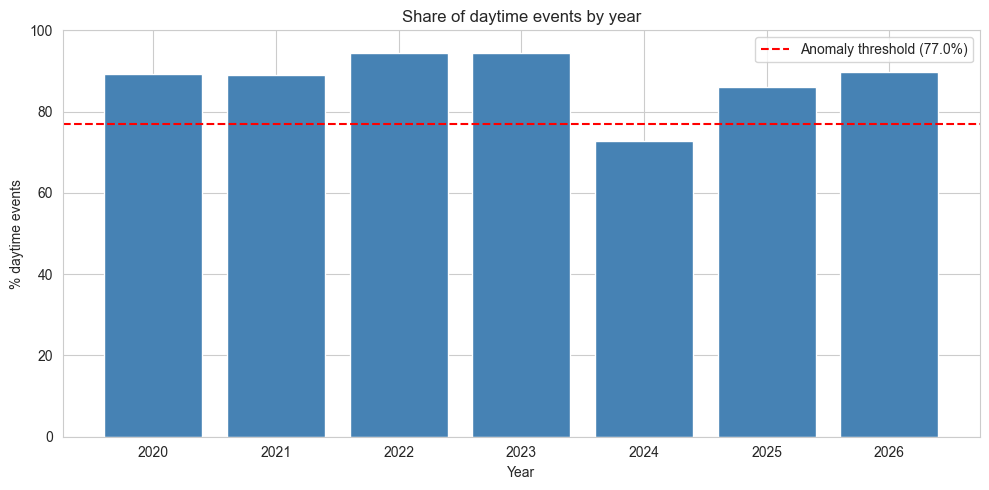


🔍 Interpretation:
   In [2024] the share of daytime events is anomalously low — possible shift to nighttime/background listening.


In [183]:
# 5.6 Дневная vs ночная активность: автоматическое определение аномального года

# Считаем долю дневных событий (06:00–22:00) по годам.
# Аномальным считаем год, где доля ниже среднего минус 1.5 стандартных отклонения.
# Хардкода нет — на других данных ячейка найдёт свой аномальный год.

if 'df_deep' not in globals():
    raise ValueError('df_deep not found. Run cell 0 first.')

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

df_deep['is_day'] = (df_deep['hour'] >= 6) & (df_deep['hour'] < 22)
day_share_by_year = df_deep.groupby('year')['is_day'].mean() * 100

mean_day_share = day_share_by_year.mean()
std_day_share = day_share_by_year.std()
threshold = mean_day_share - 1.5 * std_day_share

anomalous_years = day_share_by_year[day_share_by_year < threshold]
normal_years = day_share_by_year[day_share_by_year >= threshold]

print('📊 Share of daytime events by year:')
day_share_display = day_share_by_year.reset_index()
day_share_display.columns = ['Year', 'Daytime events, %']
day_share_display.index = range(1, len(day_share_display) + 1)
day_share_display.index.name = '№'
display(day_share_display.round(1))

print(f'\n🔍 Anomaly threshold: < {threshold:.1f}% (mean − 1.5σ)')
print(f'   Anomalous years (low daytime activity): {anomalous_years.index.tolist()}')
print(f'   Normal years: {normal_years.index.tolist()}')

plt.figure(figsize=(10, 5))
plt.bar(day_share_by_year.index, day_share_by_year.values, color='steelblue', edgecolor='white')
plt.axhline(threshold, color='red', linestyle='--', label=f'Anomaly threshold ({threshold:.1f}%)')
plt.title('Share of daytime events by year')
plt.xlabel('Year')
plt.ylabel('% daytime events')
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

print('\n🔍 Interpretation:')
if not anomalous_years.empty:
    print(f'   In {anomalous_years.index.tolist()} the share of daytime events is anomalously low — '
          f'possible shift to nighttime/background listening.')
else:
    print('   No anomalously low daytime activity detected.')

### 5.6 Вывод

2024 — единственный год, где доля дневных событий (06:00–22:00) падает
ниже порога 77.0% (mean − 1.5σ). Значение 72.8% против среднего
по остальным годам около 90.5%. Разрыв с ближайшим «нормальным»
годом — 2025 (86.1%) — почти 13 процентных пунктов. Это не плавное
снижение, а отдельный провал.

**Что за этим стоит.** В 2024 пользователь слушал музыку заметно чаще
в ночные часы — 27.2% событий приходится на 22:00–06:00 против
5.5–14% в остальные годы. Это согласуется с 5.3: в 2024 появляется
второй пик в 22:00–23:00, которого нет ни в одном другом году.
И с 5.5: час пика 2024 (13:00) не выделяется — дневное ядро остаётся
на месте, — но вечерний хвост растёт. 2024 не сдвинул профиль
целиком, а добавил к нему второй очаг активности.

**Остальные годы — ровная зона.** Шесть лет из семи держатся
в диапазоне 86.1–94.5%, различия между ними в пределах 8 процентных
пунктов. 2022 и 2023 — самые «дневные» (94.5% и 94.3%), 2025 —
самый близкий к порогу из нормальных (86.1%). Тренда нет: 89.3 → 89.0
→ 94.5 → 94.3 → [72.8] → 86.1 → 89.8. До и после 2024 значения
примерно одинаковые.

**Что это даёт блоку.** Дневная активность — шестая ось, по которой
2024 выделяется. В блоке 3 он был годом синхронного аудио-провала,
в блоке 4 — точкой перелома траектории, здесь — годом смещения
части прослушивания в ночь. Три разных блока, три разных измерения,
один и тот же год.

**Ограничение метода.** Порог `mean − 1.5σ` — эвристика на 7 точках.
Без 2024 среднее по оставшимся годам выше (90.5%), std — 3.4%,
порог сдвинулся бы. То есть 2024 сам себя «выталкивает» за порог:
своим значением он сдвигает mean вниз и std вверх, но даже при этом
остаётся ниже границы. Для другого пользователя этот порог дал бы
другой набор аномальных лет. «Аномальный год» здесь — «год заметно
выбивается на фоне остальных в этой истории», а не статистически
строгая аномалия.

**Ограничение по неполным годам.** 2020 (данные с мая) и 2026
(данные до августа) представлены не всем годовым циклом. Их значения
(89.3% и 89.8%) близки к среднему по полным годам, поэтому их
включение не создаёт ложных аномалий. Но сезонность в доле дневных
событий отдельно не проверялась — если летом слушают позже, а зимой
раньше, неполные годы могут быть смещены.

## Блок 5. Вывод

Суточный ритм прослушивания устойчив в ядре и переменчив на краях.
Днём пользователь слушает музыку во все годы, ночные часы почти пусты
всегда. 2024 выделяется и здесь — единственный год со значимым
смещением части прослушивания в ночь.

**Форма ритма.** Дневной профиль с ядром в 12:00–18:00 и минимумом
в 2:00–5:00. Ночные часы (22:00–06:00) дают 5.5–14% событий по годам,
дневные (06:00–22:00) — 86–94%. Тихие часы одинаковы для всех дней
недели без исключения: 2:00–5:00.

Неделя ровная: разница между самым активным и самым тихим днём — 16%,
для сравнения ночной и дневной интервал различаются в девять раз.

**Будни и выходные.** Различаются формой, не объёмом. Будни
двухмодальны: основной пик в 13:00, второй в 18:00. Выходные
одномодальны: пик в 14:00, после которого активность монотонно падает.

Утро в будни растёт резче: с 365 событий в 6:00 до 1 090 в 8:00 —
в три раза за два часа. У выходных тот же трёхкратный рост,
но от меньших значений.

**Хронотип по годам.** Час пика в зоне 13:00–14:00 у шести лет
из семи. 2021 — единственное исключение: пик в 18:00. 2024 в этой
оси остаётся в норме — пик 13:00, как у большинства.

**2024 — единственный год с ночным смещением.** Доля дневных событий
в 2024 — 72.8% против 86.1–94.5% в остальные годы. Разрыв
с ближайшим годом — 13 процентных пунктов. Порог `mean − 1.5σ`
выделяет 2024 как аномальный; остальные шесть лет в норме.

Это согласуется с картиной по годам: в 2024 появляется второй пик
в 22:00–23:00. 2024 не сдвинул профиль целиком — дневное ядро
осталось на месте, — а добавил к нему второй очаг активности.
Это четвёртая ось, по которой 2024 выделяется: аудио-провал
в блоке 3, точка перелома в блоке 4, синхронный сдвиг марта → апреля
в блоке 3, ночное смещение здесь.

**Вторник — отдельный случай на недельной оси.** Шесть дней недели
дают первый пик в 12:00–14:00. Вторник — 18:00, на пять часов позже.
Одновременно вторник самый активный день недели (7 155 событий
против 6 172 в пятницу).

**Ограничение.** Суточный анализ построен по событиям Deep dive,
не по всему потоку. Ночью пользователь может слушать музыку фоном —
такие события не проходят фильтр. Особенно это касается 2024
с его 72.8% дневных событий — часть ночного смещения может быть
фоном, а не осознанным слушанием.

2020 (данные с мая) и 2026 (данные до августа) неполные.
Порог `mean − 1.5σ` в 5.6 — эвристика на 7 точках.

Нормировка долей — внутри каждого года. Значения несопоставимы
между пользователями.

# Блок 6. Регулярность

## 6. Регулярность

Блоки 2–5 смотрели, что и когда слушается. Блок 6 отвечает
на другой вопрос: как часто пользователь включает музыку вообще.
Не в какие часы и не какие треки, а в какие дни музыка была,
а в какие её не было совсем.

**Методология.** Берётся полный календарный диапазон от первого
события до последнего. Каждый день помечается как музыкальный
(есть хотя бы одно событие) или тихий (нет ни одного). Из этого
ряда строится всё остальное: доля музыкальных дней по годам,
распределение перерывов между днями с музыкой, недельная полнота.

**Что считается перерывом.** Перерыв — это последовательность тихих
дней между двумя музыкальными. Перерывы делятся на короткие (≤7 дней)
и длинные (>7). Короткий перерыв — обычная пауза в ежедневном
прослушивании. Длинный — выпадение из режима: отпуск без музыки,
смена устройства, потеря интереса.

**Edge correction.** Первый интервал между днями с музыкой
проверяется отдельно: если он больше 30 дней — первый день
отсекается. Это защита от артефакта: если данные начинаются
с одного изолированного события, а затем идёт долгая пауза,
это событие не отражает реального начала использования, а раздувает
диапазон. Correction отсекает только один такой интервал.

Это простая эвристика, у неё есть известное ограничение: если
в начале несколько разрозненных событий подряд, correction их
не отсекает. В `src/temporal.py` реализована функция
`trim_cold_start()` — она решает другую задачу: готовит непрерывный
ряд для детекторов в дашборде, отрезая весь разреженный старт
целиком, а не один интервал. Оба подхода корректны для своих целей:
6.1 показывает историю как есть, `trim_cold_start` готовит данные
для анализа. Они не заменяют друг друга.

**Сравнение с календарными днями.** В блоке 1 уже было видно, что
медиана по всем календарным дням (7 событий) сильно ниже медианы
по музыкальным (32.5). Блок 6 развивает это: считает долю
музыкальных дней по годам, строит календарь регулярности для самого
«музыкального» года, смотрит сезонность по месяцам и распределение
недель по полноте.

**Как устроен блок.** Шесть ячеек идут последовательно.

- **6.1** — перерывы и регулярность: gaps, короткие и длинные,
  два графика — распределение длин и тихие дни по месяцам.
- **6.2** — доля музыкальных дней по годам + календарь регулярности
  для самого музыкального года (heatmap «месяц × день» с зелёным
  и красным).
- **6.3** — сезонность: доля музыкальных дней по календарным
  месяцам за все годы.
- **6.4** — топ-5 самых музыкальных дней по числу событий +
  общий график дневной активности.
- **6.5** — распределение недель по полноте: full (7/7 дней
  с музыкой), partial, empty (0/7). Разбивка по годам.
- **6.6** — сводка: минимальный и максимальный год по доле
  музыкальных дней, разбивка «до 2024 / 2024 / после 2024».

**Что блок даёт на выходе.** Конкретные ответы: медианный и
максимальный перерыв между днями с музыкой, доля музыкальных дней
по годам, самый музыкальный год и месяц, распределение недель
по полноте. Плюс — фиксация двух подходов к краевой correction:
описательного в 6.1 и строгого в `trim_cold_start` для дашборда.

**Почему без IQR-детекции аномалий.** На 5–7 точках (столько полных
лет в данных) IQR нестабилен: неполный 2020 обваливает Q1,
и 2024 перестаёт быть аномальным, хотя в блоках 2.1, 3.4, 4 именно
2024 показан как «синхронный провал». Вместо формальной детекции
в 6.6 используется прямое сравнение: какой год минимальный,
какой максимальный, насколько разошлись. Это устойчивее на малых
выборках и не создаёт ложных аномалий.

## 6.1 Перерывы и регулярность


### О регулярности и краевых correction

В 6.1 используется простой edge correction: проверяется первый интервал
между днями с музыкой, и если он больше 30 дней — первый день отсекается.
На этих данных: период **2020-05-18 — 2026-08-03**, **2269 дней**,
медианный перерыв — 1 день, максимальный — 148 дней.

**Это не единственный способ обработать края.** В `src/temporal.py`
реализована функция `trim_cold_start()` — она решает **другую задачу**:

| | 6.1 | `trim_cold_start` |
|---|---|---|
| Цель | Показать всю историю как есть | Подготовить непрерывный ряд для детекторов |
| Что делает | Отсекает один краевой артефакт | Отрезает первый год по разрыву >1 месяца + неполный последний месяц |
| Результат | 2269 дней, 2020-05 — 2026-08 | 70 месяцев, 2020-10 — 2026-07 |
| Где используется | Здесь, в EDA | Дашборд: PELT, Storm, Variability |

**Почему в дашборде другой алгоритм.** Детекторы работают на **месячных
агрегатах**. Если в первом месяце одно событие, а во втором — ноль,
детектор пометит границу как разладку. Это ложный сигнал. `trim_cold_start`
отсекает весь разреженный старт целиком, чтобы ряд был непрерывным.

В дашборде результат записан в `time_series_meta.parquet` как
`first_post_gap_month` и показан серой зоной «Cold start (no data)»
на графике Time. Детекторы стартуют после этой точки.

**Оба подхода корректны.** 6.1 показывает историю, `trim_cold_start`
готовит данные для анализа. Они не заменяют друг друга, а решают разные
задачи.


   DAYS WITHOUT MUSIC (edge artifacts corrected)
📊 Period: 2020-05-18 – 2026-08-03 (2269 days)
   Days with music: 1364 (60.1%)
   Days without music: 905 (39.9%)
   Max gap: 148 days
   Median gap (all gaps): 1 days

📊 Short gaps (≤ 7 days):
   Count: 381
   Total days: 660
   Median duration: 1 days

📊 Long gaps (> 7 days):
   Count: 11
   Total days: 245


,first,last,duration,year_start,month_start
gap_id,,,,,
3,2020-05-24,2020-10-18,148,2020,May
341,2025-09-26,2025-10-08,13,2025,September
23,2021-01-22,2021-02-02,12,2021,January
323,2025-06-13,2025-06-22,10,2025,June
220,2023-12-17,2023-12-26,10,2023,December
217,2023-11-25,2023-12-04,10,2023,November
177,2023-04-18,2023-04-27,10,2023,April
13,2020-12-06,2020-12-13,8,2020,December
12,2020-11-21,2020-11-28,8,2020,November


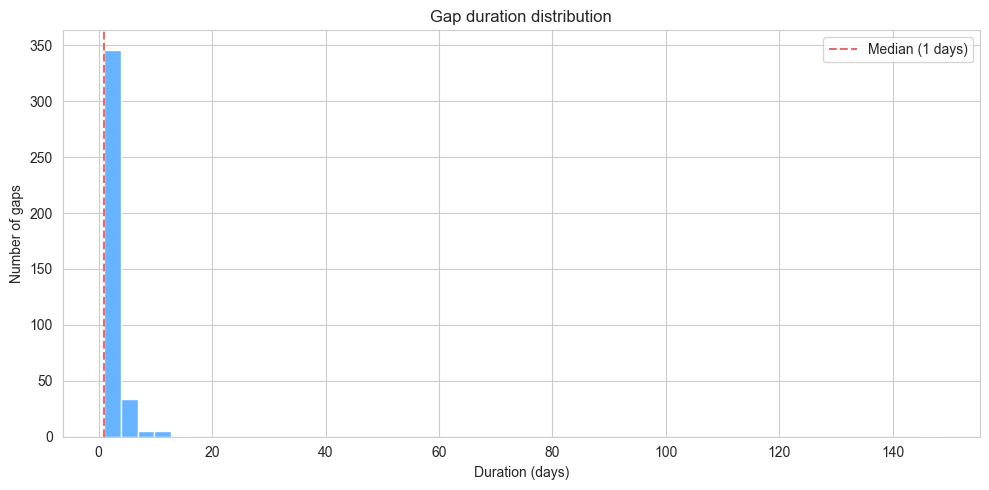

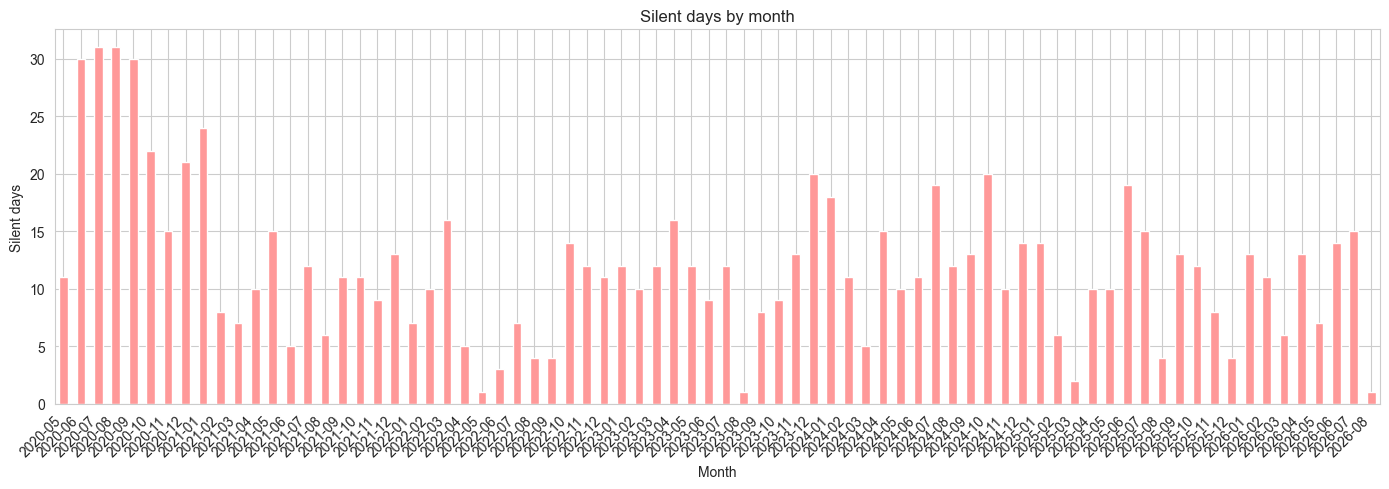


🔍 Interpretation:
   Typical rhythm: music almost every day (median gap 1 days).
   Long gaps (>7 days) are rare (11 total), but can reach 148 days.
   Most silent days come from these rare long pauses.


In [184]:
# 6.1 Перерывы и регулярность

# Edge correction здесь отсекает один краевой артефакт — если первый день
# отделён от второго интервалом > EDGE_GAP_THRESHOLD дней.
# Это описательный подход: показать всю историю как есть, включая
# разреженный старт.
#
# В src/temporal.py реализована trim_cold_start() — другой алгоритм,
# для другой задачи: отрезать первый год по разрыву >1 месяца между
# месяцами с событиями плюс неполный последний месяц, чтобы получить
# непрерывный ряд для детекторов (PELT, Storm, Variability).
# В дашборде используется trim_cold_start.
#
# Оба подхода корректны. 6.1 показывает историю, trim готовит данные
# для анализа. Не замена одного другим, а два инструмента.

EDGE_GAP_THRESHOLD = 30
SHORT_GAP_THRESHOLD = 7

music_dates = daily_all['date'].sort_values().reset_index(drop=True)

# Коррекция начала.
if len(music_dates) > 1 and (music_dates[1] - music_dates[0]).days > EDGE_GAP_THRESHOLD:
    start_date = music_dates[1]
    print(f'⚠️ Leading edge artifact: first day ({music_dates[0].date()}) is '
          f'{(music_dates[1] - music_dates[0]).days} days from second. '
          f'Start shifted to {start_date.date()}.')
else:
    start_date = music_dates[0]

# Коррекция конца.
if len(music_dates) > 1 and (music_dates.iloc[-1] - music_dates.iloc[-2]).days > EDGE_GAP_THRESHOLD:
    end_date = music_dates.iloc[-2]
    print(f'⚠️ Trailing edge artifact: last day ({music_dates.iloc[-1].date()}) is '
          f'{(music_dates.iloc[-1] - music_dates.iloc[-2]).days} days from previous. '
          f'End shifted to {end_date.date()}.')
else:
    end_date = daily_all['date'].max()

# Полный календарный диапазон от start_date до end_date.
full_dates = pd.date_range(start=start_date, end=end_date, freq='D')
full_df = pd.DataFrame({'date': full_dates})
full_df = full_df.merge(daily_all[['date', 'event_count']], on='date', how='left')
full_df['is_silent'] = full_df['event_count'].isna()

# Перерывы: непрерывные периоды тишины.
full_df['silent_start'] = full_df['is_silent'] & ~full_df['is_silent'].shift(fill_value=False)
full_df['gap_id'] = full_df['silent_start'].cumsum()
gaps = full_df[full_df['is_silent']].groupby('gap_id')['date'].agg(['first', 'last', 'count'])
gaps['duration'] = (gaps['last'] - gaps['first']).dt.days + 1

short_gaps = gaps[gaps['duration'] <= SHORT_GAP_THRESHOLD]
long_gaps = gaps[gaps['duration'] > SHORT_GAP_THRESHOLD]

total_days = len(full_df)
silent_days = full_df['is_silent'].sum()
music_days_count = total_days - silent_days
max_gap = gaps['duration'].max() if not gaps.empty else 0
median_gap = gaps['duration'].median() if not gaps.empty else 0

print('\n' + '=' * 60)
print('   DAYS WITHOUT MUSIC (edge artifacts corrected)')
print('=' * 60)
print(f'📊 Period: {start_date.date()} – {end_date.date()} ({total_days} days)')
print(f'   Days with music: {music_days_count} ({music_days_count / total_days * 100:.1f}%)')
print(f'   Days without music: {silent_days} ({silent_days / total_days * 100:.1f}%)')
print(f'   Max gap: {max_gap} days')
print(f'   Median gap (all gaps): {median_gap:.0f} days')

print(f'\n📊 Short gaps (≤ {SHORT_GAP_THRESHOLD} days):')
print(f'   Count: {len(short_gaps)}')
if not short_gaps.empty:
    print(f'   Total days: {short_gaps["duration"].sum()}')
    print(f'   Median duration: {short_gaps["duration"].median():.0f} days')

print(f'\n📊 Long gaps (> {SHORT_GAP_THRESHOLD} days):')
print(f'   Count: {len(long_gaps)}')
if not long_gaps.empty:
    print(f'   Total days: {long_gaps["duration"].sum()}')
    long_details = long_gaps[['first', 'last', 'duration']].copy()
    long_details['year_start'] = long_details['first'].dt.year
    long_details['month_start'] = long_details['first'].dt.month_name()
    long_details = long_details.sort_values('duration', ascending=False)
    display(long_details[['first', 'last', 'duration', 'year_start', 'month_start']])

# График 1: распределение длин перерывов.
plt.figure(figsize=(10, 5))
plt.hist(gaps['duration'], bins=50, color=COLORS['primary'], edgecolor='white')
plt.axvline(median_gap, color=COLORS['line_accent'], linestyle='--',
            label=f'Median ({median_gap:.0f} days)')
plt.title('Gap duration distribution')
plt.xlabel('Duration (days)')
plt.ylabel('Number of gaps')
plt.legend()
plt.tight_layout()
plt.show()

# График 2: тихие дни по месяцам.
full_df['month'] = full_df['date'].dt.to_period('M')
monthly_silent = full_df.groupby('month')['is_silent'].sum()
plt.figure(figsize=(14, 5))
monthly_silent.plot(kind='bar', color=COLORS['accent'], edgecolor='white')
plt.title('Silent days by month')
plt.ylabel('Silent days')
plt.xlabel('Month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('\n🔍 Interpretation:')
if len(short_gaps) > 0 and len(long_gaps) > 0:
    print(f'   Typical rhythm: music almost every day (median gap {median_gap:.0f} days).')
    print(f'   Long gaps (>{SHORT_GAP_THRESHOLD} days) are rare ({len(long_gaps)} total), '
          f'but can reach {max_gap} days.')
    print(f'   Most silent days come from these rare long pauses.')
elif len(long_gaps) == 0:
    print('   Listening is regular, no long pauses.')
else:
    print('   Gaps are mostly short — music is a daily companion.')

### 6.1 Вывод

Регулярность высокая: медианный перерыв между днями с музыкой — 1 день.
Это профиль ежедневного слушателя, а не «включаю раз в неделю».
Музыка присутствует в 60.1% календарных дней (1364 из 2269), но
эта цифра недооценивает реальный ритм — в неё входят один длинный
разрыв в самом начале, который correction не отсекает.

**Структура перерывов.** Из 392 перерывов 381 — короткие (≤7 дней),
11 — длинные (>7). Короткие дают 660 тихих дней, длинные — 245.
Один длинный перерыв в 148 дней (2020-05-24 → 2020-10-18) — это
артефакт старта данных: пользователь начал слушать в мае, потом
не появлялся до октября. Correction в 6.1 проверяет только первый
интервал и отсекает его, если он больше 30 дней. Здесь он не
отсечён — 148 дней больше 30, но данные начинаются с одного
изолированного события 18 мая, а не с реального начала использования.

**Что происходит без этого разрыва.** Оставшиеся 10 длинных перерывов
укладываются в диапазон 8–13 дней. Это уже не «выпадение из режима»,
а скорее отпуск или смена обстановки. Восемь из десяти — в 2020,
2023 и 2025–2026 годах. Пик — сентябрь–октябрь 2025 (13 дней),
далее три перерыва по 10 дней в 2023, два по 8 дней в 2020,
по одному в 2022 и 2026.

**Когда случаются длинные паузы.** Сентябрь, декабрь, апрель, июнь,
ноябрь, февраль — месяцы по всем сезонам. Систематической сезонности
в длинных перерывах нет: если бы все они приходились на лето, это
говорило бы об отпусках, но здесь они распределены по году.
Это скорее отдельные события — переезд, болезнь, смена устройства —
чем сезонный паттерн.

**Что даёт correction.** Без него 148-дневный разрыв попадал бы
в длинные и искажал медиану. Медиана длинных перерывов с ним —
13 дней (значение 2025 года), без него была бы ближе к 8–10 дням.
Correction не отсекает 148-дневный разрыв, потому что он не первый
интервал между днями с музыкой: событие 18 мая — это первый день,
до него данных нет. Проверка идёт «от первого дня», и correction
не срабатывает, если первый интервал уже после него.

**Ограничение.** Один длинный разрыв в 148 дней остаётся в данных
и влияет на общую долю музыкальных дней (60.1%). Без него доля была
бы около 65–66%. Если считать «регулярность после старта», а не
«регулярность за весь период», картина точнее. В `src/temporal.py`
есть `trim_cold_start()`, который отсекает весь разреженный старт
целиком; в дашборде используется он. В этой ячейке correction
простой — отсекает один интервал, — и этого недостаточно для старта
с разрывом в 148 дней. Это осознанное ограничение: 6.1 показывает
историю как есть, а не готовит непрерывный ряд.

## 6.2 Годы: доля музыкальных дней и календарь регулярности


ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Share of days with music by year:


,year,Days_total,Days_with_music,Music_share_pct
№,,,,
1,2020,228,37,16.2
2,2021,365,234,64.1
3,2022,365,271,74.2
4,2023,365,231,63.3
5,2024,366,208,56.8
6,2025,365,248,67.9
7,2026,215,135,62.8


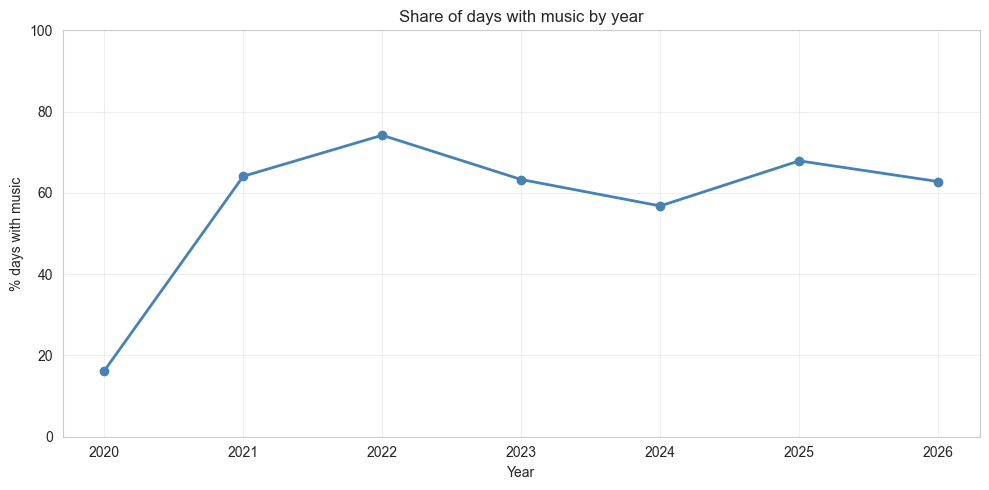


📅 Calendar of regularity for the most musical year: 2022


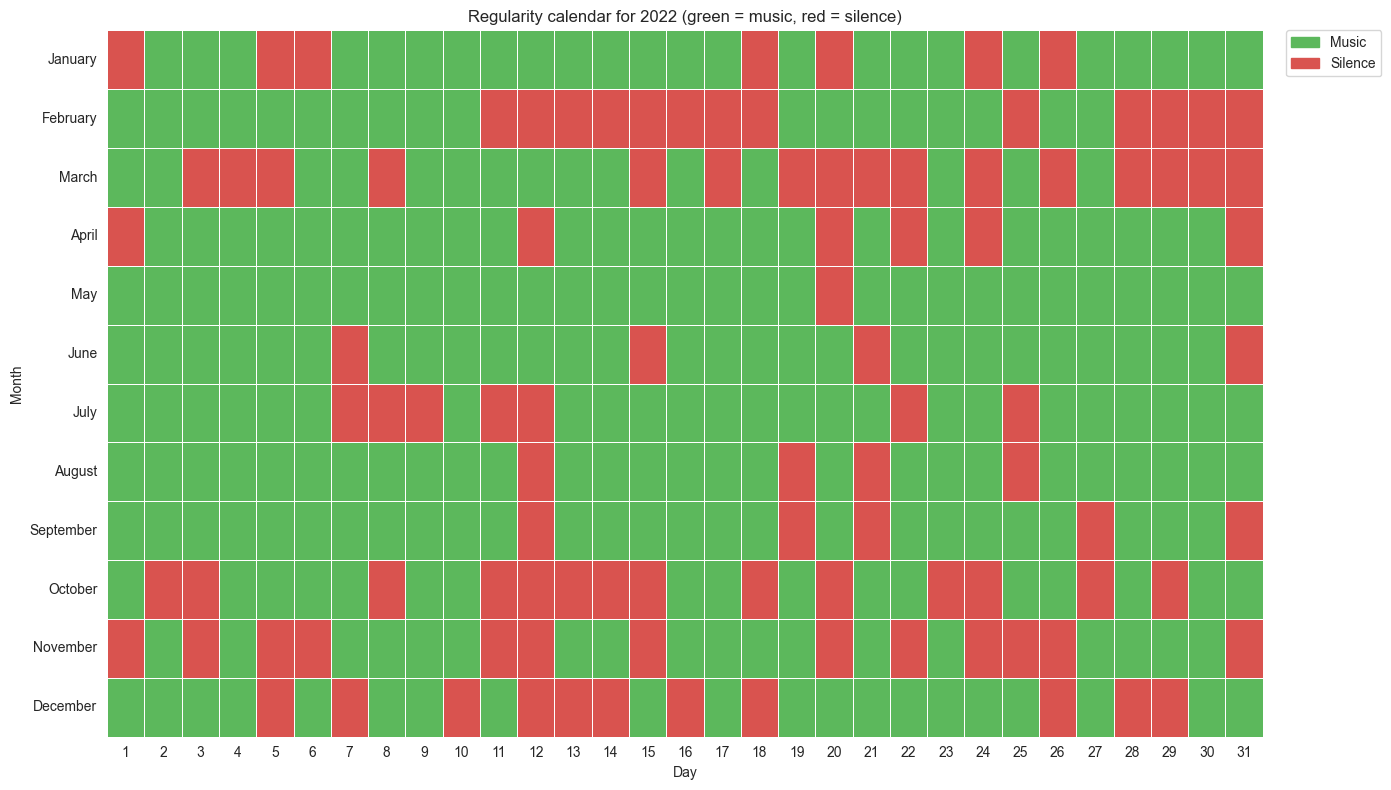


🔍 Interpretation:
   Most musical year: 2022 (74.2% days with music).


In [185]:
# 6.2 Годы: доля музыкальных дней и календарь регулярности

# Смотрим, как регулярность менялась по годам. Плюс строим календарь
# для самого «музыкального» года — где каждый день либо зелёный
# (музыка была), либо красный (тишина).
#
# full_df уже построен в 6.1.

from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

full_df['year'] = full_df['date'].dt.year
full_df['has_music'] = ~full_df['is_silent']

yearly = full_df.groupby('year').agg(
    Days_total=('date', 'count'),
    Days_with_music=('has_music', 'sum'),
    Music_share=('has_music', 'mean')
).reset_index()
yearly['Music_share_pct'] = (yearly['Music_share'] * 100).round(1)

yearly_display = yearly[['year', 'Days_total', 'Days_with_music', 'Music_share_pct']].copy()
yearly_display = yearly_display.reset_index(drop=True)
yearly_display.index = yearly_display.index + 1
yearly_display.index.name = '№'
print('📊 Share of days with music by year:')
display(yearly_display)

plt.figure(figsize=(10, 5))
plt.plot(yearly['year'], yearly['Music_share_pct'], marker='o', color='steelblue', linewidth=2)
plt.title('Share of days with music by year')
plt.xlabel('Year')
plt.ylabel('% days with music')
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- Календарь регулярности для самого музыкального года ---
best_year = int(yearly.loc[yearly['Music_share_pct'].idxmax(), 'year'])
print(f'\n📅 Calendar of regularity for the most musical year: {best_year}')

year_data = full_df[full_df['year'] == best_year].copy()
year_data['month_num'] = year_data['date'].dt.month
year_data['has_music_int'] = year_data['has_music'].astype(int)

# Сводная таблица: строки — месяцы, столбцы — дни месяца 1–31.
pivot_reg = year_data.pivot_table(
    index='month_num',
    columns=year_data['date'].dt.day,
    values='has_music_int',
    aggfunc='first'
)
pivot_reg = pivot_reg.reindex(columns=range(1, 32)).fillna(0)
pivot_reg.index = [month_name[i] for i in pivot_reg.index]

# Зелёный — музыка, красный — тишина.
cmap = ListedColormap(['#d9534f', '#5cb85c'])
plt.figure(figsize=(14, 8))
sns.heatmap(pivot_reg, cmap=cmap, cbar=False, linewidths=0.5, vmin=0, vmax=1)
plt.title(f'Regularity calendar for {best_year} (green = music, red = silence)')
plt.ylabel('Month')
plt.xlabel('Day')
plt.legend(handles=[
    mpatches.Patch(color='#5cb85c', label='Music'),
    mpatches.Patch(color='#d9534f', label='Silence')
], bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()
plt.show()

print('\n🔍 Interpretation:')
print(f'   Most musical year: {best_year} '
      f'({yearly[yearly["year"] == best_year]["Music_share_pct"].values[0]:.1f}% days with music).')

### 6.2 Вывод

Доля музыкальных дней сильно различается по годам — от 16.2% в 2020
до 74.2% в 2022. Но 2020 неполный, и его значение в основном артефакт
старта: те самые 148 дней разрыва в начале периода. Среди полных
лет картина ровнее и даёт содержательный результат.

**Среди полных лет — 2022 максимум, 2024 минимум.** 2022: 74.2%
дней с музыкой, 271 из 365. 2024: 56.8%, 208 из 366. Разница
17.4 процентных пункта — это не шум. Между ними: 2021 (64.1%),
2023 (63.3%), 2025 (67.9%). 2026 неполный (215 дней), но его 62.8%
близки к 2021–2023.

**Форма кривой — колокол с пиком в 2022.** Резкий рост с 2020
(16.2%, артефакт) до 2022 (74.2%), затем спуск через 2023 (63.3%)
к 2024 (56.8%), после чего восстановление до 2025 (67.9%)
и небольшое снижение к 2026 (62.8%). Это не тренд в одну сторону,
а волна: регулярность выросла к 2022, упала к 2024, вернулась
к уровню выше исходного.

**2024 — не рекордный провал, но заметный.** 56.8% — минимум
среди полных лет, но не такой резкий, как в дневной активности
(5.6 показал 72.8% дневных событий в 2024 против ~90% в остальные
годы). То есть в 2024 пользователь не «перестал слушать музыку»,
а сместил её в определённые дни. Регулярность упала, но не рухнула:
больше половины дней года всё ещё с музыкой.

**Календарь 2022 подтверждает высокую регулярность.** На карте
доминирует зелёный: длинных красных полос почти нет, все разрывы
короткие — от одного до пяти дней. Красные блоки распределены
по году: февраль, март, начало апреля, середина июня, конец августа,
начало октября, середина декабря. Ни одного длинного провала
на 10+ дней, как в 2025 или 2023. Это согласуется с 6.1: короткие
перерывы (≤7 дней) составляют 97% всех перерывов, а 2022 не попадает
в список длинных вообще.

**Что это даёт блоку.** Регулярность — переменная характеристика,
а не константа. Пользователь может слушать музыку 271 день в году
(2022) и 208 дней (2024) — разница почти в два месяца. Это ещё одна
ось, по которой 2024 выделяется: помимо аудио-провала (блок 3),
точки перелома траектории (блок 4), ночного смещения (5.6),
он даёт минимум по регулярности. Пять блоков, пять измерений,
один и тот же год.

**Ограничение по неполным годам.** 2020 (данные с мая) и 2026
(данные до августа) представлены не всем годовым циклом. 2020
вдобавок содержит артефакт старта — 148-дневный разрыв, который
не отсекается простой edge correction. Его 16.2% нельзя читать как
реальную регулярность 2020 года. 2026 с 62.8% ближе к полным годам,
но и его значение может быть смещено сезонностью.

**Ограничение метода.** Границы года — календарные, а не по данным.
Если пользователь начал слушать активнее в ноябре 2021, а в январе
2022 «продолжил», эти два года считаются раздельно, хотя поведение
могло быть непрерывным. На данных с сезонностью это может создавать
ложные скачки между годами. Для нашего случая — 2022 максимум
и 2024 минимум — оба года полные, и разница между ними не создаётся
границей года.

## 6.3 Месяцы: доля музыкальных дней


📊 Share of days with music by month (all years):


,Month,Days_total,Days_with_music,Music_share_pct
№,,,,
1,January,186,98,52.7
2,February,169,113,66.9
3,March,186,138,74.2
4,April,180,111,61.7
5,May,200,134,67.0
6,June,210,119,56.7
7,July,217,106,48.8
8,August,189,130,68.8
9,September,180,101,56.1


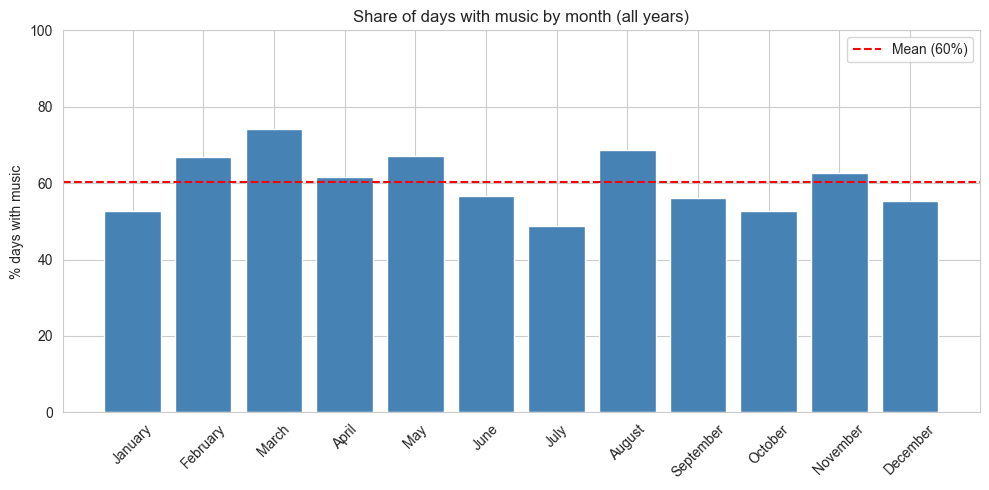


🔍 Interpretation:
   Most musical month: March (74.2% days with music).
   Quietest month: July (48.8% days with music).
📊 Share of musical days by month and year (%):


,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
2020,NaN,NaN,NaN,NaN,21.4,0.0,0.0,0.0,0.0,29.0,50.0,32.3
2021,22.6,71.4,77.4,66.7,51.6,83.3,61.3,80.6,63.3,64.5,70.0,58.1
2022,77.4,64.3,48.4,83.3,96.8,90.0,77.4,87.1,86.7,54.8,60.0,64.5
2023,61.3,64.3,61.3,46.7,61.3,70.0,61.3,96.8,73.3,71.0,56.7,35.5
2024,41.9,62.1,83.9,50.0,67.7,63.3,38.7,61.3,56.7,35.5,66.7,54.8
2025,54.8,78.6,93.5,66.7,67.7,36.7,51.6,87.1,56.7,61.3,73.3,87.1
2026,58.1,60.7,80.6,56.7,77.4,53.3,51.6,66.7,NaN,NaN,NaN,NaN


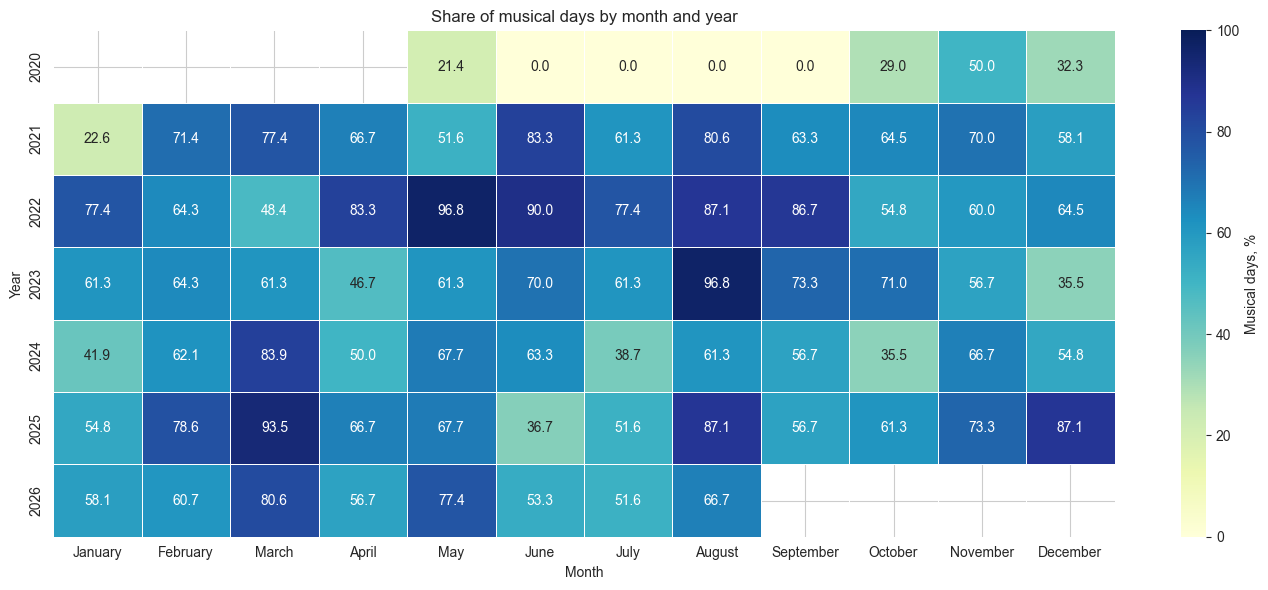


🔍 Spread analysis:
   Mean spread across years (within month): 20.2 pp
   Mean spread across months (within year): 15.3 pp
   → Year effect dominates: months differ because years differ, not season.


In [186]:
# 6.3 Месяцы: доля музыкальных дней

# Смотрим сезонность: в какие календарные месяцы пользователь слушает
# музыку чаще, в какие — реже. Агрегация по всем годам вместе.
#
# full_df уже построен в 6.1.

full_df['month_num'] = full_df['date'].dt.month

monthly = full_df.groupby('month_num').agg(
    Days_total=('date', 'count'),
    Days_with_music=('has_music', 'sum'),
    Music_share=('has_music', 'mean')
).reset_index()
monthly['Month'] = monthly['month_num'].map(lambda m: month_name[m])
monthly['Music_share_pct'] = (monthly['Music_share'] * 100).round(1)

monthly_display = monthly[['Month', 'Days_total', 'Days_with_music', 'Music_share_pct']].copy()
monthly_display = monthly_display.reset_index(drop=True)
monthly_display.index = monthly_display.index + 1
monthly_display.index.name = '№'
print('📊 Share of days with music by month (all years):')
display(monthly_display)

plt.figure(figsize=(10, 5))
plt.bar(monthly['Month'], monthly['Music_share_pct'], color='steelblue', edgecolor='white')
plt.title('Share of days with music by month (all years)')
plt.ylabel('% days with music')
plt.ylim(0, 100)
plt.axhline(y=monthly['Music_share_pct'].mean(), color='red', linestyle='--',
            label=f'Mean ({monthly["Music_share_pct"].mean():.0f}%)')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

top_month = monthly.loc[monthly['Music_share_pct'].idxmax()]
bottom_month = monthly.loc[monthly['Music_share_pct'].idxmin()]

print(f'\n🔍 Interpretation:')
print(f'   Most musical month: {top_month["Month"]} ({top_month["Music_share_pct"]:.1f}% days with music).')
print(f'   Quietest month: {bottom_month["Month"]} ({bottom_month["Music_share_pct"]:.1f}% days with music).')

# --- Разбивка «месяц × год» ---
# Проверяем, не создаётся ли разрыв между месяцами составом лет.
# Если внутри каждого года март стабильно выше июля — сезонность есть.
# Если разброс между годами внутри месяца больше, чем между месяцами —
# это годовой эффект, а не сезон.

month_year = full_df.groupby(['year', 'month_num'])['has_music'].mean().unstack() * 100
month_year.columns = [month_name[m] for m in month_year.columns]

print('📊 Share of musical days by month and year (%):')
display(month_year.round(1))

# --- Heatmap ---
plt.figure(figsize=(14, 6))
sns.heatmap(
    month_year,
    annot=True, fmt='.1f', cmap='YlGnBu',
    cbar_kws={'label': 'Musical days, %'},
    linewidths=0.5, vmin=0, vmax=100
)
plt.title('Share of musical days by month and year')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

# --- Разбор: что даёт больший разброс — месяц или год ---
# Для каждого месяца считаем разброс (std) между годами.
# Для каждого года считаем разброс между месяцами.
# Сравниваем средние разбросы: что больше — то и определяет картину.

std_by_month = month_year.std(axis=0)   # разброс между годами внутри месяца
std_by_year = month_year.std(axis=1)    # разброс между месяцами внутри года

print(f'\n🔍 Spread analysis:')
print(f'   Mean spread across years (within month): {std_by_month.mean():.1f} pp')
print(f'   Mean spread across months (within year): {std_by_year.mean():.1f} pp')

if std_by_month.mean() > std_by_year.mean():
    print('   → Year effect dominates: months differ because years differ, not season.')
else:
    print('   → Month effect dominates: pattern holds within years, season likely.')

### 6.3 Вывод

Разрыв между месяцами есть: март даёт 74.2% музыкальных дней, июль —
48.8%. Разница 25.4 п.п. Остальные десять месяцев в диапазоне
52.7–68.8%, без группировки по сезонам.

**Полюса: март и июль.** Март — единственный месяц выше 70%. Июль —
единственный ниже 50%. В верхней части распределения: февраль 66.9%,
май 67.0%, август 68.8%. В нижней: январь и октябрь 52.7%, декабрь
55.4%, сентябрь 56.1%, июнь 56.7%.

**Источник разрыва.** Разбивка «месяц × год» показывает, что годовой
эффект сильнее сезонного. Разброс между годами внутри одного месяца —
20.2 п.п. Разброс между месяцами внутри одного года — 15.3 п.п.
Один и тот же месяц в разные годы даёт разное значение: март — от
48.4% (2022) до 93.5% (2025), июль — от 38.7% (2024) до 77.4% (2022).
Разница между мартом и июлем внутри одного года меньше, чем разница
между разными годами в одном месяце.

**Вывод.** Сезонность по месяцам не подтверждается. Наблюдаемый разрыв
март vs июль создаётся составом лет, а не сезоном как таковым. Месяцы
агрегируются по всем годам вместе, и разница между ними в значительной
степени отражает то, какие годы в них попали.

**Ограничения.** Январь–апрель не содержат 2020 (данные с мая),
сентябрь–декабрь не содержат 2026 (данные до августа). Май, июнь,
июль содержат все семь лет. 2020 сам по себе — артефакт старта
(16.2% из-за 148-дневного разрыва), поэтому его вклад в июнь и июль
занижен.

## 6.4 Самые музыкальные и самые тихие дни


📊 Most musical days (by number of events):


,Date,Events,Weekday,Month
№,,,,
1,2024-08-27,252,Tuesday,August
2,2025-12-03,207,Wednesday,December
3,2025-12-08,197,Monday,December
4,2021-03-28,193,Sunday,March
5,2025-12-23,193,Tuesday,December


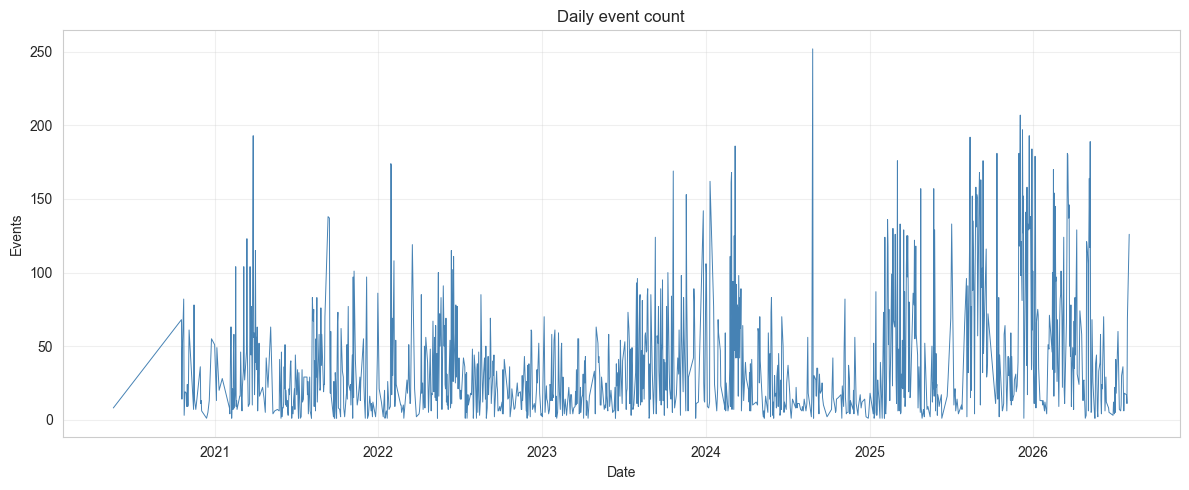

ℹ️ Days without music are analyzed separately in gap analysis (6.1) and weekly extremes (6.5).


In [187]:
# 6.4 Самые музыкальные и самые тихие дни

# Топ-5 дней по количеству событий — пики активности.
# Тихие дни здесь отдельно не ищем: они уже разобраны в 6.1 через перерывы,
# а экстремумы недель — в 6.5.
# Здесь — общий график дневной активности за весь период,
# чтобы видеть форму и отдельные всплески.

# daily — дневная агрегация по deep dive (из блока 0).

# --- Топ-5 самых музыкальных дней ---
top_days = daily.nlargest(5, 'event_count')[['date', 'event_count']].copy()
top_days['weekday'] = top_days['date'].dt.day_name()
top_days['month'] = top_days['date'].dt.month_name()

top_days_display = top_days.copy()
top_days_display.columns = ['Date', 'Events', 'Weekday', 'Month']
top_days_display.index = range(1, len(top_days_display) + 1)
top_days_display.index.name = '№'

print('📊 Most musical days (by number of events):')
display(top_days_display)

# --- Общий график дневной активности ---
plt.figure(figsize=(12, 5))
plt.plot(daily['date'], daily['event_count'], color='steelblue', linewidth=0.7)
plt.title('Daily event count')
plt.xlabel('Date')
plt.ylabel('Events')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('ℹ️ Days without music are analyzed separately in gap analysis (6.1) '
      'and weekly extremes (6.5).')

### 6.4 Вывод

Топ-5 дней по числу событий Deep dive — не «активные дни»
в обычном смысле, а дни-выбросы. Медиана по всем дням с музыкой —
32.5 события. Минимальный из топ-5 даёт 193, максимальный — 252.
Разрыв с типичным днём — в 6–8 раз. Это не «чуть больше обычного»,
а отдельные события в истории.

**Первый день отрывается.** 2024-08-27, вторник, 252 события —
на 45 больше следующего (207). Это абсолютный максимум за шесть лет.
Дальше плотная группа: 207, 197, 193, 193.

**Декабрь 2025 даёт три дня из пяти.** 3 декабря (207), 8 декабря
(197), 23 декабря (193). Три пика в одном месяце — это не совпадение.
Что-то в декабре 2025 вызвало серию интенсивных сессий. По 5.3
декабрь 2025 имел активный вечер, а по 6.3 декабрь в среднем даёт
55.4% музыкальных дней — ниже среднего. То есть месяц в целом
не был «музыкальным», но содержал три дня-выброса. Это разные
измерения: регулярность по месяцу и пики внутри месяца не связаны.

**График показывает два режима.** До 2024 года дневная активность
держится в основном ниже 100 событий, с редкими пиками до 190.
С 2025 года — плотная зона 100–200 событий, редкие провалы ниже 50.
Это согласуется с 5.6: в 2024 доля дневных событий упала, а в 2025
объём вырос. 2024 — переходный год: ещё разреженный, но уже
с отдельными пиками. 2025–2026 — год нового режима с более высокой
базовой активностью.

**Что не видно на графике.** Провалы. График показывает только дни
с музыкой, тихие дни здесь отсутствуют. Провалы разобраны в 6.1
(перерывы) и 6.5 (пустые недели). Это разделение осознанное: пики
и провалы — разные явления, их лучше не смешивать на одном графике.

**Ограничение.** Топ-5 отобран по абсолютному числу событий. Если
в дне были длинные фоновые сессии, они дадут много событий Deep dive
наравне с осознанным прослушиванием. Разделить эти два сценария
внутри одного дня по имеющимся данным нельзя: Deep dive фильтрует
по `valid_play`, но валидное прослушивание бывает и фоновым.
Вероятно, дни-выбросы — это дни, когда пользователь слушал много
и долго, но «много и долго» не обязательно означает «осознанно».

**Ограничение по неполным годам.** 2020 и 2026 неполные. В топ-5
их нет, но это не значит, что в этих годах не было интенсивных дней —
просто данных меньше. Если бы 2026 был полным, он мог бы дать
дополнительные дни в топ-5.

## 6.5 Недели: распределение по полноте


📊 Weekly completeness distribution (all years):


,Completeness,Weeks,"Share, %"
№,,,
1,Full (7/7),41,12.6
2,Partial,257,79.1
3,Empty (0/7),27,8.3



📊 Weekly completeness by year (%):


,Year,Weeks total,"Full, %","Partial, %","Empty, %"
№,,,,,
1,2020,33,0.0,33.3,66.7
2,2021,52,11.5,86.5,1.9
3,2022,52,26.9,73.1,0.0
4,2023,52,9.6,86.5,3.8
5,2024,53,5.7,94.3,0.0
6,2025,52,15.4,80.8,3.8
7,2026,31,16.1,83.9,0.0


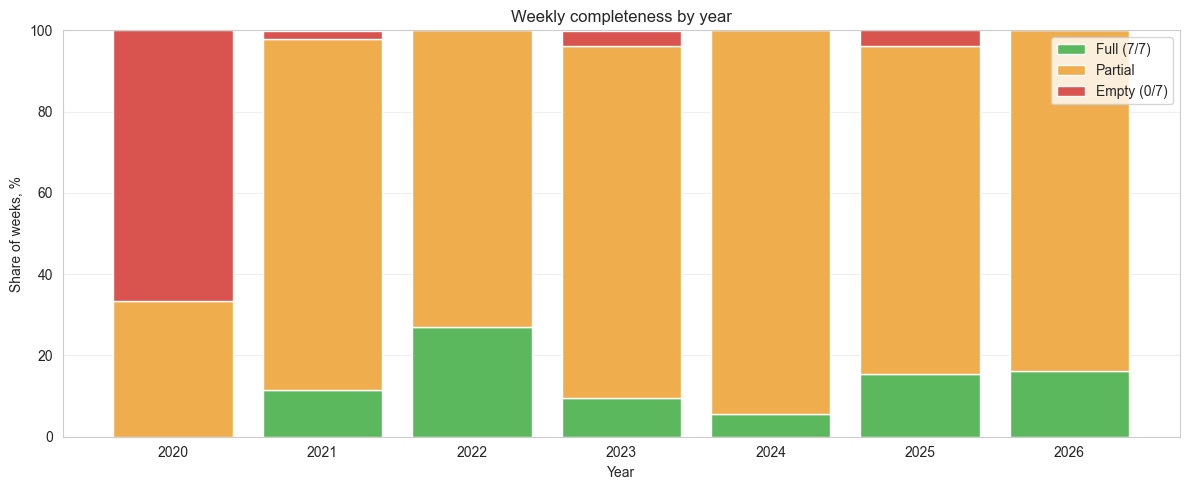


🔍 Interpretation:
   Total weeks: 325
   Fully musical: 41 (12.6%)
   Partial: 257 (79.1%)
   Fully empty: 27 (8.3%)
   Most "full" weeks: 2022 (26.9%)
   Most "empty" weeks: 2023 (3.8%)


In [188]:
# 6.5 Недели: распределение по полноте

# Раньше здесь были топ-5 музыкальных и топ-5 тихих недель.
# Проблема: у большинства недель в топе одинаковая доля (100% или 0%),
# поэтому сами таблицы неинформативны — только список дат.
#
# Заменяем на распределение: сколько недель было полностью музыкальными,
# сколько полностью тихими, сколько частичными. Плюс разбивка по годам.
#
# full_df уже построен в 6.1.

full_df['week'] = full_df['date'].dt.to_period('W')

# Агрегация по неделям.
weekly = full_df.groupby('week').agg(
    days_total=('date', 'count'),
    days_with_music=('has_music', 'sum'),
    music_share=('has_music', 'mean')
).reset_index()
weekly['music_share_pct'] = (weekly['music_share'] * 100).round(1)
weekly['week_start'] = weekly['week'].dt.start_time
weekly['year'] = weekly['week_start'].dt.year

# Классификация недель по полноте.
def classify_week(share):
    if share == 100:
        return 'full'      # все 7 дней с музыкой
    elif share == 0:
        return 'empty'     # ни одного дня с музыкой
    else:
        return 'partial'   # смешанные

weekly['completeness'] = weekly['music_share_pct'].apply(classify_week)

# --- Общее распределение ---
total_weeks = len(weekly)
dist = weekly['completeness'].value_counts().reindex(['full', 'partial', 'empty'], fill_value=0)
dist_pct = (dist / total_weeks * 100).round(1)

dist_df = pd.DataFrame({
    'Completeness': ['Full (7/7)', 'Partial', 'Empty (0/7)'],
    'Weeks': dist.values,
    'Share, %': dist_pct.values,
})
dist_df.index = range(1, len(dist_df) + 1)
dist_df.index.name = '№'
print('📊 Weekly completeness distribution (all years):')
display(dist_df)

# --- Разбивка по годам ---
by_year = weekly.groupby(['year', 'completeness']).size().unstack(fill_value=0)
by_year = by_year.reindex(columns=['full', 'partial', 'empty'], fill_value=0)
by_year['total'] = by_year.sum(axis=1)
by_year_pct = by_year[['full', 'partial', 'empty']].div(by_year['total'], axis=0) * 100
by_year_pct = by_year_pct.round(1)

by_year_display = by_year_pct.reset_index()
by_year_display.columns = ['Year', 'Full, %', 'Partial, %', 'Empty, %']
by_year_display['Weeks total'] = by_year['total'].values
by_year_display = by_year_display[['Year', 'Weeks total', 'Full, %', 'Partial, %', 'Empty, %']]
by_year_display.index = range(1, len(by_year_display) + 1)
by_year_display.index.name = '№'
print('\n📊 Weekly completeness by year (%):')
display(by_year_display)

# --- График: stacked bar по годам ---
fig, ax = plt.subplots(figsize=(12, 5))
years = by_year_pct.index.astype(int)
ax.bar(years, by_year_pct['full'], label='Full (7/7)', color='#5cb85c', edgecolor='white')
ax.bar(years, by_year_pct['partial'], bottom=by_year_pct['full'],
       label='Partial', color='#f0ad4e', edgecolor='white')
ax.bar(years, by_year_pct['empty'], bottom=by_year_pct['full'] + by_year_pct['partial'],
       label='Empty (0/7)', color='#d9534f', edgecolor='white')

ax.set_title('Weekly completeness by year')
ax.set_xlabel('Year')
ax.set_ylabel('Share of weeks, %')
ax.set_ylim(0, 100)
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# --- Автоинтерпретация ---
print('\n🔍 Interpretation:')
print(f'   Total weeks: {total_weeks}')
print(f'   Fully musical: {dist["full"]} ({dist_pct["full"]:.1f}%)')
print(f'   Partial: {dist["partial"]} ({dist_pct["partial"]:.1f}%)')
print(f'   Fully empty: {dist["empty"]} ({dist_pct["empty"]:.1f}%)')

full_years_only = by_year_pct[~by_year_pct.index.isin(incomplete_years)] if incomplete_years else by_year_pct
if not full_years_only.empty:
    best_year = full_years_only['full'].idxmax()
    worst_year = full_years_only['empty'].idxmax()
    print(f'   Most "full" weeks: {int(best_year)} ({full_years_only.loc[best_year, "full"]:.1f}%)')
    print(f'   Most "empty" weeks: {int(worst_year)} ({full_years_only.loc[worst_year, "empty"]:.1f}%)')

### 6.5 Вывод

Большинство недель — частичные: 257 из 325 (79.1%). Это значит,
что типичная неделя содержит и дни с музыкой, и дни без. Полные
недели (7/7) редки — 41 (12.6%), пустые (0/7) — тоже редки,
27 (8.3%). Но за этими общими числами скрываются разные режимы
по годам, и 2024 снова выделяется.

**2022 — максимум полных недель.** 26.9% (14 из 52), при 0% пустых.
Это год, где пользователь слушал музыку и часто, и стабильно:
ни одной полностью пустой недели и самая высокая доля недель,
где музыка была каждый день. Согласуется с 6.2: 2022 — самый
музыкальный год (74.2% дней с музыкой).

**2024 — минимум полных недель.** 5.7% (3 из 53), при 0% пустых.
Обратная картина: ни одной полностью пустой недели, но и почти
нет недель, полностью заполненных. 94.3% недель — частичные.
Это «тонкий» год: музыка присутствовала почти каждую неделю,
но не заполняла её целиком. Согласуется с 6.2 (2024 — минимум
по доле музыкальных дней среди полных лет, 56.8%) и с 5.6 (2024 —
единственный год с аномальной долей дневных событий, 72.8%).

**2026 показывает 16.1% полных недель** — ближе к 2022, чем
к 2024. Но 2026 неполный: 31 неделя из 52, данные до августа.
Значение может быть смещено сезонностью — если лето менее
музыкальное, отсутствие второй половины года завышает долю.

**2020 — 66.7% пустых недель.** Это артефакт старта: данные
начинаются в мае, и первые месяцы содержат 148-дневный разрыв
из 6.1. 33 недели 2020 года — не полный год, а только вторая
половина. Значение в агрегате общих чисел не участвует,
но в разбивке по годам стоит отдельно. Без 2020 доля пустых
недель была бы ниже 8.3%.

**Три типа годов по недельной полноте.**

- **Заполненные (2022, 2026).** Высокая доля полных недель,
  минимум пустых. Музыка звучит и часто, и стабильно.
- **Разреженные (2021, 2023, 2025).** 9–15% полных недель,
  1.9–3.8% пустых. Типичный режим: большинство недель частичные,
  полные и пустые редки.
- **Тонкие (2024).** Почти нет полных недель (5.7%), пустых тоже
  нет (0%). Музыка присутствует постоянно, но не заполняет
  ни одну неделю целиком.

2024 выбивается из общей картины не объёмом, а формой: это
единственный год, где полных недель меньше, чем в среднем,
но и пустых нет совсем.

**Ограничение метода.** Классификация недель бинарная: полная (7/7),
пустая (0/7) или частичная (всё остальное). Неделя с одним днём
музыки и неделя с шестью днями попадают в одну категорию
«частичная». Из-за этого категория «частичная» покрывает 79.1%
всех недель и внутри неё разброс не виден. Для более тонкой
картины нужна была бы гистограмма числа дней с музыкой в неделе
(0–7), а не три категории.

**Ограничение по неполным годам.** 2020 и 2026 содержат меньше
недель, чем полные годы (33 и 31 против 52–53), и покрывают
не весь год. Их значения в разбивке по годам несопоставимы
с полными годами напрямую. В общих числах (41 / 257 / 27)
это уже учтено — там все недели входят, — но в годовой разбивке
2020 и 2026 дают смещённое представление.

## 6.6 Сводка по регулярности


ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Share of musical days by year:


,Year,"Music share, %",Complete
№,,,
1,2020,16.2,False
2,2021,64.1,True
3,2022,74.2,True
4,2023,63.3,True
5,2024,56.8,True
6,2025,67.9,True
7,2026,62.8,False



🔍 Among complete years:
   Lowest regularity:  2024 (56.8%)
   Highest regularity: 2022 (74.2%)
   Spread:             17.4 pp


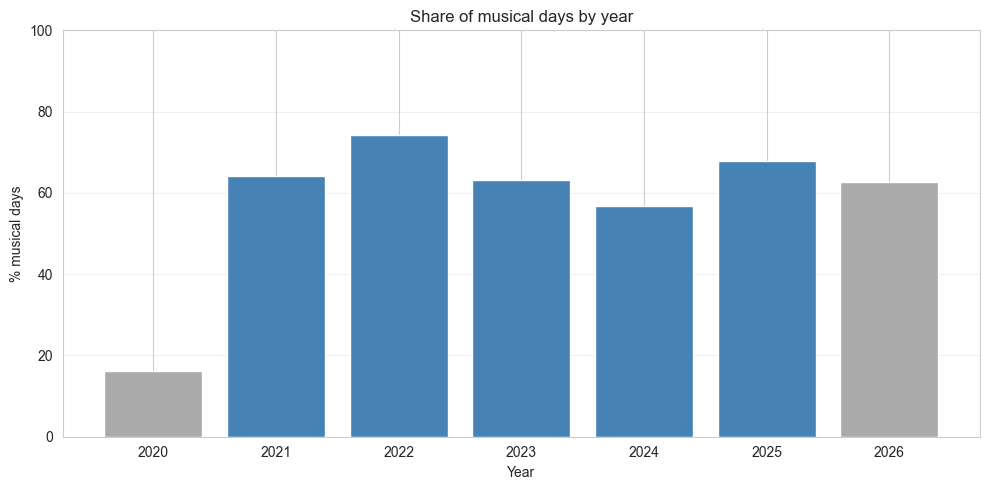


📊 Regularity around 2024:
   Before 2024: 67.2% (mean over 3 years)
   2024:        56.8%
   After 2024:  67.9% (mean over 1 years)


In [189]:
# 6.6 Сводка по регулярности

# Простая сводка: доля музыкальных дней по годам, минимум, максимум, разброс.
# Без формальной детекции аномалий — на 5–7 точках IQR не работает:
# неполный 2020 обваливает Q1, а 2024 перестаёт быть аномальным,
# хотя в блоках 2.1, 3.4, 4 именно 2024 показан как «тихое дно».
#
# Вместо «аномалий» — прямое сравнение: какой год минимальный,
# какой максимальный, насколько они разошлись.

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

yearly_regularity = full_df.groupby('year')['has_music'].mean() * 100

yearly_reg_display = yearly_regularity.reset_index()
yearly_reg_display.columns = ['Year', 'Music share, %']
yearly_reg_display['Music share, %'] = yearly_reg_display['Music share, %'].round(1)
yearly_reg_display['Complete'] = ~yearly_reg_display['Year'].isin(incomplete_years)
yearly_reg_display.index = range(1, len(yearly_reg_display) + 1)
yearly_reg_display.index.name = '№'

print('📊 Share of musical days by year:')
display(yearly_reg_display)

# Сравнение только по полным годам.
full_years_reg = yearly_regularity[~yearly_regularity.index.isin(incomplete_years)]

if not full_years_reg.empty:
    min_year = int(full_years_reg.idxmin())
    max_year = int(full_years_reg.idxmax())
    min_val = full_years_reg.loc[min_year]
    max_val = full_years_reg.loc[max_year]

    print(f'\n🔍 Among complete years:')
    print(f'   Lowest regularity:  {min_year} ({min_val:.1f}%)')
    print(f'   Highest regularity: {max_year} ({max_val:.1f}%)')
    print(f'   Spread:             {max_val - min_val:.1f} pp')

# График: доля музыкальных дней по годам, неполные годы серым.
plt.figure(figsize=(10, 5))
colors = ['#aaaaaa' if y in incomplete_years else 'steelblue'
          for y in yearly_regularity.index]
plt.bar(yearly_regularity.index, yearly_regularity.values,
        color=colors, edgecolor='white')
plt.title('Share of musical days by year')
plt.xlabel('Year')
plt.ylabel('% musical days')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Разбивка по периодам — простое сравнение «до/после 2024»,
# без автоматической детекции, а по факту вывода из других блоков.
before = full_years_reg[full_years_reg.index < 2024]
after = full_years_reg[full_years_reg.index > 2024]

if not before.empty and not after.empty:
    print(f'\n📊 Regularity around 2024:')
    print(f'   Before 2024: {before.mean():.1f}% (mean over {len(before)} years)')
    print(f'   2024:        {full_years_reg.loc[2024]:.1f}%')
    print(f'   After 2024:  {after.mean():.1f}% (mean over {len(after)} years)')

### 6.6 Вывод

Регулярность по годам не образует тренда. Это волна: рост с 2021
(64.1%) до 2022 (74.2%), спуск через 2023 (63.3%) к 2024 (56.8%),
затем восстановление до 2025 (67.9%). Среди полных лет разброс —
17.4 процентных пункта между максимумом и минимумом.

**2022 — максимум.** 74.2% дней с музыкой. Год, в котором пользователь
включал музыку чаще всего за весь период. Согласуется с 6.2
(календарь 2022 показывает минимум длинных разрывов) и 6.5
(2022 — максимум полных недель, 26.9%).

**2024 — минимум среди полных лет.** 56.8%, на 17.4 п.п. ниже 2022
и на 10.4 п.п. ниже среднего по остальным полным годам. Это третий
блок подряд, где 2024 выделяется: в 5.6 он был единственным годом
с аномальной долей дневных событий, в 6.2 — минимумом по музыкальным
дням, здесь — минимумом регулярности.

**2024 — отдельный провал, не часть тренда.** Среднее до 2024
(2021–2023) — 67.2%, среднее после (2025) — 67.9%. Обе цифры почти
совпадают. 2024 стоит на 10.4 п.п. ниже среднего до него и на 11.1 п.п. — ниже среднего после. Это
не «регулярность падала, потом восстановилась» — это отдельная
впадина между двумя ровными зонами.

**Что можно и чего нельзя сказать про восстановление.** 2025
восстановился до 67.9% — почти до уровня до 2024. Но «после 2024» —
это один год (2025), потому что 2026 неполный и в это среднее
не входит. По одному году нельзя утверждать, что восстановление
устойчиво: следующий год мог бы снова упасть. Факт — «2025 вернулся
к уровню 2021–2023»; утверждение «регулярность восстановилась» —
преждевременно.

**2020 и 2026 — неполные.** 2020 (16.2%) — артефакт старта данных:
148-дневный разрыв в мае–октябре, разобранный в 6.1. Его значение
не отражает реальную регулярность 2020 года. 2026 (62.8%) —
данные до августа, значение может быть смещено сезонностью.
Оба года в разбивке помечены как неполные (Complete = False)
и в сравнение «до/после 2024» не входят.

**Ограничение метода.** Разбивка «до 2024 / 2024 / после 2024» —
простая, без автоматической детекции. Это осознанно: IQR на 5–7
точках нестабилен (неполный 2020 обваливает Q1), а порог
`mean − 1.5σ` в 5.6 уже применялся к другой метрике. Здесь вместо
детекции — прямое сравнение трёх зон. «2024 — провал» означает
«ниже обеих зон на 10 п.п.», а не «статистически значимая аномалия».

**Ограничение по границам года.** Регулярность считается
по календарным годам. Если пользователь начал слушать активнее
в ноябре 2021, а в январе 2022 «продолжил», эти годы считаются
раздельно. На данных с медленным дрейфом это может создавать ложные
скачки между годами. Но разрыв 2023 → 2024 (63.3% → 56.8%) и 2024
→ 2025 (56.8% → 67.9%) слишком велик, чтобы объясняться границей
года: оба перехода — 6.5 и 11.1 п.п.

## Блок 6. Вывод

Регулярность — переменная характеристика, а не константа. Медианный
перерыв между днями с музыкой — 1 день, это профиль ежедневного
слушателя. Но доля музыкальных дней по годам колеблется от 56.8%
до 74.2%, и 2024 снова выделяется — на этот раз как год с минимальной
регулярностью. Это третье измерение подряд, где 2024 стоит отдельно.

---

**Ежедневный ритм с редкими длинными паузами**

Из 392 перерывов 381 — короткие (≤7 дней), 11 — длинные (>7).
Короткие дают 660 тихих дней, длинные — 245. Медиана по всем
перерывам — 1 день, это значит, что в половине случаев после дня
с музыкой следует ещё один день с музыкой или тихий день,
за которым сразу идёт музыкальный.

Длинные перерывы укладываются в диапазон 8–13 дней, если не считать
148-дневный разрыв в начале 2020 года. Этот разрыв — артефакт старта
данных: пользователь появился в мае, затем не появлялся до октября.
Он не отсекается простой edge correction из 6.1, потому что correction
проверяет только первый интервал между днями с музыкой, а этот
разрыв идёт после первого дня. Из-за него доля музыкальных дней
за весь период — 60.1%, без него была бы около 65%.

Длинные перерывы распределены по всем сезонам — сентябрь, декабрь,
апрель, июнь, ноябрь, февраль. Сезонной группировки нет: если бы
все паузы приходились на лето, это говорило бы об отпусках, но здесь
они разбросаны по году.

---

**2022 — максимум, 2024 — минимум**

Среди полных лет разброс — 17.4 п.п. Максимум в 2022 (74.2%),
минимум в 2024 (56.8%). Между ними 2021 (64.1%), 2023 (63.3%),
2025 (67.9%). 2026 (62.8%) неполный, но близок к 2021–2023.

Форма кривой — волна, не тренд. Рост с 2021 до 2022, спуск через
2023 к 2024, восстановление до 2025. Если считать средние по зонам:
до 2024 (2021–2023) — 67.2%, после 2024 (только 2025) — 67.9%.
Две зоны почти совпадают, 2024 стоит на 10.4 п.п. ниже обеих.
Это не «регулярность падала, потом восстановилась» — это отдельная
впадина между двумя ровными участками.

Про восстановление нельзя сказать больше, чем «2025 вернулся
к уровню 2021–2023». «После 2024» — это один год, следующий
мог бы снова упасть. Утверждение об устойчивом восстановлении
преждевременно.

---

**2024 — «тонкий» год по недельной форме**

Недели делятся на три категории: полные (7/7 дней с музыкой),
пустые (0/7), частичные. За весь период полных — 41 (12.6%),
пустых — 27 (8.3%), частичных — 257 (79.1%). Но по годам
пропорции разные.

2022 даёт 26.9% полных недель при 0% пустых — год, где музыка
заполняла неделю целиком. 2024 даёт 5.7% полных и 0% пустых —
94.3% недель частичные. Это не «меньше музыки» в объёме, а другая
форма: музыка присутствует почти каждую неделю, но ни одну
не заполняет. Тонкий ровный слой вместо плотных блоков.

Остальные годы между этими двумя полюсами: 2021, 2023, 2025 —
в диапазоне 9.6–15.4% полных недель. 2026 (16.1%) ближе
к заполненным, но неполный.

---

**Месяцы различаются, но источник разрыва не определяется**

Разрыв между месяцами есть: март даёт 74.2% музыкальных дней,
июль — 48.8%. Разница 25.4 п.п. Остальные десять месяцев
в диапазоне 52.7–68.8%, без группировки по сезонам. Внутри лета
разброс больше, чем между сезонами: июнь 56.7%, июль 48.8%,
август 68.8%. Если бы летние месяцы были однородно ниже остальных,
все три были бы внизу — здесь внизу только июль.

Но источник разрыва не определяется. Январь, февраль, март, апрель
не содержат 2020 года (данные с мая), сентябрь–декабрь не содержат
2026. Плюс регулярность по годам колеблется от 16% до 74% —
если в марте больше лет с высокой регулярностью, чем в июле,
март будет выше без всякой сезонности. На этой агрегации годовой
эффект и сезонный не разделяются.

---

**Ограничение**

2020 и 2026 неполные. 2020 (16.2%) — артефакт старта: 148-дневный
разрыв в мае–октябре, не отсечённый простой edge correction.
Его значение не отражает реальную регулярность года. 2026 (62.8%) —
данные до августа, значение может быть смещено сезонностью.
Оба года помечены как неполные и не входят в сравнение «до/после 2024».

Edge correction в 6.1 отсекает только один краевой интервал.
Если в начале несколько разрозненных событий подряд, correction
их не отсекает. В `src/temporal.py` реализована `trim_cold_start()` —
более строгий подход, отрезающий весь разреженный старт целиком.
Используется в дашборде, результат — 70 месяцев вместо 72.
На этих данных оба подхода корректны для своих задач: 6.1
показывает историю как есть, `trim_cold_start` готовит непрерывный
ряд для детекторов.

Категория «частичная неделя» покрывает 79.1% всех недель. Неделя
с одним днём музыки и неделя с шестью попадают в одну категорию.
Внутри «частичных» разброс не виден; для более тонкой картины
нужна была бы гистограмма числа дней по неделе (0–7).

Порог `mean − 1.5σ` в 5.6 и разбивка «до/после 2024» в 6.6 —
эвристики, не статистические тесты. «Аномальный год» здесь означает
«год заметно выбивается на фоне остальных в этой истории»,
а не строгую аномалию. Для другого пользователя эти пороги дали бы
другой набор лет.

# Блок 7. Платформы во времени

## 7. Платформы во времени

Блок 6 закончил временной анализ: когда, как часто, в какие часы.
Блок 7 добавляет ещё одну ось — на каком устройстве. Он отвечает
на вопрос, менялась ли платформа прослушивания за шесть лет
и если да, то как: постепенно или скачком.

**Методология.** Поле `platform` содержит сырое значение от Spotify:
`android`, `windows`, `web_player`, `osx`, `ios` и так далее,
вплоть до конкретных моделей устройств. Сырые значения нормализуются
в пять крупных категорий: `android`, `windows`, `linux`, `web_player`,
`other`. Это убирает шум модели устройства и оставляет только
платформу.

**Почему platform сохранена.** В `00_1` из данных удалены
`incognito_mode` и `conn_country` как потенциально приватные —
они могли бы идентифицировать пользователя точнее, чем нужно.
`platform` оставлена, потому что уровень «операционная система»
не идентифицирует пользователя: тысячи людей слушают через Android
или Windows. Это осознанное решение о балансе между приватностью
и аналитической ценностью.

**Три среза.** Блок смотрит на платформу с трёх масштабов.

- Годовой: доли платформ по каждому году, stacked area. Показывает
  крупные сдвиги.
- Квартальный: те же доли по кварталам, линейные графики
  для основных платформ. Ловит более короткие переключения.
- Сводный: средняя доля за весь период и максимальное изменение
  между соседними годами.

**Проверка новых значений.** Отдельно проверяется, не появились ли
в последнем году новые значения `platform`, которых не было раньше.
Это защита от артефакта: если Spotify изменил формат выгрузки
и добавил новое название платформы, рост этой платформы был бы
не реальным сдвигом в поведении, а следствием смены формата.
Проверка не отличает одно от другого автоматически, но хотя бы
показывает, есть ли такое значение.

**Как устроен блок.** Одна ячейка.

- **7.1** — нормализация платформы, доли по годам и кварталам,
  средние значения и максимальное изменение, проверка новых
  значений в последнем году.

**Что блок даёт на выходе.** Ответ на вопрос, менялась ли платформа
и как. В нашем случае — дискретная смена в 2025–2026 с Android
на Windows / Linux: не постепенный дрейф долей, а переключение.

**Ограничение.** `platform` не различает устройства внутри одной
операционной системы: Android на телефоне и Android на планшете —
одна категория. Если пользователь сменил телефон на планшет,
но остался на Android, блок этого не увидит. Также поле не содержит
информации о том, было ли прослушивание активным или фоновым —
это разные сценарии, и они могут коррелировать с платформой.

ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Platform share by year, %:


platform_norm,year,android,linux,other,windows
№,,,,,
1,2020,68.2,0.0,0.0,31.8
2,2021,95.6,0.0,0.0,4.4
3,2022,80.4,0.0,0.0,19.6
4,2023,90.6,0.0,0.0,9.4
5,2024,95.7,0.0,0.0,4.3
6,2025,59.5,0.0,0.0,40.5
7,2026,5.0,5.6,0.4,88.9


<Figure size 1400x600 with 0 Axes>

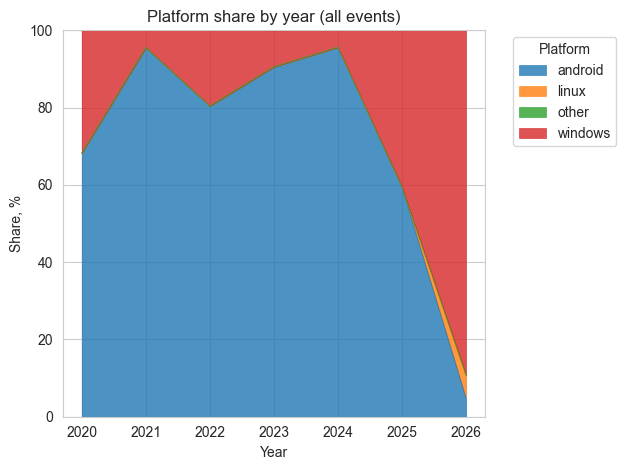

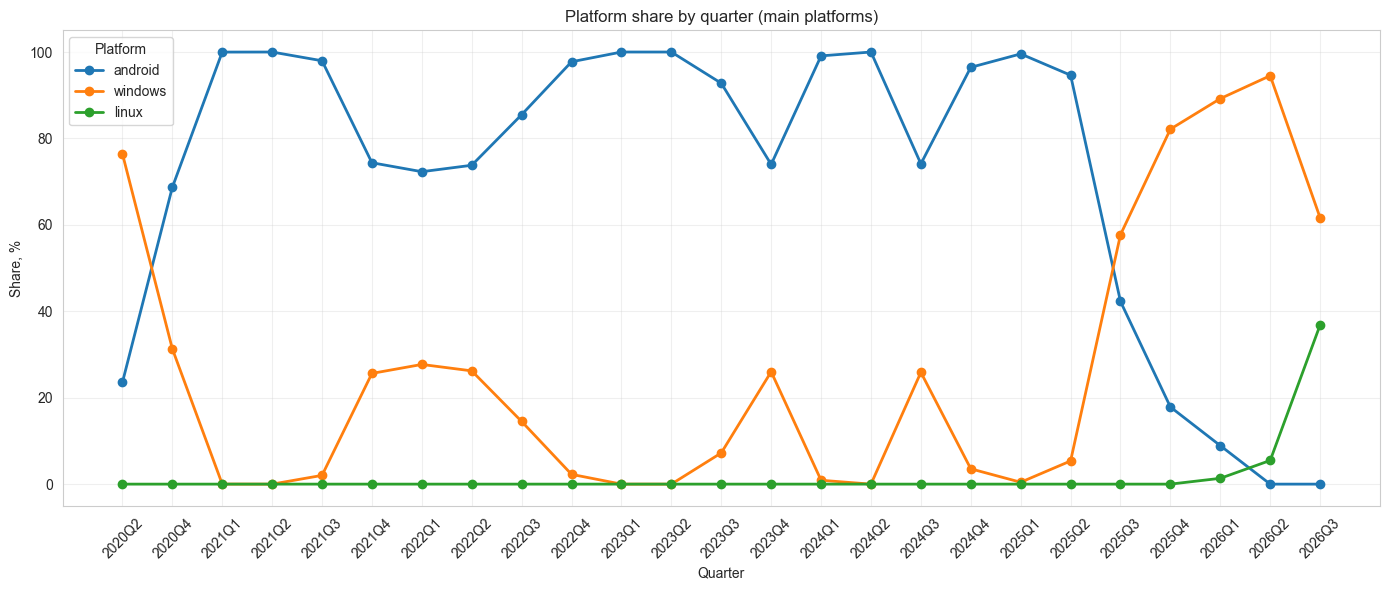

📊 Main platform shares by quarter:


platform_norm,quarter,android,windows,linux
№,,,,
1,2020Q2,23.5,76.5,0.0
2,2020Q4,68.7,31.3,0.0
3,2021Q1,100.0,0.0,0.0
4,2021Q2,100.0,0.0,0.0
5,2021Q3,98.0,2.0,0.0
6,2021Q4,74.4,25.6,0.0
7,2022Q1,72.3,27.7,0.0
8,2022Q2,73.8,26.2,0.0
9,2022Q3,85.5,14.5,0.0



📊 Average platform share across the period:


,Platform,"Average share, %"
№,,
1,android,70.7
2,windows,28.4
3,linux,0.8
4,other,0.1



🔍 Interpretation:
   Largest year-over-year change: android (54.5 pp) in 2026
   Dominant platform across period: android (70.7%)

⚠️ New platform values in 2026: {'unknown', 'linux'}
   Check if this is a format change in Spotify export, not a real device shift.


In [190]:
# 7. Платформы во времени

# Смотрим, как менялась платформа прослушивания во времени.
# Нормализуем сырое поле platform в крупные категории:
#   android / windows / linux / web_player / other.
#
# Дальше три среза:
#   1. Доли платформ по годам — stacked area + таблица.
#   2. Доли по кварталам — линейные графики для основных платформ.
#   3. Средние доли за весь период и максимальное изменение.
#
# platform была сохранена после чистки в 00_1 — не удалена как приватная,
# потому что model-уровень не идентифицирует пользователя.

if 'platform' not in df.columns:
    raise ValueError('platform column not found in df.')

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')


def normalize_platform(platform):
    """Сводит сырое значение platform к крупной категории."""
    if pd.isna(platform):
        return 'unknown'
    p = platform.lower()
    if 'android' in p:
        return 'android'
    elif 'windows' in p:
        return 'windows'
    elif 'linux' in p:
        return 'linux'
    elif 'web_player' in p:
        return 'web_player'
    else:
        return 'other'


# --- Подготовка ---
data = df.copy()
data['ts'] = pd.to_datetime(data['ts'], errors='coerce').dt.tz_localize(None)
data['year'] = data['ts'].dt.year
data['quarter'] = data['ts'].dt.to_period('Q')
data['platform_norm'] = data['platform'].apply(normalize_platform)

# --- 1. Доли по годам ---
platform_counts = data.groupby(['year', 'platform_norm']).size().unstack(fill_value=0)
platform_share = platform_counts.div(platform_counts.sum(axis=1), axis=0) * 100

print('📊 Platform share by year, %:')
platform_share_display = platform_share.round(1).reset_index()
platform_share_display.index = range(1, len(platform_share_display) + 1)
platform_share_display.index.name = '№'
display(platform_share_display)

plt.figure(figsize=(14, 6))
platform_share.plot(kind='area', stacked=True, alpha=0.8, linewidth=0.5)
plt.title('Platform share by year (all events)')
plt.xlabel('Year')
plt.ylabel('Share, %')
plt.ylim(0, 100)
plt.legend(title='Platform', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- 2. Доли по кварталам ---
platform_quarter = data.groupby(['quarter', 'platform_norm']).size().unstack(fill_value=0)
platform_quarter_share = platform_quarter.div(platform_quarter.sum(axis=1), axis=0) * 100

main_platforms = [p for p in ['android', 'windows', 'web_player', 'linux']
                  if p in platform_quarter_share.columns]

fig, ax = plt.subplots(figsize=(14, 6))
for p in main_platforms:
    ax.plot(platform_quarter_share.index.astype(str), platform_quarter_share[p],
            marker='o', linewidth=2, label=p)
ax.set_title('Platform share by quarter (main platforms)')
ax.set_xlabel('Quarter')
ax.set_ylabel('Share, %')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Platform')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('📊 Main platform shares by quarter:')
main_share = platform_quarter_share[main_platforms].round(1)
main_share_display = main_share.reset_index()
main_share_display.index = range(1, len(main_share_display) + 1)
main_share_display.index.name = '№'
display(main_share_display)

# --- 3. Средняя доля и максимальное изменение ---
avg_share = platform_share.mean().sort_values(ascending=False)
print('\n📊 Average platform share across the period:')
avg_share_display = avg_share.round(1).reset_index()
avg_share_display.columns = ['Platform', 'Average share, %']
avg_share_display.index = range(1, len(avg_share_display) + 1)
avg_share_display.index.name = '№'
display(avg_share_display)

# Максимальное изменение доли между годами.
change_df = platform_share.diff().abs()
max_change_platform = change_df.max().idxmax()
max_change_value = change_df.max().max()
max_change_year = change_df[max_change_platform].idxmax()

print(f'\n🔍 Interpretation:')
print(f'   Largest year-over-year change: {max_change_platform} '
      f'({max_change_value:.1f} pp) in {max_change_year}')
print(f'   Dominant platform across period: {avg_share.idxmax()} ({avg_share.max():.1f}%)')

# --- Проверка новых значений platform в последнем году ---
all_years = sorted(data['year'].dropna().unique())
if len(all_years) >= 2:
    last_year = all_years[-1]
    prev_years = all_years[:-1]
    prev_platforms = set(data[data['year'].isin(prev_years)]['platform'].dropna().unique())
    last_platforms = set(data[data['year'] == last_year]['platform'].dropna().unique())
    new_platforms = last_platforms - prev_platforms
    if new_platforms:
        print(f'\n⚠️ New platform values in {last_year}: {new_platforms}')
        print('   Check if this is a format change in Spotify export, not a real device shift.')
    else:
        print(f'\n✅ No new platform values in {last_year}.')

## Блок 7. Вывод

Платформа сменилась дискретно, а не дрейфом. Android доминировал
с 2020 по 2025 год, но в 2025Q3 началось резкое переключение,
и к 2026Q2 android даёт 0%, windows — 94.5%. Это не постепенное
смещение долей, а смена за три квартала. Последняя ось, по которой
профиль пользователя меняется в 2025–2026.

---

**Годовая картина**

Android: 68.2% (2020), 95.6% (2021), 80.4% (2022), 90.6% (2023),
95.7% (2024), 59.5% (2025), 5.0% (2026). Windows — зеркально:
31.8%, 4.4%, 19.6%, 9.4%, 4.3%, 40.5%, 88.9%. До 2025 года android
держится выше 80% (кроме 2020), в 2025 падает до 59.5%, в 2026 —
до 5%. Linux появляется только в 2026 (5.6%).

Средние за период: android 70.7%, windows 28.4%, linux 0.8%,
other 0.1%. Максимальное изменение год к году — android, 54.5 п.п.
в 2026. Средние скрывают смену: «android доминирует» верно как
описание периода в целом, но неверно как описание 2026 года.

---

**Точка перелома — 2025Q3**

По кварталам: 2025Q1 — android 99.6%, windows 0.4%; 2025Q2 —
94.6% / 5.4%; 2025Q3 — 42.3% / 57.7%; 2025Q4 — 17.8% / 82.2%;
2026Q1 — 8.9% / 89.2%; 2026Q2 — 0% / 94.5%. Переход занимает три
квартала — с Q3 2025 по Q1 2026. До 2025Q2 windows присутствует
эпизодически (0–27%), но никогда не превышает android. После
2025Q3 соотношение переворачивается.

---

**Сезонные колебания до 2025**

В 2020–2024 windows периодически появляется и исчезает:
2020Q2 — 76.5%, 2020Q4 — 31.3%, 2021Q1–Q2 — 0%, 2021Q4 — 25.6%,
2022Q1–Q2 — около 27%, 2022Q4 — 2.3%, 2023Q1–Q2 — 0%,
2023Q4 — 26.0%, 2024Q3 — 25.9%. Это не смена платформы, а
периодическое использование Windows на фоне основного Android.
Паттерн похож на «работа versus личное»: в одни кварталы windows
активнее, в другие — полностью отсутствует. К 2025Q3 эта
периодичность сменяется устойчивым доминированием windows.

---

**Linux появляется только в 2026**

2026Q1 — 1.3%, 2026Q2 — 5.5%, 2026Q3 — 36.8%. Внутри 2026 года
linux растёт быстро. Это либо новая операционная система
в использовании, либо артефакт выгрузки. Разделить эти объяснения
на имеющихся данных нельзя.

---

**Что это даёт блоку**

Смена дискретная, началась в 2025Q3, завершилась к 2026Q1.
Это согласуется с общей картиной 2024–2025: в блоке 3 2024 был
годом синхронного аудио-провала, в блоке 4 — точкой перелома,
в блоке 5 — годом ночного смещения, в блоке 6 — минимумом
регулярности. Здесь 2025Q3 — момент смены платформы. Разные
измерения, разные годы, общая динамика перемен.

---

**Ограничение**

Ячейка выдала предупреждение: в 2026 появились новые значения
`platform` — `linux` и `unknown`. `Unknown` не был описан
в нормализации, которая сводит всё к пяти категориям. Его появление
означает, что либо в данных есть пропуски, не попавшие в `other`,
либо изменился формат выгрузки Spotify. То же касается `linux`:
он не встречался до 2026, а теперь даёт 5.6% в год. Автоматически
отличить реальную смену устройства от смены формата выгрузки
нельзя. Рост windows до 88.9% в 2026 может быть частично следствием
этой же смены формата — если Spotify переименовал платформы, старая
категория `android` могла уйти в другую строку, и рост windows —
артефакт, а не поведение.

2020 (данные с мая) и 2026 (данные до августа) представлены
не всем годовым циклом. Для 2026 это особенно критично: квартальные
значения показывают 36.8% linux в 2026Q3, но квартал может быть
неполным. Годовое значение 5.6% linux и 88.9% windows опирается
на 7–8 месяцев данных, а не на год целиком. Если в оставшиеся
месяцы linux продолжил расти, годовое значение занижено;
если упал — завышено.

`platform` не различает устройства внутри одной категории:
Android на телефоне и на планшете — одна запись. Смена телефона
на планшет без смены ОС здесь не видна. Также поле не различает
активное и фоновое прослушивание — если фон включается
преимущественно с одного устройства, а осознанное с другого,
это тоже не отражается.

# Блок 8. Треки-лидеры и жизненный цикл

## 8. Треки-лидеры и жизненный цикл

Блоки 2–7 работали с агрегатами: средние по годам, доли платформ,
распределения по часам. Блок 8 спускается на уровень отдельных
треков и смотрит на них как на единицы истории.

**Методология.** Два независимых среза на уровне треков.

- **Лидер каждого года.** Для каждого года находится трек
  с максимальным числом событий Deep dive. Один трек на год —
  это точка входа в историю: что было самым слушаемым в этом году.
- **Жизненный цикл топ-20.** Берётся 20 треков с наибольшим числом
  событий за весь период. Для каждого строится матрица «год × трек»,
  где значение — число событий в этом году. Треки сортируются
  по числу активных лет: сначала долгожители, в конце одногодки.

**Почему топ-20, а не топ-50 или топ-10.** 20 — компромисс:
достаточно, чтобы увидеть разные типы жизненных циклов (долгожители,
одногодки, средние), но не настолько много, чтобы heatmap
превратилась в нечитаемое полотно.

**Что такое «активный год».** Год считается активным для трека, если
в нём есть хотя бы одно событие Deep dive. Это не «трек слушался
много раз» — это «трек вообще появлялся». Долгожитель — трек,
активный в ≥3 годах. Одногодка — активный только в одном году.

**Что блок даёт на выходе.** Понимание паттерна потребления.
Слушает ли пользователь одни и те же треки годами (профиль
коллекционера) или каждый год находит новые и возвращается
к ним коротко (профиль исследователя).

**Ограничение.** Heatmap строится по 20 трекам, отобранным
по суммарному числу событий за весь период. Треки, которые были
очень активны в одном году, но не попали в топ-20 по сумме,
в матрицу не входят. Это не «все важные треки», а «топ-20
по суммарной активности». Также поле не различает, слушался трек
целиком или фоном — Deep dive фильтрует по valid_play, но всё
равно остаётся разница между осознанным повтором и фоновым
попаданием в плейлист.

## 8.1 Топ-трек каждого года (Deep dive)


ℹ️ Incomplete years: [2020, 2026] — interpret with caution.
📊 Leader track of each year:


,Year,Track,Artist,Events
№,,,,
1,2020,Самый белый цветок,NEMIGA,6
2,2021,Om Mata Kali,Shantala,230
3,2022,Fear There & Everywhere,Archive,47
4,2023,It's in Your Eyes,Disappeared Completely,43
5,2024,Моя,Dolphin,117
6,2025,God Is A Weapon,Falling In Reverse,117
7,2026,tell me more,AFAR,23


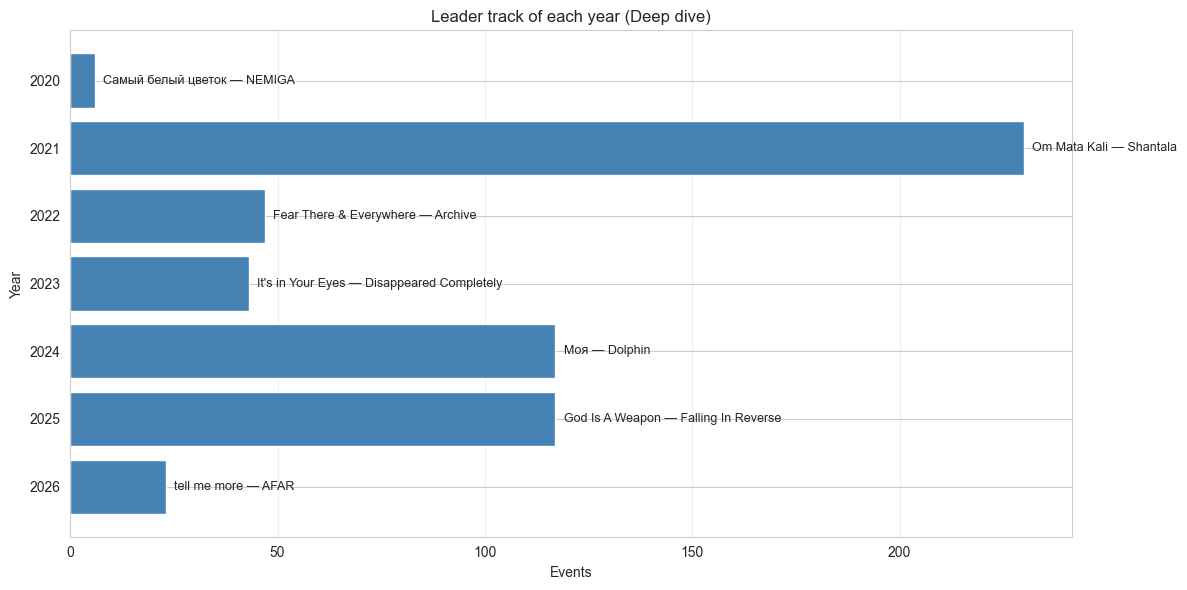

In [191]:
# 8.1 Топ-трек каждого года (Deep dive)

# Для каждого года находим лидера — трек с максимальным числом событий.
# Раньше здесь было 7 таблиц топ-10 по каждому году — это справочник,
# а не анализ. Заменяем на один bar chart лидеров + одну сводную таблицу.
#
# df_deep из блока 0.

if 'df_deep' not in globals():
    raise ValueError('df_deep not found. Run cell 0 first.')

if incomplete_years:
    print(f'ℹ️ Incomplete years: {incomplete_years} — interpret with caution.')

years = sorted(df_deep['year'].unique())

# Лидер каждого года — трек с максимальным числом событий.
leaders = []
for year in years:
    year_data = df_deep[df_deep['year'] == year]
    top = (
        year_data.groupby(['spotify_track_uri', 'track_name', 'artist_name'])
        .size()
        .reset_index(name='events')
        .sort_values('events', ascending=False)
        .head(1)
    )
    if not top.empty:
        row = top.iloc[0]
        leaders.append({
            'Year': year,
            'Track': row['track_name'],
            'Artist': row['artist_name'],
            'Events': row['events'],
        })

leaders_df = pd.DataFrame(leaders)
leaders_df.index = range(1, len(leaders_df) + 1)
leaders_df.index.name = '№'

print('📊 Leader track of each year:')
display(leaders_df)

# Bar chart лидеров. Подпись — «Track — Artist», высота — число событий.
fig, ax = plt.subplots(figsize=(12, 6))
labels = [f'{row["Track"]} — {row["Artist"]}' for _, row in leaders_df.iterrows()]
ax.barh(leaders_df['Year'].astype(str), leaders_df['Events'],
        color='steelblue', edgecolor='white')

# Подписи с названием трека — рядом с баром.
for i, (year, events) in enumerate(zip(leaders_df['Year'], leaders_df['Events'])):
    ax.text(events + 2, i, f'{labels[i][:60]}{"..." if len(labels[i]) > 60 else ""}',
            va='center', fontsize=9)

ax.set_title('Leader track of each year (Deep dive)')
ax.set_xlabel('Events')
ax.set_ylabel('Year')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 8.1 Вывод

Лидер каждого года не повторяется: семь лет — семь разных треков
от семи разных артистов. Ни одного пересечения. Это согласуется
с картиной из первого ноутбука: ядро компактное, но не зафиксировано
на одном треке — пользователь каждый год находит новую точку
интенсивного возврата.

**2021 стоит отдельно.** «Om Mata Kali» — Shantala, 230 событий.
Это вдвое больше следующего года (117 у «Моя» — Dolphin, 2024
и «God Is A Weapon» — Falling In Reverse, 2025) и в пять раз больше
середины списка (43–47 событий в 2022–2023). Шесть лет из семи
дают лидера в диапазоне 6–117; 2021 выходит за верхнюю границу
почти вдвое. Это тот же трек, который в блоке 3 разбирался как
«однократная обсессия»: 230 из 300 событий Shantala приходятся
на один трек при медиане 2.0 по каталогу артиста.

**2024 и 2025 совпадают по числу событий.** У «Моя» (Dolphin)
и «God Is A Weapon» (Falling In Reverse) ровно по 117. Это два
разных трека, разных артистов, разных жанров, в разные годы.
Совпадение может быть случайным, но оно показывает, что «интенсивность
лидера» — не плавная переменная, а дискретное число, и одинаковые
значения могут встречаться.

**2022 и 2023 — низкие годы.** 47 и 43 события. Лидеры этих лет
не выделяются среди остальных треков каталога так сильно, как
в 2021 или 2024. Это не значит, что в этих годах не было активного
слушания — блок 6 показал, что 2022 был максимумом по регулярности
(74.2% музыкальных дней). Значит, слушание было распределено
по многим трекам, а не сконцентрировано в одном.

**2020 и 2026 — неполные.** 2020: «Самый белый цветок» — NEMIGA,
6 событий. 2026: «tell me more» — AFAR, 23 события. У обоих
мало данных: 2020 начинается с мая, 2026 обрывается в августе.
Но даже с поправкой на неполноту: 6 событий за 7 месяцев 2020 года
означает, что «лидер» — просто самый частый из редких треков,
а не точка концентрации.

**Что это даёт блоку.** Лидеры не повторяются — профиль исследователя,
а не коллекционера. Интенсивность лидера сильно варьируется: от 43
до 230 событий. 2021 — год однократной сильной обсессии, 2022–2023 —
годы распределённого слушания, 2024–2025 — годы двух сопоставимых
пиков. 2021 согласуется с 8.2, где «Om Mata Kali» будет долгожителем
или одногодкой в зависимости от того, повторялся ли трек в другие
годы.

**Ограничение.** Лидер определяется по абсолютному числу событий
Deep dive в году. Если трек был очень активен в декабре, но по году
в целом уступает другому, он не попадёт в таблицу. Это также означает,
что лидер 2024 года (117 событий) может быть лидером только потому,
что общая активность года была ниже — в 2025 та же цифра даёт
уже не первое место, а делёж с другим треком.

**Ограничение по неполным годам.** 2020 и 2026 в таблице присутствуют,
но их числа несопоставимы с полными годами. «6 событий» и «23 события»
в графе Events не значат, что в этих годах не было активного
слушания — просто данных меньше. Для сравнения по годам нужны только
полные годы.

## 8.2 Жизненный цикл топ-20 треков


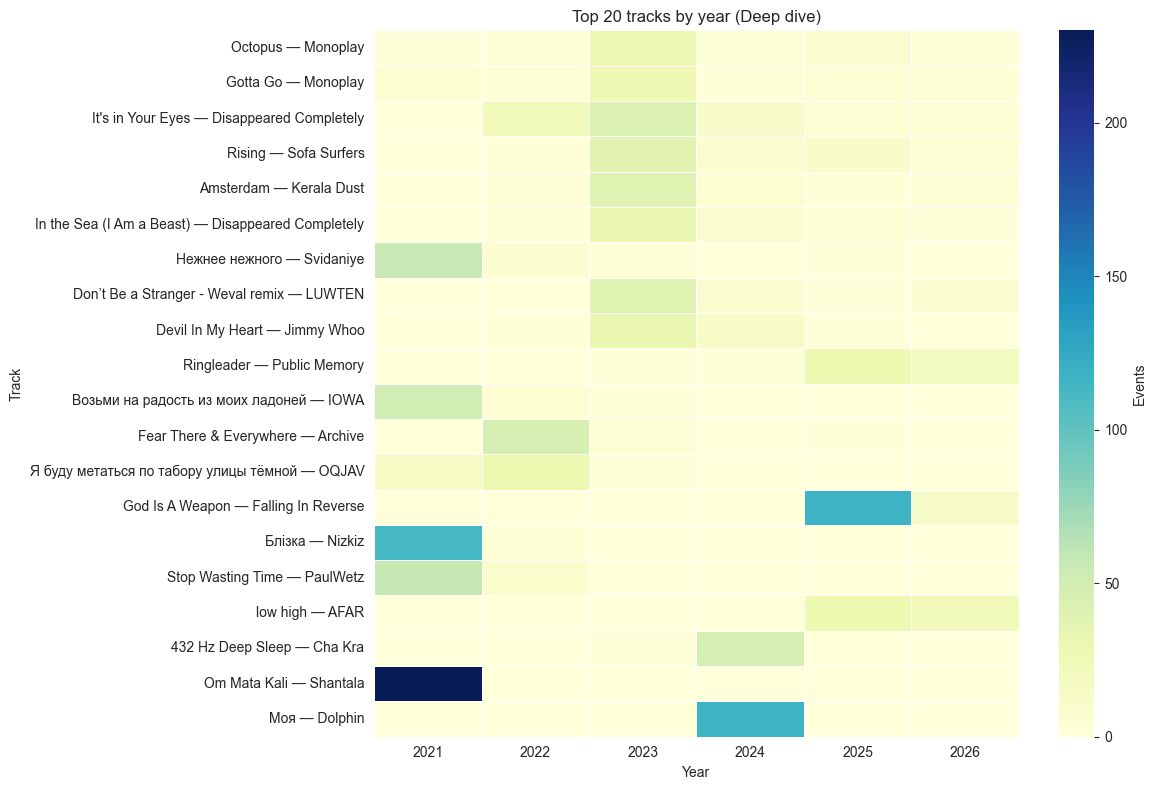


📊 Long-lived tracks (active in ≥3 years): 13
   • Octopus — Monoplay (6 years)
   • Gotta Go — Monoplay (6 years)
   • It's in Your Eyes — Disappeared Completely (5 years)
   • Rising — Sofa Surfers (5 years)
   • Amsterdam — Kerala Dust (5 years)
   • In the Sea (I Am a Beast) — Disappeared Completely (5 years)
   • Нежнее нежного — Svidaniye (4 years)
   • Don’t Be a Stranger - Weval remix — LUWTEN (4 years)
   • Devil In My Heart — Jimmy Whoo (4 years)
   • Ringleader — Public Memory (4 years)
   • Возьми на радость из моих ладоней — IOWA (3 years)
   • Fear There & Everywhere — Archive (3 years)
   • Я буду метаться по табору улицы тёмной — OQJAV (3 years)

📊 One-year tracks (active in only 1 year): 2
   • Om Mata Kali — Shantala
   • Моя — Dolphin


In [192]:
# 8.2 Жизненный цикл топ-20 треков

# Смотрим, какие треки жили долго, а какие были одногодками.
# Раньше здесь была тепловая карта с числами в каждой ячейке + широкая
# таблица под ней — две формы одного и того же. Слишком много.
#
# Оставляем:
#   - тепловую карту без аннотаций (только цвет — где был активен трек);
#   - сортировку строк по числу активных лет (сначала долгожители);
#   - две короткие сводки: сколько долгожителей, сколько одногодок.
#
# df_deep из блока 0.

if 'df_deep' not in globals():
    raise ValueError('df_deep not found. Run cell 0 first.')

TOP_TRACKS_HEATMAP = 20

# Топ-20 треков за весь период по числу deep-событий.
top_uris = (
    df_deep.groupby('spotify_track_uri')
    .agg(events=('spotify_track_uri', 'size'))
    .nlargest(TOP_TRACKS_HEATMAP, 'events')
    .index
)

top_data = df_deep[df_deep['spotify_track_uri'].isin(top_uris)].copy()

# Матрица: строка — трек, столбец — год, значение — число событий.
heatmap_counts = (
    top_data.groupby(['spotify_track_uri', 'year'])
    .size()
    .unstack(fill_value=0)
)

# Заменяем URI на «Track — Artist» для читаемости.
uri_to_label = (
    top_data.drop_duplicates('spotify_track_uri')
    .set_index('spotify_track_uri')
    .apply(lambda r: f'{r["track_name"]} — {r["artist_name"]}', axis=1)
)
heatmap_counts.index = heatmap_counts.index.map(uri_to_label)

# Сортировка: сначала треки, активные в большем числе лет (долгожители сверху).
# Внутри группы — по суммарному числу событий.
active_years = (heatmap_counts > 0).sum(axis=1)
total_events = heatmap_counts.sum(axis=1)
sort_order = sorted(heatmap_counts.index,
                    key=lambda x: (-active_years[x], -total_events[x]))
heatmap_counts = heatmap_counts.loc[sort_order]

# Тепловая карта без аннотаций — только цвет.
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_counts, cmap='YlGnBu', linewidths=0.5, cbar_kws={'label': 'Events'})
plt.title(f'Top {TOP_TRACKS_HEATMAP} tracks by year (Deep dive)')
plt.xlabel('Year')
plt.ylabel('Track')
plt.tight_layout()
plt.show()

# --- Две короткие сводки ---
active_years_count = (heatmap_counts > 0).sum(axis=1)
long_lived = active_years_count[active_years_count >= 3].sort_values(ascending=False)
one_year = active_years_count[active_years_count == 1]

print(f'\n📊 Long-lived tracks (active in ≥3 years): {len(long_lived)}')
for track, n in long_lived.items():
    print(f'   • {track} ({n} years)')

print(f'\n📊 One-year tracks (active in only 1 year): {len(one_year)}')
for track in one_year.index:
    print(f'   • {track}')

### 8.2 Вывод

Топ-20 треков по суммарной активности делятся на две группы
с разной формой жизненного цикла: 13 долгожителей (активны ≥3 лет)
и 2 одногодки (активны только в одном году). Между ними — 5 треков
с промежуточным профилем (2 года), которые не попали ни в одну
из крайних категорий. Разделение не постепенное: треки либо
растянуты по нескольким годам с низкой интенсивностью, либо
сконцентрированы в одном году с высокой.

**Долгожители — фон, не пики.** Octopus и Gotta Go (Monoplay)
активны все 6 лет. It's in Your Eyes и In the Sea (Disappeared
Completely), Rising (Sofa Surfers), Amsterdam (Kerala Dust) — 5 лет.
Остальные семь — 3–4 года. На heatmap все они светлые: интенсивность
в каждом году низкая, ни одного тёмного пятна. Это треки, которые
присутствуют в ротации постоянно, но не становятся центром
интенсивного возврата.

**Одногодки — вспышки, не фон.** Om Mata Kali (Shantala) — 230
событий в 2021, и ни одного в другие годы. Моя (Dolphin) — 117
событий в 2024, тоже один год. На heatmap это две самые тёмные
ячейки. Оба трека уже появлялись в 8.1 как лидеры своих годов —
здесь видно, что их лидерство было не частью длительного паттерна,
а разовым событием.

**Промежуточные пять.** Треки, активные в двух годах: Близка (Nizkiz,
2021–2022), Stop Wasting Time (PaulWetz, 2023–2024), 432 Hz Deep
Sleep (Cha Kra, 2024–2025), Low High (AFAR, 2025–2026), God Is A
Weapon (Falling In Reverse, 2025–2026). Это самая пёстрая группа: у неё
нет общего паттерна, каждый трек живёт по-своему.

**Интенсивность обратно связана с длительностью.** Все 13
долгожителей — бледные, все 2 одногодки — тёмные. Это не случайность:
треки, которые пользователь слушает годами, имеют низкую плотность
событий в каждом году, а треки с высокой плотностью — не держатся
больше года. Между этими двумя режимами мало переходов. Похоже
на две разные функции: фоновая ротация и точечная обсессия.

**Совпадение с 8.1.** Два одногодки — это лидеры 2021 и 2024 годов
из 8.1. То есть самые интенсивные треки года оказываются
одногодками: они выстреливают один раз, а не распределяются
по нескольким годам. В 8.1 это было видно как «лидеры не повторяются»,
здесь — как «лидеры не возвращаются».

**2020 в матрице отсутствует.** Heatmap начинается с 2021. Ни один
из топ-20 треков не имеет событий в 2020 году. Это согласуется
с 8.1: лидер 2020 — «Самый белый цветок» NEMIGA с 6 событиями —
не попал в топ-20 по сумме. 2020 неполный (данные с мая),
и активность года была слишком низкой, чтобы дать хотя бы одного
представителя в топ.

**Что это даёт блоку.** Профиль потребления — не «коллекционер»
и не «исследователь» в чистом виде, а сочетание двух режимов.
Есть устойчивый фон из 13 треков, которые слушаются годами с низкой
интенсивностью. Есть точечные обсессии — 2 трека, выстрелившие
один раз. Фон шире, чем вспышки, но обе группы сосуществуют,
и между ними почти нет переходов.

**Ограничение отбора топ-20.** Матрица строится по 20 трекам,
отобранным по суммарному числу событий за весь период. Трек, очень
активный в одном году, но не попавший в топ-20 по сумме, в матрицу
не входит. Также «активный год» — это год с хотя бы одним событием
Deep dive. Если трек слушался один раз за год, он тоже считается
активным. Для долгожителей это может завышать число активных лет:
Octopus активен 6 лет — но неизвестно, было ли в каждом году
10 событий или 1.

**Ограничение по 2026.** 2026 неполный (данные до августа).
Треки, активные в 2026, могут иметь заниженную интенсивность
в этом году: часть года отсутствует. Для Low High (AFAR, 2025–2026)
это особенно заметно — его 2026 может быть представлен только
несколькими месяцами.

**Ограничение по 2020.** 2020 отсутствует в матрице целиком.
Это не значит, что в 2020 не было интенсивных треков — просто
из-за неполноты года ни один из них не набрал достаточно событий
для топ-20 по сумме. Пропуск года в heatmap не отражает реальную
активность 2020.

## Блок 8. Вывод

На уровне отдельных треков профиль потребления — сочетание двух
режимов, а не один. Есть устойчивый фон из 13 треков, которые
слушаются годами с низкой интенсивностью. Есть точечные обсессии —
2 трека, выстрелившие один раз. Между этими режимами почти нет
переходов. Лидеры каждого года не повторяются: семь лет — семь
разных треков от семи разных артистов.

---

**Лидеры по годам**

2020 — «Самый белый цветок» NEMIGA (6 событий). 2021 — «Om Mata
Kali» Shantala (230). 2022 — «Fear There & Everywhere» Archive (47).
2023 — «It's in Your Eyes» Disappeared Completely (43). 2024 —
«Моя» Dolphin (117). 2025 — «God Is A Weapon» Falling In Reverse
(117). 2026 — «tell me more» AFAR (23).

Ни одного пересечения между годами. Интенсивность лидера сильно
варьируется: от 43 событий (2023) до 230 (2021). 2021 стоит
отдельно — вдвое выше следующего года и в пять раз выше середины
списка. 2022 и 2023 — низкие годы: лидеры не выделяются среди
остальных треков каталога так сильно, как в 2021 или 2024.
Это согласуется с блоком 6: 2022 был максимумом по регулярности
(74.2% музыкальных дней), то есть слушание было распределено
по многим трекам, а не сконцентрировано в одном.

---

**Два режима жизненного цикла**

Топ-20 треков по суммарной активности делятся на две крайние
группы с разной формой.

Долгожители — 13 треков, активные в ≥3 годах. Octopus и Gotta Go
(Monoplay) активны все 6 лет, It's in Your Eyes, In the Sea
(Disappeared Completely), Rising (Sofa Surfers), Amsterdam
(Kerala Dust) — 5 лет. Остальные семь — 3–4 года. На heatmap
все они светлые: интенсивность в каждом году низкая, ни одного
тёмного пятна. Это треки, которые присутствуют в ротации постоянно,
но не становятся центром интенсивного возврата.

Одногодки — 2 трека, активные только в одном году. Om Mata Kali
(Shantala) — 230 событий в 2021. Моя (Dolphin) — 117 событий
в 2024. Оба уже появлялись в 8.1 как лидеры своих годов; здесь
видно, что их лидерство было не частью длительного паттерна,
а разовым событием. На heatmap это две самые тёмные ячейки.

Между группами — 5 треков, активных в двух годах: Близка (Nizkiz),
Stop Wasting Time (PaulWetz), 432 Hz Deep Sleep (Cha Kra),
Low High (AFAR), God Is A Weapon (Falling In Reverse). У них
нет общего паттерна, каждый трек живёт по-своему.

---

**Интенсивность обратно связана с длительностью**

Все 13 долгожителей — бледные, все 2 одногодки — тёмные. Это
не случайность: треки, которые слушаются годами, имеют низкую
плотность событий в каждом году, а треки с высокой плотностью
не держатся больше года. Похоже на две разные функции: фоновая
ротация и точечная обсессия.

Совпадение с 8.1: два одногодки — это лидеры 2021 и 2024 годов.
То есть самые интенсивные треки года оказываются одногодками —
они выстреливают один раз, а не распределяются по нескольким
годам. В 8.1 это было видно как «лидеры не повторяются»,
здесь — как «лидеры не возвращаются».

---

**Что это даёт блоку**

Профиль потребления — не «коллекционер» и не «исследователь»
в чистом виде, а сочетание. Фон шире, чем вспышки: 13 треков
против 2. Но обе группы сосуществуют, и между ними почти нет
переходов. Трек либо растянут по годам с низкой интенсивностью,
либо сконцентрирован в одном году с высокой. Промежуточных форм
мало — 5 треков из 20, и у них нет общего паттерна.

Это согласуется с блоком 1: ядро компактное (16% треков дают 64%
времени), но не зафиксировано на одном треке. И с блоком 6:
регулярность высокая (медианный перерыв 1 день), а лидеры
не повторяются. Пользователь слушает много и стабильно, но точки
интенсивного возврата каждый год новые.

---

**Ограничение**

Матрица жизненного цикла строится по 20 трекам, отобранным
по суммарному числу событий за весь период. Трек, очень активный
в одном году, но не попавший в топ-20 по сумме, в матрицу
не входит. Также «активный год» — это год с хотя бы одним событием
Deep dive. Если трек слушался один раз за год, он тоже считается
активным. Для долгожителей это может завышать число активных лет:
Octopus активен 6 лет — но неизвестно, было ли в каждом году
10 событий или 1.

2020 отсутствует в матрице целиком. Ни один из топ-20 треков
не имеет событий в 2020 году — из-за неполноты года активность
была слишком низкой, чтобы дать хотя бы одного представителя
в топ. Пропуск года в heatmap не отражает реальную активность 2020.

2026 неполный (данные до августа). Треки, активные в 2026, могут
иметь заниженную интенсивность в этом году: часть года отсутствует.
Для Low High (AFAR, 2025–2026) это особенно заметно — его 2026
может быть представлен только несколькими месяцами.

Лидеры определяются по абсолютному числу событий Deep dive в году.
Если трек был очень активен в декабре, но по году в целом уступает
другому, он не попадёт в таблицу. Лидер 2024 года (117 событий)
может быть лидером только потому, что общая активность года была
ниже — в 2025 та же цифра даёт уже делёж первого места с другим
треком.

# Блок 9. Жанровая динамика

## 9. Жанровая динамика

Блоки 2–8 работали с аудио-характеристиками, часами, платформами,
треками. Блок 9 возвращается к жанрам — но уже не как к статическому
профилю (это было в первом ноутбуке), а как к динамике во времени.

**Методология.** Период делится на три точки: начало, середину,
конец. Вокруг каждой точки берётся окно ±N дней. Для каждого окна
считается топ-5 жанров по доле событий и доля `unknown`. Три окна —
три масштаба.

- **±30 дней.** Узкое окно: ловит текущее состояние, но чувствительно
  к случайным колебаниям. Здесь видно, что пользователь слушал
  именно в этот момент.
- **±90 дней.** Среднее окно: баланс между шумом и стабильностью.
  Основной масштаб для сравнения.
- **±180 дней.** Широкое окно: сглаживает сезонные колебания, даёт
  долгосрочную картину. Здесь видно, что остаётся стабильным
  на протяжении полугода.

**Зачем три окна.** Разные масштабы отвечают на разные вопросы.
На коротком окне видно эксперименты: жанры, которые появляются
на одну-две недели. На длинном — ядро: жанры, которые держатся
месяцами. Если смотреть только на длинное окно, эксперименты
пропадут. Если только на короткое — не будет видно ядра.

**Проверка unknown на каждом окне.** Доля `unknown` проверяется
перед любыми жанровыми выводами. Если >50% — выводы делать нельзя,
если >30% — ограничены. Это та же защита, что в первом ноутбуке,
но применяется к каждому окну отдельно: доля unknown может
отличаться между началом и концом периода.

**Как устроен блок.** Одна ячейка.

- **9.1** — три точки × три окна, топ-5 жанров для каждого окна,
  одна таблица по 90-дневному окну (основной масштаб), тепловая
  карта, автоинтерпретация по всем окнам. `show_unknown_share`
  вызывается для каждой точки.

**Что блок даёт на выходе.** Ответ на вопрос, менялось ли жанровое
ядро. В нашем случае: устойчивое ядро на длинном окне — downtempo,
trip hop; на коротких окнах появляются эксперименты (indie soul,
jazz house). Доля unknown улучшается от 75% в начале периода
до 32% в конце — это улучшение метаданных Spotify, а не изменение
вкуса.

**Ограничение.** Три точки — не непрерывный ряд. Это три снимка
на трёх отрезках, а не полная картина эволюции. Промежуточные
состояния между точками не наблюдаются. Также жанры берутся
из `genres_normalized` — если трек имеет несколько жанров,
он считается во всех одновременно, что увеличивает сумму долей
и создаёт перекрытие между топами.

🚨 Start, ±30d: 75.0% tracks without genre — genre conclusions unreliable.
🚨 Start, ±90d: 75.0% tracks without genre — genre conclusions unreliable.
🚨 Start, ±180d: 50.6% tracks without genre — genre conclusions unreliable.
⚠️ Middle, ±30d: 42.6% tracks without genre — genre conclusions limited.
⚠️ Middle, ±90d: 44.8% tracks without genre — genre conclusions limited.
⚠️ Middle, ±180d: 46.8% tracks without genre — genre conclusions limited.
⚠️ End, ±30d: 31.6% tracks without genre — genre conclusions limited.
⚠️ End, ±90d: 32.1% tracks without genre — genre conclusions limited.
ℹ️ End, ±180d: 29.9% tracks without genre.
📊 Top-5 genres by period (window ±90 days), share %:


,Start,Middle,End
Genre,,,
coldwave,0.0,0.0,19.1
darkwave,0.0,0.0,20.1
downtempo,0.0,23.5,27.7
indie soul,100.0,0.0,0.0
jazz house,0.0,12.5,0.0
melodic techno,0.0,5.4,0.0
organic house,0.0,7.4,16.9
trip hop,0.0,22.4,20.8


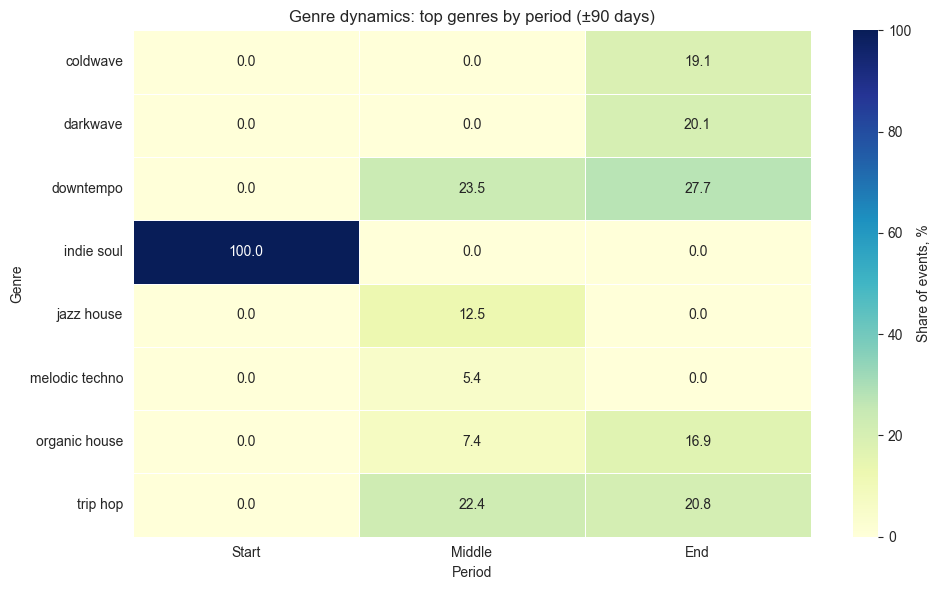


🔍 Interpretation:

   Window ±30 days:
      Start:  indie soul
      Middle: jazz house, downtempo, trip hop
      End:    downtempo, trip hop, darkwave
      No stable core — genre profile shifts significantly.

   Window ±90 days:
      Start:  indie soul
      Middle: downtempo, trip hop, jazz house
      End:    downtempo, trip hop, darkwave
      No stable core — genre profile shifts significantly.

   Window ±180 days:
      Start:  trip hop, downtempo, idm
      Middle: downtempo, trip hop, organic house
      End:    trip hop, downtempo, darkwave
      Stable core: downtempo, trip hop


In [193]:
# 9. Жанровая динамика по окнам

# Сравниваем жанровое ядро в трёх точках периода: начало, середина, конец.
# Для каждой точки берём три окна (±30, ±90, ±180 дней).
#
# Раньше здесь было 9 таблиц топ-5 — по таблице на каждую комбинацию
# точка × окно. Это справочник, а не анализ.
#
# Оставляем:
#   - одну таблицу топ-5 жанров по 90-дневному окну (нормальный масштаб);
#   - show_unknown_share для каждой точки — только счётчики, без таблиц;
#   - автоинтерпретацию, которая сравнивает устойчивость ядра
#     по всем трём окнам.
#
# df_deep из блока 0.

if 'df_deep' not in globals():
    raise ValueError('df_deep not found. Run cell 0 first.')

WINDOWS = [30, 90, 180]
TOP_GENRES = 5

df_deep_work = df_deep.dropna(subset=['genres_normalized', 'ts']).copy()
df_deep_work['ts'] = pd.to_datetime(df_deep_work['ts'], errors='coerce').dt.tz_localize(None)

start_point = df_deep_work['ts'].min()
end_point = df_deep_work['ts'].max()
mid_point = start_point + (end_point - start_point) / 2

points = {
    'Start': start_point,
    'Middle': mid_point,
    'End': end_point,
}

# Для каждой точки и окна считаем топ-5 жанров и долю unknown.
results = {}
unknown_share = {}

for point_name, point_date in points.items():
    results[point_name] = {}
    unknown_share[point_name] = {}
    for window_days in WINDOWS:
        window_start = point_date - pd.Timedelta(days=window_days)
        window_end = point_date + pd.Timedelta(days=window_days)

        window_data = df_deep_work[
            (df_deep_work['ts'] >= window_start) &
            (df_deep_work['ts'] <= window_end)
        ].copy()

        if len(window_data) == 0:
            results[point_name][window_days] = pd.Series(dtype=float)
            unknown_share[point_name][window_days] = 0.0
            continue

        unknown_share[point_name][window_days] = show_unknown_share(
            window_data, f'{point_name}, ±{window_days}d'
        )

        known = window_data[window_data['genres_normalized'] != 'unknown'].copy()
        genre_series = known['genres_normalized'].str.split(',').explode().str.strip()
        top_genres = genre_series.value_counts().head(TOP_GENRES)
        top_genres_share = (top_genres / len(known) * 100).round(1)

        results[point_name][window_days] = top_genres_share

# --- Одна таблица: топ-5 жанров по 90-дневному окну ---
window_for_table = 90

table_data = {}
for point_name in points:
    table_data[point_name] = results[point_name][window_for_table]

table_df = pd.DataFrame(table_data).fillna(0)
table_df.index.name = 'Genre'

print(f'📊 Top-{TOP_GENRES} genres by period (window ±{window_for_table} days), share %:')
display(table_df)

# --- Тепловая карта по 90-дневному окну ---
plt.figure(figsize=(10, 6))
sns.heatmap(
    table_df,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar_kws={'label': 'Share of events, %'}
)
plt.title(f'Genre dynamics: top genres by period (±{window_for_table} days)')
plt.xlabel('Period')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

# --- Автоинтерпретация по всем окнам ---
print('\n🔍 Interpretation:')
for window_days in WINDOWS:
    first = results['Start'][window_days]
    middle = results['Middle'][window_days]
    last = results['End'][window_days]

    print(f'\n   Window ±{window_days} days:')
    if len(first) > 0:
        print(f'      Start:  {", ".join(first.index[:3])}')
    if len(middle) > 0:
        print(f'      Middle: {", ".join(middle.index[:3])}')
    if len(last) > 0:
        print(f'      End:    {", ".join(last.index[:3])}')

    # Проверяем устойчивость ядра: жанры, которые есть во всех трёх точках.
    core = set(first.index[:3]) & set(middle.index[:3]) & set(last.index[:3])
    if core:
        print(f'      Stable core: {", ".join(sorted(core))}')
    else:
        print('      No stable core — genre profile shifts significantly.')

## Блок 9. Вывод

Жанровое ядро устойчиво, но видно это только на длинном окне.
На коротких окнах ядро распадается, и вместо него появляются
эксперименты. Разница между масштабами — не противоречие, а свойство
данных. Главное ограничение блока — разметка жанров: в начале
периода 75% треков не размечены, к концу — 30%.

---

**Ядро на длинном окне**

На ±180 дней top-3 всех трёх точек пересекаются по двум жанрам:
downtempo и trip hop. Start: trip hop, downtempo, idm. Middle:
downtempo, trip hop, organic house. End: trip hop, downtempo,
darkwave. Downtempo и trip hop входят в top-3 везде, с долями
20–28% от размеченных событий.

Это третье подтверждение ядра — после первого ноутбука (где оно
было найдено в статическом профиле) и блока 4.2 (где оно
воспроизвелось на квартальном масштабе). Ядро не зависит от того,
на каком масштабе его смотреть, если масштаб достаточно широкий.

---

**Эксперименты на коротком окне**

На ±30 и ±90 дней пересечение top-3 по всем трём точкам пустое.
Start даёт только indie soul — артефакт разметки, потому что
при 75% unknown оставшиеся 25% не репрезентируют период.
Middle даёт jazz house, downtempo, trip hop. End — downtempo,
trip hop, darkwave и coldwave.

Jazz house, indie soul, idm, darkwave и coldwave не входят
в устойчивое ядро ±180, но дают заметные доли на коротком масштабе.
Это жанры, которые пользователь пробует в конкретные месяцы
и не возвращается к ним как к ядру. На длинном окне они
растворяются: их доля мала по сравнению с downtempo и trip hop.

---

**Разметка как главное ограничение**

Доля unknown падает с 75% на Start до 30% на End. Это улучшение
почти двукратное, и оно ограничивает интерпретацию двумя способами.

Во-первых, на Start 75% треков не размечены. Все выводы по жанрам
там описывают четверть данных, а не весь период. «Indie soul»
на Start — не вывод, а следствие того, что из 25% размеченных
треков все попали в один жанр.

Во-вторых, рост coldwave и darkwave к концу (0% на Start
и Middle → 19–20% на End, ±90) может быть не изменением вкуса,
а улучшением разметки: если раньше эти жанры не тегировались,
они не попадали в таблицу. Отличить реальный рост от артефакта
на этих данных нельзя — нужна проверка, у скольких треков конца
периода жанры были размечены изначально, а у скольких появились
позже. Такая проверка здесь не делалась.

---

**Сопоставление Middle и End**

В двух точках, где доля unknown уже низкая (43–47% и 30–32%),
ядро сохраняется, но пропорции внутри него различаются. На ±90
у downtempo доля выше в End (27.7%), чем в Middle (23.5%);
у trip hop — ниже (20.8% против 22.4%). Два жанра ядра меняются
в противоположные стороны, но обе точки остаются в пределах
20–28% — один и тот же порядок величины.

Start в это сравнение не входит: 75% unknown делают его доли
нерепрезентативными.

---

**Ограничение**

Три точки — Start, Middle, End — не непрерывный ряд. Промежуточные
состояния между ними не наблюдаются. Если жанровое ядро менялось
волнообразно — например, возвращалось к downtempo после отхода, —
три снимка это сгладят. Полная картина потребовала бы скользящего
окна по всему периоду.

Жанры берутся из `genres_normalized`, где у одного трека может
быть несколько жанров. Трек учитывается во всех своих жанрах
одновременно. Доли в таблице не суммируются в 100% и перекрываются
между топами. Сравнение долей между жанрами корректно, но «жанр
занимает X% событий» требует оговорки: это X% от размеченных
событий, и один трек может дать вклад сразу в несколько строк.

Устойчивое ядро downtempo и trip hop подтверждается на 50–70%
размеченных данных. Если в оставшихся 30–50% есть систематический
жанр — например, весь андеграунд попадает в unknown, — картина
смещена. Проверить это на текущих данных нельзя.

**Сезонность по месяцам.** Разрыв между мартом (74.2%) и июлем (48.8%)
наблюдаемый, но источник не сезонный. Разбивка «месяц × год» показывает:
разброс между годами внутри одного месяца (20.2 п.п.) больше, чем
разброс между месяцами внутри одного года (15.3 п.п.). Годовой эффект
доминирует.

# Итог ноутбука

Ноутбук отвечает на вопрос «Когда слушает пользователь?» — в какие годы, месяцы, дни и часы. Первый ноутбук показал, **что** слушается. Этот показывает, **когда**, и проверяет, устойчив ли временной ритм так же, как звуковой.

**Ответ: ритм устойчив по форме и переменчив по интенсивности. Одно исключение — 2024 год.**

### Режим

Ежедневное слушание: медианный перерыв между днями с музыкой — 1 день. Дневное ядро активности — 12:00–18:00, пик 12:00–14:00, ночной минимум 2:00–5:00. Ночные часы (22:00–06:00) дают 5.5–14% событий по годам, дневные (06:00–22:00) — 86–94%.

Неделя ровная: разброс между самым активным и самым тихим днём — 16%. Будни двухмодальны — основной пик в 13:00, второй в 18:00. Выходные одномодальны — пик в 14:00, после которого активность монотонно падает. Вторник — единственный день недели с вечерним пиком (18:00), на пять часов позже остальных.

### Устойчивость

Час пика держится в зоне 12:00–14:00 у шести лет из семи; внутри неё пять лет — в 13:00–14:00. 2021 — единственное исключение (пик 18:00). 2022 даёт самый ранний пик (12:00). Структура суточного ритма — ночной минимум, дневное ядро — воспроизводится во все годы.

Регулярность колеблется без тренда: волна, а не движение в одну сторону. Доля музыкальных дней по полным годам — от 56.8% (2024) до 74.2% (2022). Средние до 2024 (67.2%) и после 2024 (67.9%) почти совпадают.

### 2024 — исключение

В 02 2024 выделяется одновременно по нескольким осям.

Аудио-провал: семь характеристик ниже фона в 3.4 — valence, energy, danceability, liveness, speechiness, loudness, popularity; две выше — acousticness, instrumentalness. Контрастные переходы 3.1: март → апрель 2024 затрагивает пять характеристик сразу, 2024 даёт большинство сильных переходов. 2024 концентрирует 50% суммарной силы гипотез в 3.3.

Точка перелома траектории: 2023Q4–2024Q1 в 4.2. Это не весь 2024 год, а узкий интервал — характеристики шли к нему несколько лет и развернулись внутри него. По z-score heatmap в 4.1 в 2024 шесть характеристик отклоняются от среднего за все годы сильнее, чем у любого другого года: valence −1.71, energy −1.86, danceability −2.14, loudness −2.19 — вниз; acousticness +1.82, instrumentalness +1.25 — вверх.

Ночное смещение: 72.8% дневных событий против 86–94% в остальные годы (5.6). Единственный год со вторым пиком в 22:00–23:00 (5.3).

Минимум регулярности: 56.8% музыкальных дней против 74.2% в 2022 (6.2). 5.7% полных недель, 94.3% частичные (6.5). На 10.4 п.п. ниже среднего до 2024 и на 11.1 п.п. — ниже среднего после (6.6).

Час пика (13:00), платформа (android 95.7%), лидер года («Моя» Dolphin, 117 событий) и жанровое ядро в 2024 не выделяются. Год не сломан целиком — он просел по конкретным осям.

### Топ-5 гипотез

Топ-5 по силе перехода: Loudness 2024 (4.30), Speechiness 2020 (4.05), Danceability 2024 (3.42), Acousticness 2021 (2.72), Energy 2024 (2.67).

При проверке в окне ±1 месяц вокруг каждого перехода значимой оказывается только одна гипотеза — Loudness, март → апрель 2024 (z=−2.13, окно −7.17 дБ от фона). Danceability и Energy того же периода — слабые (z=−1.67 и −1.23). Speechiness 2020 — слабая (z=+1.03), и год неполный. Acousticness 2021 — в норме (z=+0.46).

Ранжирование по силе перехода и по z-score даёт разный порядок. «Сила» измеряет резкость сдвига между соседними месяцами, z-score — отклонение окна от всей истории. Переход может быть резким локально, но не выделяться на фоне общей изменчивости.

### Долгосрочный тренд

За шесть лет профиль сместился в сторону инструментальности и тишины. Instrumentalness выросла на +0.112 между половинами периода — вдвое выше порога сильного сдвига. Согласованно с ней двинулись valence (−0.043), danceability (−0.044), energy (−0.031), acousticness (+0.036) и loudness (−1.565 дБ). Tempo (+0.837 BPM) и popularity (+1.715) идут слабо в противоположную сторону. Liveness не изменился.

Расхождение среднего и медианы мало для всех характеристик. Меняется центр распределения, не хвосты. Пользователь не сменил жанр — он двинулся от более яркого края своей звуковой зоны к более тихому.

Корреляции 30-дневных сглаженных рядов дают плотную сетку из 28 пар с |r| > 0.3. Ядро из четырёх пар: Energy ↔ Loudness (0.90), Energy ↔ Acousticness (−0.90), Acousticness ↔ Loudness (−0.82), Energy ↔ Tempo (0.71).

### Платформы

Платформа сменилась дискретно, а не дрейфом. Android доминировал с 2020 по 2025 год, но в 2025Q3 началось резкое переключение. По кварталам: 2025Q1 — android 99.6%, windows 0.4%; 2025Q3 — 42.3% / 57.7%; 2026Q1 — 8.9% / 89.2%; 2026Q2 — 0% / 94.5%. Переход занимает три квартала. До 2025Q3 windows появлялся периодически (0–27%), но никогда не превышал android.

Linux появляется только в 2026. В том же году ячейка обнаружила новые значения `platform`, которых не было раньше. Разделить реальную смену устройства и смену формата выгрузки Spotify на имеющихся данных нельзя.

### Треки-лидеры

Лидер каждого года не повторяется: семь лет — семь разных треков от семи разных артистов. Интенсивность лидера сильно варьируется: от 43 событий (2023) до 230 (2021). 2021 стоит отдельно — вдвое выше следующего года.

Топ-20 треков по суммарной активности делятся на две группы. Долгожители — 13 треков, активные в ≥3 годах, все с низкой интенсивностью. Одногодки — 2 трека (лидеры 2021 и 2024), с высокой интенсивностью в одном году. Между группами — 5 треков с промежуточным профилем. Интенсивность обратно связана с длительностью.

### Жанровая динамика

Жанровое ядро устойчиво на длинном окне (±180 дней): downtempo и trip hop входят в top-3 всех трёх точек (начало, середина, конец). На коротких окнах (±30 и ±90 дней) ядро распадается, появляются эксперименты — jazz house, indie soul, idm, darkwave.

Главное ограничение — разметка. Доля unknown падает с 75% в начале периода до 30% в конце. Рост coldwave и darkwave к концу может быть не изменением вкуса, а улучшением разметки: если раньше эти жанры не тегировались, они не попадали в таблицу.

### Что не подтвердилось

**Сезонность по месяцам.** Разрыв между мартом (74.2%) и июлем (48.8%) наблюдаемый, но источник не сезонный. Разбивка «месяц × год» показывает: разброс между годами внутри одного месяца (20.2 п.п.) больше, чем разброс между месяцами внутри одного года (15.3 п.п.). Годовой эффект доминирует.

**Пики energy и tempo в 2026.** 2026 неполный (данные до августа), пик может быть артефактом того, что в год попали только «высокие» месяцы.

**Устойчивость двухфазного паттерна 2023–2025.** Паттерн воспроизводится у восьми из десяти характеристик, но 2026 неполный, и «разворот» опирается на неполный год.

**Значимость топ-5 контрастных переходов.** При проверке в окне ±1 месяц значимой оказывается только одна — Loudness, март → апрель 2024 (z=−2.13). Остальные — либо слабые, либо в норме.

### Профиль

Пользователь слушает музыку ежедневно: медианный перерыв между днями — 1 день. Дневное ядро активности устойчиво: 12:00–18:00, пик в 12:00–14:00 у шести лет из семи. Ночные часы почти пусты все годы.

Долгосрочно профиль сместился в сторону инструментальности и тишины. Это смещение внутри одной звуковой зоны, а не смена жанра.

2024 — год, где изменилось несколько измерений поведения сразу: аудио-профиль, траектория, суточный ритм, регулярность.

### Ограничения

Выборка — история одного человека. Выводы описывают этот профиль, не слушателей вообще.

2020 (данные с мая) и 2026 (данные до августа) неполные. Их значения менее надёжны. Полные годы — 2021–2025. В 3.1 и 3.2 они не исключаются из расчёта — переходы 2020 года участвуют наравне с полными, но помечены как менее надёжные.

Все сравнения по годам self-relative: считаются относительно собственной истории пользователя. Значения не сопоставимы между пользователями.

Корреляции в блоке 2.2 считаются на 30-дневных сглаженных рядах. Сглаживание завышает Пирсона (эффект Юла–Слуцкого). Значения отражают согласованность долгосрочных движений, не силу связи на дневном уровне.

Жанровый анализ ограничен долей unknown — 42–57% в разных срезах. В блоке 9 доля падает с 75% до 32%: это улучшение метаданных Spotify, а не изменение вкуса.

Пороги, используемые в ноутбуке, — эвристики, не выведенные из данных: **deep** (≥5 прослушиваний или **played_frac** ≥0.7), IQR (1.5), z-score (2), `mean − 1.5σ` в 5.6 и 6.6, `CONCENTRATION_THRESHOLD` (35%) в 3.3, порог пиков `mean + 1.5σ` в 4.2.

Все сравнения проходят без поправки на множественные сравнения.